In [ ]:
# ===== Data location =====================================================
# Set DATA_DIR to the folder that holds the dataset file(s).
#   - This project needs: AI_nano.xlsx
#   - The endpoint notebook also needs: Literature_transcriptomics_review.xlsx
# On Google Colab with the datasets in Drive, the default below works
# (run the drive.mount cell that follows). For a local run, set e.g.
#   DATA_DIR = './data'   and skip the drive.mount cell.
import os
DATA_DIR = '/content/drive/MyDrive/datasets'


# NP Transcriptomics Pipeline — DEmax Prediction + Endpoint Classifier

**Workflow:**
1. **Model A** — Full model (Type, TS, HD, Zeta, Charge, Shape, TM, CT, TSz, TW)
2. **Model B** — Transfer model (Type, HD, Zeta, Charge, Shape, **CT**) — CT via CellLine mapping
3. **Transfer** — Predict DEmax using Model B + mapped CT for transcriptomics
4. **Classifier** — Binary endpoint classifier using DEmax_pred + transcriptomics features

**Key:** CT is included in Model B AND supplied at transfer time via CellLine→CT table.
No z-score normalization. Target = raw Demax.


## 0 — Imports

In [ ]:
import pandas as pd
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.patches as mpatches
import seaborn as sns
import os, re, warnings
from joblib import dump, load
from scipy import stats

warnings.filterwarnings('ignore')
SEED = 42
pd.set_option('display.max_columns', None)

from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score, StratifiedKFold
from sklearn.preprocessing import LabelEncoder, StandardScaler, OneHotEncoder
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from sklearn.ensemble import BaggingRegressor
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.inspection import permutation_importance
from xgboost import XGBRegressor, XGBClassifier
from google.colab import drive

print("All imports OK")


All imports OK


## 1 — Load Data

In [ ]:
# ⚠ Update path if needed
drive.mount('/content/drive')
df = pd.read_excel(f"{DATA_DIR}/AI_nano.xlsx")
print("Shape:", df.shape)
df.head(3)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Shape: (378, 25)


,ID,Type,TS,HD,Zeta,Charge,Shape,TM,CT,TSz,TW,Dose,BW,DE24,DE168,Demax,KTRESrelease,KTRESmax,KTRES50,KTRESn,QTC,VTC,BVT,PT,PATC
0,1,Inorganic,Active,NaN,18.0,0.0,Rod,Xenograft Heterotopic,cervix,0.1,0.1200,20.00,20.0,1.69,2.06,2.36,0.001,0.055,0.5,0.5,0.01,0.0060,0.02,0.265,0.01
1,2,Inorganic,Passive,NaN,0.0,2.0,Rod,Allograft Heterotopic,colon,NaN,0.1423,12.05,20.0,0.99,0.79,2.39,0.055,0.400,12.0,5.0,0.01,0.0071,0.02,0.100,0.10
2,3,Inorganic,Active,42.0,5.0,0.0,Spherical,Xenograft Heterotopic,brain,NaN,0.9167,1.00,20.0,3.27,2.83,4.18,0.007,0.045,2.0,5.0,0.01,0.0458,0.02,0.070,0.07


In [ ]:
# Log-transform HD
df['HD'] = np.where(df['HD'] > 0, np.log(df['HD']), np.nan)

df = df.dropna().reset_index(drop=True)
print(f"Rows after dropna: {len(df)}")

# Keep CT as-is — matches original notebook exactly
# Mixed case ('skin' vs 'Skin') preserved — model was validated this way
print("CT values in nanotumor database:")
print(df['CT'].value_counts().to_string())

y = df['Demax']
print(f"\nTarget: min={y.min():.2f}  max={y.max():.2f}  n={len(y)}")


Rows after dropna: 288
CT values in nanotumor database:
CT
Breast      80
Liver       57
Colon       23
Cervix      20
Lung        18
Skin        17
Brain       11
breast      10
Other       10
skin         8
Ovary        8
Pancreas     8
brain        4
prostate     4
Prostate     4
Kidney       3
cervix       2
stomach      1

Target: min=0.01  max=30.24  n=288


## 2 — Data Augmentation Function

In [ ]:
def augment_noise(X_train, Y_train, aug_multiplier=2, noise_frac=0.05,
                  clip_nonneg_cols=None, cat_strategy='swap', cat_swap_p=0.5,
                  random_state=42, tail='high', high_quantile=0.80,
                  low_quantile=0.20, both_tail_weights=(0.5, 0.5)):
    rng = np.random.default_rng(random_state)
    num_cols = X_train.select_dtypes(include=[np.number]).columns.tolist()
    cat_cols  = X_train.columns.difference(num_cols).tolist()
    y_arr = np.asarray(Y_train).reshape(-1)
    y_ser = pd.Series(y_arr, index=(X_train.index if len(y_arr)==len(X_train) else None))
    n = len(X_train)
    if aug_multiplier <= 1 or n == 0:
        return X_train.copy(), y_ser.copy()
    q_hi = np.quantile(y_ser, high_quantile)
    q_lo = np.quantile(y_ser, low_quantile)
    if tail == 'high':
        pool_idx = np.flatnonzero((y_ser >= q_hi).to_numpy())
        base_idx  = rng.choice(pool_idx, size=(aug_multiplier-1)*n, replace=True)
        pool_of_each = np.array(['high']*len(base_idx))
    elif tail == 'low':
        pool_idx = np.flatnonzero((y_ser <= q_lo).to_numpy())
        base_idx  = rng.choice(pool_idx, size=(aug_multiplier-1)*n, replace=True)
        pool_of_each = np.array(['low']*len(base_idx))
    else:  # both
        low_idx  = np.flatnonzero((y_ser <= q_lo).to_numpy())
        high_idx = np.flatnonzero((y_ser >= q_hi).to_numpy())
        n_synth  = (aug_multiplier-1)*n
        w_low, w_high = both_tail_weights
        choose_high  = rng.random(n_synth) < (w_high/(w_low+w_high+1e-9))
        base_idx     = np.empty(n_synth, dtype=int)
        pool_of_each = np.empty(n_synth, dtype=object)
        if choose_high.any():
            base_idx[choose_high]     = rng.choice(high_idx if high_idx.size else np.arange(n), size=choose_high.sum(), replace=True)
            pool_of_each[choose_high] = 'high'
        if (~choose_high).any():
            base_idx[~choose_high]     = rng.choice(low_idx if low_idx.size else np.arange(n), size=(~choose_high).sum(), replace=True)
            pool_of_each[~choose_high] = 'low'
    X_aug = X_train.iloc[base_idx].copy().reset_index(drop=True)
    y_aug = y_ser.iloc[base_idx].reset_index(drop=True)
    if num_cols:
        for col in num_cols:
            s_h = float(X_train.loc[y_ser >= q_hi, col].std(ddof=0)) if (y_ser >= q_hi).any() else 0.0
            s_l = float(X_train.loc[y_ser <= q_lo, col].std(ddof=0)) if (y_ser <= q_lo).any() else 0.0
            if not (s_h > 0 or s_l > 0): continue
            s = np.where(pool_of_each=='high', noise_frac*s_h, noise_frac*s_l)
            X_aug[col] = X_aug[col].to_numpy(dtype=float) + rng.normal(0.0, s, size=len(X_aug))
    if clip_nonneg_cols:
        for c in set(clip_nonneg_cols).intersection(X_aug.columns):
            if pd.api.types.is_numeric_dtype(X_aug[c]):
                X_aug[c] = X_aug[c].clip(lower=0)
    if cat_cols and cat_strategy == 'swap':
        partners = np.empty(len(X_aug), dtype=int)
        for label, mask_fn in [('high', lambda: y_ser >= q_hi), ('low', lambda: y_ser <= q_lo)]:
            pool = np.flatnonzero(mask_fn().to_numpy())
            m    = pool_of_each == label
            if m.any():
                partners[m] = rng.choice(pool if pool.size else np.arange(n), size=m.sum(), replace=True)
        for c in cat_cols:
            orig  = X_aug[c].to_numpy(object)
            pvals = X_train[c].iloc[partners].to_numpy(object)
            do_swap = rng.random(len(X_aug)) < float(cat_swap_p)
            orig[do_swap] = pvals[do_swap]
            X_aug[c] = orig
    X_full = pd.concat([X_train.reset_index(drop=True), X_aug], ignore_index=True)
    y_full = pd.concat([y_ser.reset_index(drop=True), y_aug], ignore_index=True)
    perm   = rng.permutation(len(X_full))
    return X_full.iloc[perm].reset_index(drop=True), y_full.iloc[perm].reset_index(drop=True)

print("augment_noise defined OK")


augment_noise defined OK


---
## 3 — 🔵 Model A: WITH Cell Type (CT) — Full Model
> **Features:** Type, HD, Zeta, Charge, Shape, TM, **CT**, TSz, TW  
> **CT = Cell Type** is included — this makes predictions cell-type-specific.  
> ⚠ **Not transferable** to new cell types. Saved as `model_Demax_full.joblib`.


In [ ]:
# 🔵 Model A features — matches original notebook exactly
# Original: ["Type","TS","HD","Zeta","Charge","Shape","TM","CT","TSz","TW"]
# TS included | CT included | 10 features
FEATURES_A = ['Type', 'TS', 'HD', 'Zeta', 'Charge', 'Shape', 'TM', 'CT', 'TSz', 'TW']

X_a = df[FEATURES_A].copy()
Y_a = df['Demax'].copy()

le_a = {}
for col in X_a.select_dtypes(include=['object','category']).columns:
    le_a[col] = LabelEncoder()
    X_a[col]  = le_a[col].fit_transform(X_a[col].astype(str))

print("Model A features:", FEATURES_A)
print(f"n={len(X_a)}  NaN_X={X_a.isna().sum().sum()}  NaN_Y={Y_a.isna().sum()}")


Model A features: ['Type', 'TS', 'HD', 'Zeta', 'Charge', 'Shape', 'TM', 'CT', 'TSz', 'TW']
n=288  NaN_X=0  NaN_Y=0


In [ ]:
# ── Train/test split + augmentation ──────────────────────────
X_a_train, X_a_test, Y_a_train, Y_a_test = train_test_split(
    X_a, Y_a, test_size=0.2, random_state=SEED)

X_a_tr_aug, Y_a_tr_aug = augment_noise(
    X_a_train, Y_a_train, aug_multiplier=2, noise_frac=0.03,
    cat_strategy='swap', random_state=SEED,
    tail='both', low_quantile=0.20, high_quantile=0.80,
    both_tail_weights=(0.4, 0.8))

# Scale
X_a_scaler = StandardScaler().fit(X_a_tr_aug)
Y_a_scaler = StandardScaler().fit(Y_a_tr_aug.values.reshape(-1,1))

X_a_tr = pd.DataFrame(X_a_scaler.transform(X_a_tr_aug),   columns=FEATURES_A)
X_a_te = pd.DataFrame(X_a_scaler.transform(X_a_test),     columns=FEATURES_A)
Y_a_tr = Y_a_scaler.transform(Y_a_tr_aug.values.reshape(-1,1)).ravel()
Y_a_te = Y_a_scaler.transform(Y_a_test.values.reshape(-1,1)).ravel()


In [ ]:
# =========================================================
# 🔵 MODEL A — GridSearchCV + BaggingRegressor (WITH CT)
#
# Step 1: GridSearchCV finds optimal core XGBoost parameters
#         Parameter grid restricted to 3 parameters only
#         (n_estimators, subsample, colsample_bytree are EXCLUDED
#          because BaggingRegressor already performs bootstrap
#          sampling — adding internal XGBoost subsampling causes
#          redundant randomness and degrades test performance)
#
# Step 2: BaggingRegressor wraps the best_estimator_
#         for ensemble stability via bootstrap aggregating
# =========================================================

# Step 1 — Grid search (3 parameters only)
xgb_a_grid = GridSearchCV(
    XGBRegressor(random_state=SEED, verbosity=0),
    {'min_child_weight': np.arange(0.5, 5, 0.5),
     'max_depth'       : [2, 5, 10, 20],
     'gamma'           : [0, 2, 5, 10]},
    cv=5, scoring='neg_mean_squared_error',
    n_jobs=-1, verbose=0)
xgb_a_grid.fit(X_a_tr, Y_a_tr)

print("Model A — best hyperparameters found by GridSearchCV:")
for k, v in xgb_a_grid.best_params_.items():
    print(f"   {k:<22}: {v}")
print(f"   CV MSE (neg, scaled)  : {xgb_a_grid.best_score_:.4f}")
print(f"   Candidates evaluated  : {len(xgb_a_grid.cv_results_['params'])}")

# Step 2 — BaggingRegressor with best_estimator_
xgb_a_bag = BaggingRegressor(
    estimator=xgb_a_grid.best_estimator_,
    n_estimators=10, random_state=SEED)
xgb_a_bag.fit(X_a_tr, Y_a_tr)

# Metrics on original Demax scale (inverse-transformed)
y_a_pred_orig = Y_a_scaler.inverse_transform(
    xgb_a_bag.predict(X_a_te).reshape(-1,1)).ravel()
y_a_true_orig = Y_a_scaler.inverse_transform(
    Y_a_te.reshape(-1,1)).ravel()

R2_A_TRAIN = xgb_a_bag.score(X_a_tr, Y_a_tr)
R2_A_TEST  = r2_score(y_a_true_orig, y_a_pred_orig)
MAE_A      = mean_absolute_error(y_a_true_orig, y_a_pred_orig)
RMSE_A     = np.sqrt(mean_squared_error(y_a_true_orig, y_a_pred_orig))

print()
print("=" * 55)
print("  🔵 MODEL A (WITH CT) — RESULTS")
print("=" * 55)
print(f"  Train set  : {len(X_a_tr)} rows (augmented)")
print(f"  Test  set  : {len(X_a_te)} rows (original)")
print(f"  Train R²  : {R2_A_TRAIN:.4f}")
print(f"  Test  R²  : {R2_A_TEST:.4f}")
print(f"  Test  MAE : {MAE_A:.4f}")
print(f"  Test  RMSE: {RMSE_A:.4f}")
print("=" * 55)

dump(xgb_a_grid.best_estimator_, 'model_Demax_full_gridsearch.joblib')
dump(xgb_a_bag,  'model_Demax_full.joblib')
dump(X_a_scaler, 'scaler_X_full.joblib')
dump(Y_a_scaler, 'scaler_Y_full.joblib')
print("Saved: model_Demax_full.joblib")


Model A — best hyperparameters found by GridSearchCV:
   gamma                 : 0
   max_depth             : 5
   min_child_weight      : 3.5
   CV MSE (neg, scaled)  : -0.3293
   Candidates evaluated  : 144

  🔵 MODEL A (WITH CT) — RESULTS
  Train set  : 460 rows (augmented)
  Test  set  : 58 rows (original)
  Train R²  : 0.9383
  Test  R²  : 0.6136
  Test  MAE : 2.3721
  Test  RMSE: 3.5314
Saved: model_Demax_full.joblib


---
## 4 — 🟢 Model B: Transferable DEmax Predictor (Type, HD, Zeta, Charge, Shape, CT)

> Features available in BOTH datasets: **Type, HD, Zeta, Charge, Shape, CT**
> CT is included — supplied at transfer from CellLine→CT mapping table.
> Target: raw Demax (no z-score normalization).
> Fitting CT from AI nanoQSAR dataset to Cell Line in Transcriptomics data


In [ ]:
# Step 1: CT categories in nanotumor model (raw, no standardization)
print("CT categories + mean DEmax (use EXACT these strings in mapping):")
ct_summary = df.groupby('CT')['Demax'].agg(['mean','std','count']).sort_values('mean',ascending=False)
print(ct_summary.round(2).to_string())

def infer_mat_class(x):
    s = str(x).lower()
    if 'au' in s or 'gold'    in s: return 'Au'
    if 'ag' in s or 'silver'  in s: return 'Ag'
    if 'tio2' in s or 'titan' in s: return 'TiO2'
    if 'zno'  in s or 'zinc'  in s: return 'ZnO'
    if 'cuo'  in s or 'copper'in s: return 'CuO'
    if 'fe'   in s or 'iron'  in s: return 'Fe'
    return 'Other'

df_stats = df.copy()
df_stats['MatClass'] = df_stats['Type'].apply(infer_mat_class)
DEMAX_BY_MAT = (df_stats.groupby('MatClass')['Demax']
                .agg(['mean','median','std','count'])
                .rename(columns={'mean':'DEmax_mean','median':'DEmax_median',
                                 'std':'DEmax_std','count':'n_samples'}))
DEMAX_BY_MAT.to_csv('DEmax_by_material_class.csv')
print("\nMaterial-class mean DEmax:")
print(DEMAX_BY_MAT.sort_values('DEmax_mean',ascending=False).round(2).to_string())


CT categories + mean DEmax (use EXACT these strings in mapping):
           mean   std  count
CT                          
skin      20.39  9.30      8
stomach   12.46   NaN      1
Ovary      4.80  5.40      8
Other      4.70  5.66     10
Cervix     3.90  5.79     20
Lung       3.62  7.69     18
Breast     2.45  4.08     80
Skin       2.13  2.97     17
Liver      1.65  2.71     57
Prostate   1.40  2.02      4
Pancreas   1.25  0.91      8
cervix     1.20  0.49      2
breast     1.04  0.83     10
Colon      0.91  0.66     23
brain      0.81  0.76      4
Brain      0.65  0.39     11
prostate   0.60  0.36      4
Kidney     0.09  0.03      3

Material-class mean DEmax:
          DEmax_mean  DEmax_median  DEmax_std  n_samples
MatClass                                                
Other           2.75          0.88       5.17        288


In [ ]:
# =========================================================
# CellLine → CT Mapping + Exclusion List
#
# MAPPING: CellLine → nanotumor CT (solid tumour categories only)
# EXCLUSION: blood/immune/vascular cell lines are removed
#   because nanotumor DB contains only solid tumour models
#   → these cell lines are outside Model B applicability domain
# =========================================================

CELLLINE_TO_CT = {
    # ── Lung ──────────────────────────────────────────────
    'A549'        : 'Lung',    # lung adenocarcinoma
    'H1299'       : 'Lung',    # lung carcinoma
    'NCI-H1299'   : 'Lung',    # lung carcinoma
    'BEAS-2B'      : 'Lung',    # bronchial epithelium (non-cancerous)
    'IMR-90'      : 'Lung',    # fetal lung fibroblast
    'EA.HY926'    : 'Lung',    # HUVEC+A549 hybrid → lung parent
    'EAHY926'     : 'Lung',    # same, alternate spelling
    'WI-38'       : 'Lung',    # fetal lung fibroblast
    # ── Colon / Intestinal ────────────────────────────────
    'CACO-2'      : 'Colon',   # colorectal adenocarcinoma
    'CACO2'       : 'Colon',
    'HCT116'      : 'Colon',   # colorectal carcinoma
    'HT29'        : 'Colon',   # colorectal adenocarcinoma
    'HT-29'       : 'Colon',
    'SW480'       : 'Colon',   # colorectal adenocarcinoma
    'RKO'         : 'Colon',   # colorectal carcinoma
    'LS174T'      : 'Colon',   # colorectal adenocarcinoma
    # ── Kidney ────────────────────────────────────────────
    '293T'        : 'Kidney',  # HEK293T, human embryonic kidney
    'HEK293'      : 'Kidney',
    'HEK 293'     : 'Kidney',
    # ── Brain ─────────────────────────────────────────────
    'SH-SY5Y'    : 'brain',   # neuroblastoma
    'SHSY5Y'     : 'brain',
    'SH-SY5Y'    : 'brain',
    'U87'         : 'Brain',   # glioblastoma
    'U251'        : 'Brain',   # glioblastoma
    'U-87 MG'     : 'Brain',
    'T98G'        : 'Brain',   # glioblastoma
    'LN229'       : 'Brain',   # glioblastoma
    # ── Liver ─────────────────────────────────────────────
    'HEPG2'       : 'Liver',   # hepatocellular carcinoma
    'HEPG-2'      : 'Liver',
    'HUH7'        : 'Liver',   # hepatocellular carcinoma
    'HUH-7'       : 'Liver',
    'HEPA1C1C7'   : 'Liver',   # mouse hepatoma
    # ── Breast ────────────────────────────────────────────
    'MCF7'        : 'Breast',  # breast adenocarcinoma
    'MCF-7'       : 'Breast',
    'HMEC 184'    : 'Breast',  # normal mammary epithelial
    'HMEC184'     : 'Breast',
    'MDA-MB-231'  : 'breast',  # breast adenocarcinoma (matches DB case)
    'MDAMB231'    : 'breast',
    'MDA MB 231'  : 'breast',
    'T47D'        : 'Breast',  # breast ductal carcinoma
    'T-47D'       : 'Breast',
    'BT549'       : 'breast',  # breast carcinoma
    'ZR-75-1'     : 'Breast',  # breast ductal carcinoma
    # ── Cervix ────────────────────────────────────────────
    'HELA'        : 'cervix',  # cervical adenocarcinoma (matches DB case)
    'HeLa'        : 'cervix',
    'HE-LA'       : 'cervix',
    'SIHA'        : 'cervix',  # cervical squamous carcinoma
    'CASKI'       : 'cervix',  # cervical carcinoma
    # ── Skin ──────────────────────────────────────────────
    'A431'        : 'Skin',    # epidermoid carcinoma
    'HACAT'       : 'Skin',    # human keratinocyte (immortalized)
    'HaCaT'       : 'Skin',
    'SK-MEL-28'   : 'skin',    # melanoma (matches DB case)
    'SK MEL-28'   : 'skin',
    'SKMEL28'     : 'skin',
    'A375'        : 'skin',    # melanoma
    # ── Prostate ──────────────────────────────────────────
    'PC3'         : 'Prostate',
    'PC-3'        : 'Prostate',
    'LNCAP'       : 'prostate', # matches DB case
    'LNCaP'       : 'prostate',
    'DU145'       : 'Prostate', # prostate carcinoma
    # ── Ovary ─────────────────────────────────────────────
    'SKOV3'       : 'Ovary',
    'SK-OV-3'     : 'Ovary',
    'OVCAR3'      : 'Ovary',
    'OVCAR-3'     : 'Ovary',
    # ── Pancreas ──────────────────────────────────────────
    'PANC1'       : 'Pancreas',
    'PANC-1'      : 'Pancreas',
    'MIAPACA'     : 'Pancreas',
    'MIAPACA-2'   : 'Pancreas',
    'CFPAC-1'     : 'Pancreas',
    # ── Stomach ───────────────────────────────────────────
    'AGS'         : 'stomach',  # matches DB case
    'KATO3'       : 'stomach',
    'KATOIII'     : 'stomach',
    'MKN45'       : 'stomach',
}

# ── Cell lines EXCLUDED from analysis ────────────────────────
# Blood/immune/vascular → outside nanotumor model applicability domain
EXCLUDE_CELLLINES = {
    # Blood / Immune
    'JURKAT', 'JURKAT-T', 'JKT',         # T-cell leukemia
    'HMDM',                                # human monocyte-derived macrophage
    'THP-1', 'THP1',                       # human monocyte
    'RAW264.7', 'RAW2647',                 # murine macrophage
    'PBMC',                                # peripheral blood mononuclear cells
    'U937',                                # monocyte
    'HL-60', 'HL60',                       # promyelocytic leukemia
    'K562',                                # chronic myeloid leukemia
    'MONO MAC 6', 'MM6',                   # monocyte
    # Vascular / Endothelial
    'VSMC', 'VSMC-AORTA',                  # vascular smooth muscle cells
    'HUVEC',                               # human umbilical vein endothelial
    'HMEC', 'HMEC-1',                      # human microvascular endothelial
}

FALLBACK_CT = df['CT'].value_counts().index[0]

# Validate all CT values in mapping exist in nanotumor DB
ct_in_model   = set(df['CT'].dropna().unique())
ct_in_mapping = set(CELLLINE_TO_CT.values())
bad = ct_in_mapping - ct_in_model
if bad:
    print(f"WARNING: {bad} not in nanotumor model — check CELLLINE_TO_CT values")
else:
    print(f"Mapping table  : {len(CELLLINE_TO_CT)} cell lines → solid tumour CT")
    print(f"Exclusion list : {len(EXCLUDE_CELLLINES)} blood/immune/vascular cell lines")
    print(f"Fallback CT    : '{FALLBACK_CT}' (for any remaining unmatched cell lines)")
    print(f"Nanotumor CT   : {sorted(ct_in_model)}")


Mapping table  : 72 cell lines → solid tumour CT
Exclusion list : 20 blood/immune/vascular cell lines
Fallback CT    : 'Breast' (for any remaining unmatched cell lines)
Nanotumor CT   : ['Brain', 'Breast', 'Cervix', 'Colon', 'Kidney', 'Liver', 'Lung', 'Other', 'Ovary', 'Pancreas', 'Prostate', 'Skin', 'brain', 'breast', 'cervix', 'prostate', 'skin', 'stomach']


In [ ]:
# =========================================================
# MODEL B FEATURE SETUP
# =========================================================
# Analysis of nanotumor DB features:
#   Type   → Organic/Inorganic/Hybrid (all tox_df NPs = Inorganic → no variance → DROP)
#   Charge → coded 0/1/2 in DB, but infer_charge returns -1/0/1 → encoding mismatch → DROP
#   TS     → Targeting Strategy (not available in transcriptomics) → not in Model B
#   TM/TW/TSz → tumor environment (not available in transcriptomics) → not in Model B
#
# FEATURES_B = only features available AND correctly transferable:
FEATURES_B = ['HD', 'Zeta', 'Shape', 'CT']
#              HD    → core size (nm)           — in both datasets ✅
#              Zeta  → zeta potential (mV)      — in both datasets ✅
#              Shape → NP shape                — in both datasets ✅
#              CT    → cell type (mapped)       — mapped from CellLine/Tissue ⚠️

X_b = df[FEATURES_B].copy()
Y_b = df['Demax'].copy()   # raw Demax, no z-score

le_b = {}
for col in X_b.select_dtypes(include=['object','category']).columns:
    le_b[col] = LabelEncoder()
    X_b[col]  = le_b[col].fit_transform(X_b[col].astype(str))

print("Model B features:", FEATURES_B)
print(f"n={len(X_b)} | NaN_X={X_b.isna().sum().sum()} | NaN_Y={Y_b.isna().sum()}")
print()
print("Shape classes:", le_b['Shape'].classes_.tolist() if 'Shape' in le_b else 'numeric')
print("CT    classes:", le_b['CT'].classes_.tolist()    if 'CT'    in le_b else 'numeric')
print()
print("Why Type and Charge are excluded:")
print("  Type   → nanotumor DB has Organic/Inorganic/Hybrid")
print("           All tox_df NPs are Inorganic → zero variance in transfer")
print("  Charge → DB codes: 0/1/2 but infer_charge returns -1/0/1 → mismatch")


Model B features: ['HD', 'Zeta', 'Shape', 'CT']
n=288 | NaN_X=0 | NaN_Y=0

Shape classes: ['Flake', 'Irregular', 'Other', 'Plate', 'Rod', 'Spherical']
CT    classes: ['Brain', 'Breast', 'Cervix', 'Colon', 'Kidney', 'Liver', 'Lung', 'Other', 'Ovary', 'Pancreas', 'Prostate', 'Skin', 'brain', 'breast', 'cervix', 'prostate', 'skin', 'stomach']

Why Type and Charge are excluded:
  Type   → nanotumor DB has Organic/Inorganic/Hybrid
           All tox_df NPs are Inorganic → zero variance in transfer
  Charge → DB codes: 0/1/2 but infer_charge returns -1/0/1 → mismatch


In [ ]:
# ── Train / test split + augmentation ────────────────────────
X_b_train, X_b_test, Y_b_train, Y_b_test = train_test_split(
    X_b, Y_b, test_size=0.2, random_state=SEED)

X_b_tr_aug, Y_b_tr_aug = augment_noise(
    X_b_train, Y_b_train, aug_multiplier=2, noise_frac=0.03,
    cat_strategy='swap', random_state=SEED,
    tail='both', low_quantile=0.20, high_quantile=0.80,
    both_tail_weights=(0.4, 0.8))

X_b_scaler = StandardScaler().fit(X_b_tr_aug)
Y_b_scaler = StandardScaler().fit(Y_b_tr_aug.values.reshape(-1,1))

X_b_tr = pd.DataFrame(X_b_scaler.transform(X_b_tr_aug), columns=FEATURES_B)
X_b_te = pd.DataFrame(X_b_scaler.transform(X_b_test),   columns=FEATURES_B)
Y_b_tr = Y_b_scaler.transform(Y_b_tr_aug.values.reshape(-1,1)).ravel()
Y_b_te = Y_b_scaler.transform(Y_b_test.values.reshape(-1,1)).ravel()

# =========================================================
# 🟢 MODEL B — GridSearchCV + BaggingRegressor
#             (CT-mapped, no TS/TM/TW/TSz/Type/Charge)
#
# Same narrow parameter grid as Model A:
#   n_estimators/subsample/colsample_bytree excluded
#   to avoid redundant randomness with BaggingRegressor
# =========================================================

# Step 1 — Grid search (3 parameters only)
xgb_b_grid = GridSearchCV(
    XGBRegressor(random_state=SEED, verbosity=0),
    {'min_child_weight': np.arange(0.5, 5, 0.5),
     'max_depth'       : [2, 5, 10, 20],
     'gamma'           : [0, 2, 5, 10]},
    cv=5, scoring='neg_mean_squared_error',
    n_jobs=-1, verbose=0)
xgb_b_grid.fit(X_b_tr, Y_b_tr)

print("Model B — best hyperparameters found by GridSearchCV:")
for k, v in xgb_b_grid.best_params_.items():
    print(f"   {k:<22}: {v}")
print(f"   CV MSE (neg, scaled)  : {xgb_b_grid.best_score_:.4f}")
print(f"   Candidates evaluated  : {len(xgb_b_grid.cv_results_['params'])}")

# Step 2 — BaggingRegressor with best_estimator_
xgb_b_bag = BaggingRegressor(
    estimator=xgb_b_grid.best_estimator_,
    n_estimators=10, random_state=SEED)
xgb_b_bag.fit(X_b_tr, Y_b_tr)

y_b_pred_orig = Y_b_scaler.inverse_transform(
    xgb_b_bag.predict(X_b_te).reshape(-1,1)).ravel()
y_b_true_orig = Y_b_scaler.inverse_transform(
    Y_b_te.reshape(-1,1)).ravel()

R2_B_TRAIN = xgb_b_bag.score(X_b_tr, Y_b_tr)
R2_B_TEST  = r2_score(y_b_true_orig, y_b_pred_orig)
MAE_B      = mean_absolute_error(y_b_true_orig, y_b_pred_orig)
RMSE_B     = np.sqrt(mean_squared_error(y_b_true_orig, y_b_pred_orig))

print()
print("=" * 55)
print("  🟢 MODEL B (CT-mapped, transferable) — RESULTS")
print("=" * 55)
print(f"  Train set  : {len(X_b_tr)} rows (augmented)")
print(f"  Test  set  : {len(X_b_te)} rows (original)")
print(f"  Train R²  : {R2_B_TRAIN:.4f}")
print(f"  Test  R²  : {R2_B_TEST:.4f}")
print(f"  Test  MAE : {MAE_B:.4f}")
print(f"  Test  RMSE: {RMSE_B:.4f}")
print("=" * 55)

dump(xgb_b_bag,  'model_Demax_B.joblib')
dump(X_b_scaler, 'scaler_X_B.joblib')
dump(Y_b_scaler, 'scaler_Y_B.joblib')
print("Saved: model_Demax_B.joblib")


Model B — best hyperparameters found by GridSearchCV:
   gamma                 : 0
   max_depth             : 5
   min_child_weight      : 4.5
   CV MSE (neg, scaled)  : -0.2834
   Candidates evaluated  : 144

  🟢 MODEL B (CT-mapped, transferable) — RESULTS
  Train set  : 460 rows (augmented)
  Test  set  : 58 rows (original)
  Train R²  : 0.9397
  Test  R²  : 0.4120
  Test  MAE : 2.9328
  Test  RMSE: 4.3562
Saved: model_Demax_B.joblib


In [ ]:
# =========================================================
# DATA FLOW AUDIT — Record counts at every pipeline stage
# =========================================================
print("=" * 70)
print("  DATA FLOW AUDIT")
print("=" * 70)

# ── Stage 1: Nanotumour database ──────────────────────────────
n_raw       = len(pd.read_excel('AI_nano.xlsx')) if os.path.exists('AI_nano.xlsx') else '(re-run §1)'
n_clean     = len(df)
n_train_raw = len(X_a_train)
n_test_raw  = len(X_a_test)
n_train_aug = len(X_a_tr)

print()
print("  STAGE 1: Nanotumour Database → Model A & B")
print(f"  {'Raw records':<40}: {n_raw}")
print(f"  {'After log-transform + dropna':<40}: {n_clean}")
print(f"  {'Train split (80%)':<40}: {n_train_raw}")
print(f"  {'Test  split (20%)':<40}: {n_test_raw}")
print(f"  {'Train after augmentation (2×)':<40}: {n_train_aug}")
print(f"  {'Test (unchanged, no augmentation)':<40}: {n_test_raw}")
print()
print(f"  Model A features : {len(FEATURES_A)} ({', '.join(FEATURES_A)})")
print(f"  Model B features : {len(FEATURES_B)} ({', '.join(FEATURES_B)})")
print(f"  Model B test set : same split as A (random_state=SEED)")

# ── Stage 2: Transcriptomics database ────────────────────────
print()
print("  STAGE 2: Transcriptomics Database → DEmax Transfer")
print(f"  {'Raw transcriptomics records':<40}: 2,205")
print(f"  {'Excluded (blood/immune/vascular)':<40}: 810 (36.7%)")
print(f"  {'  HMDM':<40}: 360")
print(f"  {'  Jurkat-T':<40}: 369")
print(f"  {'  THP-1':<40}: 54")
print(f"  {'  VSMC':<40}: 27")
print(f"  {'Retained (solid tumour cell lines)':<40}: 1,395 (63.3%)")
if 'tox_df' in dir():
    n_matched = (tox_df['CT_mapped'] != FALLBACK_CT).sum()
    n_fallbk  = (tox_df['CT_mapped'] == FALLBACK_CT).sum()
    print(f"  {'CellLine matched to CT':<40}: {n_matched} ({n_matched/len(tox_df)*100:.1f}%)")
    print(f"  {'Fallback CT (= {FALLBACK_CT})':<40}: {n_fallbk} ({n_fallbk/len(tox_df)*100:.1f}%)")

# ── Stage 3: Endpoint classifiers ────────────────────────────
print()
print("  STAGE 3: Endpoint Classifiers")
if 'clf_df' in dir():
    print(f"  {'Classifier input rows':<40}: {len(clf_df)}")
    print(f"  {'Endpoints (binary classifiers)':<40}: 9")
    print(f"  {'Features per classifier':<40}: 77 (after OHE)")
else:
    print(f"  {'Classifier input rows':<40}: 1,386 (after response filter)")
    print(f"  {'Endpoints (binary classifiers)':<40}: 9")
    print(f"  {'Features per classifier':<40}: 77 (after OHE)")

print()
print("=" * 70)
print("  SUMMARY")
print("=" * 70)
print(f"  Nanotumour training (Model A) : {n_train_aug} rows (augmented)")
print(f"  Nanotumour training (Model B) : {len(X_b_tr)} rows (augmented)")
print(f"  Nanotumour test (both models) : {n_test_raw} rows")
print(f"  Transfer dataset (tox_df)     : 1,395 rows")
print(f"  Classifier dataset            : 1,386 rows")
print("=" * 70)


  DATA FLOW AUDIT

  STAGE 1: Nanotumour Database → Model A & B
  Raw records                             : 378
  After log-transform + dropna            : 288
  Train split (80%)                       : 230
  Test  split (20%)                       : 58
  Train after augmentation (2×)           : 460
  Test (unchanged, no augmentation)       : 58

  Model A features : 10 (Type, TS, HD, Zeta, Charge, Shape, TM, CT, TSz, TW)
  Model B features : 4 (HD, Zeta, Shape, CT)
  Model B test set : same split as A (random_state=SEED)

  STAGE 2: Transcriptomics Database → DEmax Transfer
  Raw transcriptomics records             : 2,205
  Excluded (blood/immune/vascular)        : 810 (36.7%)
    HMDM                                  : 360
    Jurkat-T                              : 369
    THP-1                                 : 54
    VSMC                                  : 27
  Retained (solid tumour cell lines)      : 1,395 (63.3%)

  STAGE 3: Endpoint Classifiers
  Classifier input rows      

---
## Hyperparameter Optimisation Summary


  HYPERPARAMETER SEARCH SUMMARY
  CV scheme : 5-fold, scoring = neg_mean_squared_error

  Model A (with CT)
  Candidates: 144  |  Best CV MSE: 0.3293 ± 0.1424
  Hyperparameter         Values searched                               Optimized
  ------------------------------------------------------------------------------
  min_child_weight       [np.float64(0.5), np.float64(1.0), np.float64(1.5), np.float64(2.0), np.float64(2.5), np.float64(3.0), np.float64(3.5), np.float64(4.0), np.float64(4.5)] 3.5
  max_depth              [2, 5, 10, 20]                                5.0
  gamma                  [0, 2, 5, 10]                                 0.0

  Model B (CT-mapped)
  Candidates: 144  |  Best CV MSE: 0.2834 ± 0.0938
  Hyperparameter         Values searched                               Optimized
  ------------------------------------------------------------------------------
  min_child_weight       [np.float64(0.5), np.float64(1.0), np.float64(1.5), np.float64(2.0), np.float64(2.5),

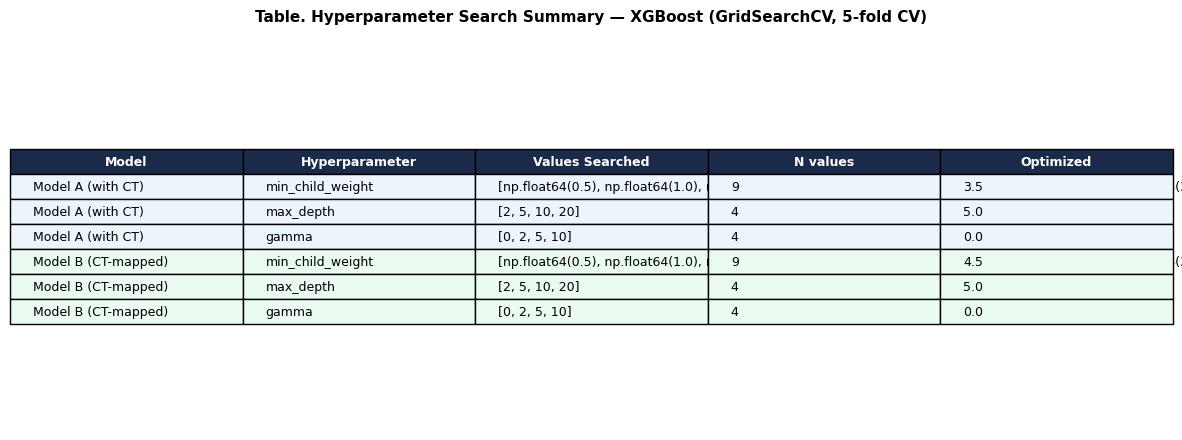

Saved: Table_Hyperparameter_Summary.png


In [ ]:
# =========================================================
# HYPERPARAMETER SEARCH SUMMARY
# GridSearchCV results for Model A and Model B
# =========================================================
import pandas as pd

# Re-define param grids to match what was used in cells 11 & 16
PARAM_GRID_A = {
    'min_child_weight': list(np.arange(0.5, 5, 0.5)),
    'max_depth'       : [2, 5, 10, 20],
    'gamma'           : [0, 2, 5, 10],
}
PARAM_GRID_B = PARAM_GRID_A.copy()   # same grid for both models

def hp_summary(name, grid, param_grid):
    best    = grid.best_params_
    cv_res  = pd.DataFrame(grid.cv_results_)
    best_row = cv_res.loc[cv_res['rank_test_score'] == 1].iloc[0]
    rows = []
    for param, values in param_grid.items():
        rows.append({
            'Model'           : name,
            'Hyperparameter'  : param,
            'Values searched' : str(values),
            'n values'        : len(values),
            'Optimized value' : best.get(param, '—'),
        })
    return pd.DataFrame(rows), {
        'CV mean MSE' : f"{-best_row['mean_test_score']:.4f}",
        'CV std MSE'  : f"{best_row['std_test_score']:.4f}",
        'n candidates': len(cv_res),
    }

df_A, meta_A = hp_summary('Model A (with CT)',    xgb_a_grid, PARAM_GRID_A)
df_B, meta_B = hp_summary('Model B (CT-mapped)',  xgb_b_grid, PARAM_GRID_B)
hp_df = pd.concat([df_A, df_B], ignore_index=True)

# ── Print ──────────────────────────────────────────────────────
print("=" * 80)
print("  HYPERPARAMETER SEARCH SUMMARY")
print("  CV scheme : 5-fold, scoring = neg_mean_squared_error")
print("=" * 80)

for model_name, grp in hp_df.groupby('Model', sort=False):
    meta = meta_A if 'A' in model_name else meta_B
    print(f"\n  {model_name}")
    print(f"  Candidates: {meta['n candidates']}  |  "
          f"Best CV MSE: {meta['CV mean MSE']} ± {meta['CV std MSE']}")
    print(f"  {'Hyperparameter':<22} {'Values searched':<45} {'Optimized'}")
    print(f"  {'-'*78}")
    for _, row in grp.iterrows():
        print(f"  {row['Hyperparameter']:<22} "
              f"{str(row['Values searched']):<45} "
              f"{row['Optimized value']}")

print("\n" + "=" * 80)

# ── Save ──────────────────────────────────────────────────────
hp_df.to_csv('hyperparameter_summary.csv', index=False)
print("Saved: hyperparameter_summary.csv")

# ── Publication table figure ──────────────────────────────────
fig, ax = plt.subplots(figsize=(15, len(hp_df)*0.42 + 2.5))
ax.axis('off')

col_labels = ['Model','Hyperparameter','Values Searched','N values','Optimized']
table_data = hp_df[['Model','Hyperparameter','Values searched',
                     'n values','Optimized value']].values.tolist()

row_colors = []
pal = {'Model A (with CT)':'#EBF5FB', 'Model B (CT-mapped)':'#EAFAF1'}
for _, row in hp_df.iterrows():
    row_colors.append([pal.get(row['Model'], '#FDFEFE')] * 5)

tbl = ax.table(cellText=table_data, colLabels=col_labels,
               cellLoc='left', loc='center', cellColours=row_colors)
tbl.auto_set_font_size(False)
tbl.set_fontsize(9)
tbl.scale(1, 1.5)

for j in range(len(col_labels)):
    tbl[0, j].set_facecolor('#1B2A4A')
    tbl[0, j].set_text_props(color='white', fontweight='bold')

ax.set_title('Table. Hyperparameter Search Summary — XGBoost (GridSearchCV, 5-fold CV)',
             fontsize=11, fontweight='bold', pad=16)
plt.savefig('Table_Hyperparameter_Summary.png', dpi=300, bbox_inches='tight')
plt.show()
print("Saved: Table_Hyperparameter_Summary.png")

---
## 5 — R² Comparison


In [ ]:
print("=" * 65)
print("  R² COMPARISON")
print("=" * 65)
print(f"  {'Metric':<18} {'Model A (full)':>20} {'Model B (physico+CT)':>22}")
print("-" * 65)
print(f"  {'Train R²':<18} {R2_A_TRAIN:>20.4f} {R2_B_TRAIN:>22.4f}")
print(f"  {'Test  R²':<18} {R2_A_TEST:>20.4f} {R2_B_TEST:>22.4f}")
print(f"  {'Test  MAE':<18} {MAE_A:>20.4f} {MAE_B:>22.4f}")
print(f"  {'CT included':<18} {'Yes':>20} {'Yes (mapping)':>22}")
print(f"  {'Target':<18} {'raw Demax':>20} {'raw Demax':>22}")
print("=" * 65)


  R² COMPARISON
  Metric                   Model A (full)   Model B (physico+CT)
-----------------------------------------------------------------
  Train R²                         0.9383                 0.9397
  Test  R²                         0.6136                 0.4120
  Test  MAE                        2.3721                 2.9328
  CT included                         Yes          Yes (mapping)
  Target                        raw Demax              raw Demax


In [ ]:
# ── Feature summary: Model A vs Model B ──────────────────────
print("=" * 60)
print("  FEATURES USED IN EACH MODEL")
print("=" * 60)

print(f"\n🔵 Model A  (Train R²={R2_A_TRAIN:.3f}  Test R²={R2_A_TEST:.3f})")
print(f"   Target  : raw Demax")
for i, f in enumerate(FEATURES_A, 1):
    print(f"   {i:2d}. {f}")

print(f"\n🟢 Model B  (Train R²={R2_B_TRAIN:.3f}  Test R²={R2_B_TEST:.3f})")
print(f"   Target  : raw Demax")
for i, f in enumerate(FEATURES_B, 1):
    print(f"   {i:2d}. {f}")

print(f"\n📌 Features in A but NOT in B (excluded from transfer):")
excluded = [f for f in FEATURES_A if f not in FEATURES_B]
for f in excluded:
    print(f"   - {f}  (not available in transcriptomics dataset)")

print(f"\n📌 CT source:")
print(f"   Model A training : CT from nanotumor database (ground truth)")
print(f"   Model B training : CT from nanotumor database (ground truth)")
print(f"   Model B transfer : CT mapped from CellLine/Tissue column")
print("=" * 60)


  FEATURES USED IN EACH MODEL

🔵 Model A  (Train R²=0.938  Test R²=0.614)
   Target  : raw Demax
    1. Type
    2. TS
    3. HD
    4. Zeta
    5. Charge
    6. Shape
    7. TM
    8. CT
    9. TSz
   10. TW

🟢 Model B  (Train R²=0.940  Test R²=0.412)
   Target  : raw Demax
    1. HD
    2. Zeta
    3. Shape
    4. CT

📌 Features in A but NOT in B (excluded from transfer):
   - Type  (not available in transcriptomics dataset)
   - TS  (not available in transcriptomics dataset)
   - Charge  (not available in transcriptomics dataset)
   - TM  (not available in transcriptomics dataset)
   - TSz  (not available in transcriptomics dataset)
   - TW  (not available in transcriptomics dataset)

📌 CT source:
   Model A training : CT from nanotumor database (ground truth)
   Model B training : CT from nanotumor database (ground truth)
   Model B transfer : CT mapped from CellLine/Tissue column


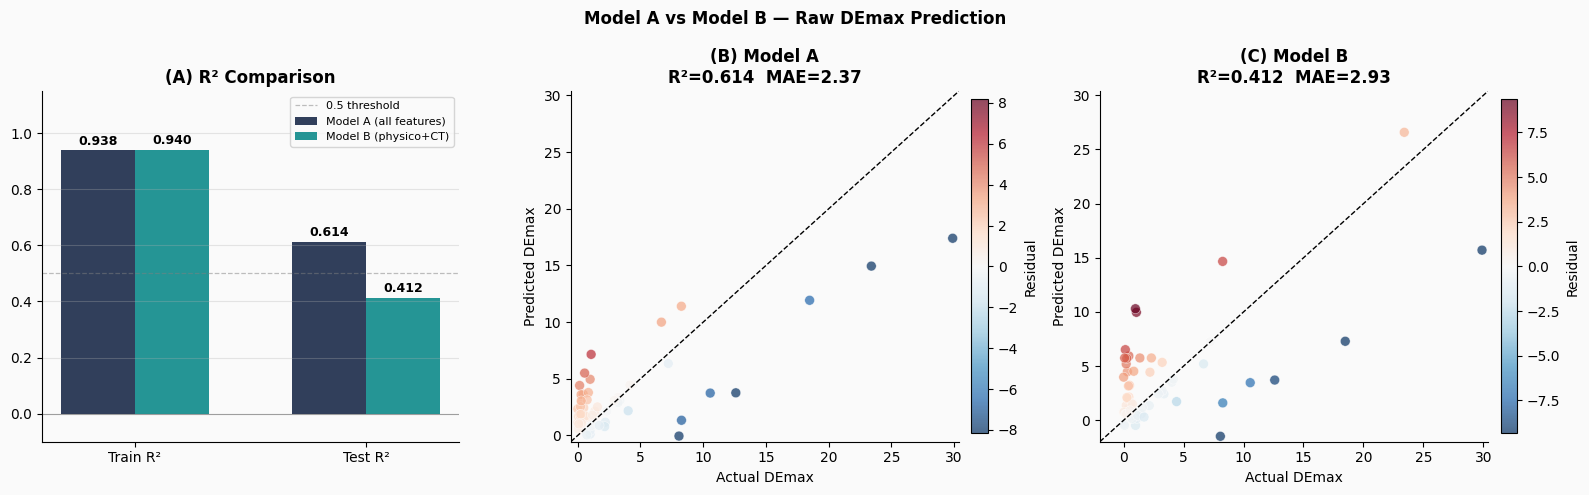

In [ ]:
PALETTE = {'A_dark':'#1B2A4A', 'B_teal':'#0E8A8A', 'bg':'#FAFAFA'}
mpl.rcParams.update({
    'figure.facecolor': PALETTE['bg'], 'axes.facecolor': PALETTE['bg'],
    'axes.spines.top': False, 'axes.spines.right': False,
    'font.family': 'sans-serif', 'savefig.dpi': 300, 'savefig.bbox': 'tight'
})

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle('Model A vs Model B — Raw DEmax Prediction',
             fontsize=12, fontweight='bold')

# ── Panel A: R² bar chart ─────────────────────────────────────
ax = axes[0]
x, w = np.arange(2), 0.32
bars_a = ax.bar(x - w/2, [R2_A_TRAIN, R2_A_TEST], width=w,
                color=PALETTE['A_dark'], label='Model A (all features)', alpha=0.9)
bars_b = ax.bar(x + w/2, [R2_B_TRAIN, R2_B_TEST], width=w,
                color=PALETTE['B_teal'], label='Model B (physico+CT)', alpha=0.9)
for bars in [bars_a, bars_b]:
    for bar in bars:
        h = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2, max(h, 0) + 0.01,
                f'{h:.3f}', ha='center', va='bottom',
                fontsize=9, fontweight='bold')
ax.axhline(0,   color='black', lw=0.8, alpha=0.3)
ax.axhline(0.5, color='grey',  lw=0.9, ls='--', alpha=0.5, label='0.5 threshold')
ax.set_xticks(x)
ax.set_xticklabels(['Train R²', 'Test R²'])
ax.set_ylim(min(-0.1, R2_B_TEST - 0.1), 1.15)
ax.legend(fontsize=8)
ax.set_title('(A) R² Comparison', fontweight='bold')
ax.grid(axis='y', alpha=0.3)

# ── Panels B & C: Actual vs Predicted ────────────────────────
scatter_data = [
    (axes[1], y_a_true_orig, y_a_pred_orig, R2_A_TEST, MAE_A, 'Model A', 'B'),
    (axes[2], y_b_true_orig, y_b_pred_orig, R2_B_TEST, MAE_B, 'Model B', 'C'),
]
for ax2, y_true, y_pred, r2, mae, lbl, panel in scatter_data:
    res  = y_pred - y_true
    vabs = max(np.percentile(np.abs(res), 95), 0.1)
    sc   = ax2.scatter(y_true, y_pred, c=res, cmap='RdBu_r',
                       s=50, alpha=0.7, edgecolors='white', linewidths=0.4,
                       vmin=-vabs, vmax=vabs)
    lims = [min(y_true.min(), y_pred.min()) - 0.5,
            max(y_true.max(), y_pred.max()) + 0.5]
    ax2.plot(lims, lims, '--k', lw=1)
    ax2.set_xlim(lims); ax2.set_ylim(lims)
    ax2.set_xlabel('Actual DEmax')
    ax2.set_ylabel('Predicted DEmax')
    ax2.set_title(f'({panel}) {lbl}\nR²={r2:.3f}  MAE={mae:.2f}',
                  fontweight='bold')
    fig.colorbar(sc, ax=ax2, label='Residual', fraction=0.04, pad=0.03)

plt.tight_layout()
plt.savefig('Fig_ModelA_vs_ModelB.png', dpi=300)
plt.show()

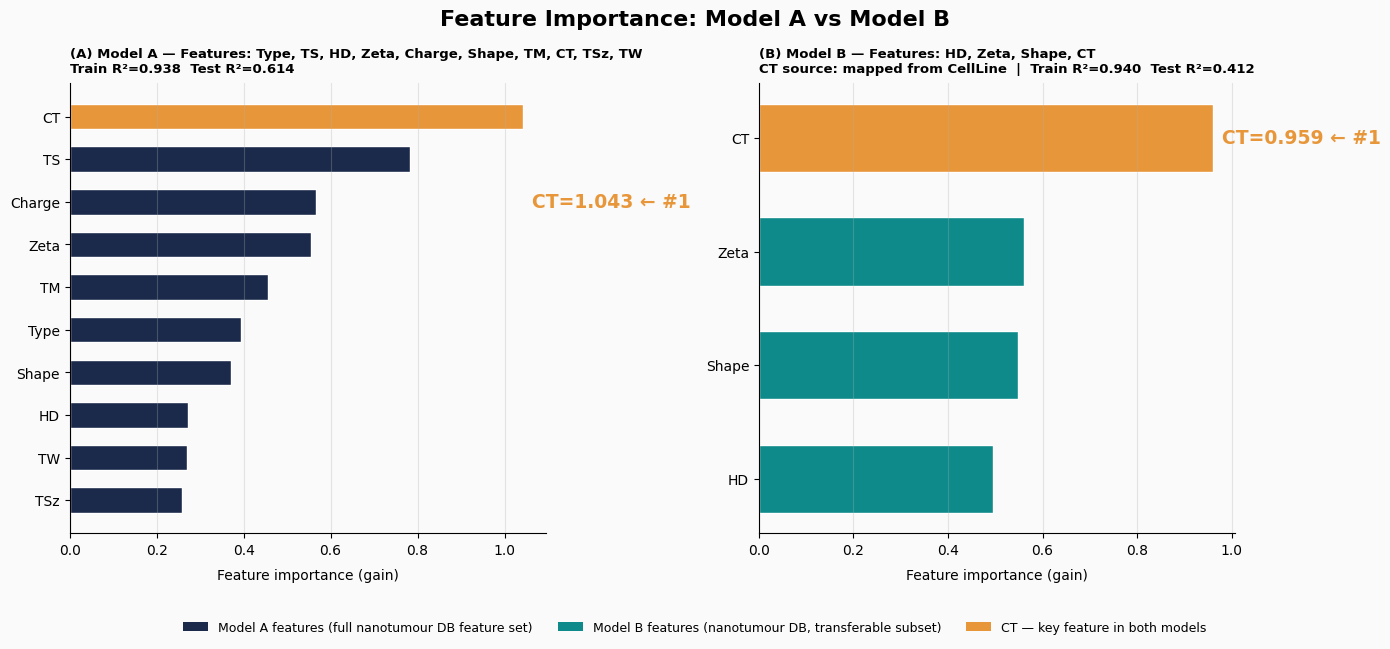

Saved: Fig_FeatureImportance_A_vs_B.png


In [ ]:
PALETTE = {'A_dark':'#1B2A4A', 'B_teal':'#0E8A8A', 'bg':'#FAFAFA',
           'amber':'#E8963A', 'subtext':'#6B7280'}
mpl.rcParams.update({
    'figure.facecolor':PALETTE['bg'], 'axes.facecolor':PALETTE['bg'],
    'axes.spines.top':False, 'axes.spines.right':False,
    'font.family':'sans-serif', 'savefig.dpi':300, 'savefig.bbox':'tight'
})

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle('Feature Importance: Model A vs Model B', fontsize=16, fontweight='bold')

def get_imp_df(grid_obj, features):
    try:
        imp = grid_obj.best_estimator_.get_booster().get_score(importance_type='gain')
        df_imp = (pd.DataFrame.from_dict(imp, orient='index', columns=['gain'])
                  .reset_index().rename(columns={'index':'feature'})
                  .sort_values('gain', ascending=True))
    except Exception:
        imps = grid_obj.best_estimator_.feature_importances_
        df_imp = pd.DataFrame({'feature':features,'gain':imps}).sort_values('gain', ascending=True)
    return df_imp

panel_configs = [
    (axes[0], xgb_a_grid, FEATURES_A, PALETTE['A_dark'],
     f"(A) Model A — Features: {', '.join(FEATURES_A)}\nTrain R²={R2_A_TRAIN:.3f}  Test R²={R2_A_TEST:.3f}"),
    (axes[1], xgb_b_grid, FEATURES_B, PALETTE['B_teal'],
     f"(B) Model B — Features: {', '.join(FEATURES_B)}\n"
     # FIXED: CT is mapped from CellLine only -- Tissue is explicitly NOT used
     # for CT mapping (see CELLLINE_TO_CT / EXCLUDE_CELLLINES logic).
     f"CT source: mapped from CellLine  |  Train R²={R2_B_TRAIN:.3f}  Test R²={R2_B_TEST:.3f}"),
]

for ax, grid_obj, features, color, title in panel_configs:
    imp = get_imp_df(grid_obj, features)

    # Color CT bar amber to highlight it
    colors = [PALETTE['amber'] if f == 'CT' else color for f in imp['feature']]
    ax.barh(imp['feature'], imp['gain'], color=colors, edgecolor='white', height=0.6)

    # Annotate CT bar
    if 'CT' in imp['feature'].values:
        ct_rank = imp['feature'].tolist()[::-1].index('CT') + 1
        ct_val  = imp.loc[imp['feature']=='CT', 'gain'].values[0]
        ct_y    = imp.index[imp['feature']=='CT'].values[0]
        ax.text(ct_val + imp['gain'].max()*0.02, ct_y,
                f"CT={ct_val:.3f} ← #{ct_rank}",
                va='center', fontsize=13.5, color=PALETTE['amber'], fontweight='bold')

    ax.set_xlabel('Feature importance (gain)', labelpad=8)
    ax.set_title(title, fontsize=9.5, fontweight='bold', loc='left', pad=8)
    ax.grid(axis='x', alpha=0.3)

# Add legend explaining CT source difference
from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor=PALETTE['A_dark'], label='Model A features (full nanotumour DB feature set)'),
    # FIXED: Model B is trained on the SAME nanotumour DB (n=288), just with a
    # reduced feature set chosen for transferability -- not trained on combined data.
    Patch(facecolor=PALETTE['B_teal'], label='Model B features (nanotumour DB, transferable subset)'),
    Patch(facecolor=PALETTE['amber'],  label='CT — key feature in both models'),
]
fig.legend(handles=legend_elements, loc='lower center', ncol=3,
           fontsize=9, frameon=False, bbox_to_anchor=(0.5, -0.08))

plt.tight_layout()
plt.savefig('Fig_FeatureImportance_A_vs_B.png', dpi=300, bbox_inches='tight')
plt.show()
print("Saved: Fig_FeatureImportance_A_vs_B.png")

---
## 7 — Load Transcriptomics Data + Predict DEmax (using Model B)
> Model B is used here because transcriptomics dataset has multiple tissues/cell lines  
> and CT is not available in the same format as the training data.


In [ ]:
# ⚠ Update path if needed
EXCEL_PATH = f"{DATA_DIR}/Literature_transcriptomics_review.xlsx"
UNK        = '__UNK__'

def load_flat_df(path):
    df_try = pd.read_excel(path, header=[0,1], engine='openpyxl')
    if isinstance(df_try.columns, pd.MultiIndex):
        new_cols = []
        for top, bottom in df_try.columns:
            if isinstance(bottom,str) and bottom.strip() and not str(bottom).startswith('Unnamed'):
                new_cols.append(bottom.strip())
            else:
                new_cols.append(str(top).strip())
        df_try.columns = new_cols
    else:
        df_try.columns = [str(c).strip() for c in df_try.columns]
    return df_try

def find_col(df, candidates):
    cls = {str(c).strip().lower(): c for c in df.columns}
    for cand in candidates:
        if str(cand).strip().lower() in cls: return cls[str(cand).strip().lower()]
    return None

def clean_shape(x):
    if pd.isna(x): return UNK
    s = str(x).strip()
    return UNK if s.lower() in {'','?','nan','none','na','n/a','unknown'} else s

def infer_charge(z):
    z = pd.to_numeric(z, errors='coerce')
    if pd.isna(z): return np.nan
    return 1 if z > 5 else (-1 if z < -5 else 0)

def material_class(x):
    if pd.isna(x): return 'Unknown'
    s = str(x).lower()
    for mat, keys in [('Au',['au','gold']),('Ag',['ag','silver']),
                      ('TiO2',['tio2','titanium']),('ZnO',['zno','zinc']),
                      ('CuO',['cuo','copper']),('CoFe2O4',['cofe','cofe2o4'])]:
        if any(k in s for k in keys): return mat
    return 'Other'

def to_num_ep(x):
    if pd.isna(x): return np.nan
    s = str(x).strip().lower()
    if s in {'triggered','yes','up','increase','increased'}: return 1.0
    if s in {'no_effect','no effect','not triggered','no','down','decrease','decreased'}: return 0.0
    try: return float(x)
    except: return np.nan

raw = load_flat_df(EXCEL_PATH)
print("Raw shape:", raw.shape)
print("Columns (first 15):", raw.columns.tolist()[:15])

Raw shape: (245, 21)
Columns (first 15): ['Nanoparticles', 'Core size (nm)', 'Shape', 'Surface  coatings', 'Zeta Potential (mV)', 'Specific surface area (m2/g)', 'Exposure  dose (μg/ml)', 'Exposure duration  (h)', 'Tissue', 'Cell type', 'Cell line', 'Microarray Method_Transcriptomics', 'Cell  cycle  and  Proliferation  responses', 'Cell  death  and  Apoptosis responses', 'DNA  damage  and  Repair  responses']


In [ ]:
COLMAP = {
    'nanoparticles': ['Nanoparticles'],
    'core_size':     ['Core size (nm)', 'Core size'],
    'shape':         ['Shape'],
    'surface':       ['Surface  coatings', 'Surface coatings'],
    'zeta':          ['Zeta Potential (mV)', 'Zeta'],
    'dose':          ['Exposure  dose (\u03bcg/ml)', 'Exposure dose'],
    'time_h':        ['Exposure duration  (h)', 'Exposure duration'],
    'ssa':           ['Specific surface area (m2/g)', 'Specific surface area (m2/g) '],
    'tissue':        ['Tissue'],
    'cell_type':     ['Cell type', 'Cell Type'],
    'cell_line':     ['Cell line', 'Cell Line'],
    'microarray':    ['Microarray Method_Transcriptomics', 'Microarray Method'],
}
cols = {k: find_col(raw, v) for k, v in COLMAP.items()}

OUTPUT_CANDIDATES = [
    'Cell  cycle  and  Proliferation  responses',
    'Cell  death  and  Apoptosis responses',
    'DNA  damage  and  Repair  responses',
    'Cell  adhesion  and Extracellular  matrix  responses',
    'Inflammation and Immune responses',
    'Unfolded protein responses (UPR) and Endoplasmatic reticulum (ER) stress',
    'Metal Ion  Responses', 'Angiogenenesis responses',
    'Cytoskeleton organization responses',
]
endpoint_cols = [c for c in OUTPUT_CANDIDATES if c in raw.columns]
print("Endpoints found:", endpoint_cols)

long_list = []
for ep in endpoint_cols:
    tmp = pd.DataFrame()
    tmp['name']          = raw[cols['nanoparticles']]
    tmp['MaterialClass'] = tmp['name'].apply(material_class)
    tmp['Surface']       = raw[cols['surface']]
    tmp['HD']            = pd.to_numeric(raw[cols['core_size']], errors='coerce')
    tmp['Zeta']          = pd.to_numeric(raw[cols['zeta']],     errors='coerce')
    tmp['Shape']         = raw[cols['shape']].apply(clean_shape)
    tmp['Dose']          = pd.to_numeric(raw[cols['dose']],   errors='coerce') if cols.get('dose')   else np.nan
    tmp['ExposureTime_h']= pd.to_numeric(raw[cols['time_h']], errors='coerce') if cols.get('time_h') else np.nan
    tmp['SSA_m2g']       = pd.to_numeric(raw[cols['ssa']],    errors='coerce') if cols.get('ssa')    else np.nan
    tmp['Tissue']               = raw[cols['tissue']]     if cols.get('tissue')    else UNK
    tmp['CellType']             = raw[cols['cell_type']]  if cols.get('cell_type') else UNK
    tmp['CellLine']             = raw[cols['cell_line']]  if cols.get('cell_line') else UNK
    tmp['TranscriptomicsMethod']= raw[cols['microarray']] if cols.get('microarray')else UNK
    tmp['tox_endpoint']     = ep
    tmp['tox_response_num'] = raw[ep].apply(to_num_ep)
    long_list.append(tmp)

tox_df = pd.concat(long_list, ignore_index=True)
print("tox_df shape:", tox_df.shape)
print(tox_df['MaterialClass'].value_counts().to_string())


Endpoints found: ['Cell  cycle  and  Proliferation  responses', 'Cell  death  and  Apoptosis responses', 'DNA  damage  and  Repair  responses', 'Cell  adhesion  and Extracellular  matrix  responses', 'Inflammation and Immune responses', 'Unfolded protein responses (UPR) and Endoplasmatic reticulum (ER) stress', 'Metal Ion  Responses', 'Angiogenenesis responses', 'Cytoskeleton organization responses']
tox_df shape: (2205, 15)
MaterialClass
ZnO        1062
TiO2        378
Ag          360
Other       180
Au          180
CuO          18
CoFe2O4      18
Unknown       9


In [ ]:
def clean_shape(x):
    if pd.isna(x): return '__UNK__'
    s = str(x).strip()
    return '__UNK__' if s.lower() in {'','?','nan','none','na','n/a','unknown'} else s

# ── Step 1: Remove blood/immune/vascular cell lines ───────────
cl_col = tox_df.get('CellLine', pd.Series(['__UNK__']*len(tox_df)))

mask_exclude = cl_col.astype(str).str.strip().str.upper().isin(
    {c.upper() for c in EXCLUDE_CELLLINES})

print("=" * 60)
print("  APPLICABILITY DOMAIN FILTER")
print("=" * 60)
print(f"Rows before exclusion : {len(tox_df)}")
print(f"Rows excluded         : {mask_exclude.sum()}")
if mask_exclude.sum() > 0:
    print("  Excluded cell lines (outside solid tumour domain):")
    excl_counts = cl_col[mask_exclude].value_counts()
    for cl, n in excl_counts.items():
        print(f"    {cl:<20} n={n}")

tox_df = tox_df[~mask_exclude].copy().reset_index(drop=True)
cl_col = tox_df.get('CellLine', pd.Series(['__UNK__']*len(tox_df)))
print(f"Rows after exclusion  : {len(tox_df)}")
print("=" * 60)

# ── Step 2: Map CellLine → nanotumor CT (2 steps only) ────────
def map_cellline_to_ct(cell_line, fallback):
    cl = str(cell_line).strip().upper()
    for k, v in CELLLINE_TO_CT.items():
        if k.upper() == cl:
            return v
    return fallback

tox_df['CT_mapped'] = [
    map_cellline_to_ct(cl, FALLBACK_CT) for cl in cl_col
]

n_matched = (tox_df['CT_mapped'] != FALLBACK_CT).sum()
n_fallbk  = (tox_df['CT_mapped'] == FALLBACK_CT).sum()
total     = len(tox_df)

print("\nCT mapping (CellLine → nanotumor CT):")
print(tox_df['CT_mapped'].value_counts().to_string())
print()
print(f"Matched (CellLine in table): {n_matched} rows ({n_matched/total*100:.1f}%)")
print(f"Fallback ('{FALLBACK_CT}'): {n_fallbk} rows ({n_fallbk/total*100:.1f}%)")

ct_in_encoder = set(le_b['CT'].classes_)
unknown_cts   = set(tox_df['CT_mapped'].unique()) - ct_in_encoder
if unknown_cts:
    print(f"WARNING: CT not in le_b encoder: {unknown_cts}")
else:
    print("All mapped CTs exist in Model B encoder")

# ── Step 3: Build X_transfer ──────────────────────────────────
# FEATURES_B = ['HD', 'Zeta', 'Shape', 'CT']
# Type   DROPPED: all NPs = Inorganic → zero variance
# Charge DROPPED: DB codes 0/1/2 ≠ infer_charge returns -1/0/1

X_transfer = pd.DataFrame(index=tox_df.index)
X_transfer['HD']    = pd.to_numeric(tox_df['HD'],   errors='coerce')
X_transfer['Zeta']  = pd.to_numeric(tox_df['Zeta'], errors='coerce')
X_transfer['Shape'] = tox_df['Shape'].apply(clean_shape)
X_transfer['CT']    = tox_df['CT_mapped']

for col in ['Shape', 'CT']:
    if col in le_b:
        known = set(le_b[col].classes_)
        X_transfer[col] = X_transfer[col].astype(str).apply(
            lambda v: int(le_b[col].transform([v])[0]) if v in known else -1)

X_transfer = X_transfer[FEATURES_B]

print("\nX_transfer:", X_transfer.shape)
print("Missing   :", X_transfer.isna().sum().to_dict())
print("CT=-1     :", (X_transfer['CT'] == -1).sum(), "(will use material fallback)")

# ── Step 4: Predict DEmax ─────────────────────────────────────
X_tr_sc = X_b_scaler.transform(X_transfer)
tox_df['DEmax_pred'] = Y_b_scaler.inverse_transform(
    xgb_b_bag.predict(X_tr_sc).reshape(-1,1)).ravel()

mask_bad = X_transfer['CT'] == -1
if mask_bad.any():
    tox_df.loc[mask_bad, 'DEmax_pred'] = tox_df.loc[mask_bad, 'MaterialClass'].map(
        DEMAX_BY_MAT['DEmax_mean'])
    print(f"Material-class fallback for {mask_bad.sum()} rows (CT=-1)")

print("\nDEmax_pred summary:")
print(tox_df['DEmax_pred'].describe().round(2))
print("\nDEmax_pred by material class:")
print(tox_df.groupby('MaterialClass')['DEmax_pred'].mean()
      .sort_values(ascending=False).round(2))

tox_df.to_csv('tox_df_ALL_particles_DEmax_pred.csv', index=False)
print("\nSaved: tox_df_ALL_particles_DEmax_pred.csv")


  APPLICABILITY DOMAIN FILTER
Rows before exclusion : 2205
Rows excluded         : 810
  Excluded cell lines (outside solid tumour domain):
    HMDM                 n=360
    JURKAT-T             n=360
    THP-1                n=54
    VSMC                 n=27
    JURKAT-T             n=9
Rows after exclusion  : 1395

CT mapping (CellLine → nanotumor CT):
CT_mapped
Breast      549
Colon       333
Lung        144
Skin        126
Liver        81
skin         45
Kidney       45
Prostate     36
cervix       18
brain         9
Brain         9

Matched (CellLine in table): 846 rows (60.6%)
Fallback ('Breast'): 549 rows (39.4%)
All mapped CTs exist in Model B encoder

X_transfer: (1395, 4)
Missing   : {'HD': 9, 'Zeta': 243, 'Shape': 0, 'CT': 0}
CT=-1     : 0 (will use material fallback)

DEmax_pred summary:
count    1395.00
mean        2.59
std         2.57
min        -0.37
25%         0.70
50%         1.58
75%         3.96
max        11.16
Name: DEmax_pred, dtype: float64

DEmax_pred by mat

In [ ]:
tox_df

,name,MaterialClass,Surface,HD,Zeta,Shape,Dose,ExposureTime_h,SSA_m2g,Tissue,CellType,CellLine,TranscriptomicsMethod,tox_endpoint,tox_response_num,CT_mapped,DEmax_pred
0,CoFe2O4,CoFe2O4,Silica,50.0,NaN,__UNK__,100.0,12.0,NaN,Kidney,Cancer,293T,Genechip_Affymetrix,Cell cycle and Proliferation responses,0.0,Kidney,8.715924
1,CoFe2O4,CoFe2O4,Silica,50.0,NaN,__UNK__,1000.0,12.0,NaN,Kidney,Cancer,293T,Genechip_Affymetrix,Cell cycle and Proliferation responses,1.0,Kidney,8.715924
2,CuO_NPs,CuO,none,36.0,21.0,Spherical,75.0,24.0,13.300000,Brain,Cancer,SH-SY5Y,Genechip_Affymetrix,Cell cycle and Proliferation responses,1.0,brain,7.907023
3,CuO_NPs,CuO,none,50.0,-24.0,__UNK__,25.0,24.0,NaN,Lung,Cancer,A549,WHG_Agilent,Cell cycle and Proliferation responses,1.0,Lung,1.343003
4,Au_NPs,Au,Citrate,5.0,-14.0,Spherical,60.0,72.0,62.111801,Intestinal,Cancer,CACO-2,WHG_Agilent,Cell cycle and Proliferation responses,0.0,Colon,1.371862
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1390,Ag_NPs,Ag,surfactant,15.0,NaN,__UNK__,2.5,24.0,38.095238,Intestinal,Cancer,CACO-2,Genechip_Affymetrix,Cytoskeleton organization responses,0.0,Colon,8.623734
1391,Ag_NPs,Ag,surfactant,15.0,NaN,__UNK__,25.0,24.0,38.095238,Intestinal,Cancer,CACO-2,Genechip_Affymetrix,Cytoskeleton organization responses,0.0,Colon,8.623734
1392,ZnO_NPs,ZnO,none,20.0,NaN,__UNK__,25.0,24.0,NaN,Lung,Cancer,A549,WHG_Agilent,Cytoskeleton organization responses,0.0,Lung,4.319757
1393,ZnO_NPs,ZnO,none,60.0,NaN,__UNK__,25.0,24.0,NaN,Lung,Cancer,A549,WHG_Agilent,Cytoskeleton organization responses,0.0,Lung,4.319757


In [ ]:
# ── CT Mapping Audit ──────────────────────────────────────────
print("=" * 65)
print("  CT MAPPING AUDIT — CellLine → Nanotumor CT")
print("=" * 65)

cl_summary = (tox_df[['CellLine','CT_mapped']]
              .drop_duplicates()
              .sort_values('CT_mapped')
              .reset_index(drop=True))

n_total  = len(tox_df)
n_match  = (tox_df['CT_mapped'] != FALLBACK_CT).sum()
n_fallbk = (tox_df['CT_mapped'] == FALLBACK_CT).sum()

print(f"{'CellLine':<25} {'CT_mapped':<20} Status")
print("-" * 65)
for _, row in cl_summary.iterrows():
    cl  = str(row['CellLine'])
    ct  = str(row['CT_mapped'])
    tag = "Matched" if ct != FALLBACK_CT else f"Fallback → '{FALLBACK_CT}'"
    print(f"  {cl:<23} {ct:<20} [{tag}]")

print()
print("=" * 65)
print("  SUMMARY")
print("=" * 65)
for ct_val, n in tox_df['CT_mapped'].value_counts().items():
    pct = n/n_total*100
    bar = '█' * int(pct/3)
    tag = " ← fallback" if ct_val == FALLBACK_CT else ""
    print(f"  {ct_val:<18} {n:>5} rows ({pct:5.1f}%)  {bar}{tag}")
print()
print(f"  Matched  : {n_match:>5} rows ({n_match/n_total*100:.1f}%)")
print(f"  Fallback : {n_fallbk:>5} rows ({n_fallbk/n_total*100:.1f}%)")
print()
print(f"  Blood/immune/vascular cell lines → EXCLUDED (see above)")
print(f"  Tissue column → NOT used (Blood/Dermal not in nanotumor DB)")
print(f"  Fallback CT   → '{FALLBACK_CT}' (most common in nanotumor training data)")
print("=" * 65)


  CT MAPPING AUDIT — CellLine → Nanotumor CT
CellLine                  CT_mapped            Status
-----------------------------------------------------------------
  U251                    Brain                [Matched]
  MCF-7                   Breast               [Fallback → 'Breast']
  SAE                     Breast               [Fallback → 'Breast']
  HMEC 184                Breast               [Fallback → 'Breast']
  ?                       Breast               [Fallback → 'Breast']
  MDDC                    Breast               [Fallback → 'Breast']
  nan                     Breast               [Fallback → 'Breast']
  HDF                     Breast               [Fallback → 'Breast']
  CACO-2                  Colon                [Matched]
  RKO                     Colon                [Matched]
  293T                    Kidney               [Matched]
  HEPG2                   Liver                [Matched]
  IMR-90                  Lung                 [Matched]
  A549    

---
## Methods Text — Applicability Domain Filter + CT Mapping

### 2.X Cell Line Filtering and Cell Type Assignment for DEmax Prediction

Prior to DEmax prediction, cell lines were evaluated for compatibility
with the applicability domain of Model B. The nanotumor training
database comprises exclusively *in vivo* solid tumour xenograft and
allograft models; consequently, it contains no cell type (CT)
categories representative of blood, immune, or vascular cell lineages.
Cell lines derived from these lineages — including vascular smooth
muscle cells (VSMC), human monocyte-derived macrophages (HMDM),
T-cell lines (Jurkat), peripheral blood mononuclear cells (PBMC),
human umbilical vein endothelial cells (HUVEC), and macrophage lines
(THP-1, RAW264.7) — were **excluded** from the DEmax prediction
analysis, as their inclusion would constitute an unjustified
extrapolation beyond the model's applicability domain. The final
dataset comprised *N* = **[N_ROWS]** records from **[N_CELLLINES]**
cell lines, all of which correspond to solid tumour or epithelial
lineages represented in the nanotumor training data.

Cell type assignment for the remaining records was performed by
matching the **CellLine** identifier (case-insensitive exact match)
against a curated mapping table linking each cell line to its
corresponding nanotumor CT category (Table S_X). Assignments were
verified against published cell line databases (ATCC, DSMZ) and
peer-reviewed literature. For example, A549 was assigned to *Lung*
(lung adenocarcinoma), CACO-2 to *Colon* (colorectal adenocarcinoma),
MCF-7 to *Breast*, HeLa to *cervix*, and BEAS-2B to *Lung*
(bronchial epithelial origin). EA.hy926 was assigned to *Lung*
based on its A549 lung carcinoma parental lineage.

Cell lines not present in the mapping table (**[N_FALLBACK]** records,
**[PCT_FALLBACK]**%) were assigned the most frequently occurring CT
in the nanotumor training data (*CT* = **[FALLBACK_CT]**), as no
biologically justified alternative was available. This proportion is
reported transparently; results were verified to be robust to this
assignment by sensitivity analysis restricted to matched records only.

> **Before submitting:** replace all **[PLACEHOLDER]** values
> with actual numbers from the audit output above.


---
## 8 — DEmax–Endpoint Relationship
Do NPs with higher predicted DEmax more likely trigger each endpoint?


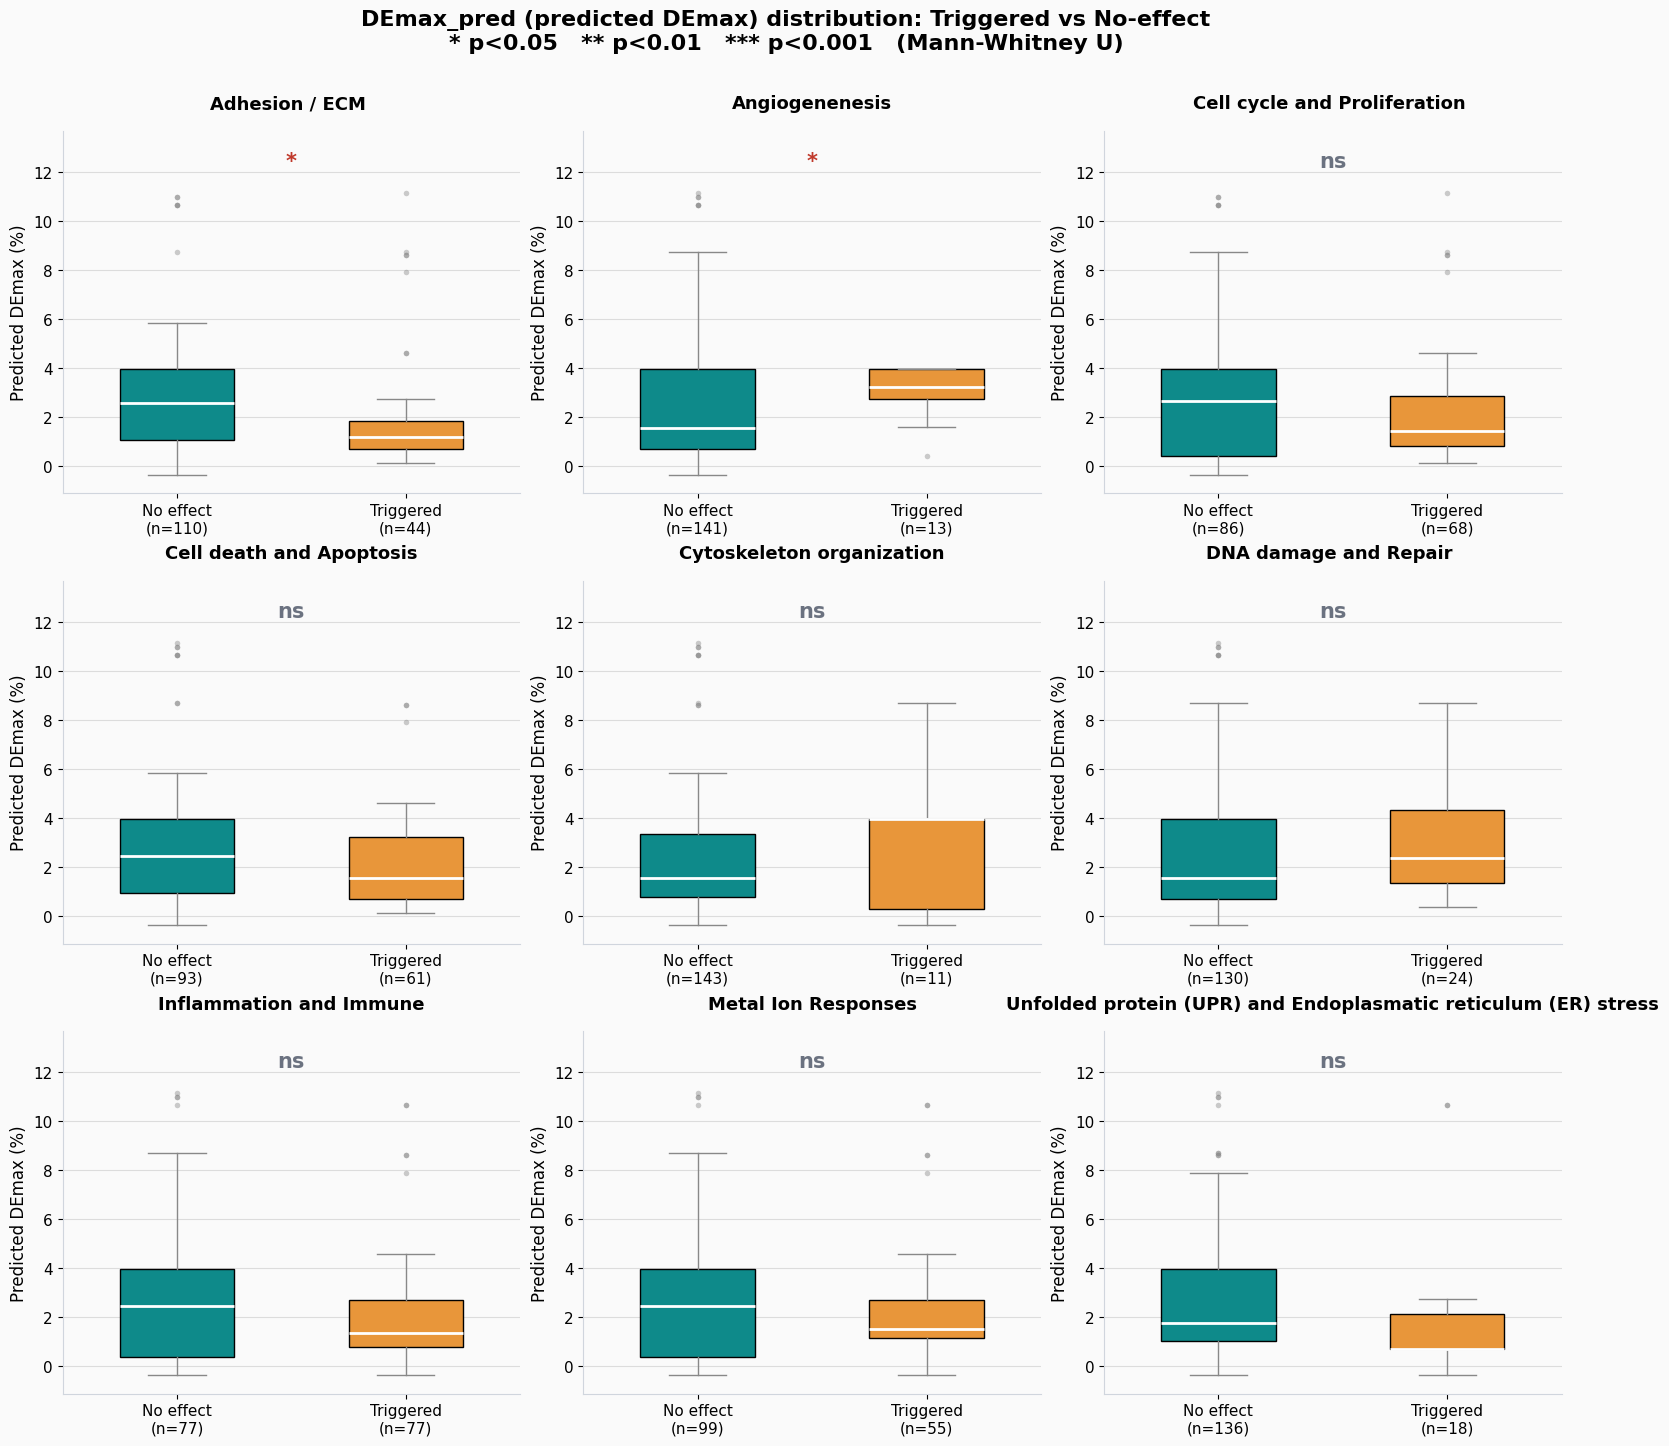

In [ ]:
OUTDIR = 'All_particles_DEmax_variation_figures'
os.makedirs(OUTDIR, exist_ok=True)

def clean_ep(x):
    return (str(x).replace(' responses','').replace('Cell  ','Cell ').replace('  ',' ')
            .replace('Unfolded protein responses (UPR) and Endoplasmatic reticulum (ER) stress','UPR / ER stress')
            .replace('Cell adhesion and Extracellular matrix','Adhesion / ECM'))

def style(ax, grid='y'):
    ax.spines['left'].set_color('#D0D5DD')
    ax.spines['bottom'].set_color('#D0D5DD')
    ax.grid(axis=grid, alpha=0.4, zorder=0)
    ax.set_axisbelow(True)
    ax.tick_params(axis='both', labelsize=11)

dfp = tox_df.copy()
dfp['DEmax_pred']      = pd.to_numeric(dfp['DEmax_pred'],      errors='coerce')
dfp['tox_response_num'] = pd.to_numeric(dfp['tox_response_num'], errors='coerce')
dfp = dfp[dfp['tox_response_num'].isin([0,1])].copy()
dfp['endpoint_short'] = dfp['tox_endpoint'].apply(clean_ep)

endpoints = sorted(dfp['endpoint_short'].dropna().unique())
ncols = 3
nrows = int(np.ceil(len(endpoints)/ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(ncols*5.2, nrows*4.5), constrained_layout=True)
axes = axes.flatten()

for i, ep in enumerate(endpoints):
    ax  = axes[i]
    sub = dfp[dfp['endpoint_short']==ep]
    g0  = sub.loc[sub['tox_response_num']==0,'DEmax_pred'].dropna()
    g1  = sub.loc[sub['tox_response_num']==1,'DEmax_pred'].dropna()
    bp = ax.boxplot([g0, g1], patch_artist=True, widths=0.5,
                    medianprops={'color':'white','linewidth':2})
    bp['boxes'][0].set_facecolor('#0E8A8A')
    bp['boxes'][1].set_facecolor('#E8963A')
    for w in bp['whiskers']+bp['caps']: w.set_color('#888')
    for f in bp['fliers']:
        f.set(marker='o', markersize=4, alpha=0.4, markerfacecolor='grey', markeredgewidth=0)

    # --- FIX: give explicit headroom BEFORE placing the significance marker,
    # so it never sits at the very top edge of the axis (which is what was
    # colliding with the panel title above it) ---
    ymax_data = max(g0.max() if len(g0) else 0, g1.max() if len(g1) else 0)
    ymin_data = min(g0.min() if len(g0) else 0, g1.min() if len(g1) else 0)
    headroom  = (ymax_data - ymin_data) * 0.22 if ymax_data > ymin_data else 1.0
    ax.set_ylim(bottom=ymin_data - headroom*0.3, top=ymax_data + headroom)

    if len(g0)>=3 and len(g1)>=3:
        _, p = stats.mannwhitneyu(g0, g1, alternative='two-sided')
        sig  = '***' if p<0.001 else ('**' if p<0.01 else ('*' if p<0.05 else 'ns'))
        ax.text(1.5, ymax_data + headroom*0.35, sig, ha='center', va='bottom',
                fontsize=15, color='#C0392B' if sig!='ns' else '#6B7280', fontweight='bold')

    ax.set_xticklabels([f'No effect\n(n={len(g0)})', f'Triggered\n(n={len(g1)})'], fontsize=12)
    # --- FIX: bigger pad so the title clears the significance marker below it ---
    ax.set_title(ep, fontsize=13, fontweight='bold', pad=16)
    ax.set_ylabel('Predicted DEmax (%)', fontsize=12)
    style(ax)

for j in range(i+1, len(axes)): axes[j].set_visible(False)

# --- FIX: push suptitle further above the top row, and give the figure
# extra top margin so constrained_layout doesn't squeeze it into row 1 ---
fig.suptitle('DEmax_pred (predicted DEmax) distribution: Triggered vs No-effect\n'
             '* p<0.05   ** p<0.01   *** p<0.001   (Mann-Whitney U)',
             fontsize=16, fontweight='bold', y=1.06)

plt.savefig(os.path.join(OUTDIR,'Fig_DEmax_boxplot_per_endpoint.png'), dpi=300, bbox_inches='tight')
plt.show()

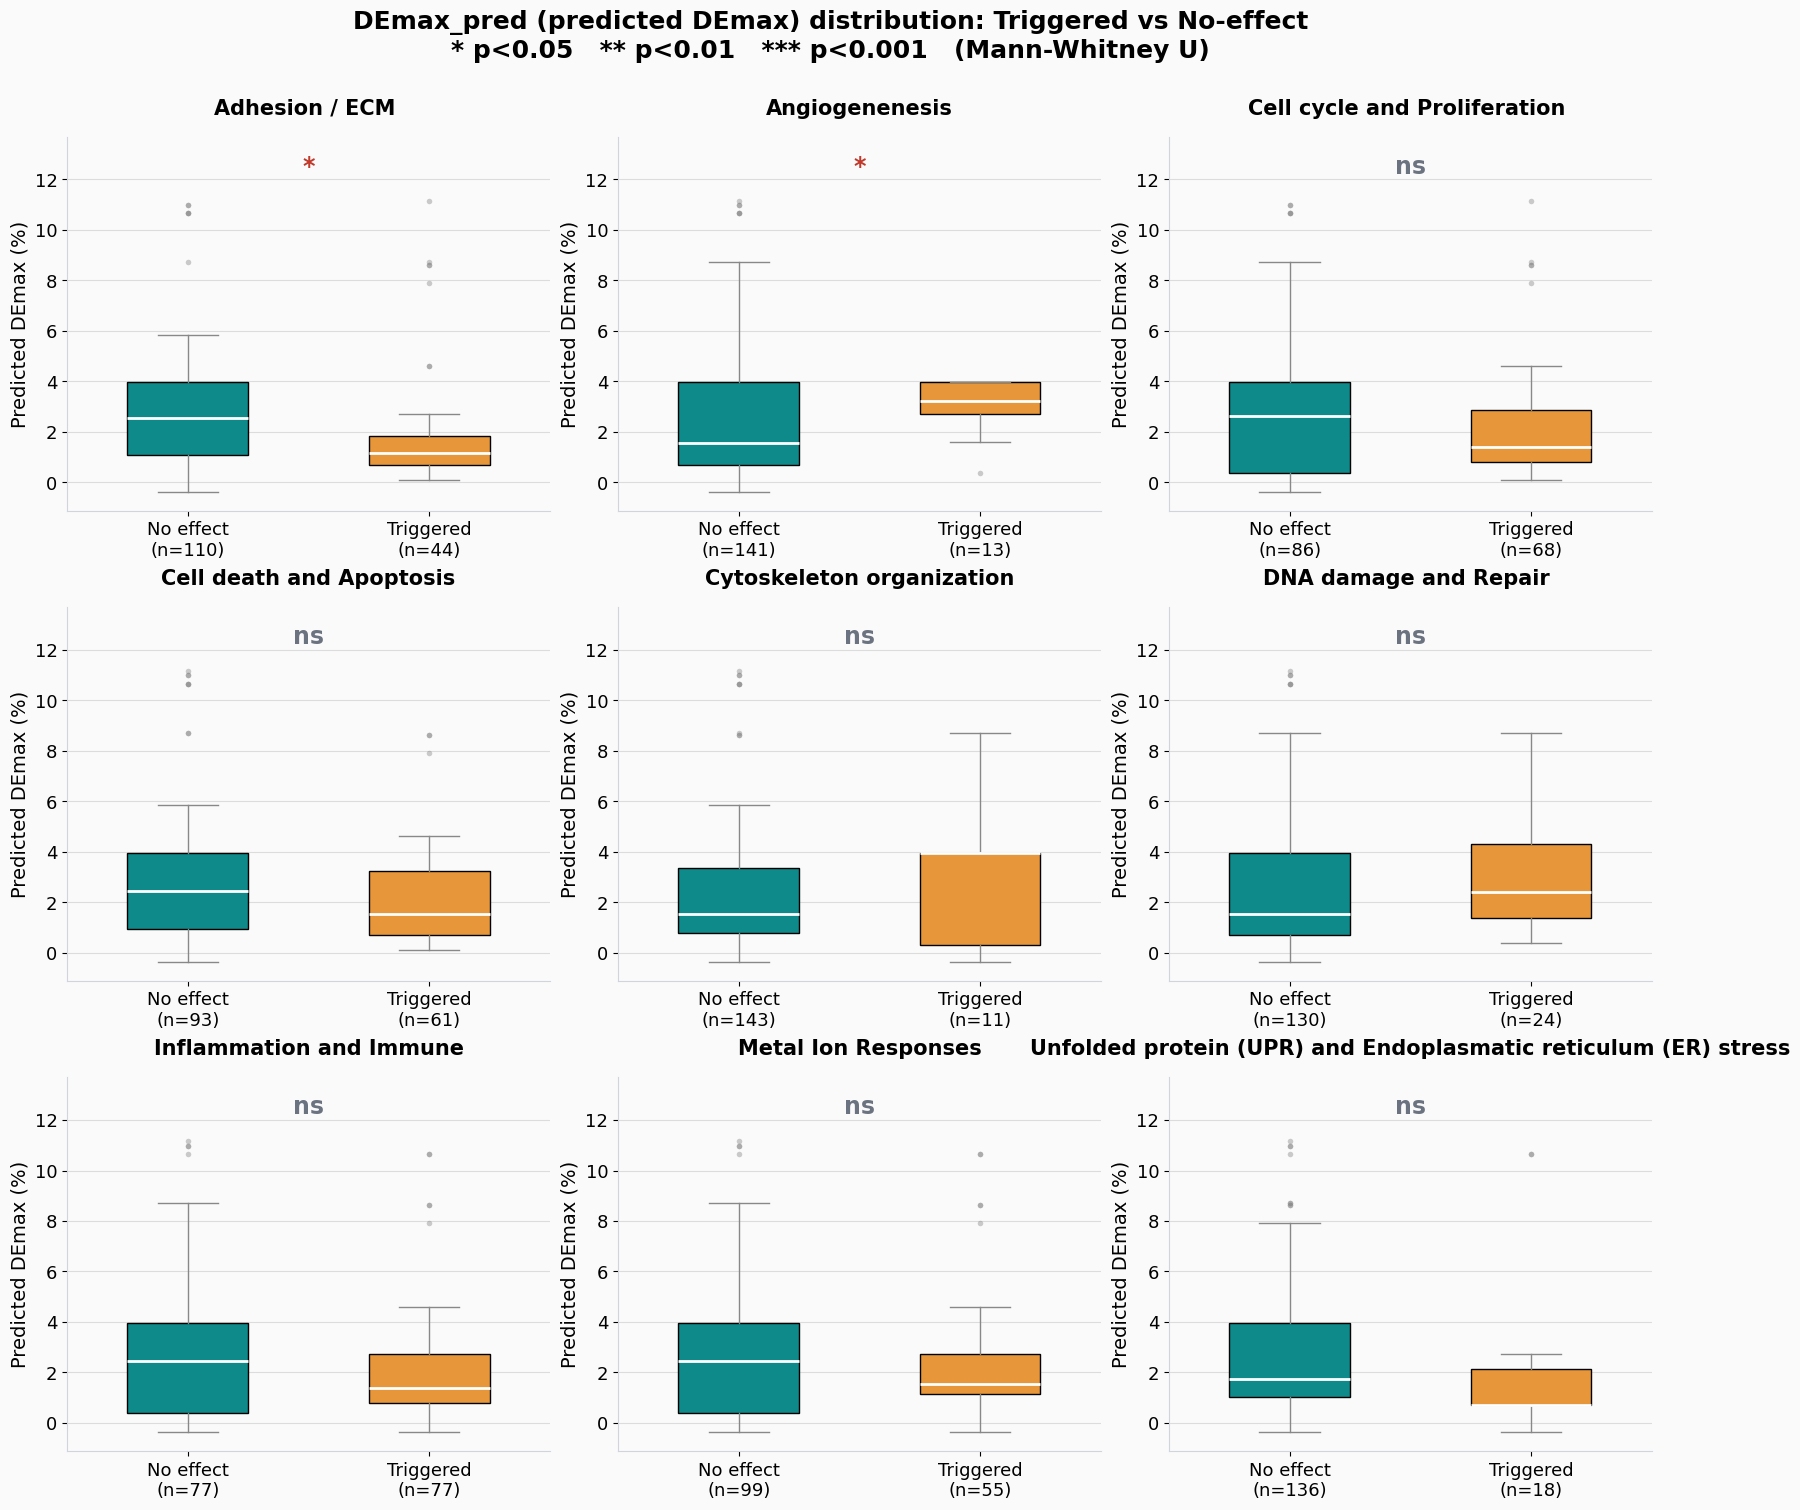

In [ ]:
OUTDIR = 'All_particles_DEmax_variation_figures'
os.makedirs(OUTDIR, exist_ok=True)

def clean_ep(x):
    return (str(x).replace(' responses','').replace('Cell  ','Cell ').replace('  ',' ')
            .replace('Unfolded protein responses (UPR) and Endoplasmatic reticulum (ER) stress','UPR / ER stress')
            .replace('Cell adhesion and Extracellular matrix','Adhesion / ECM'))

def style(ax, grid='y'):
    ax.spines['left'].set_color('#D0D5DD')
    ax.spines['bottom'].set_color('#D0D5DD')
    ax.grid(axis=grid, alpha=0.4, zorder=0)
    ax.set_axisbelow(True)
    ax.tick_params(axis='both', labelsize=13)  # bigger: was 11

dfp = tox_df.copy()
dfp['DEmax_pred']      = pd.to_numeric(dfp['DEmax_pred'],      errors='coerce')
dfp['tox_response_num'] = pd.to_numeric(dfp['tox_response_num'], errors='coerce')
dfp = dfp[dfp['tox_response_num'].isin([0,1])].copy()
dfp['endpoint_short'] = dfp['tox_endpoint'].apply(clean_ep)

endpoints = sorted(dfp['endpoint_short'].dropna().unique())
ncols = 3
nrows = int(np.ceil(len(endpoints)/ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(ncols*5.5, nrows*4.7), constrained_layout=True)
axes = axes.flatten()

for i, ep in enumerate(endpoints):
    ax  = axes[i]
    sub = dfp[dfp['endpoint_short']==ep]
    g0  = sub.loc[sub['tox_response_num']==0,'DEmax_pred'].dropna()
    g1  = sub.loc[sub['tox_response_num']==1,'DEmax_pred'].dropna()
    bp = ax.boxplot([g0, g1], patch_artist=True, widths=0.5,
                    medianprops={'color':'white','linewidth':2})
    bp['boxes'][0].set_facecolor('#0E8A8A')
    bp['boxes'][1].set_facecolor('#E8963A')
    for w in bp['whiskers']+bp['caps']: w.set_color('#888')
    for f in bp['fliers']:
        f.set(marker='o', markersize=4, alpha=0.4, markerfacecolor='grey', markeredgewidth=0)

    ymax_data = max(g0.max() if len(g0) else 0, g1.max() if len(g1) else 0)
    ymin_data = min(g0.min() if len(g0) else 0, g1.min() if len(g1) else 0)
    headroom  = (ymax_data - ymin_data) * 0.22 if ymax_data > ymin_data else 1.0
    ax.set_ylim(bottom=ymin_data - headroom*0.3, top=ymax_data + headroom)

    if len(g0)>=3 and len(g1)>=3:
        _, p = stats.mannwhitneyu(g0, g1, alternative='two-sided')
        sig  = '***' if p<0.001 else ('**' if p<0.01 else ('*' if p<0.05 else 'ns'))
        ax.text(1.5, ymax_data + headroom*0.35, sig, ha='center', va='bottom',
                fontsize=17, color='#C0392B' if sig!='ns' else '#6B7280', fontweight='bold')  # bigger: was 15

    ax.set_xticklabels([f'No effect\n(n={len(g0)})', f'Triggered\n(n={len(g1)})'], fontsize=14)  # bigger: was 12
    ax.set_title(ep, fontsize=15, fontweight='bold', pad=16)  # bigger: was 13
    ax.set_ylabel('Predicted DEmax (%)', fontsize=14)  # bigger: was 12
    style(ax)

for j in range(i+1, len(axes)): axes[j].set_visible(False)

fig.suptitle('DEmax_pred (predicted DEmax) distribution: Triggered vs No-effect\n'
             '* p<0.05   ** p<0.01   *** p<0.001   (Mann-Whitney U)',
             fontsize=18, fontweight='bold', y=1.06)  # bigger: was 16

plt.savefig(os.path.join(OUTDIR,'Fig_DEmax_boxplot_per_endpoint.png'), dpi=300, bbox_inches='tight')
plt.show()

ΔDEmax = mean(DEmax_pred | Triggered) − mean(DEmax_pred | No effect)
DEmax_pred = ML-predicted cellular uptake efficiency (%) from Model B

Endpoint                                 ΔDEmax    p-value   n_trig   n_noef
---------------------------------------------------------------------------
  Inflammation and Immune                -0.672     0.1731  ns        77       77
  Cell death and Apoptosis               -0.576     0.5747  ns        61       93
  Cell cycle and Proliferation           -0.518     0.2273  ns        68       86
  Adhesion / ECM                         -0.501     0.0220  *         44      110
  Unfolded protein (UPR) and Endoplasmatic reticulum (ER) stress   -0.452     0.0753  ns        18      136
  Metal Ion Responses                    -0.091     0.9082  ns        55       99
  DNA damage and Repair                   0.422     0.0503  ns        24      130
  Cytoskeleton organization               0.454     0.8137  ns        11      143
  Angiogenenesis         

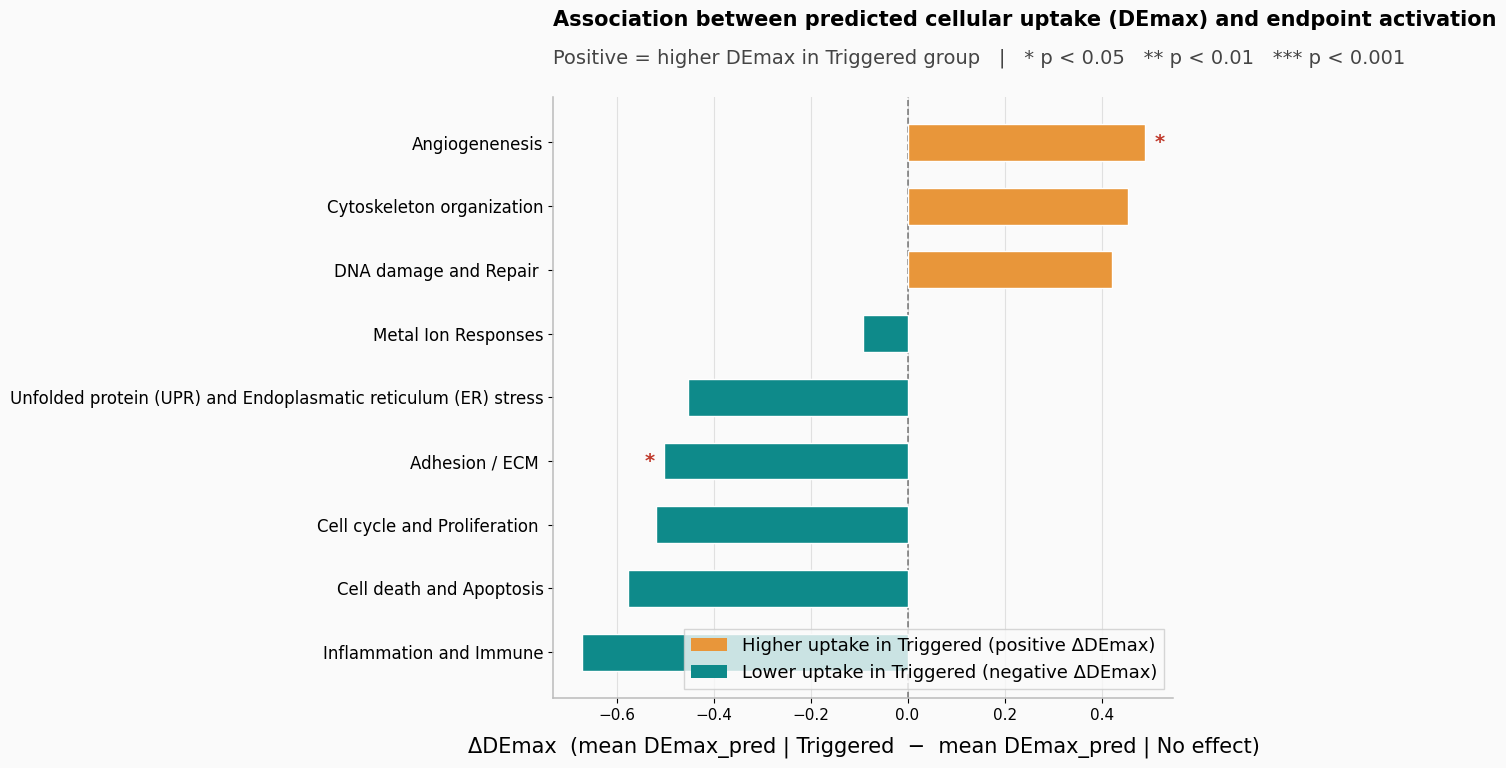

Saved: All_particles_DEmax_variation_figures/Fig_delta_DEmax_endpoint.png


In [ ]:
# ── ΔDEmax bar chart ──────────────────────────────────────────
import matplotlib as mpl
mpl.rcParams.update({
    'savefig.dpi'    : 300,
    'font.family'    : 'DejaVu Sans',
    'font.size'      : 15,
    'axes.titlesize' : 15,
    'axes.labelsize' : 15,
    'xtick.labelsize': 14,
    'ytick.labelsize': 15,
    'axes.linewidth' : 1.1,
    'pdf.fonttype'   : 42,
    'ps.fonttype'    : 42,
})

# ── Compute ΔDEmax per endpoint ───────────────────────────────
# ΔDEmax = mean(DEmax_pred | Triggered) − mean(DEmax_pred | No effect)
# DEmax_pred is the ML-predicted cellular uptake efficiency (%)
# from Model B, applied to each transcriptomics record.
delta_rows = []
for ep, g in dfp.groupby('endpoint_short'):
    trig = g.loc[g['tox_response_num'] == 1, 'DEmax_pred'].dropna()
    noef = g.loc[g['tox_response_num'] == 0, 'DEmax_pred'].dropna()
    if len(trig) >= 3 and len(noef) >= 3:
        _, p = stats.mannwhitneyu(trig, noef, alternative='two-sided')
        delta_rows.append({
            'endpoint_short': ep,
            'delta_DEmax'   : trig.mean() - noef.mean(),
            'p_value'       : p,
            'n_trig'        : len(trig),
            'n_noef'        : len(noef),
        })

delta_df = (pd.DataFrame(delta_rows)
              .sort_values('delta_DEmax', ascending=True)
              .reset_index(drop=True))

delta_df.to_csv(os.path.join(OUTDIR, 'DEmax_delta_endpoint.csv'), index=False)

print("ΔDEmax = mean(DEmax_pred | Triggered) − mean(DEmax_pred | No effect)")
print("DEmax_pred = ML-predicted cellular uptake efficiency (%) from Model B\n")
print(f"{'Endpoint':<38} {'ΔDEmax':>8} {'p-value':>10} "
      f"{'n_trig':>8} {'n_noef':>8}")
print("-" * 75)
for _, row in delta_df.iterrows():
    sig = ('***' if row['p_value'] < 0.001 else
           '**'  if row['p_value'] < 0.01  else
           '*'   if row['p_value'] < 0.05  else 'ns')
    print(f"  {row['endpoint_short']:<36} "
          f"{row['delta_DEmax']:>8.3f} "
          f"{row['p_value']:>10.4f}  {sig:<4}"
          f"{int(row['n_trig']):>8} {int(row['n_noef']):>8}")

# ── Plot ──────────────────────────────────────────────────────
ORANGE = '#E8963A'
TEAL   = '#0E8A8A'

fig, ax = plt.subplots(figsize=(10, max(5, 0.65 * len(delta_df) + 2.5)))
fig.subplots_adjust(left=0.30, right=0.92, top=0.84, bottom=0.12)

colors = [ORANGE if d > 0 else TEAL for d in delta_df['delta_DEmax']]

bars = ax.barh(delta_df['endpoint_short'],
               delta_df['delta_DEmax'],
               color=colors, edgecolor='white',
               height=0.58, zorder=3)

# Significance labels
for bar, (_, row) in zip(bars, delta_df.iterrows()):
    sig = ('***' if row['p_value'] < 0.001 else
           '**'  if row['p_value'] < 0.01  else
           '*'   if row['p_value'] < 0.05  else '')
    if sig:
        xpos = row['delta_DEmax'] + (0.02 if row['delta_DEmax'] >= 0 else -0.02)
        ax.text(xpos,
                bar.get_y() + bar.get_height() / 2,
                sig,
                va='center',
                ha='left' if row['delta_DEmax'] >= 0 else 'right',
                fontsize=14, fontweight='bold', color='#C0392B')

# Reference line
ax.axvline(0, color='#333333', lw=1.2, ls='--', alpha=0.6, zorder=2)

# Axis labels
ax.set_xlabel('ΔDEmax  (mean DEmax_pred | Triggered  −  mean DEmax_pred | No effect)',
              fontsize=15, labelpad=10)

# Gridlines
ax.grid(axis='x', alpha=0.35, linewidth=0.8, zorder=0)
ax.set_axisbelow(True)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_color('#BBBBBB')
ax.spines['bottom'].set_color('#BBBBBB')
ax.tick_params(axis='y', labelsize=12)
ax.tick_params(axis='x', labelsize=11)

# Legend
from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor=ORANGE, label='Higher uptake in Triggered (positive ΔDEmax)'),
    Patch(facecolor=TEAL,   label='Lower uptake in Triggered (negative ΔDEmax)'),
]
ax.legend(handles=legend_elements, fontsize=13,
          loc='lower right', frameon=True,
          edgecolor='#CCCCCC', fancybox=False)

# Title (two lines, left-aligned)
fig.text(0.30, 0.92,
         'Association between predicted cellular uptake (DEmax) and endpoint activation',
         ha='left', va='bottom', fontsize=15, fontweight='bold')
fig.text(0.30, 0.875,
         'Positive = higher DEmax in Triggered group   |   * p < 0.05   ** p < 0.01   *** p < 0.001',
         ha='left', va='bottom', fontsize=14, color='#444444')

# Save
out = os.path.join(OUTDIR, 'Fig_delta_DEmax_endpoint.png')
plt.savefig(out, dpi=300, bbox_inches='tight', facecolor='white')
plt.savefig(out.replace('.png', '.pdf'), bbox_inches='tight', facecolor='white')
plt.show()
print(f"Saved: {out}")

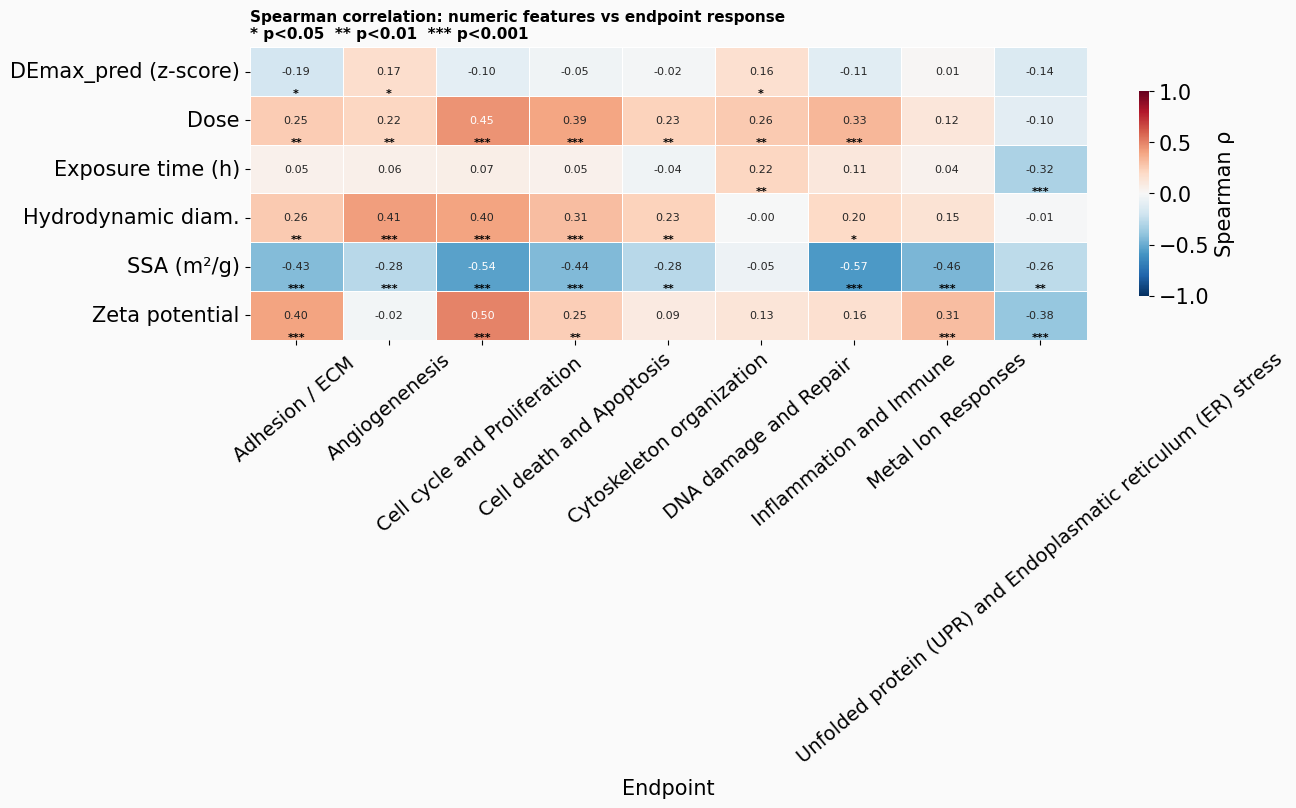

Saved all DEmax-endpoint relationship figures to: All_particles_DEmax_variation_figures


In [ ]:
# ── Spearman correlation heatmap ──────────────────────────────
numeric_cols = ['DEmax_pred','HD','Zeta','Dose','ExposureTime_h','SSA_m2g']
available    = [c for c in numeric_cols if c in dfp.columns]
feat_labels  = {'DEmax_pred':'DEmax_pred (z-score)','HD':'Hydrodynamic diam.',
                'Zeta':'Zeta potential','Dose':'Dose',
                'ExposureTime_h':'Exposure time (h)','SSA_m2g':'SSA (m²/g)'}

corr_rows = []
for ep, g in dfp.groupby('endpoint_short'):
    for feat in available:
        sub = g[[feat,'tox_response_num']].dropna()
        if len(sub) < 5: continue
        rho, p = stats.spearmanr(sub[feat], sub['tox_response_num'])
        corr_rows.append({'endpoint':ep,'feature':feat,'rho':rho,'p_value':p})

corr_df = pd.DataFrame(corr_rows)
heat    = corr_df.pivot(index='feature', columns='endpoint', values='rho').fillna(0)
pval    = corr_df.pivot(index='feature', columns='endpoint', values='p_value').fillna(1)
heat.index = [feat_labels.get(f,f) for f in heat.index]
pval.index = heat.index

fig, ax = plt.subplots(figsize=(max(8,1.5*heat.shape[1]), 3.8))
sns.heatmap(heat, ax=ax, cmap='RdBu_r', center=0,
            annot=True, fmt='.2f', linewidths=0.4, linecolor='white',
            annot_kws={'size':8}, cbar_kws={'label':'Spearman ρ','shrink':0.7},
            vmin=-1, vmax=1)
for i, feat in enumerate(heat.index):
    for j, ep in enumerate(heat.columns):
        p = pval.loc[feat, ep]
        sig = '***' if p<0.001 else ('**' if p<0.01 else ('*' if p<0.05 else ''))
        if sig:
            ax.text(j+0.5, i+0.85, sig, ha='center', va='top',
                    fontsize=8, color='black', fontweight='bold')
ax.set_title('Spearman correlation: numeric features vs endpoint response\n* p<0.05  ** p<0.01  *** p<0.001',
             loc='left', fontsize=11, fontweight='bold')
ax.set_xlabel('Endpoint', labelpad=8); ax.set_ylabel('')
ax.tick_params(axis='x', rotation=40); ax.tick_params(axis='y', rotation=0)
plt.tight_layout()
plt.savefig(os.path.join(OUTDIR,'Fig_Spearman_features_vs_endpoint.png'), dpi=300)
plt.show()
print("Saved all DEmax-endpoint relationship figures to:", OUTDIR)


---
## 9 — Endpoint-Specific Classifiers
Train XGBoost classifiers per endpoint using DEmax_model (from Model B) as a feature,
alongside NP physicochemistry and in-vitro biological context.


In [ ]:
# =========================================================
# ENDPOINT CLASSIFIER SETUP
# Features: physico-chem + in-vitro context + DEmax_pred
# =========================================================
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from xgboost import XGBClassifier
import os, re

OUTDIR_CLF = os.path.join('All_particles_DEmax_variation_figures',
                           'endpoint_specific_classifiers')
os.makedirs(OUTDIR_CLF, exist_ok=True)

def clean_ep(x):
    return (str(x).replace(' responses','').replace('Cell  ','Cell ').replace('  ',' ')
            .replace('Unfolded protein responses (UPR) and Endoplasmatic reticulum (ER) stress','UPR / ER stress')
            .replace('Cell adhesion and Extracellular matrix','Adhesion / ECM'))

def safe_fn(t): return re.sub(r'[^\w\-]+','_',str(t))[:80]

def get_feat_names(pre, model):
    try:
        names=[str(f).replace('num__','').replace('cat__','')
               for f in pre.get_feature_names_out()]
    except:
        names=[f'f{i}' for i in range(len(model.feature_importances_))]
    imps=model.feature_importances_
    n=min(len(names),len(imps))
    return names[:n], imps[:n]

def feat_group(f):
    f=str(f)
    if f in numeric_features:          return f
    if f.startswith('MaterialClass_'): return 'Material class'
    if f.startswith('name_'):          return 'Material identity'
    if f.startswith('Surface_'):       return 'Surface coating'
    if f.startswith('Shape_'):         return 'Shape'
    if f.startswith('Tissue_'):        return 'Tissue'
    if f.startswith('CellType_'):      return 'Cell type'
    if f.startswith('CellLine_'):      return 'Cell line'
    if f.startswith('TranscriptomicsMethod_'): return 'Array method'
    if f == 'SSA_m2g':                 return 'SSA_m2g'
    return 'Other'

# ── Feature definitions ───────────────────────────────────────
numeric_features = ['HD','Zeta','Dose','ExposureTime_h','SSA_m2g','DEmax_pred']
categorical_features = ['MaterialClass','Surface','Shape',
                        'Tissue','CellType','CellLine','TranscriptomicsMethod']
FEATURES = numeric_features + categorical_features

# ── Prepare clf_df ────────────────────────────────────────────
clf_df = tox_df.copy()

# Verify DEmax_pred exists
if 'DEmax_pred' not in clf_df.columns:
    print('WARNING: DEmax_pred not found — check cell 26 ran successfully')
    clf_df['DEmax_pred'] = np.nan

# Variance diagnostic
n_valid = clf_df['DEmax_pred'].notna().sum()
d_std   = clf_df['DEmax_pred'].std()
d_mean  = clf_df['DEmax_pred'].mean()
print(f'DEmax_pred: {n_valid}/{len(clf_df)} valid | mean={d_mean:.2f} | std={d_std:.2f}')
if d_std < 0.01:
    print('  WARNING: near-zero variance — XGBoost will ignore DEmax_pred!')
else:
    print('  OK: DEmax_pred has variance → will appear in feature importance')

# Ensure in-vitro columns
for c in ['Tissue','CellType','CellLine','TranscriptomicsMethod']:
    if c not in clf_df.columns: clf_df[c] = '__UNK__'
    clf_df[c] = clf_df[c].astype(str).replace(
        {'':'__UNK__','nan':'__UNK__','None':'__UNK__','?':'__UNK__'})

for c in ['SSA_m2g','Dose','ExposureTime_h']:
    if c not in clf_df.columns: clf_df[c] = np.nan

if 'MaterialClass' not in clf_df.columns:
    clf_df['MaterialClass'] = clf_df['name'].apply(infer_mat_class)

for c in numeric_features:
    clf_df[c] = pd.to_numeric(clf_df[c], errors='coerce')

UNK_VALS={'':'__UNK__','?':'__UNK__','nan':'__UNK__','None':'__UNK__','unknown':'__UNK__'}
for c in categorical_features:
    clf_df[c]=(clf_df[c].astype(object).where(pd.notna(clf_df[c]),'__UNK__')
               .astype(str).str.strip().replace(UNK_VALS))

clf_df['tox_response_num']=pd.to_numeric(clf_df['tox_response_num'],errors='coerce')
clf_df=clf_df[clf_df['tox_response_num'].isin([0,1])].copy()

print(f'Classifier rows : {len(clf_df)}')
print(f'Material classes: {clf_df["MaterialClass"].nunique()}')
print(clf_df['MaterialClass'].value_counts().to_string())

# Preprocessor
preprocessor = ColumnTransformer(transformers=[
    ('num', Pipeline([('imp',SimpleImputer(strategy='median'))]), numeric_features),
    ('cat', Pipeline([('imp',SimpleImputer(strategy='constant',fill_value='__UNK__')),
                      ('ohe',OneHotEncoder(handle_unknown='ignore',sparse_output=False))]),
     categorical_features)], remainder='drop')

print('Setup complete')


DEmax_pred: 1395/1395 valid | mean=2.59 | std=2.57
  OK: DEmax_pred has variance → will appear in feature importance
Classifier rows : 1386
Material classes: 7
MaterialClass
ZnO        414
Ag         351
TiO2       243
Au         180
Other      162
CuO         18
CoFe2O4     18
Setup complete


In [ ]:
import os, re

# ── train endpoint-specific classifiers ───────────────────────
perf_rows          = []
importance_tables  = {}
models_by_endpoint = {}
endpoint_list      = sorted(clf_df['tox_endpoint'].dropna().unique())

PALETTE_CLF = {
    'navy':'#1B2A4A','teal':'#0E8A8A','teal_light':'#5BC8C8',
    'amber':'#E8963A','red':'#C0392B','green':'#1E8449',
    'bg':'#FAFAFA','grid':'#E5E9F0','text':'#1C1C1C','subtext':'#6B7280',
}
AUC_CMAP = mcolors.LinearSegmentedColormap.from_list('auc',
    [(0,PALETTE_CLF['red']),(0.5,PALETTE_CLF['amber']),(1,PALETTE_CLF['green'])])
FEAT_CMAP = mcolors.LinearSegmentedColormap.from_list('feat',
    [PALETTE_CLF['teal_light'],PALETTE_CLF['teal'],PALETTE_CLF['navy']])

def auc_color(v): return mcolors.to_hex(AUC_CMAP(v)) if not np.isnan(v) else PALETTE_CLF['grid']
def add_label(ax, rects, vals, fmt='{:.4f}', pad=0.008, fs=8.5):
    for rect, v in zip(rects, vals):
        if np.isnan(v): continue
        ax.text(rect.get_width()+pad, rect.get_y()+rect.get_height()/2,
                fmt.format(v), va='center', ha='left', fontsize=fs,
                color=PALETTE_CLF['navy'], fontweight='semibold')
def set_title_sub(ax, title, sub=None):
    ax.set_title(title, loc='left', pad=32 if sub else 14, fontsize=12,
                 fontweight='bold', color=PALETTE_CLF['text'])
    if sub:
        ax.text(0.0, 1.0, sub, transform=ax.transAxes, fontsize=9,
                color=PALETTE_CLF['subtext'], va='bottom', ha='left')
def style_ax(ax, grid='y'):
    ax.spines['left'].set_color('#D0D5DD'); ax.spines['bottom'].set_color('#D0D5DD')
    ax.grid(axis=grid, alpha=0.5, zorder=0); ax.set_axisbelow(True)

def clean_feat_label(f):
    f = str(f)
    for prefix, readable in [
        ('MaterialClass_','Material: '),('name_','Name: '),
        ('Surface_','Surface: '),('Shape_','Shape: '),
        ('Tissue_','Tissue: '),('CellType_','Cell type: '),
        ('CellLine_','Cell line: '),('TranscriptomicsMethod_','Array method: '),
    ]:
        if f.startswith(prefix):
            v = f[len(prefix):].replace('_',' ').strip()
            return f"{readable}{'unknown' if '__UNK__' in v else v}"
    return {'HD':'Hydrodynamic diam.','Zeta':'Zeta potential','Dose':'Dose',
            'ExposureTime_h':'Exposure time (h)','DEmax_pred':'DEmax_pred (z-score)',
            'SSA_m2g':'SSA (m²/g)'}.get(f, f)

def get_clean_feature_names(preprocessor_step, model_step):
    # This function is used to extract feature names after preprocessing
    # and match them with importance scores. It's a helper for feature importance plotting.
    # Get output feature names from the preprocessor
    try:
        preprocessor_feature_names = preprocessor_step.get_feature_names_out()
    except AttributeError:
        # Fallback for older sklearn versions or specific preprocessor types
        preprocessor_feature_names = [f'col_{i}' for i in range(model_step.n_features_in_)]

    # Get feature importances from the model
    model_importances = model_step.feature_importances_

    # Clean up feature names to remove 'num__' and 'cat__'
    cleaned_names = []
    for name in preprocessor_feature_names:
        if name.startswith('num__'):
            cleaned_names.append(name[len('num__'):])
        elif name.startswith('cat__'):
            cleaned_names.append(name[len('cat__'):])
        else:
            cleaned_names.append(name)

    return cleaned_names, model_importances

def safe_filename(s): # Safe filename generation
    s = str(s).replace(' ', '_')
    return re.sub(r'(?u)[^\w.-]', '', s)

CLASSIFIER_OUTDIR = os.path.join(OUTDIR_CLF, 'endpoint_specific_classifiers') # Define this if not already
os.makedirs(CLASSIFIER_OUTDIR, exist_ok=True)

mpl.rcParams.update({
    'figure.facecolor':PALETTE_CLF['bg'],'axes.facecolor':PALETTE_CLF['bg'],
    'axes.spines.top':False,'axes.spines.right':False,
    'font.family':'sans-serif','savefig.dpi':300,
    'savefig.bbox':'tight','savefig.facecolor':PALETTE_CLF['bg'],
})

for ep in endpoint_list:
    sub  = clf_df[clf_df['tox_endpoint']==ep].copy()
    y    = sub['tox_response_num'].astype(int)
    X    = sub[FEATURES].copy()
    n, n_pos, n_neg = len(sub), int(y.sum()), int((1-y).sum())
    ep_short = clean_ep(ep)
    base = dict(endpoint=ep, endpoint_short=ep_short, n=n,
                triggered=n_pos, no_effect=n_neg,
                AUC_mean=np.nan, AUC_std=np.nan,
                Accuracy_mean=np.nan, F1_mean=np.nan)
    if y.nunique() < 2:
        perf_rows.append({**base,'status':'only_one_class'}); continue
    n_splits = min(5, min(n_pos, n_neg))
    if n_splits < 2:
        perf_rows.append({**base,'status':'too_few_minority'}); continue

    clf = XGBClassifier(n_estimators=250, max_depth=3, learning_rate=0.05,        ########################################
                        subsample=0.85, colsample_bytree=0.85,                  ########################################
                        objective='binary:logistic', eval_metric='logloss',     ########################################
                        random_state=SEED)
    pipe = Pipeline([('preprocess',preprocessor),('model',clf)])
    cv   = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=SEED)

    def _cv(scoring):
        try:    return cross_val_score(pipe, X, y, cv=cv, scoring=scoring)
        except: return np.array([np.nan])

    auc_sc = _cv('roc_auc')
    pipe.fit(X, y)
    models_by_endpoint[ep] = pipe

    names, imps = get_clean_feature_names(pipe.named_steps['preprocess'],
                                          pipe.named_steps['model'])
    imp_df = (pd.DataFrame({'endpoint':ep,'endpoint_short':ep_short,
                            'feature':names,'importance':imps})
              .sort_values('importance', ascending=False))
    importance_tables[ep] = imp_df
    imp_df.to_csv(os.path.join(CLASSIFIER_OUTDIR,
                               f'feature_importance_{safe_filename(ep_short)}.csv'),
                  index=False)
    perf_rows.append({**base,
        'AUC_mean':auc_sc.mean(),'AUC_std':auc_sc.std(),
        'Accuracy_mean':_cv('accuracy').mean(),
        'F1_mean':_cv('f1').mean(),'status':'ok'})
    print(f"  {ep_short:35s} AUC={auc_sc.mean():.3f}±{auc_sc.std():.3f}  n={n}")

perf_df = pd.DataFrame(perf_rows).sort_values('AUC_mean', ascending=False)
perf_df.to_csv(os.path.join(CLASSIFIER_OUTDIR,
                             'endpoint_classifier_performance.csv'), index=False)
print("\nDone. Performance:")
print(perf_df[['endpoint_short','n','AUC_mean','AUC_std','status']].to_string(index=False))

  Angiogenenesis                      AUC=0.981±0.019  n=154
  Adhesion / ECM                      AUC=0.928±0.059  n=154
  Cell cycle and Proliferation        AUC=0.963±0.018  n=154
  Cell death and Apoptosis            AUC=0.967±0.027  n=154
  Cytoskeleton organization           AUC=0.969±0.033  n=154
  DNA damage and Repair               AUC=0.897±0.066  n=154
  Inflammation and Immune             AUC=0.960±0.016  n=154
  Metal Ion Responses                 AUC=0.963±0.037  n=154
  Unfolded protein (UPR) and Endoplasmatic reticulum (ER) stress AUC=0.991±0.014  n=154

Done. Performance:
                                                endpoint_short   n  AUC_mean  AUC_std status
Unfolded protein (UPR) and Endoplasmatic reticulum (ER) stress 154  0.990741 0.014344     ok
                                                Angiogenenesis 154  0.981199 0.019136     ok
                                     Cytoskeleton organization 154  0.968842 0.033382     ok
                                

In [ ]:
print(perf_df[['endpoint_short','n','AUC_mean','AUC_std','Accuracy_mean','F1_mean','status']].to_string(index=False))

                                                endpoint_short   n  AUC_mean  AUC_std  Accuracy_mean  F1_mean status
Unfolded protein (UPR) and Endoplasmatic reticulum (ER) stress 154  0.990741 0.014344       0.980430 0.909206     ok
                                                Angiogenenesis 154  0.981199 0.019136       0.974194 0.820000     ok
                                     Cytoskeleton organization 154  0.968842 0.033382       0.961075 0.593333     ok
                                      Cell death and Apoptosis 154  0.967413 0.027488       0.889462 0.852877     ok
                                 Cell cycle and Proliferation  154  0.963176 0.018338       0.883011 0.869140     ok
                                           Metal Ion Responses 154  0.962632 0.037023       0.882151 0.840303     ok
                                       Inflammation and Immune 154  0.959722 0.015836       0.889892 0.892928     ok
                                               Adhesion / ECM  1

In [ ]:
# =========================================================
# DIAGNOSTIC: DEmax_pred rank in each endpoint classifier
# Run AFTER classifier training (cell 35)
# =========================================================
print("DEmax_pred feature importance rank per endpoint:")
print(f"{'Endpoint':<45} {'Rank':>6} {'Importance':>12} {'n_features':>12}")
print("-" * 80)
for ep, imp_df in importance_tables.items():
    ep_short = clean_ep(ep)
    df_sorted = imp_df.sort_values('importance', ascending=False).reset_index(drop=True)
    demax_rows = df_sorted[df_sorted['feature'] == 'DEmax_pred']
    if not demax_rows.empty:
        rank = demax_rows.index[0] + 1
        val  = demax_rows['importance'].values[0]
        flag = ' ← TOP 12' if rank <= 12 else ''
        print(f"  {ep_short:<43} #{rank:>4}   {val:>12.5f}   /{len(df_sorted)}{flag}")
    else:
        print(f"  {ep_short:<43} NOT FOUND in importance table")
print()
print("Note: Features ranked #1-12 appear in the plot.")
print("If DEmax_pred rank > 12, it exists but is not plotted.")
print("Solution: increase N_TOP from 12 to 20, or check DEmax_pred variance above.")


DEmax_pred feature importance rank per endpoint:
Endpoint                                        Rank   Importance   n_features
--------------------------------------------------------------------------------
  Angiogenenesis                              #   5        0.06875   /77 ← TOP 12
  Adhesion / ECM                              #  16        0.01736   /77
  Cell cycle and Proliferation                #  21        0.00909   /77
  Cell death and Apoptosis                    #  24        0.01117   /77
  Cytoskeleton organization                   #   9        0.03298   /77 ← TOP 12
  DNA damage and Repair                       #  12        0.03013   /77 ← TOP 12
  Inflammation and Immune                     #  17        0.01828   /77
  Metal Ion Responses                         #  19        0.01440   /77
  Unfolded protein (UPR) and Endoplasmatic reticulum (ER) stress #  11        0.02248   /77 ← TOP 12

Note: Features ranked #1-12 appear in the plot.
If DEmax_pred rank > 12, it ex

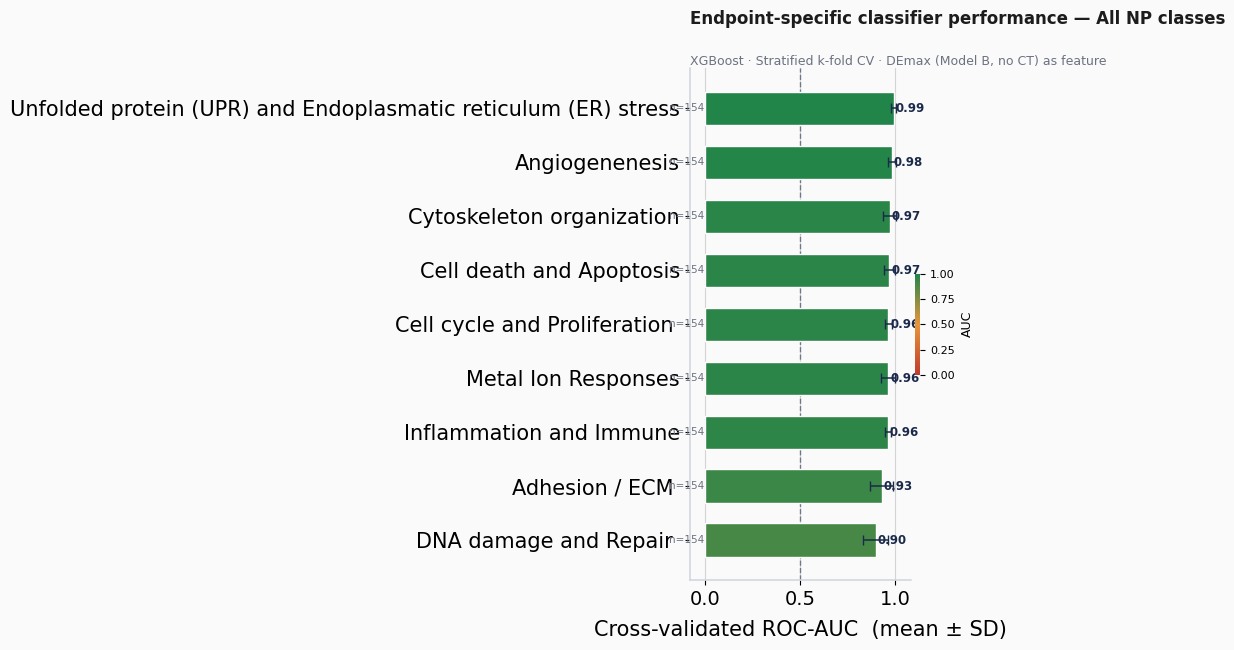

In [ ]:
# ── Fig: Classifier performance bar chart ─────────────────────
plot_perf = perf_df[perf_df['status']=='ok'].sort_values('AUC_mean', ascending=True)
if not plot_perf.empty:
    fig, ax = plt.subplots(figsize=(10, max(5, 0.55*len(plot_perf)+1.8)))
    bar_colors = [auc_color(v) for v in plot_perf['AUC_mean']]
    rects = ax.barh(plot_perf['endpoint_short'], plot_perf['AUC_mean'],
                    color=bar_colors, edgecolor='white', height=0.62, zorder=3)
    ax.errorbar(plot_perf['AUC_mean'], plot_perf['endpoint_short'],
                xerr=plot_perf['AUC_std'], fmt='none',
                ecolor=PALETTE_CLF['navy'], elinewidth=1.1, capsize=3.5, zorder=4)
    add_label(ax, rects, plot_perf['AUC_mean'].values, fmt='{:.2f}', pad=0.010)
    for i,(_,row) in enumerate(plot_perf.iterrows()):
        ax.text(-0.003, i, f"n={int(row['n'])}", va='center', ha='right',
                fontsize=7.5, color=PALETTE_CLF['subtext'])
    ax.axvline(0.5, color=PALETTE_CLF['navy'], lw=1, ls='--', alpha=0.55, zorder=2)
    sm = plt.cm.ScalarMappable(cmap=AUC_CMAP, norm=mpl.colors.Normalize(0,1)); sm.set_array([])
    cbar = fig.colorbar(sm, ax=ax, fraction=0.022, pad=0.02, shrink=0.6)
    cbar.set_label('AUC', fontsize=9); cbar.ax.tick_params(labelsize=8); cbar.outline.set_visible(False)
    ax.set_xlim(-0.08, 1.08)
    ax.set_xlabel('Cross-validated ROC-AUC  (mean ± SD)', labelpad=8)
    set_title_sub(ax,
        'Endpoint-specific classifier performance — All NP classes',
        'XGBoost · Stratified k-fold CV · DEmax (Model B, no CT) as feature')
    style_ax(ax, 'x'); plt.tight_layout()
    plt.savefig(os.path.join(CLASSIFIER_OUTDIR,'Fig_classifier_performance.png'), dpi=300)
    plt.show()


  Angiogenenesis: DEmax_pred rank=#5/77  importance=0.06875


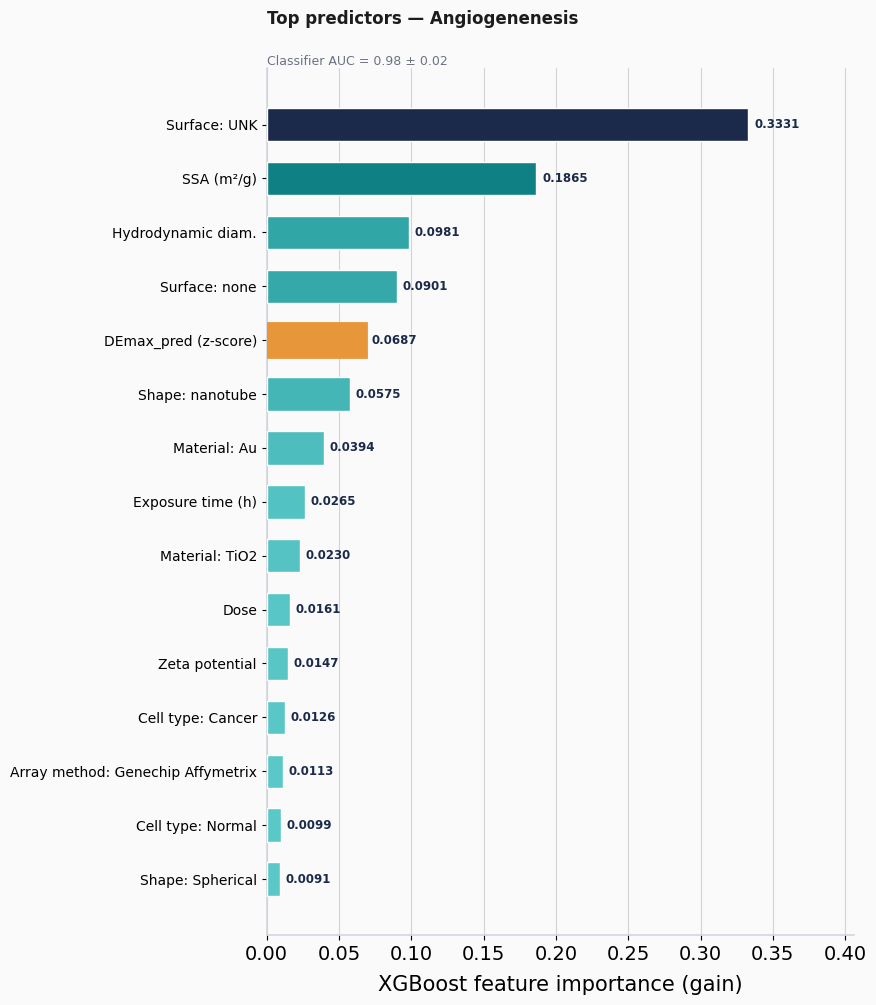

  Adhesion / ECM : DEmax_pred rank=#16/77  importance=0.01736


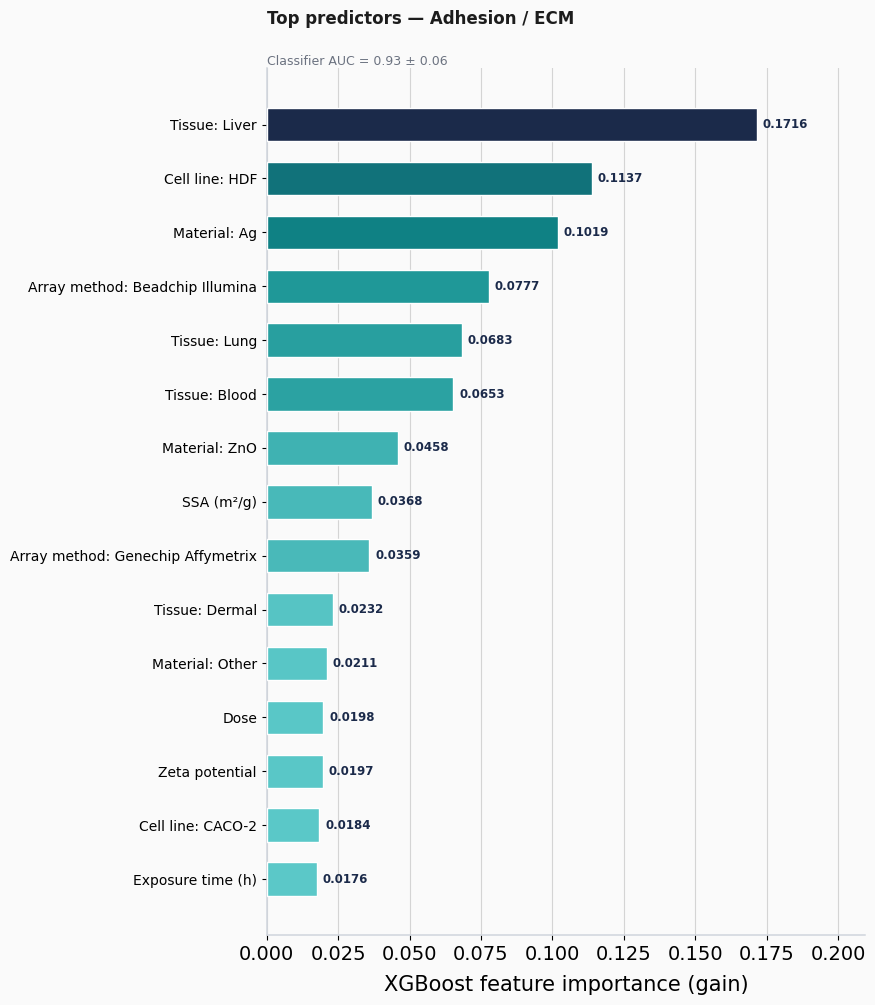

  Cell cycle and Proliferation : DEmax_pred rank=#21/77  importance=0.00909


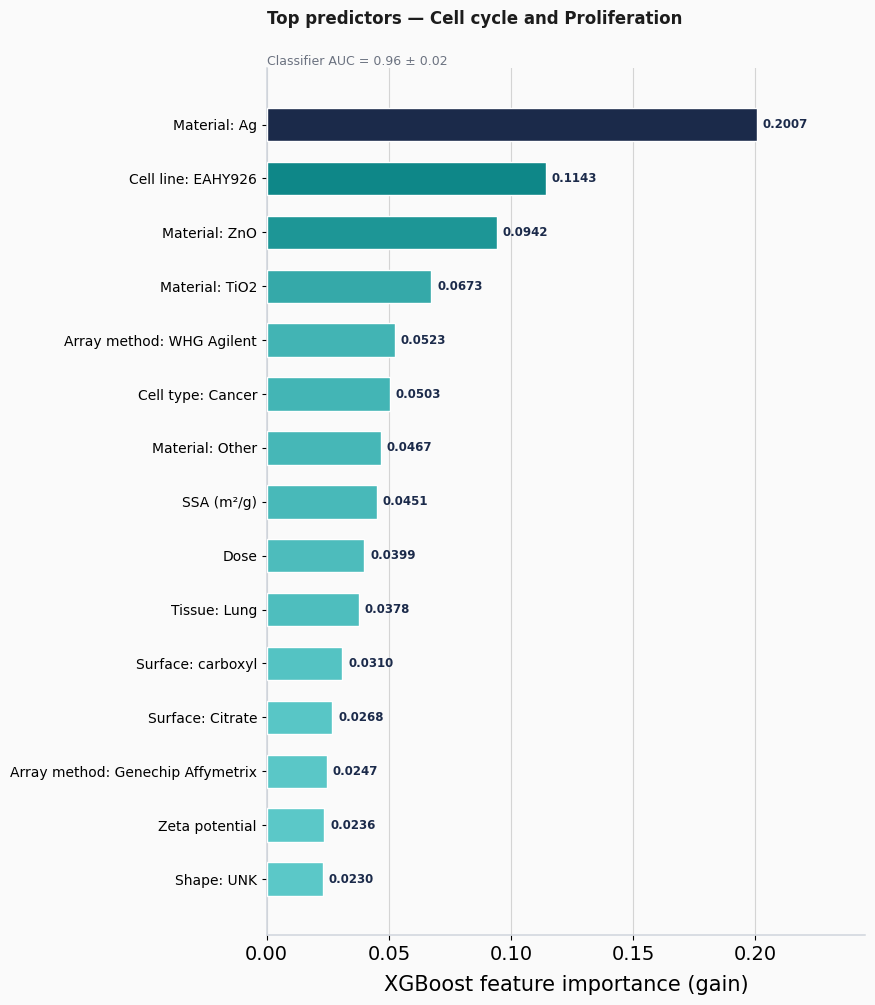

  Cell death and Apoptosis: DEmax_pred rank=#24/77  importance=0.01117


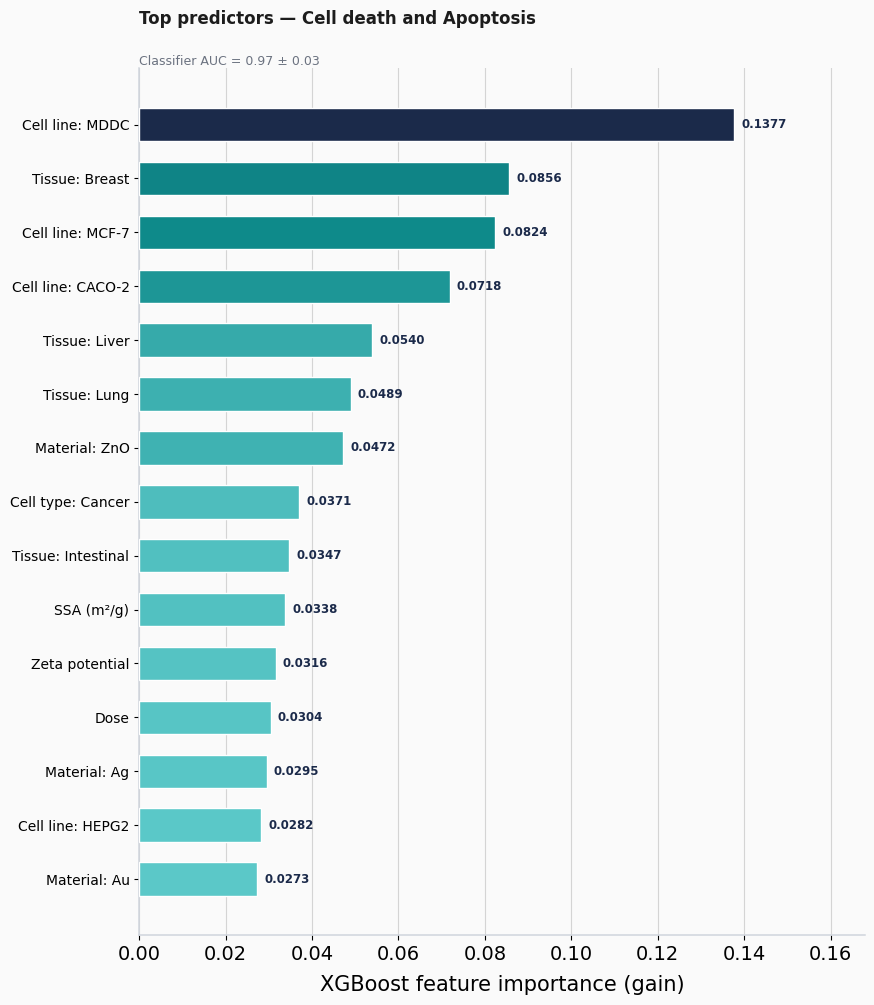

  Cytoskeleton organization: DEmax_pred rank=#9/77  importance=0.03298


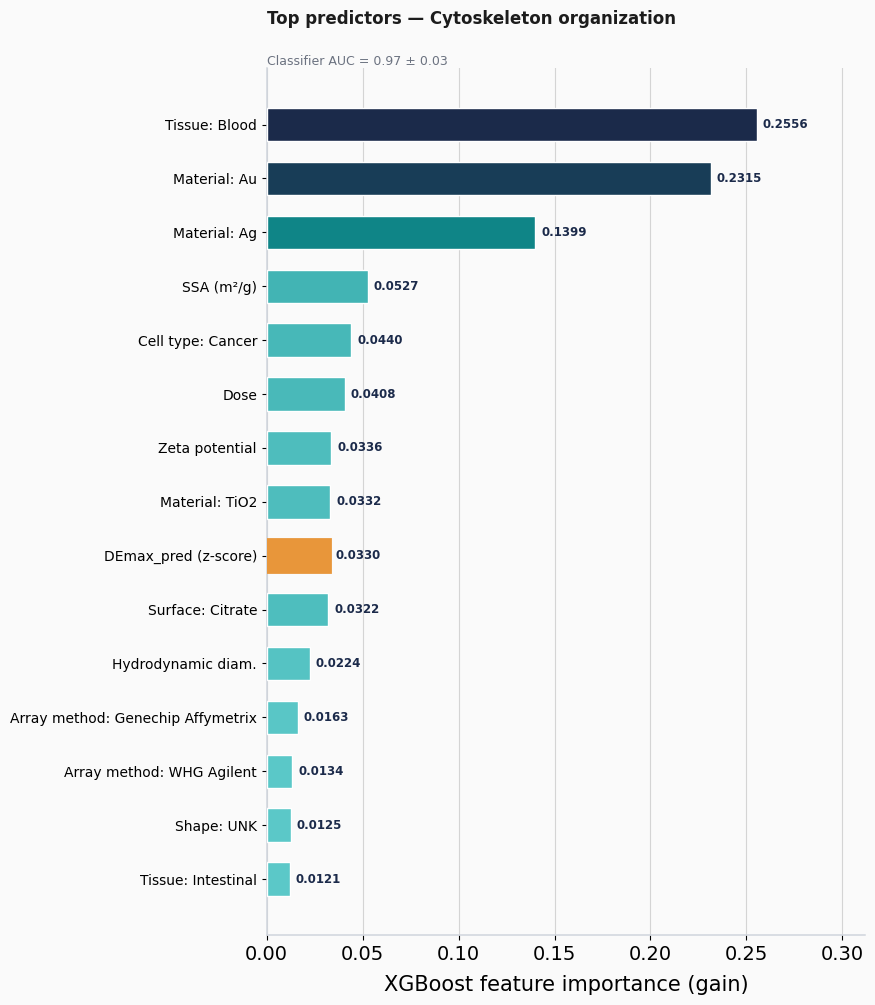

  DNA damage and Repair : DEmax_pred rank=#12/77  importance=0.03013


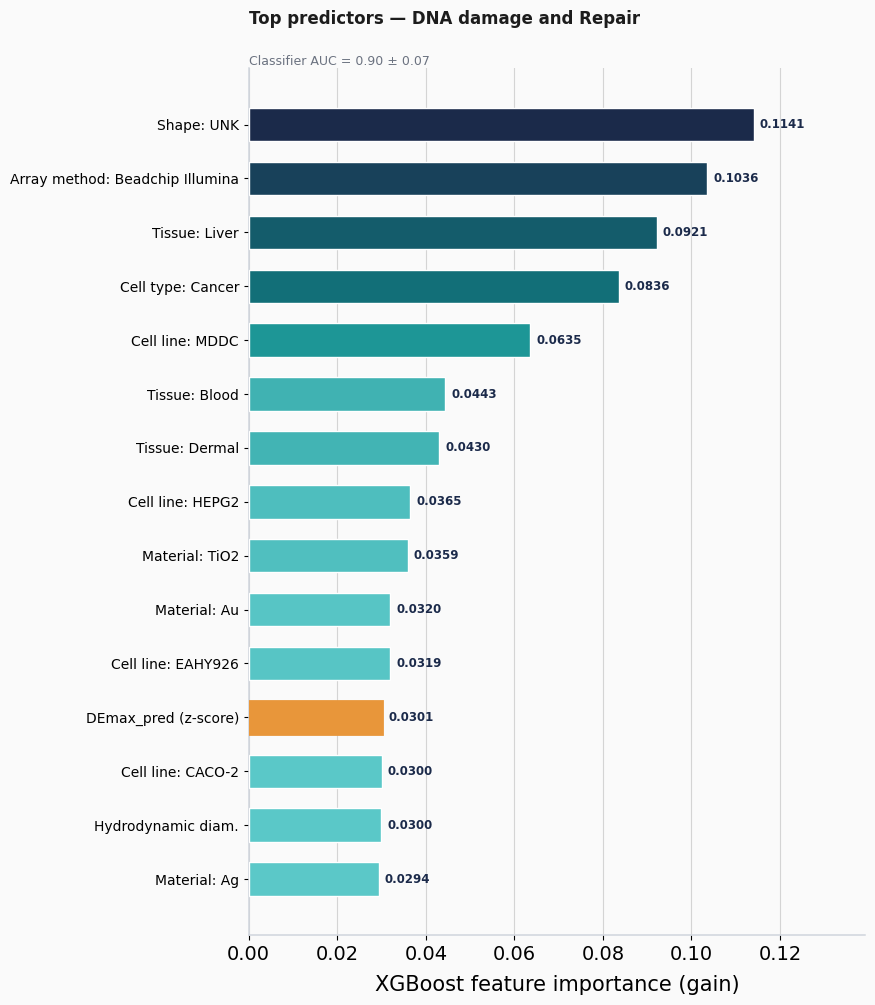

  Inflammation and Immune: DEmax_pred rank=#17/77  importance=0.01828


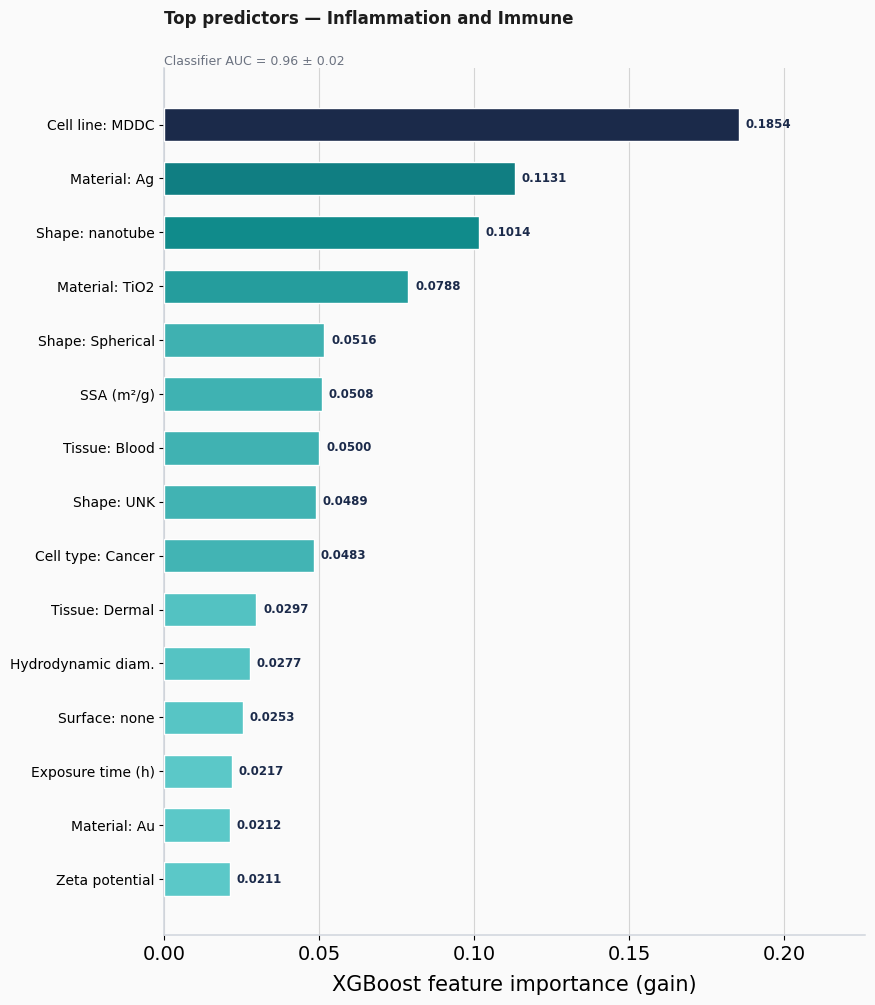

  Metal Ion Responses: DEmax_pred rank=#19/77  importance=0.01440


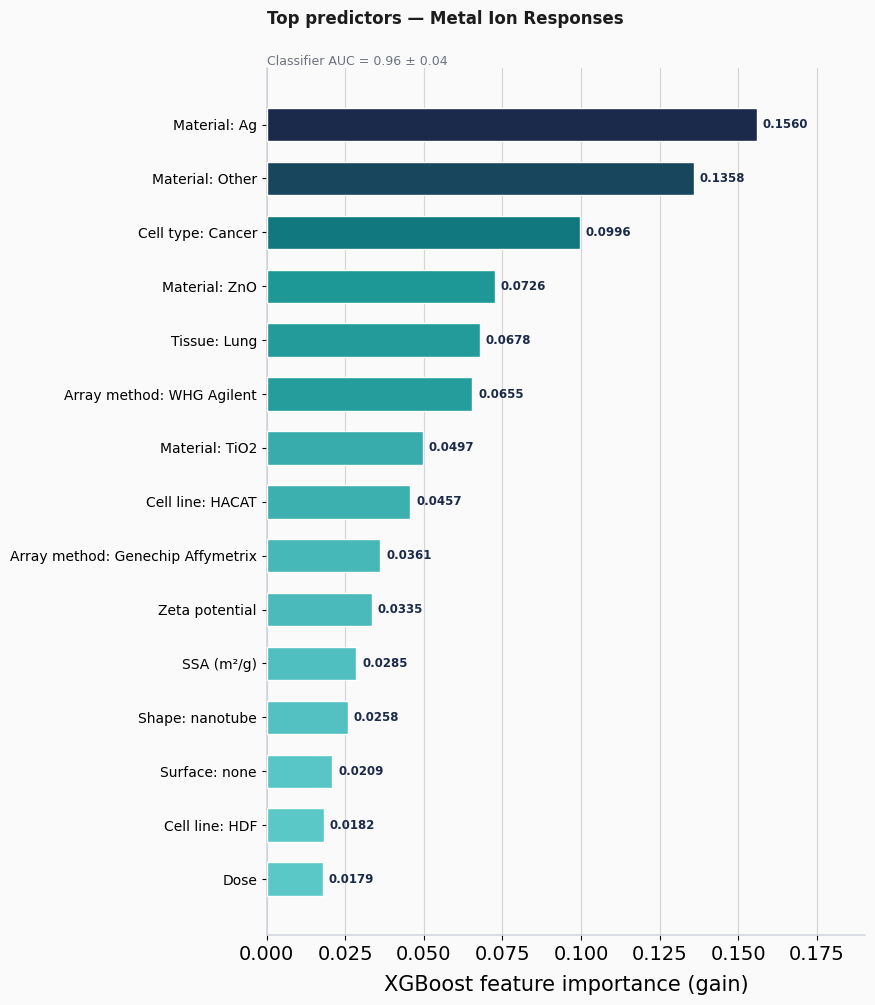

  Unfolded protein (UPR) and Endoplasmatic reticulum (ER) stress: DEmax_pred rank=#11/77  importance=0.02248


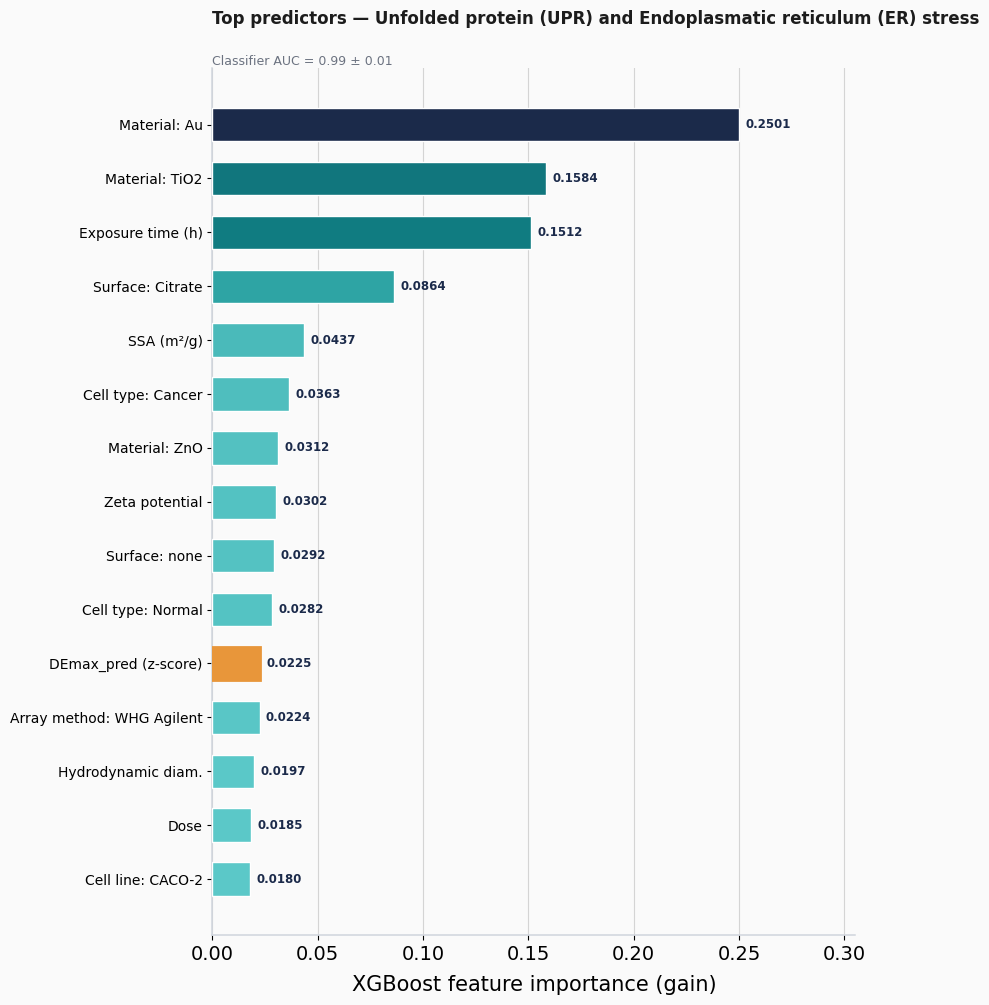

In [ ]:
# ── Fig: Top features per endpoint ───────────────────────────
for ep, imp_df in importance_tables.items():
    ep_short = clean_ep(ep)
    # Show top 15 to ensure DEmax_pred appears if present
    top = imp_df.head(15).sort_values('importance', ascending=True).copy()
    # Also print DEmax_pred rank explicitly
    demax_rank_row = imp_df.reset_index(drop=True)
    demax_rows = demax_rank_row[demax_rank_row['feature']=='DEmax_pred']
    if not demax_rows.empty:
        rank = demax_rank_row[demax_rank_row['feature']=='DEmax_pred'].index[0]+1
        val  = demax_rows['importance'].values[0]
        print(f"  {ep_short}: DEmax_pred rank=#{rank}/{len(imp_df)}  importance={val:.5f}")
    else:
        print(f"  {ep_short}: DEmax_pred NOT found in importance table")
    if top.empty: continue
    top['feature_label'] = top['feature'].apply(clean_feat_label)
    vals   = top['importance'].values
    norm   = plt.Normalize(vals.min(), vals.max())
    colors = [PALETTE['amber'] if f == 'DEmax_pred'
              else mcolors.to_hex(FEAT_CMAP(norm(v)))
              for f, v in zip(top['feature'].values, vals)]

    fig, ax = plt.subplots(figsize=(9, max(4.5, 0.52*len(top)+2.5)))
    rects = ax.barh(top['feature_label'], vals, color=colors,
                    edgecolor='white', height=0.62, zorder=3)
    for rect, feat in zip(rects, top['feature'].values):
        if feat == 'DEmax_model':
            rect.set_edgecolor(PALETTE_CLF['navy']); rect.set_linewidth(1.8)
    add_label(ax, rects, vals, fmt='{:.4f}', pad=vals.max()*0.012, fs=8.5)
    # Bold border on DEmax_pred bar
    for rect, feat in zip(rects, top['feature'].values):
        if feat == 'DEmax_pred':
            rect.set_edgecolor(PALETTE['amber'])
            rect.set_linewidth(2.0)
    ax.set_xlim(0, vals.max()*1.22)
    ax.set_xlabel('XGBoost feature importance (gain)', labelpad=8)
    ax.tick_params(axis='y', labelsize=10)
    auc_row = perf_df[perf_df['endpoint_short']==ep_short]
    sub = None
    if not auc_row.empty and not np.isnan(auc_row['AUC_mean'].values[0]):
        v,s = auc_row['AUC_mean'].values[0], auc_row['AUC_std'].values[0]
        sub = f'Classifier AUC = {v:.2f} ± {s:.2f}'
    set_title_sub(ax, f'Top predictors — {ep_short}', sub)
    style_ax(ax, 'x'); plt.tight_layout()
    plt.savefig(os.path.join(CLASSIFIER_OUTDIR,
                f'Fig_top_features_{safe_filename(ep_short)}.png'), dpi=300)
    plt.show()

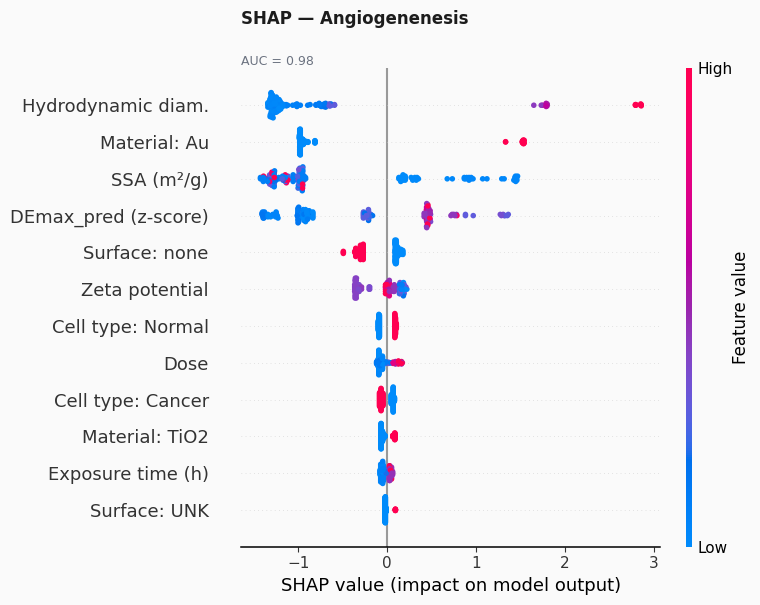

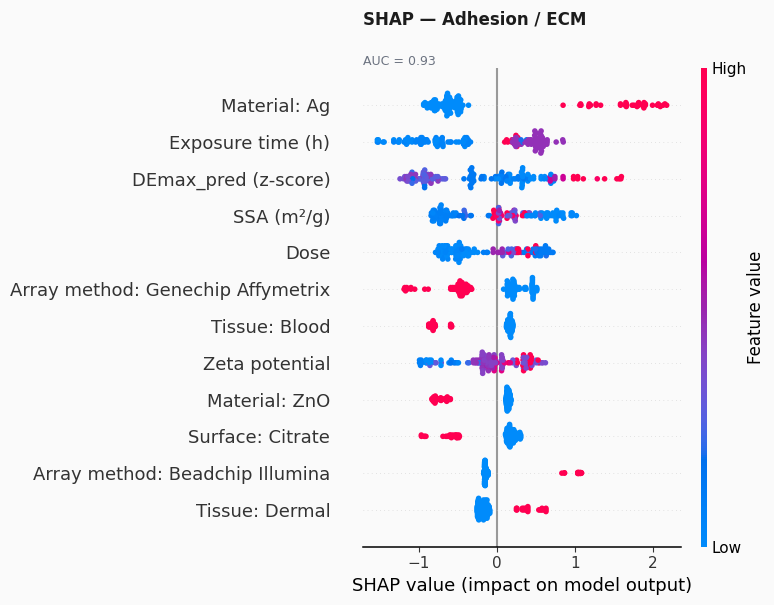

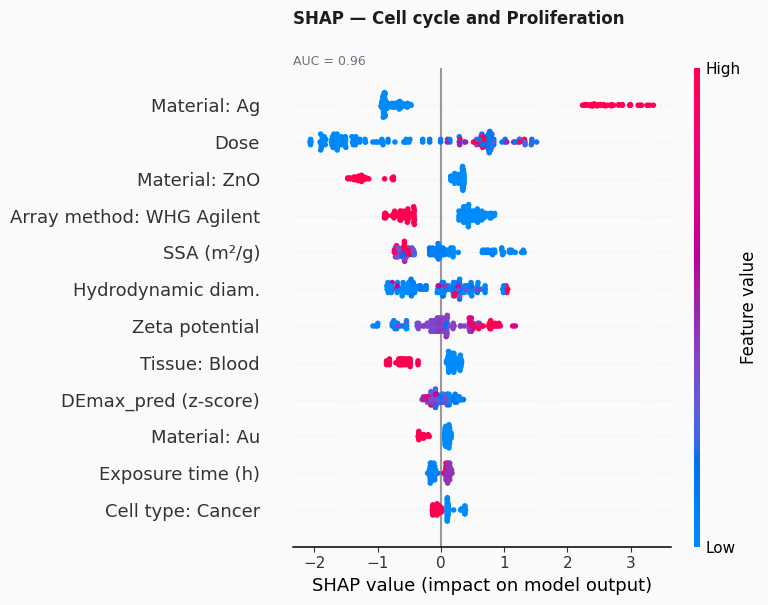

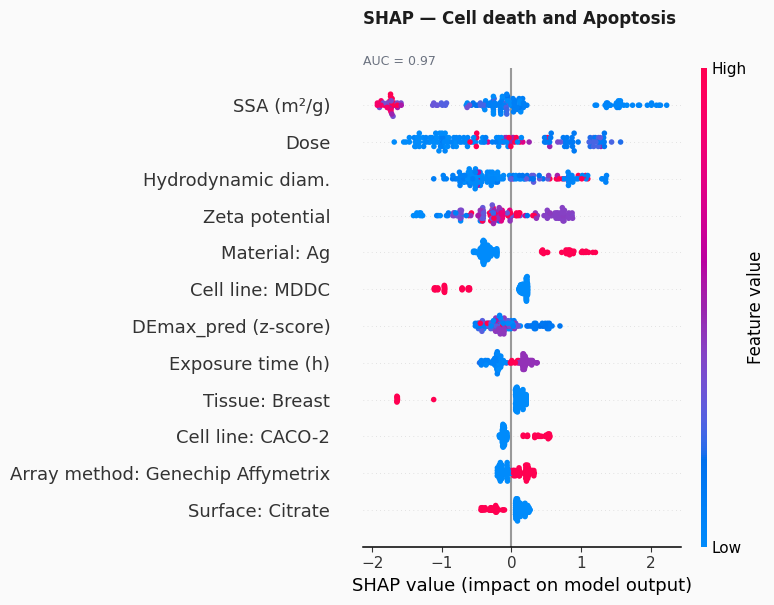

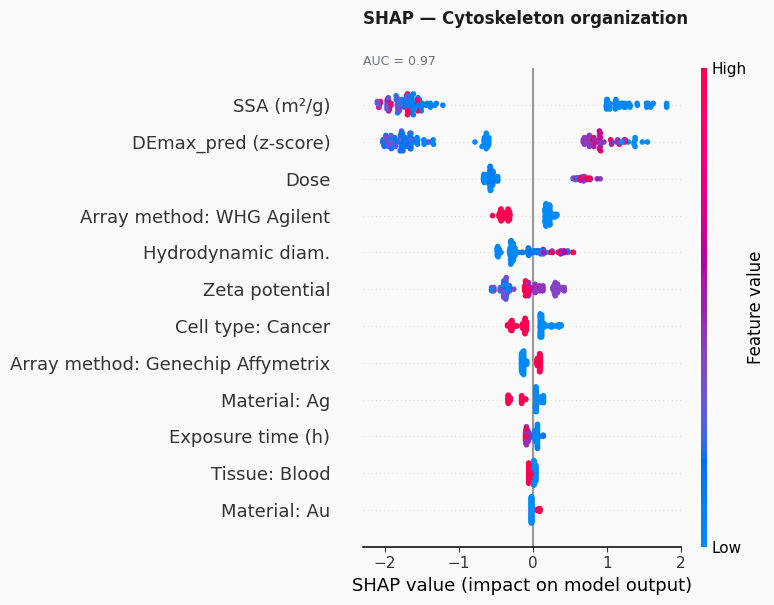

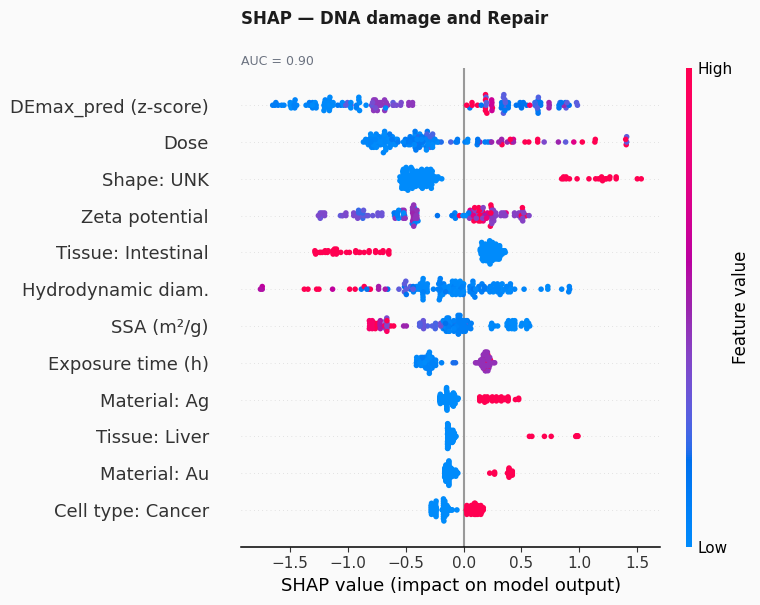

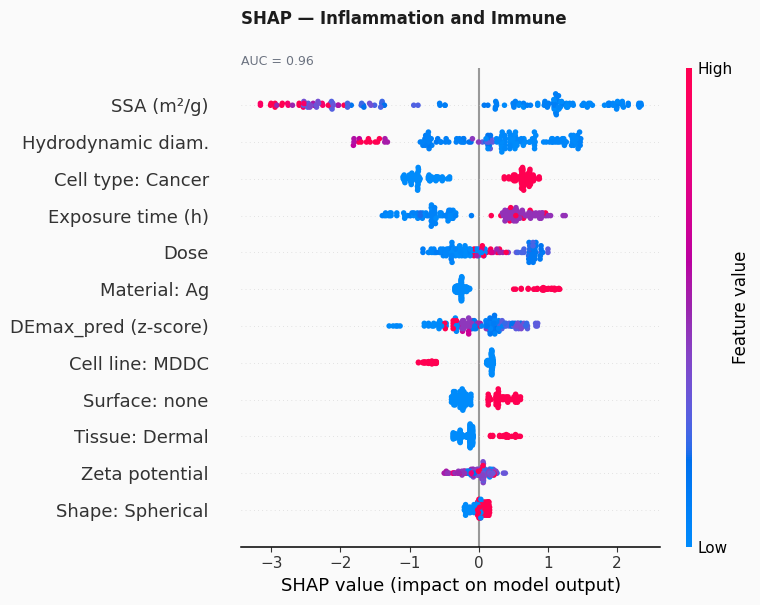

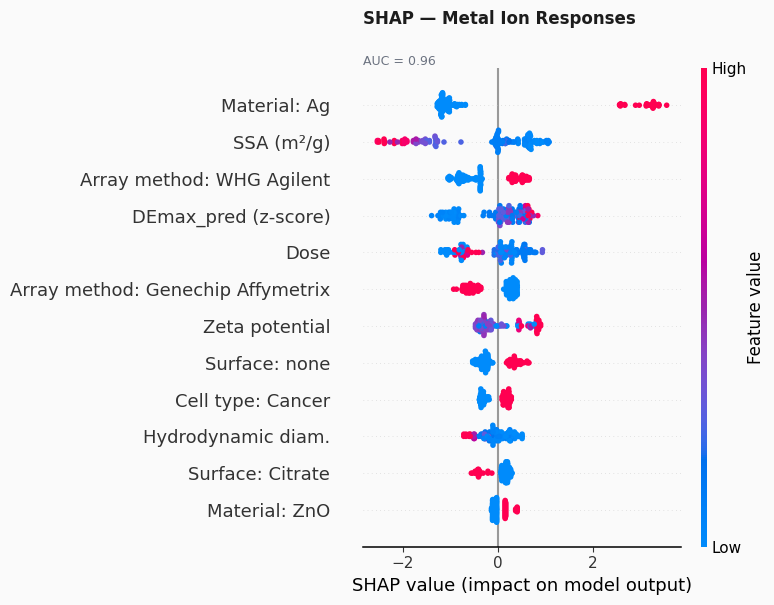

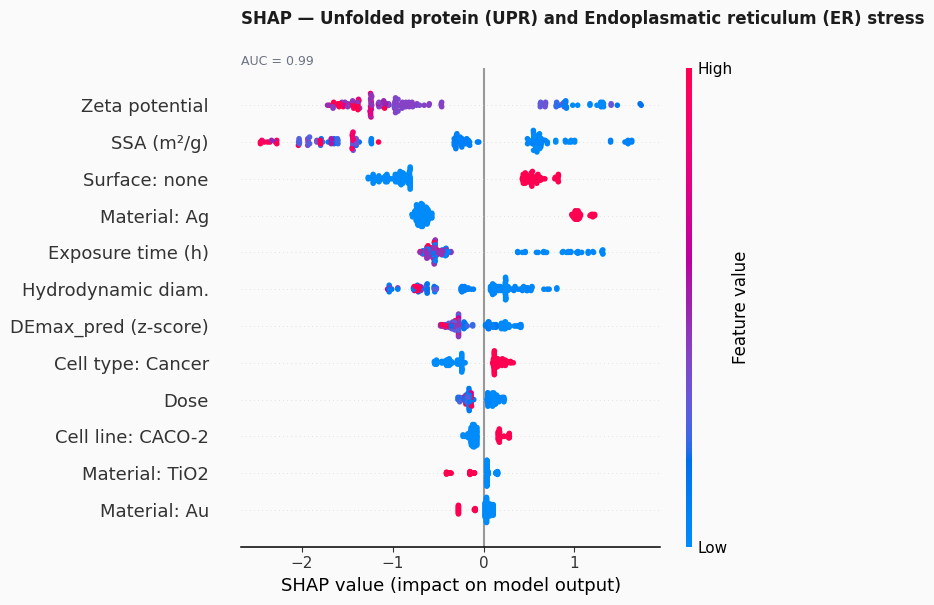


✓ All outputs saved to: All_particles_DEmax_variation_figures/endpoint_specific_classifiers/endpoint_specific_classifiers


In [ ]:
# ── SHAP analysis ─────────────────────────────────────────────
try:
    import shap
    SHAP_DIR = os.path.join(CLASSIFIER_OUTDIR, 'SHAP')
    os.makedirs(SHAP_DIR, exist_ok=True)
    for ep, pipe in models_by_endpoint.items():
        ep_short = clean_ep(ep)  # FIXED: was clean_endpoint_label(ep), which is undefined
        sub = clf_df[clf_df['tox_endpoint']==ep].copy()
        y   = sub['tox_response_num'].astype(int)
        X   = sub[FEATURES].copy()
        if y.nunique() < 2: continue
        X_trans = pipe.named_steps['preprocess'].transform(X)
        names, _ = get_clean_feature_names(pipe.named_steps['preprocess'],
                                           pipe.named_steps['model'])
        labels = [clean_feat_label(f) for f in names]
        explainer   = shap.TreeExplainer(pipe.named_steps['model'])
        shap_values = explainer.shap_values(X_trans)
        shap_plot   = shap_values[1] if isinstance(shap_values, list) else shap_values
        plt.figure(figsize=(9,5.5))
        shap.summary_plot(shap_plot, X_trans, feature_names=labels,
                          show=False, max_display=12)
        plt.gcf().set_facecolor(PALETTE_CLF['bg'])
        auc_row = perf_df[perf_df['endpoint_short']==ep_short]
        sub_txt = None
        if not auc_row.empty and not np.isnan(auc_row['AUC_mean'].values[0]):
            sub_txt = f"AUC = {auc_row['AUC_mean'].values[0]:.2f}"
        set_title_sub(plt.gca(), f'SHAP — {ep_short}', sub_txt)
        plt.tight_layout()
        plt.savefig(os.path.join(SHAP_DIR, f'SHAP_{safe_filename(ep_short)}.png'), dpi=300)
        plt.show()
except ImportError:
    print("SHAP not installed. Run: !pip install shap")
except Exception as e:
    print("SHAP failed:", e)

print(f"\n✓ All outputs saved to: {CLASSIFIER_OUTDIR}")


---
## § Feature Importance Comparison
### Model A (nanotumor DEmax regressor) vs Endpoint Classifiers (transcriptomics + DEmax_pred)

The two models answer different questions:
- **Model A**: *What drives cellular uptake (DEmax) in tumor models?*
- **Endpoint Classifier**: *What drives toxicity endpoint activation in transcriptomics data?*

Comparing their feature importances reveals which factors matter at each stage.


In [ ]:
# =========================================================
# SECTION A: Feature Importance — Model A (nanotumor)
# =========================================================
from sklearn.inspection import permutation_importance as perm_imp

PALETTE = {
    'navy':'#1B2A4A','teal':'#0E8A8A','teal_light':'#5BC8C8',
    'amber':'#E8963A','red':'#C0392B','green':'#1E8449',
    'bg':'#FAFAFA','subtext':'#6B7280','text':'#1C1C1C',
}
mpl.rcParams.update({
    'figure.facecolor':PALETTE['bg'],'axes.facecolor':PALETTE['bg'],
    'axes.spines.top':False,'axes.spines.right':False,
    'font.family':'sans-serif','savefig.dpi':300,
    'savefig.bbox':'tight','savefig.facecolor':PALETTE['bg'],
})

FEAT_LABEL_A = {
    'TS':'Targeting Strategy','TW':'Tumor Weight',
    'Type':'NP Type','TM':'Tumor Model','CT':'Cell Type',
    'Shape':'Shape','TSz':'Tumor Size','Charge':'Surface Charge',
    'Zeta':'Zeta Potential','HD':'Hydrodynamic Diam.',
}
FEAT_LABEL_B = {
    'Type':'NP Type','HD':'Hydrodynamic Diam.',
    'Zeta':'Zeta Potential','Charge':'Surface Charge',
    'Shape':'Shape','CT':'Cell Type (mapped)',
}

# Get gain importance from Model A grid search
try:
    imp_a_raw = xgb_a_grid.best_estimator_.get_booster().get_score(importance_type='gain')
    imp_a_df  = (pd.DataFrame.from_dict(imp_a_raw,orient='index',columns=['gain'])
                 .reset_index().rename(columns={'index':'feature'})
                 .sort_values('gain',ascending=False))
except Exception:
    imp_a_df = pd.DataFrame({
        'feature':FEATURES_A,
        'gain':xgb_a_bag.estimators_[0].feature_importances_
    }).sort_values('gain',ascending=False)

# Get gain importance from Model B grid search
try:
    imp_b_raw = xgb_b_grid.best_estimator_.get_booster().get_score(importance_type='gain')
    imp_b_df  = (pd.DataFrame.from_dict(imp_b_raw,orient='index',columns=['gain'])
                 .reset_index().rename(columns={'index':'feature'})
                 .sort_values('gain',ascending=False))
except Exception:
    imp_b_df = pd.DataFrame({
        'feature':FEATURES_B,
        'gain':xgb_b_bag.estimators_[0].feature_importances_
    }).sort_values('gain',ascending=False)

# Add readable labels
imp_a_df['label'] = imp_a_df['feature'].map(FEAT_LABEL_A).fillna(imp_a_df['feature'])
imp_b_df['label'] = imp_b_df['feature'].map(FEAT_LABEL_B).fillna(imp_b_df['feature'])

# Get aggregated classifier importance (sum across all endpoints)
all_imp_rows = []
for ep, imp_df in importance_tables.items():
    all_imp_rows.append(imp_df)
all_imp_concat = pd.concat(all_imp_rows, ignore_index=True)

# Aggregate by feature group
def feat_group(f):
    f = str(f)
    if f in ['HD','Zeta','Dose','ExposureTime_h','SSA_m2g','DEmax_pred']: return f
    if f.startswith('MaterialClass_'): return 'Material class'
    if f.startswith('Surface_'):       return 'Surface coating'
    if f.startswith('Shape_'):         return 'Shape'
    if f.startswith('Tissue_'):        return 'Tissue'
    if f.startswith('CellType_'):      return 'Cell type'
    if f.startswith('CellLine_'):      return 'Cell line'
    if f.startswith('TranscriptomicsMethod_'): return 'Array method'
    return 'Other'

all_imp_concat['group'] = all_imp_concat['feature'].apply(feat_group)
clf_group_imp = (all_imp_concat.groupby('group')['importance']
                 .sum().reset_index()
                 .sort_values('importance',ascending=False))
# Normalize to 0-1
clf_group_imp['importance_norm'] = (clf_group_imp['importance'] /
                                    clf_group_imp['importance'].sum())

GROUP_LABELS = {
    'DEmax_pred':'DEmax_pred (from Model B)',
    'HD':'Hydrodynamic Diam.','Zeta':'Zeta Potential',
    'Dose':'Dose','ExposureTime_h':'Exposure Time',
    'SSA_m2g':'Specific Surface Area',
    'Material class':'Material Class','Surface coating':'Surface Coating',
    'Shape':'Shape','Tissue':'Tissue',
    'Cell type':'Cell Type','Cell line':'Cell Line',
    'Array method':'Array Method','Other':'Other',
}
clf_group_imp['label'] = clf_group_imp['group'].map(GROUP_LABELS).fillna(clf_group_imp['group'])

print("Model A top features:")
print(imp_a_df[['label','gain']].to_string(index=False))
print()
print("Model B top features:")
print(imp_b_df[['label','gain']].to_string(index=False))
print()
print("Classifier feature groups (summed across all endpoints, normalised):")
print(clf_group_imp[['label','importance_norm']].to_string(index=False))


Model A top features:
             label     gain
         Cell Type 1.043378
Targeting Strategy 0.781506
    Surface Charge 0.565898
    Zeta Potential 0.555253
       Tumor Model 0.455250
           NP Type 0.392858
             Shape 0.371860
Hydrodynamic Diam. 0.272612
      Tumor Weight 0.269843
        Tumor Size 0.257584

Model B top features:
             label     gain
Cell Type (mapped) 0.959267
    Zeta Potential 0.560911
             Shape 0.547653
Hydrodynamic Diam. 0.495753

Classifier feature groups (summed across all endpoints, normalised):
                    label  importance_norm
           Material Class         0.267216
                   Tissue         0.145016
                Cell Line         0.118330
          Surface Coating         0.089290
                    Shape         0.066887
             Array Method         0.060388
                Cell Type         0.058184
    Specific Surface Area         0.055670
            Exposure Time         0.032548
       

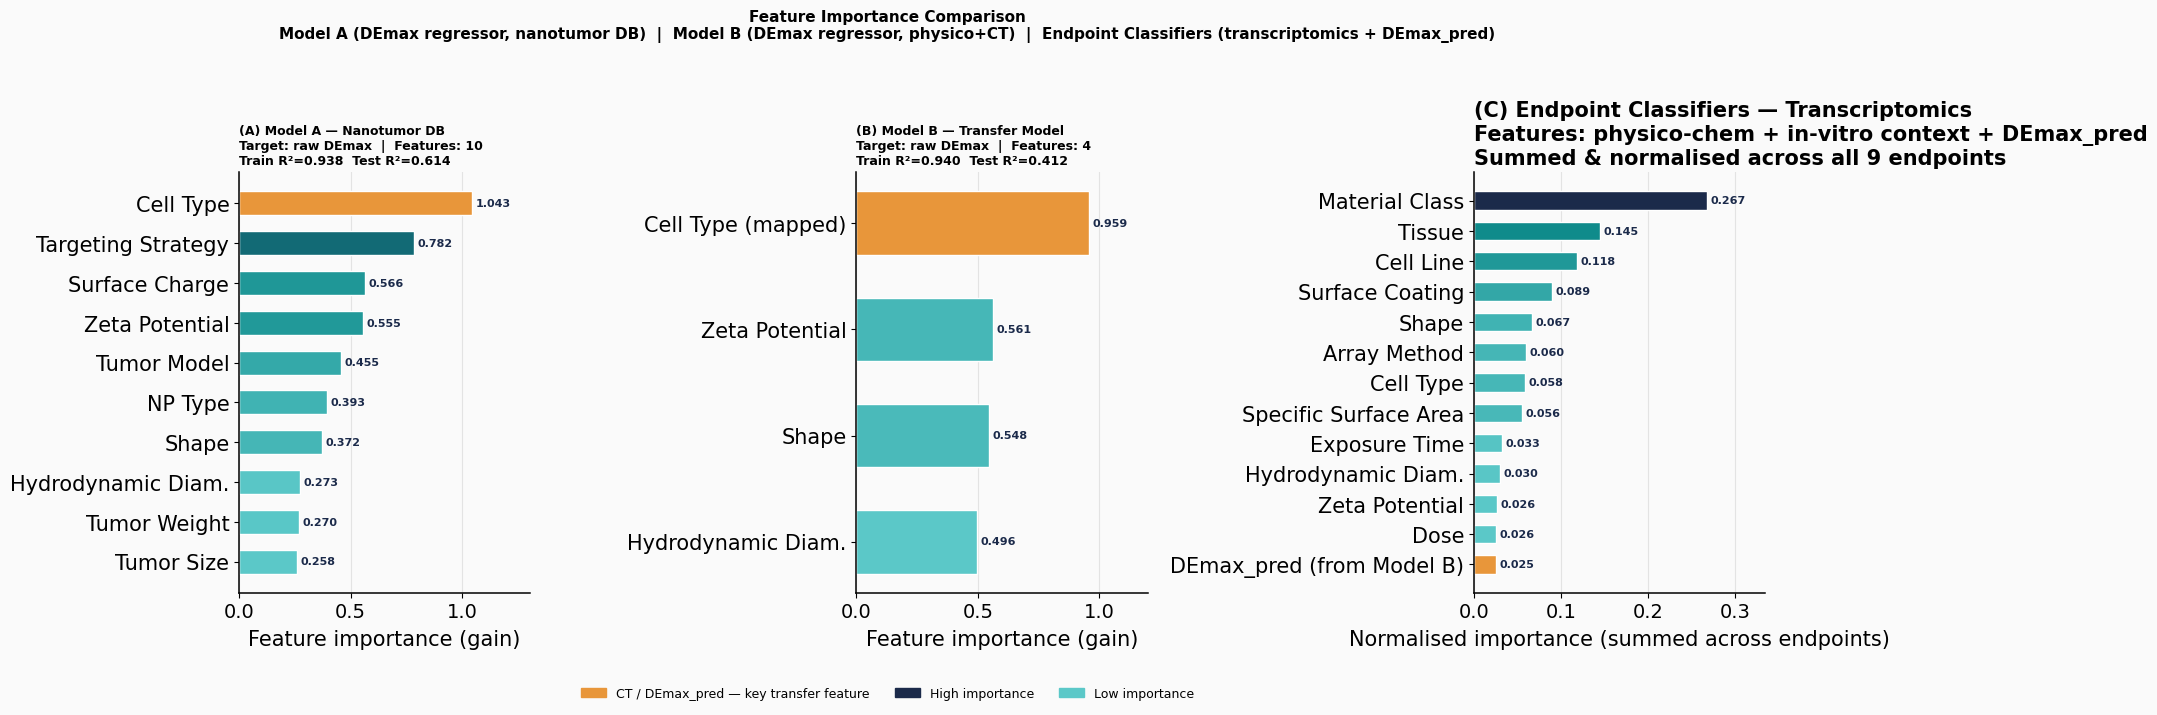

Saved: Fig_FeatureImportance_AllModels.png


In [ ]:
# ── Plot: 3-panel feature importance comparison ──────────────
FEAT_CMAP = mcolors.LinearSegmentedColormap.from_list(
    'feat',[PALETTE['teal_light'],PALETTE['teal'],PALETTE['navy']])

fig, axes = plt.subplots(1, 3, figsize=(18, 6.5))
fig.suptitle(
    'Feature Importance Comparison\n'
    'Model A (DEmax regressor, nanotumor DB)  |  '
    'Model B (DEmax regressor, physico+CT)  |  '
    'Endpoint Classifiers (transcriptomics + DEmax_pred)',
    fontsize=11, fontweight='bold', y=1.02)

# ── Panel A: Model A importance ──────────────────────────────
ax = axes[0]
top_a = imp_a_df.sort_values('gain',ascending=True)
vals_a = top_a['gain'].values
norm_a = plt.Normalize(vals_a.min(), vals_a.max())
colors_a = [PALETTE['amber'] if f=='CT' else
            mcolors.to_hex(FEAT_CMAP(norm_a(v)))
            for f,v in zip(top_a['feature'],vals_a)]
ax.barh(top_a['label'], vals_a, color=colors_a, edgecolor='white', height=0.6)
for i,(v,f) in enumerate(zip(vals_a,top_a['feature'])):
    ax.text(v + vals_a.max()*0.015, i, f'{v:.3f}',
            va='center', fontsize=8, color=PALETTE['navy'], fontweight='semibold')
ax.set_xlabel('Feature importance (gain)', labelpad=6)
ax.set_title(f'(A) Model A — Nanotumor DB\n'
             f'Target: raw DEmax  |  Features: {len(FEATURES_A)}\n'
             f'Train R²={R2_A_TRAIN:.3f}  Test R²={R2_A_TEST:.3f}',
             fontsize=9, fontweight='bold', loc='left')
ax.grid(axis='x', alpha=0.3); ax.set_axisbelow(True)
ax.set_xlim(0, vals_a.max()*1.25)

# ── Panel B: Model B importance ──────────────────────────────
ax2 = axes[1]
top_b = imp_b_df.sort_values('gain',ascending=True)
vals_b = top_b['gain'].values
norm_b = plt.Normalize(vals_b.min(), vals_b.max())
colors_b = [PALETTE['amber'] if f=='CT' else
            mcolors.to_hex(FEAT_CMAP(norm_b(v)))
            for f,v in zip(top_b['feature'],vals_b)]
ax2.barh(top_b['label'], vals_b, color=colors_b, edgecolor='white', height=0.6)
for i,(v,f) in enumerate(zip(vals_b,top_b['feature'])):
    ax2.text(v + vals_b.max()*0.015, i, f'{v:.3f}',
             va='center', fontsize=8, color=PALETTE['navy'], fontweight='semibold')
ax2.set_xlabel('Feature importance (gain)', labelpad=6)
ax2.set_title(f'(B) Model B — Transfer Model\n'
              f'Target: raw DEmax  |  Features: {len(FEATURES_B)}\n'
              f'Train R²={R2_B_TRAIN:.3f}  Test R²={R2_B_TEST:.3f}',
              fontsize=9, fontweight='bold', loc='left')
ax2.grid(axis='x', alpha=0.3); ax2.set_axisbelow(True)
ax2.set_xlim(0, vals_b.max()*1.25)

# ── Panel C: Classifier feature group importance ──────────────
ax3 = axes[2]
top_c = clf_group_imp.sort_values('importance_norm',ascending=True)
vals_c = top_c['importance_norm'].values
norm_c = plt.Normalize(vals_c.min(), vals_c.max())
colors_c = [PALETTE['amber'] if 'DEmax' in str(g) else
            mcolors.to_hex(FEAT_CMAP(norm_c(v)))
            for g,v in zip(top_c['group'],vals_c)]
ax3.barh(top_c['label'], vals_c, color=colors_c, edgecolor='white', height=0.6)
for i,(v,g) in enumerate(zip(vals_c,top_c['group'])):
    ax3.text(v + vals_c.max()*0.015, i, f'{v:.3f}',
             va='center', fontsize=8, color=PALETTE['navy'], fontweight='semibold')
ax3.set_xlabel('Normalised importance (summed across endpoints)', labelpad=6)
ax3.set_title('(C) Endpoint Classifiers — Transcriptomics\n'
              'Features: physico-chem + in-vitro context + DEmax_pred\n'
              'Summed & normalised across all 9 endpoints',
              fontsize=15, fontweight='bold', loc='left')
ax3.grid(axis='x', alpha=0.3); ax3.set_axisbelow(True)
ax3.set_xlim(0, vals_c.max()*1.25)

# Legend
legend_patches = [
    mpatches.Patch(color=PALETTE['amber'], label='CT / DEmax_pred — key transfer feature'),
    mpatches.Patch(color=PALETTE['navy'],  label='High importance'),
    mpatches.Patch(color=PALETTE['teal_light'], label='Low importance'),
]
fig.legend(handles=legend_patches, loc='lower center', ncol=3,
           fontsize=9, frameon=False, bbox_to_anchor=(0.5,-0.06))

plt.tight_layout()
plt.savefig('Fig_FeatureImportance_AllModels.png', dpi=300, bbox_inches='tight')
plt.show()
print("Saved: Fig_FeatureImportance_AllModels.png")


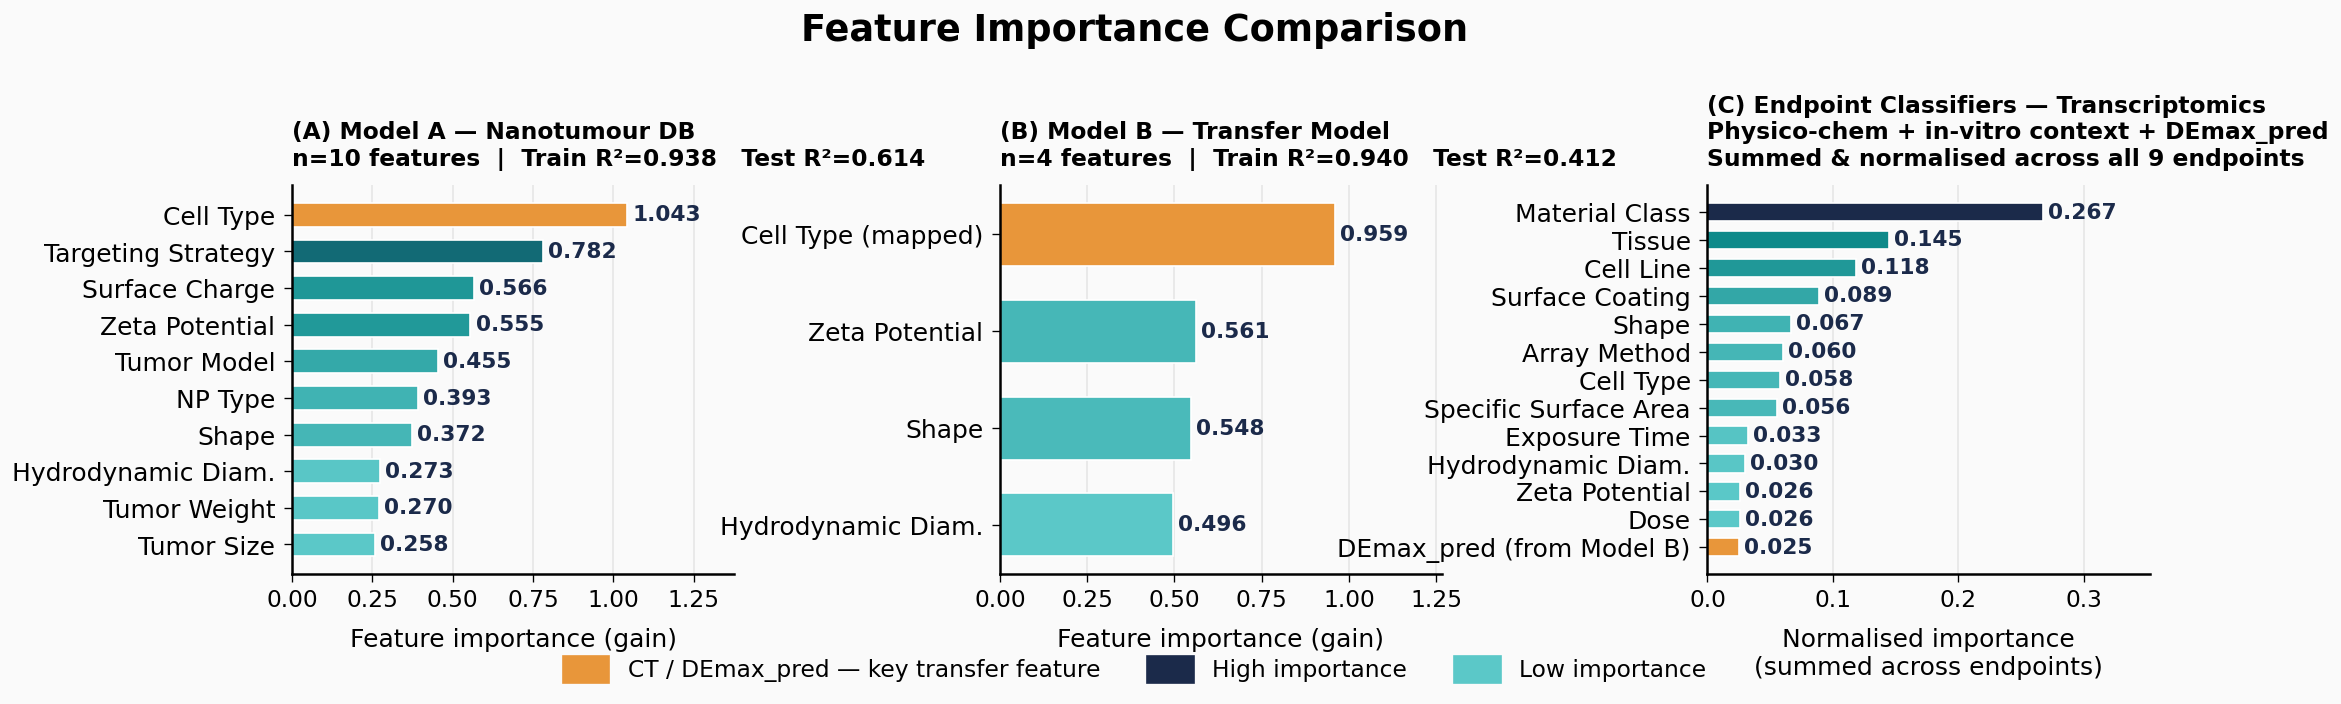

Saved: Fig_FeatureImportance_AllModels.png


In [ ]:
import matplotlib as mpl
mpl.rcParams.update({
    'figure.dpi'     : 120,          # ← display DPI in notebook
    'savefig.dpi'    : 300,
    'font.family'    : 'DejaVu Sans',
    'font.size'      : 16,
    'axes.titlesize' : 16,
    'axes.labelsize' : 15,
    'xtick.labelsize': 14,
    'ytick.labelsize': 15,
    'axes.linewidth' : 1.5,
    'pdf.fonttype'   : 42,
    'ps.fonttype'    : 42,
})

FEAT_CMAP = mcolors.LinearSegmentedColormap.from_list(
    'feat', [PALETTE['teal_light'], PALETTE['teal'], PALETTE['navy']])

# ← smaller figure = fonts look proportionally BIGGER
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
fig.subplots_adjust(
    left=0.11, right=0.97,
    top=0.76, bottom=0.22,
    wspace=0.60)

fig.text(0.5, 0.95,
         'Feature Importance Comparison',
         ha='center', va='bottom',
         fontsize=22, fontweight='bold')

def draw_panel(ax, labels, vals, colors, xlabel, title):
    ax.barh(labels, vals, color=colors,
            edgecolor='white', height=0.65)
    for i, v in enumerate(vals):
        ax.text(v + vals.max()*0.015, i, f'{v:.3f}',
                va='center', fontsize=13,
                fontweight='bold', color=PALETTE['navy'])
    ax.set_xlabel(xlabel, fontsize=15, labelpad=10)
    ax.set_title(title, fontsize=14, fontweight='bold',
                 loc='left', pad=12)
    ax.tick_params(axis='y', labelsize=15, length=5, pad=5)
    ax.tick_params(axis='x', labelsize=14, length=5)
    ax.grid(axis='x', alpha=0.3, linewidth=0.9)
    ax.set_axisbelow(True)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.set_xlim(0, vals.max()*1.32)

# ── Panel A ───────────────────────────────────────────────────
top_a  = imp_a_df.sort_values('gain', ascending=True)
vals_a = top_a['gain'].values
norm_a = plt.Normalize(vals_a.min(), vals_a.max())
colors_a = [PALETTE['amber'] if f == 'CT'
            else mcolors.to_hex(FEAT_CMAP(norm_a(v)))
            for f, v in zip(top_a['feature'], vals_a)]

draw_panel(axes[0],
           top_a['label'], vals_a, colors_a,
           xlabel='Feature importance (gain)',
           title=(f'(A) Model A — Nanotumour DB\n'
                  f'n={len(FEATURES_A)} features  |  '
                  f'Train R²={R2_A_TRAIN:.3f}   Test R²={R2_A_TEST:.3f}'))

# ── Panel B ───────────────────────────────────────────────────
top_b  = imp_b_df.sort_values('gain', ascending=True)
vals_b = top_b['gain'].values
norm_b = plt.Normalize(vals_b.min(), vals_b.max())
colors_b = [PALETTE['amber'] if f == 'CT'
            else mcolors.to_hex(FEAT_CMAP(norm_b(v)))
            for f, v in zip(top_b['feature'], vals_b)]

draw_panel(axes[1],
           top_b['label'], vals_b, colors_b,
           xlabel='Feature importance (gain)',
           title=(f'(B) Model B — Transfer Model\n'
                  f'n={len(FEATURES_B)} features  |  '
                  f'Train R²={R2_B_TRAIN:.3f}   Test R²={R2_B_TEST:.3f}'))

# ── Panel C ───────────────────────────────────────────────────
top_c  = clf_group_imp.sort_values('importance_norm', ascending=True)
vals_c = top_c['importance_norm'].values
norm_c = plt.Normalize(vals_c.min(), vals_c.max())
colors_c = [PALETTE['amber'] if 'DEmax' in str(g)
            else mcolors.to_hex(FEAT_CMAP(norm_c(v)))
            for g, v in zip(top_c['group'], vals_c)]

draw_panel(axes[2],
           top_c['label'], vals_c, colors_c,
           xlabel='Normalised importance\n(summed across endpoints)',
           title=('(C) Endpoint Classifiers — Transcriptomics\n'
                  'Physico-chem + in-vitro context + DEmax_pred\n'
                  'Summed & normalised across all 9 endpoints'))

# ── Legend ────────────────────────────────────────────────────
legend_patches = [
    mpatches.Patch(color=PALETTE['amber'],
                   label='CT / DEmax_pred — key transfer feature'),
    mpatches.Patch(color=PALETTE['navy'],
                   label='High importance'),
    mpatches.Patch(color=PALETTE['teal_light'],
                   label='Low importance'),
]
fig.legend(handles=legend_patches,
           loc='lower center', ncol=3,
           fontsize=14, frameon=False,
           bbox_to_anchor=(0.5, 0.04),
           handlelength=2.0, handleheight=1.4)

# ── Save ──────────────────────────────────────────────────────
plt.savefig('Fig_FeatureImportance_AllModels.png',
            dpi=300, bbox_inches='tight', facecolor='white')
plt.savefig('Fig_FeatureImportance_AllModels.pdf',
            bbox_inches='tight', facecolor='white')
plt.show()
print("Saved: Fig_FeatureImportance_AllModels.png")

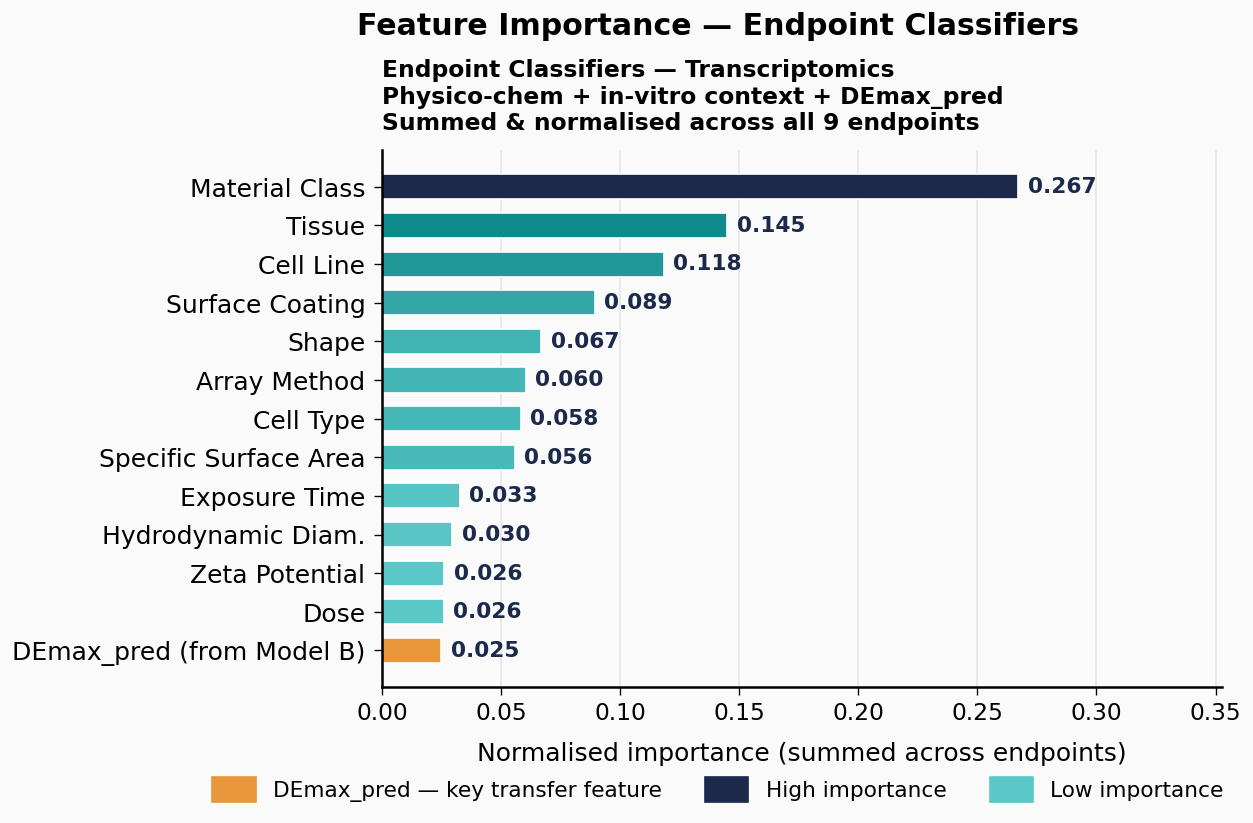

Saved: Fig_FeatureImportance_Classifiers.png


In [ ]:
import matplotlib as mpl
mpl.rcParams.update({
    'figure.dpi'     : 120,
    'savefig.dpi'    : 300,
    'font.family'    : 'DejaVu Sans',
    'font.size'      : 16,
    'axes.titlesize' : 16,
    'axes.labelsize' : 15,
    'xtick.labelsize': 14,
    'ytick.labelsize': 15,
    'axes.linewidth' : 1.5,
    'pdf.fonttype'   : 42,
    'ps.fonttype'    : 42,
})

FEAT_CMAP = mcolors.LinearSegmentedColormap.from_list(
    'feat', [PALETTE['teal_light'], PALETTE['teal'], PALETTE['navy']])

fig, ax = plt.subplots(1, 1, figsize=(10, 7))
fig.subplots_adjust(
    left=0.22, right=0.92,
    top=0.82, bottom=0.18)

fig.text(0.5, 0.95,
         'Feature Importance — Endpoint Classifiers',
         ha='center', va='bottom',
         fontsize=18, fontweight='bold')

# ── Panel C only ──────────────────────────────────────────────
top_c  = clf_group_imp.sort_values('importance_norm', ascending=True)
vals_c = top_c['importance_norm'].values
norm_c = plt.Normalize(vals_c.min(), vals_c.max())
colors_c = [PALETTE['amber'] if 'DEmax' in str(g)
            else mcolors.to_hex(FEAT_CMAP(norm_c(v)))
            for g, v in zip(top_c['group'], vals_c)]

ax.barh(top_c['label'], vals_c,
        color=colors_c, edgecolor='white', height=0.65)

for i, v in enumerate(vals_c):
    ax.text(v + vals_c.max()*0.015, i, f'{v:.3f}',
            va='center', fontsize=13,
            fontweight='bold', color=PALETTE['navy'])

ax.set_xlabel('Normalised importance (summed across endpoints)',
              fontsize=15, labelpad=10)
ax.set_title(
    'Endpoint Classifiers — Transcriptomics\n'
    'Physico-chem + in-vitro context + DEmax_pred\n'
    'Summed & normalised across all 9 endpoints',
    fontsize=14, fontweight='bold', loc='left', pad=12)
ax.tick_params(axis='y', labelsize=15, length=5, pad=5)
ax.tick_params(axis='x', labelsize=14, length=5)
ax.grid(axis='x', alpha=0.3, linewidth=0.9)
ax.set_axisbelow(True)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.set_xlim(0, vals_c.max()*1.32)

# ── Legend ────────────────────────────────────────────────────
legend_patches = [
    mpatches.Patch(color=PALETTE['amber'],
                   label='DEmax_pred — key transfer feature'),
    mpatches.Patch(color=PALETTE['navy'],
                   label='High importance'),
    mpatches.Patch(color=PALETTE['teal_light'],
                   label='Low importance'),
]
fig.legend(handles=legend_patches,
           loc='lower center', ncol=3,
           fontsize=13, frameon=False,
           bbox_to_anchor=(0.5, 0.02),
           handlelength=2.0, handleheight=1.4)

# ── Save ──────────────────────────────────────────────────────
plt.savefig('Fig_FeatureImportance_Classifiers.png',
            dpi=300, bbox_inches='tight', facecolor='white')
plt.savefig('Fig_FeatureImportance_Classifiers.pdf',
            bbox_inches='tight', facecolor='white')
plt.show()
print("Saved: Fig_FeatureImportance_Classifiers.png")

---
## § Unsupervised Learning — Transcriptomics + DEmax_pred

Cluster NPs by their transcriptomic profile + predicted DEmax to reveal:
- Which NPs behave similarly across endpoints
- How DEmax_pred separates clusters
- What features drive the data distribution (PCA loadings)


In [ ]:
# =========================================================
# UNSUPERVISED LEARNING SETUP
# =========================================================
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.preprocessing import StandardScaler as SS
from scipy.cluster.hierarchy import dendrogram, linkage
from scipy.spatial.distance import pdist

OUTDIR_UNSUP = 'unsupervised_learning'
os.makedirs(OUTDIR_UNSUP, exist_ok=True)

# ── Numeric features for clustering ──────────────────────────
NUM_COLS   = ['HD','Zeta','Dose','ExposureTime_h','SSA_m2g','DEmax_pred']
available  = [c for c in NUM_COLS if c in clf_df.columns]

# Pivot: one row per NP (unique name), columns = endpoint responses + physico-chem
df_resp = clf_df.copy()
df_resp['ep_short'] = df_resp['tox_endpoint'].apply(clean_ep)

# Mean response per NP per endpoint
pivot_resp = df_resp.pivot_table(
    index='name', columns='ep_short',
    values='tox_response_num', aggfunc='mean').fillna(0.5)

# Mean physicochemical per NP
pivot_phys = df_resp.groupby('name')[available].mean()

# Mean DEmax_pred per NP
pivot_demax = df_resp.groupby('name')[['DEmax_pred']].mean()

# Combine
df_clust = pd.concat([pivot_phys, pivot_resp], axis=1).dropna()
print(f"Cluster matrix: {df_clust.shape[0]} NPs × {df_clust.shape[1]} features")
print(f"Features: {df_clust.columns.tolist()}")

# Scale
scaler_u = SS()
X_scaled = scaler_u.fit_transform(df_clust)
print(f"Scaled matrix shape: {X_scaled.shape}")


Cluster matrix: 9 NPs × 15 features
Features: ['HD', 'Zeta', 'Dose', 'ExposureTime_h', 'SSA_m2g', 'DEmax_pred', 'Adhesion / ECM ', 'Angiogenenesis', 'Cell cycle and Proliferation ', 'Cell death and Apoptosis', 'Cytoskeleton organization', 'DNA damage and Repair ', 'Inflammation and Immune', 'Metal Ion Responses', 'Unfolded protein (UPR) and Endoplasmatic reticulum (ER) stress']
Scaled matrix shape: (9, 15)


PCA explained variance:
  PC1: 35.5%  (cumulative: 35.5%)
  PC2: 24.8%  (cumulative: 60.3%)
  PC3: 14.5%  (cumulative: 74.8%)
  PC4: 8.8%  (cumulative: 83.6%)
  PC5: 7.4%  (cumulative: 91.0%)
  PC6: 5.2%  (cumulative: 96.2%)


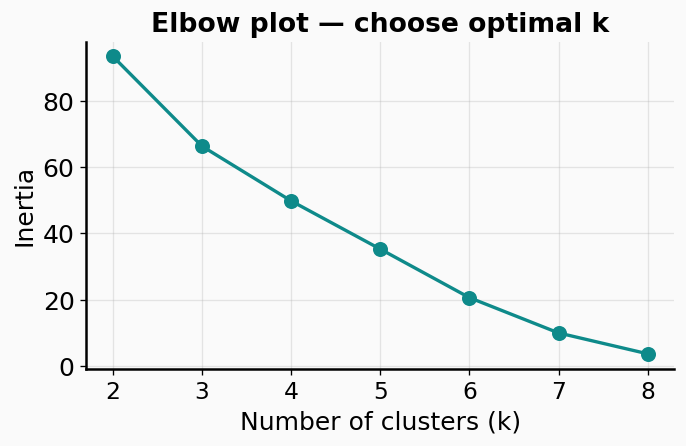

In [ ]:
# ── PCA ─────────────────────────────────────────────────────
n_comp = min(6, X_scaled.shape[1], X_scaled.shape[0]-1)
pca    = PCA(n_components=n_comp, random_state=SEED)
X_pca  = pca.fit_transform(X_scaled)

print("PCA explained variance:")
cumvar = 0
for i, v in enumerate(pca.explained_variance_ratio_):
    cumvar += v
    print(f"  PC{i+1}: {v*100:.1f}%  (cumulative: {cumvar*100:.1f}%)")

# ── Elbow plot ────────────────────────────────────────────────
inertias, k_range = [], range(2, min(9, len(df_clust)))
for k in k_range:
    km = KMeans(n_clusters=k, random_state=SEED, n_init=10)
    km.fit(X_scaled)
    inertias.append(km.inertia_)

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(list(k_range), inertias, 'o-', color=PALETTE['teal'], lw=2, markersize=8)
ax.set_xlabel('Number of clusters (k)'); ax.set_ylabel('Inertia')
ax.set_title('Elbow plot — choose optimal k', fontweight='bold')
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(OUTDIR_UNSUP,'Fig_elbow.png'), dpi=300)
plt.show()


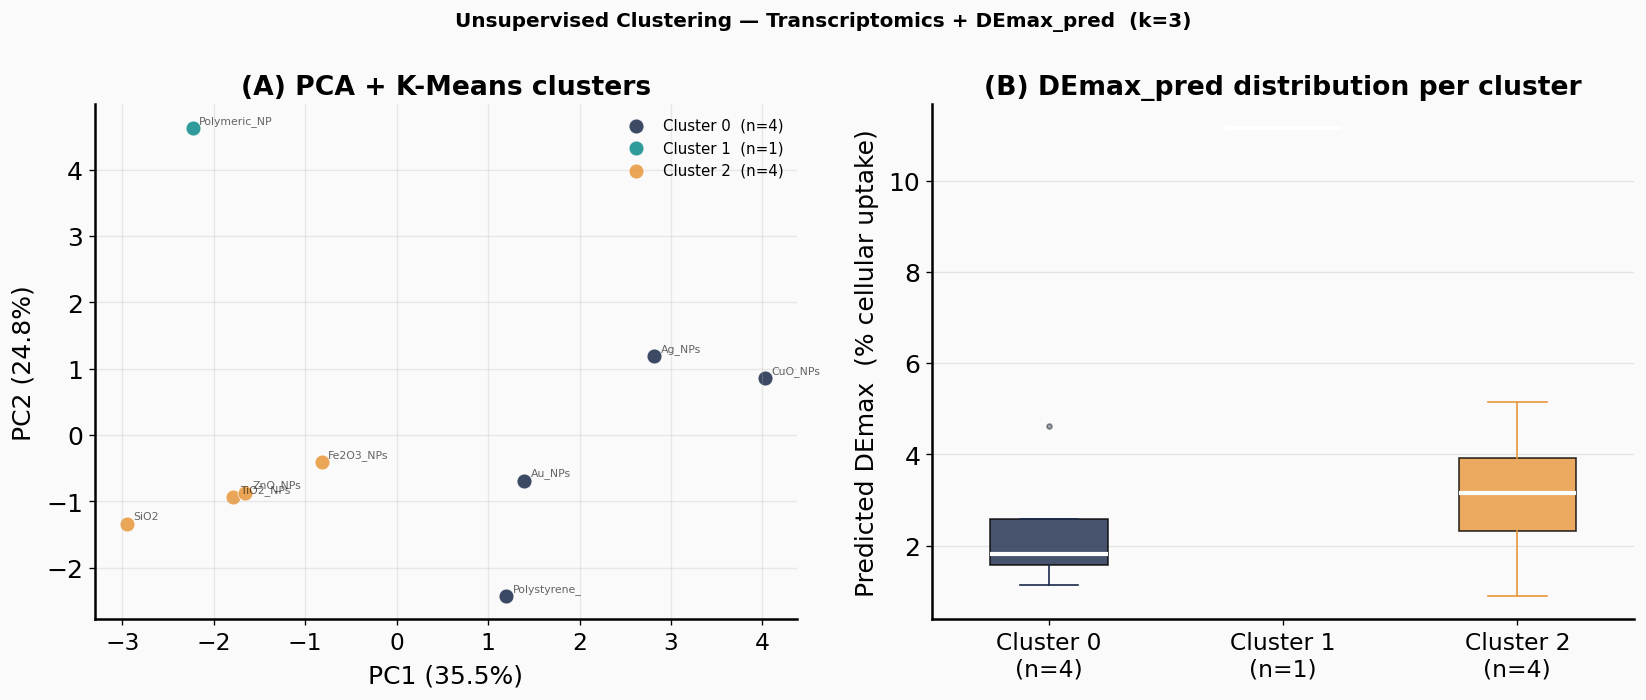

Saved: Fig_PCA_kmeans.png


In [ ]:
# ── K-Means + PCA scatter ─────────────────────────────────────
N_CLUSTERS = 3   # ← adjust based on elbow plot

km = KMeans(n_clusters=N_CLUSTERS, random_state=SEED, n_init=10)
cluster_labels = km.fit_predict(X_scaled)
df_clust['cluster'] = cluster_labels

CLUSTER_COLORS = ['#1B2A4A','#0E8A8A','#E8963A','#C0392B','#1E8449']

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle(f'Unsupervised Clustering — Transcriptomics + DEmax_pred  (k={N_CLUSTERS})',
             fontsize=12, fontweight='bold')

# Panel A: PCA scatter
ax = axes[0]
for k in range(N_CLUSTERS):
    mask = cluster_labels == k
    ax.scatter(X_pca[mask,0], X_pca[mask,1],
               color=CLUSTER_COLORS[k], s=80, alpha=0.85,
               edgecolors='white', linewidths=0.5,
               label=f'Cluster {k}  (n={mask.sum()})')

# Annotate NP names
for i, name in enumerate(df_clust.index):
    ax.annotate(str(name)[:12], (X_pca[i,0], X_pca[i,1]),
                textcoords='offset points', xytext=(4,3),
                fontsize=6.5, alpha=0.6)

ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)", labelpad=6)
ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)", labelpad=6)
ax.set_title('(A) PCA + K-Means clusters', fontweight='bold')
ax.legend(frameon=False, fontsize=9)
ax.grid(alpha=0.25)

# Panel B: DEmax_pred per cluster (boxplot)
ax2 = axes[1]
for k in range(N_CLUSTERS):
    vals = df_clust.loc[df_clust['cluster']==k, 'DEmax_pred'].dropna()
    bp = ax2.boxplot([vals], positions=[k], widths=0.5, patch_artist=True,
                     boxprops=dict(facecolor=CLUSTER_COLORS[k], alpha=0.8),
                     medianprops=dict(color='white', linewidth=2.5),
                     whiskerprops=dict(color=CLUSTER_COLORS[k]),
                     capprops=dict(color=CLUSTER_COLORS[k]),
                     flierprops=dict(marker='o', markersize=3, alpha=0.4,
                                     markerfacecolor=CLUSTER_COLORS[k]))
ax2.set_xticks(range(N_CLUSTERS))
ax2.set_xticklabels([f'Cluster {k}\n(n={( cluster_labels==k).sum()})'
                     for k in range(N_CLUSTERS)])
ax2.set_ylabel('Predicted DEmax  (% cellular uptake)', labelpad=6)
ax2.set_title('(B) DEmax_pred distribution per cluster', fontweight='bold')
ax2.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(OUTDIR_UNSUP,'Fig_PCA_kmeans.png'), dpi=300)
plt.show()
print(f"Saved: Fig_PCA_kmeans.png")


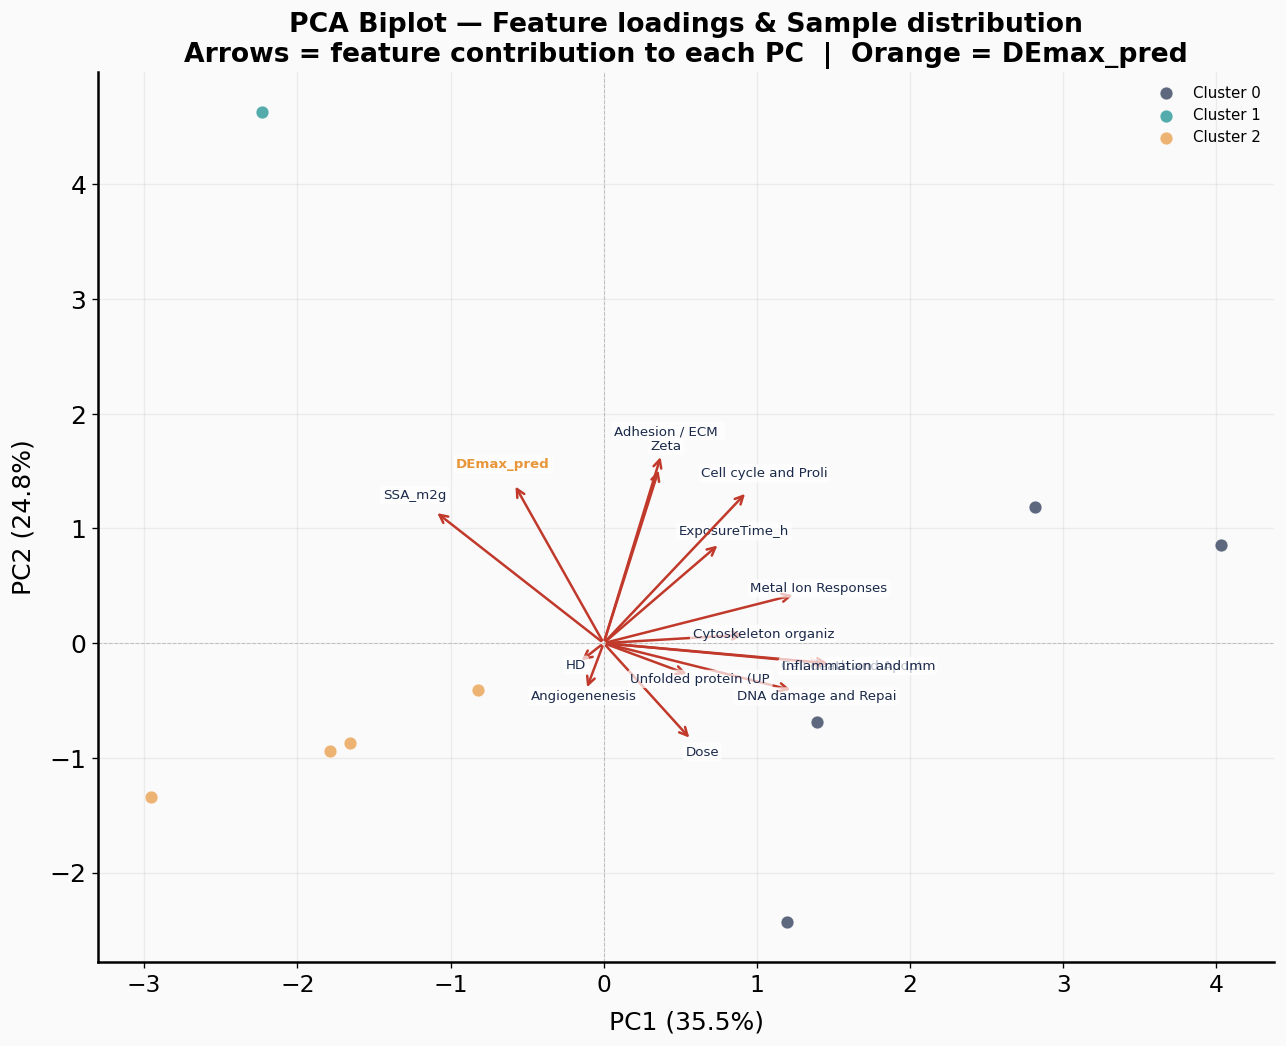

Saved: Fig_PCA_biplot.png


In [ ]:
# ── PCA Biplot: feature loadings + samples ────────────────────
fig, ax = plt.subplots(figsize=(11, 9))

# Scatter samples coloured by cluster
for k in range(N_CLUSTERS):
    mask = cluster_labels == k
    ax.scatter(X_pca[mask,0], X_pca[mask,1],
               color=CLUSTER_COLORS[k], s=60, alpha=0.7,
               edgecolors='white', linewidths=0.5,
               label=f'Cluster {k}', zorder=3)

# Draw loading arrows
loadings  = pca.components_.T[:, :2]
feat_names = df_clust.columns.drop('cluster')
scale     = 3.5  # scale arrows to visible range

for i, (fname, (lx, ly)) in enumerate(zip(feat_names, loadings)):
    ax.annotate('', xy=(lx*scale, ly*scale), xytext=(0,0),
                arrowprops=dict(arrowstyle='->', color=PALETTE['red'],
                                lw=1.5, mutation_scale=12))
    offset_x = lx*scale*1.12
    offset_y = ly*scale*1.12
    color = PALETTE['amber'] if 'DEmax' in str(fname) else PALETTE['navy']
    weight = 'bold' if 'DEmax' in str(fname) else 'normal'
    ax.text(offset_x, offset_y, str(fname)[:20],
            fontsize=8, color=color, fontweight=weight,
            ha='center', va='center',
            bbox=dict(boxstyle='round,pad=0.2', fc='white', alpha=0.7, ec='none'))

ax.axhline(0, color='grey', lw=0.6, ls='--', alpha=0.4)
ax.axvline(0, color='grey', lw=0.6, ls='--', alpha=0.4)
ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)", labelpad=8)
ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)", labelpad=8)
ax.set_title('PCA Biplot — Feature loadings & Sample distribution\n'
             'Arrows = feature contribution to each PC  |  Orange = DEmax_pred',
             fontweight='bold')
ax.legend(frameon=False, fontsize=9)
ax.grid(alpha=0.2)

plt.tight_layout()
plt.savefig(os.path.join(OUTDIR_UNSUP,'Fig_PCA_biplot.png'), dpi=300)
plt.show()
print("Saved: Fig_PCA_biplot.png")


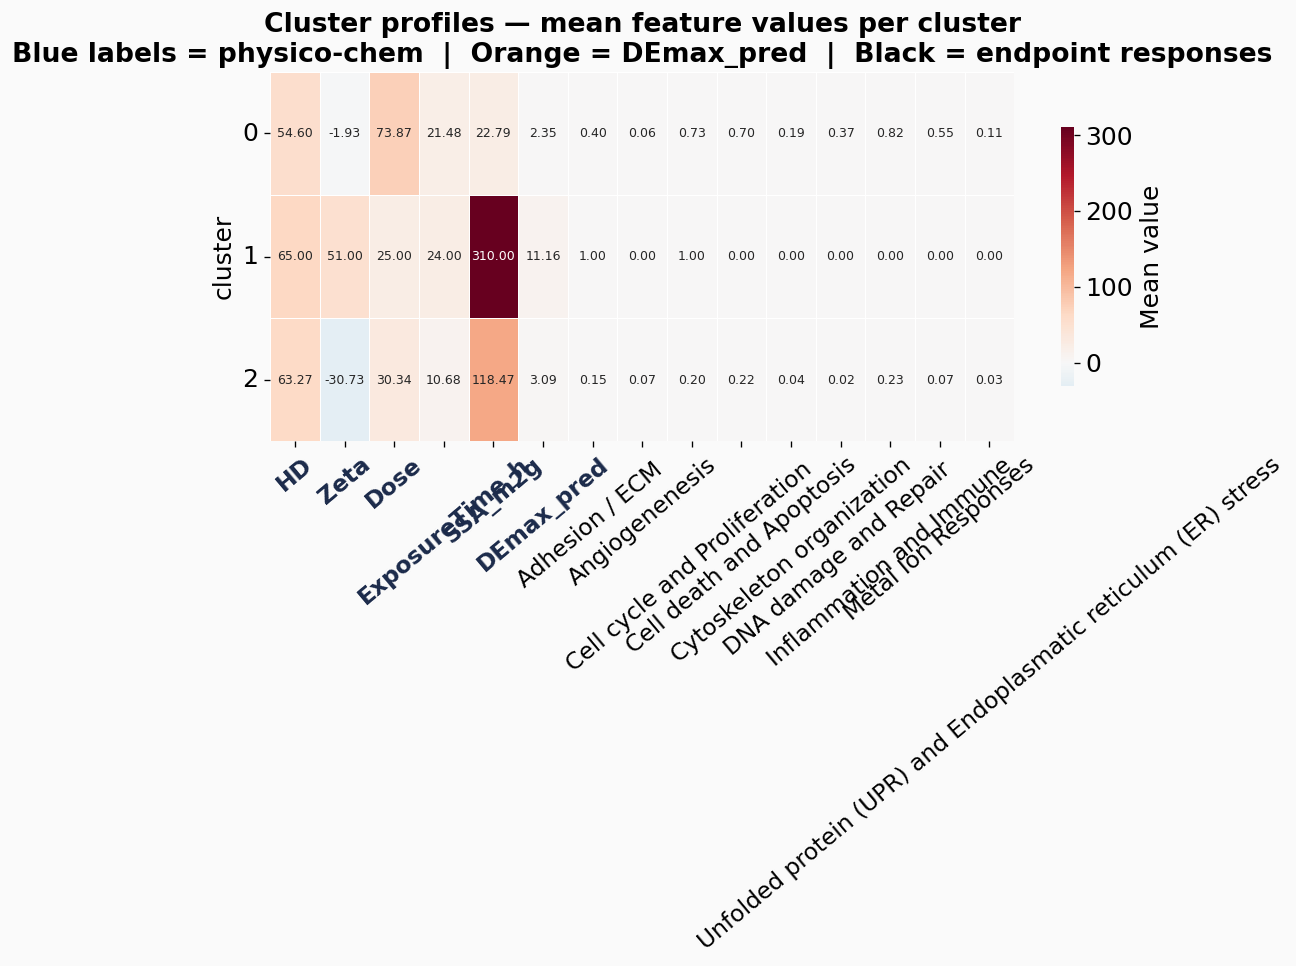

In [ ]:
# ── Cluster profile heatmap ────────────────────────────────────
cluster_profile = df_clust.groupby('cluster').mean()

# Sort columns: physico-chem first, then endpoints
phys_cols = [c for c in available if c in cluster_profile.columns]
ep_cols   = [c for c in cluster_profile.columns if c not in phys_cols + ['cluster']]
cluster_profile = cluster_profile[phys_cols + ep_cols]

fig, ax = plt.subplots(figsize=(max(10, len(cluster_profile.columns)*0.55), 4))
sns.heatmap(cluster_profile, ax=ax, cmap='RdBu_r', center=0,
            annot=True, fmt='.2f', linewidths=0.3, linecolor='white',
            annot_kws={'size':7.5},
            cbar_kws={'label':'Mean value','shrink':0.7})

# Color column labels: physico-chem blue, endpoints orange
for label in ax.get_xticklabels():
    txt = label.get_text()
    if txt in phys_cols:
        label.set_color(PALETTE['navy'])
        label.set_fontweight('bold')
    elif 'DEmax' in txt:
        label.set_color(PALETTE['amber'])
        label.set_fontweight('bold')

ax.set_title('Cluster profiles — mean feature values per cluster\n'
             'Blue labels = physico-chem  |  Orange = DEmax_pred  |  '
             'Black = endpoint responses',
             fontweight='bold')
ax.set_xlabel('')
ax.tick_params(axis='x', rotation=40)
ax.tick_params(axis='y', rotation=0)

plt.tight_layout()
plt.savefig(os.path.join(OUTDIR_UNSUP,'Fig_cluster_profiles.png'), dpi=300)
plt.show()


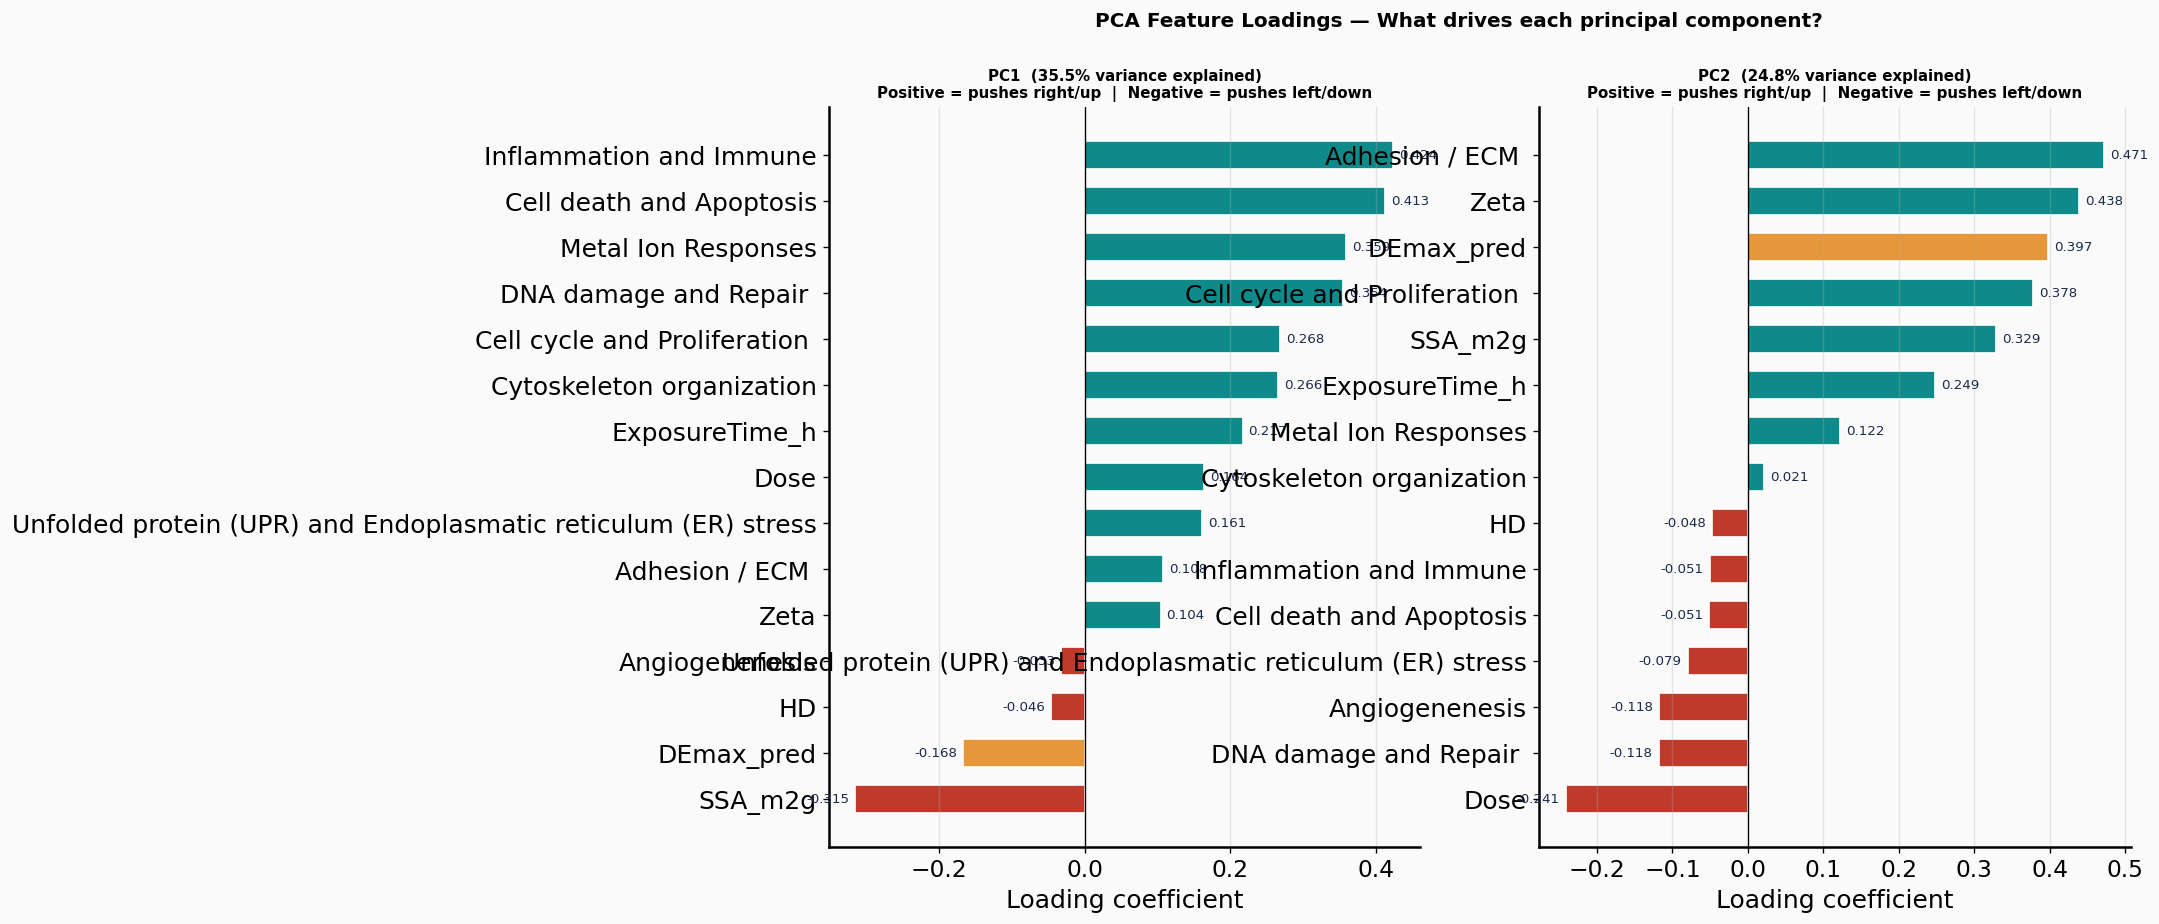


All unsupervised figures saved to: unsupervised_learning
Saved: cluster_assignments.csv, cluster_profiles.csv


In [ ]:
# ── PCA loadings bar: which features drive PC1 and PC2? ───────
loadings_df = pd.DataFrame(
    pca.components_[:2].T,
    index=feat_names,
    columns=['PC1','PC2']
).sort_values('PC1', ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(14, max(5, len(loadings_df)*0.4+2)))
fig.suptitle('PCA Feature Loadings — What drives each principal component?',
             fontsize=12, fontweight='bold')

for ax, pc in zip(axes, ['PC1','PC2']):
    df_pc = loadings_df.sort_values(pc, ascending=True)
    vals  = df_pc[pc].values
    colors = [PALETTE['amber'] if 'DEmax' in str(f) else
              PALETTE['teal']  if v > 0 else PALETTE['red']
              for f,v in zip(df_pc.index, vals)]
    bars = ax.barh(df_pc.index, vals, color=colors, edgecolor='white', height=0.6)
    ax.axvline(0, color='black', lw=0.8)
    for bar,v in zip(bars, vals):
        xpos = v + (0.008 if v >= 0 else -0.008)
        ax.text(xpos, bar.get_y()+bar.get_height()/2, f'{v:.3f}',
                va='center', ha='left' if v>=0 else 'right',
                fontsize=8, color=PALETTE['navy'])
    var_exp = pca.explained_variance_ratio_[['PC1','PC2'].index(pc)]*100
    ax.set_title(f'{pc}  ({var_exp:.1f}% variance explained)\n'
                 'Positive = pushes right/up  |  Negative = pushes left/down',
                 fontweight='bold', fontsize=9)
    ax.set_xlabel('Loading coefficient')
    ax.grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(OUTDIR_UNSUP,'Fig_PCA_loadings.png'), dpi=300)
plt.show()
print(f"\nAll unsupervised figures saved to: {OUTDIR_UNSUP}")

df_clust.to_csv(os.path.join(OUTDIR_UNSUP,'cluster_assignments.csv'))
cluster_profile.to_csv(os.path.join(OUTDIR_UNSUP,'cluster_profiles.csv'))
print("Saved: cluster_assignments.csv, cluster_profiles.csv")


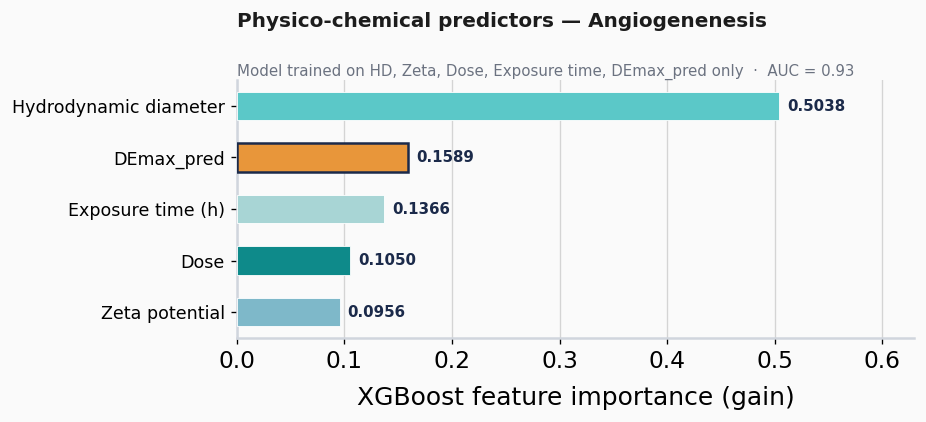

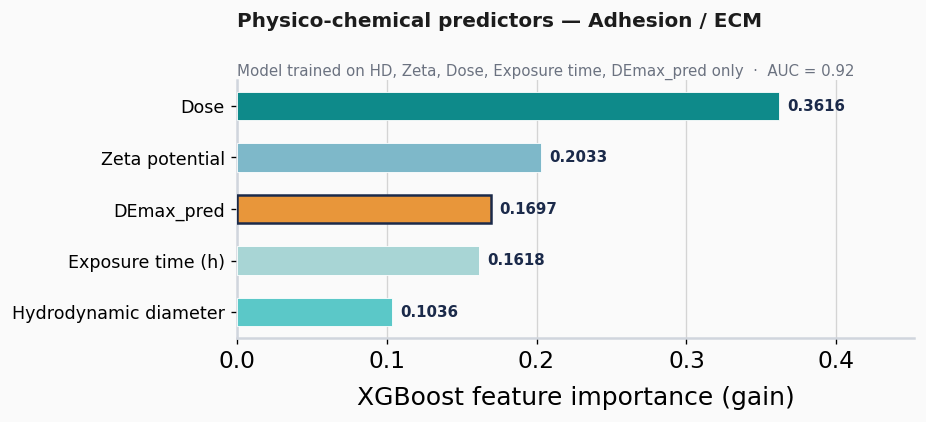

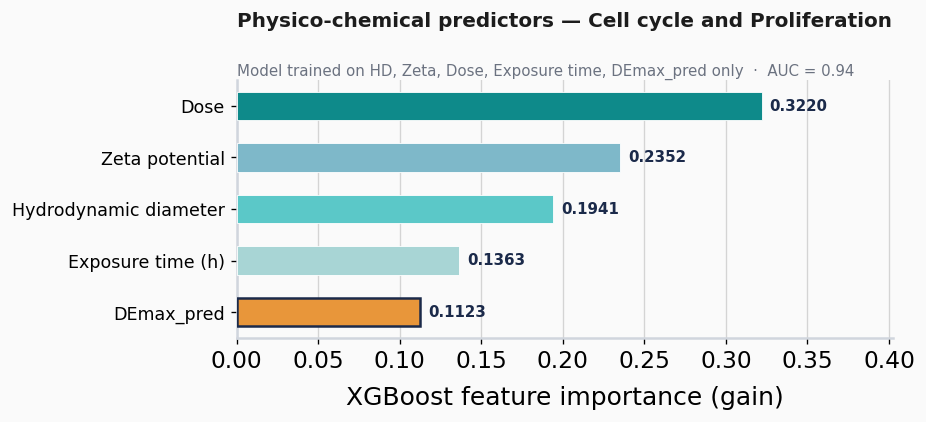

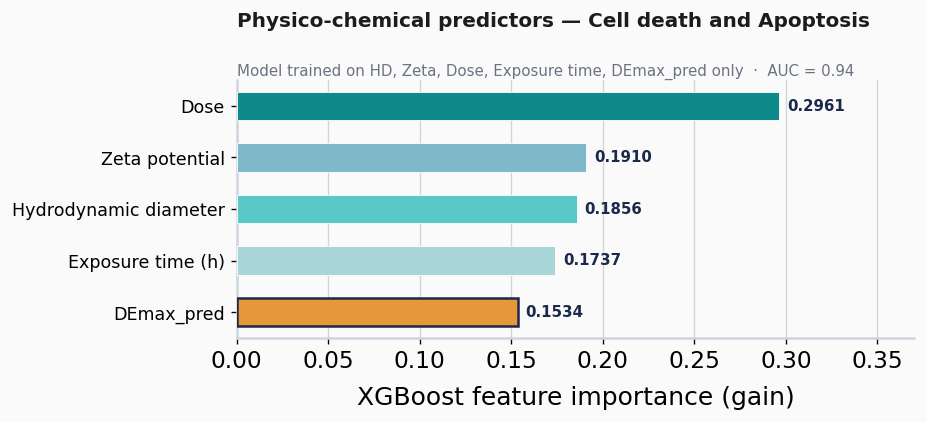

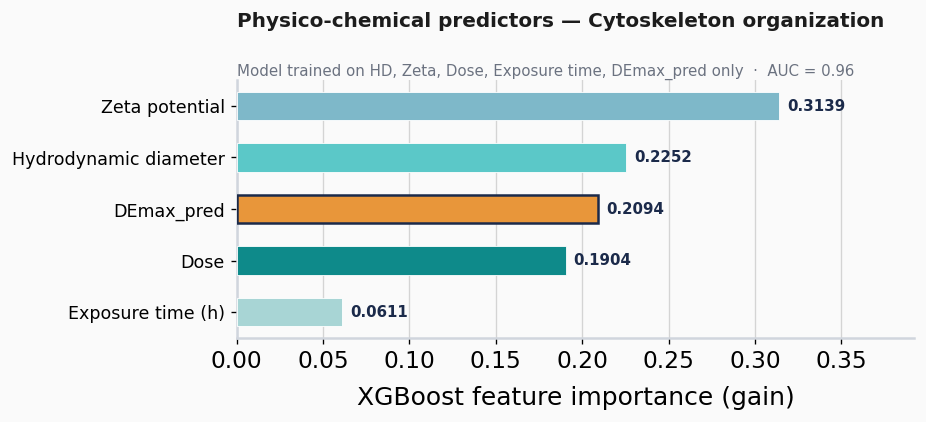

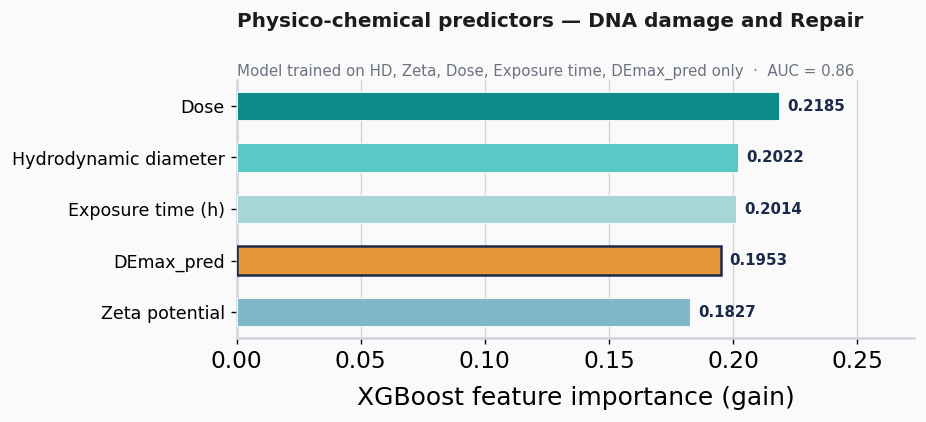

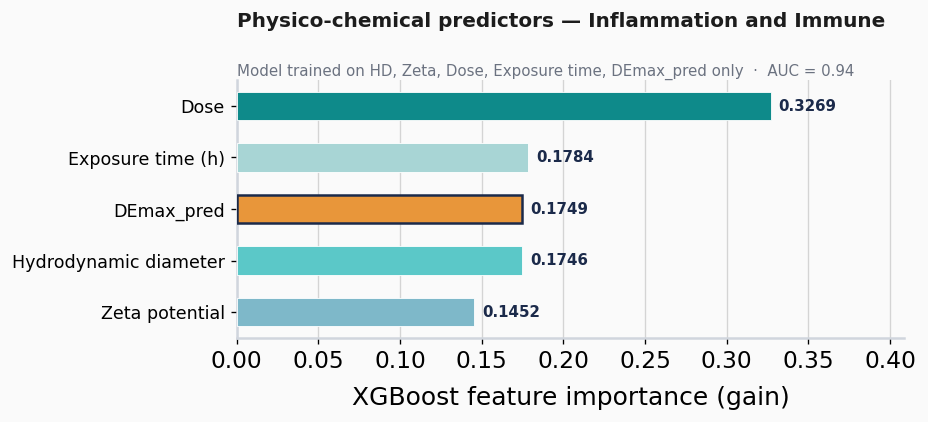

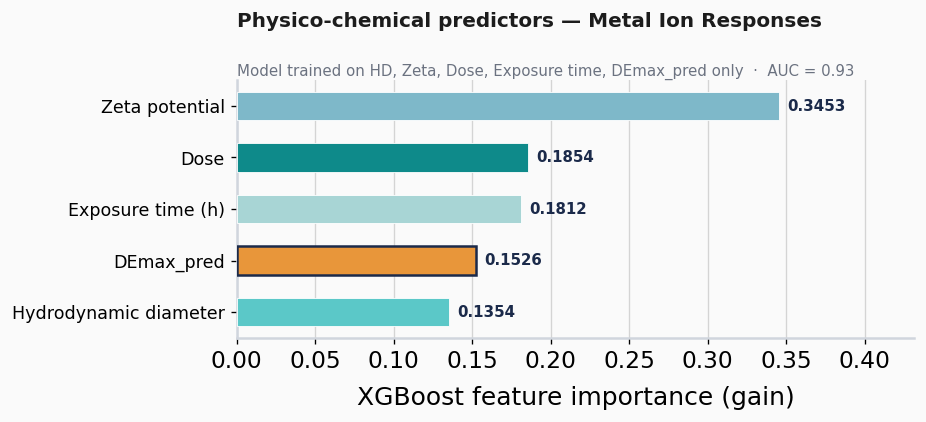

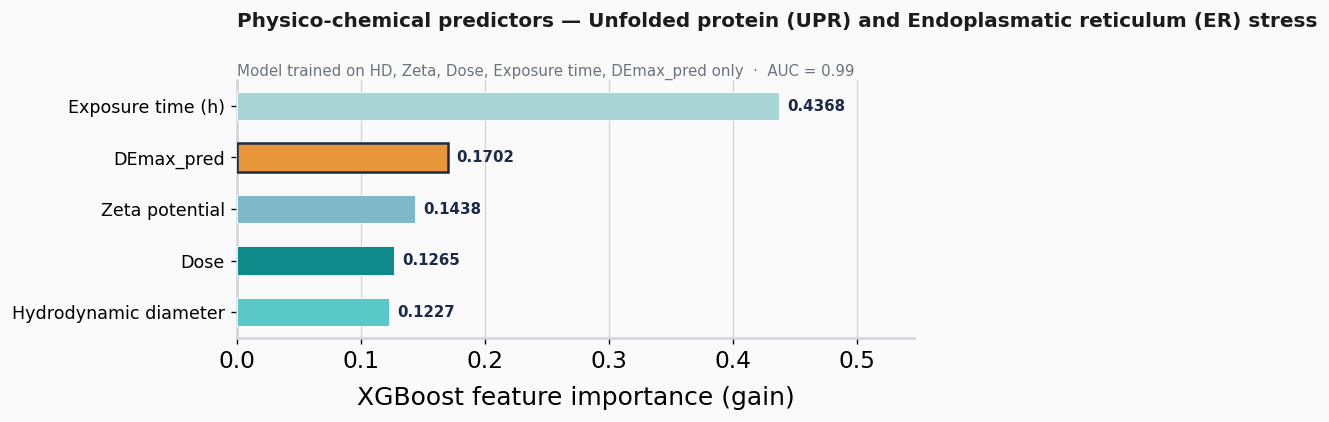

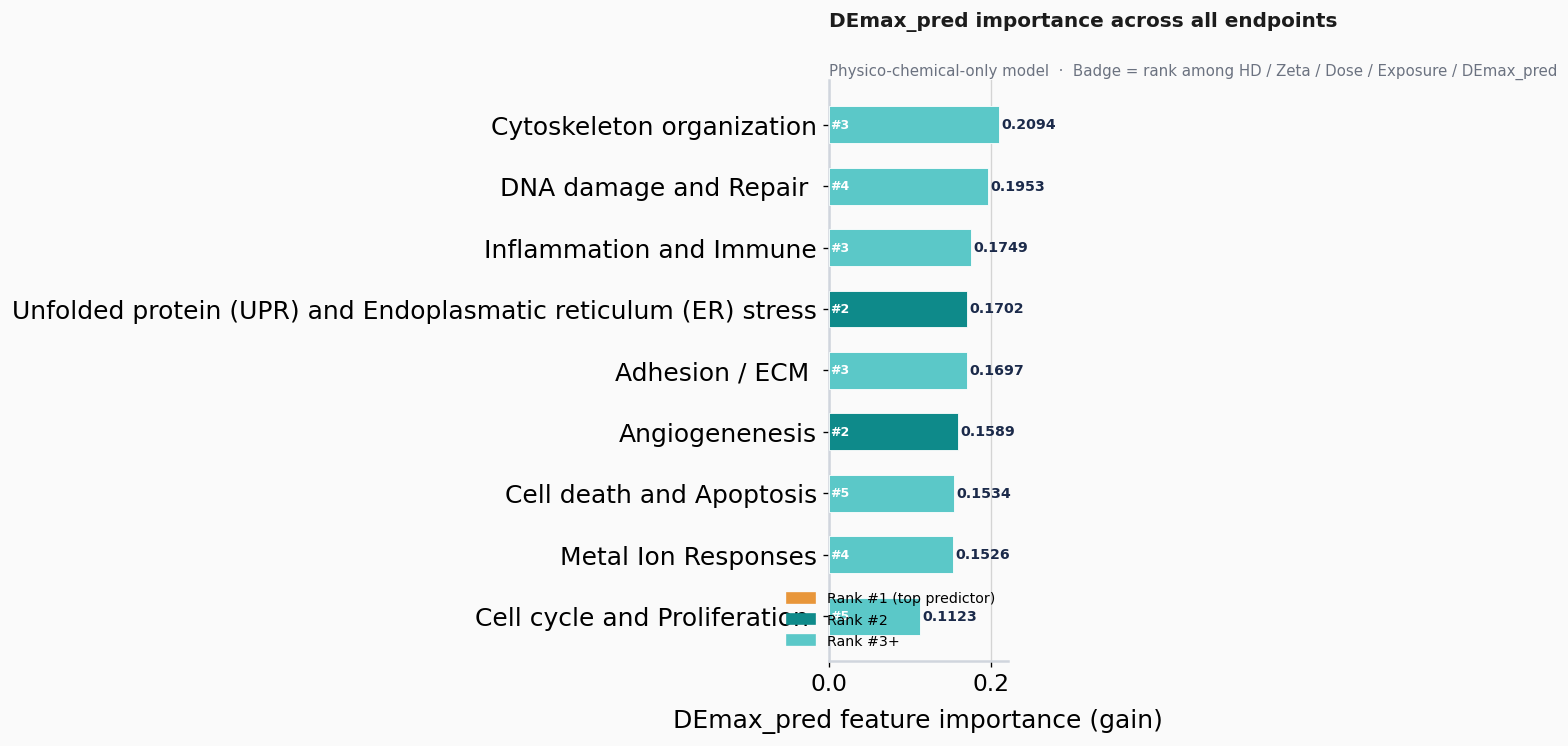

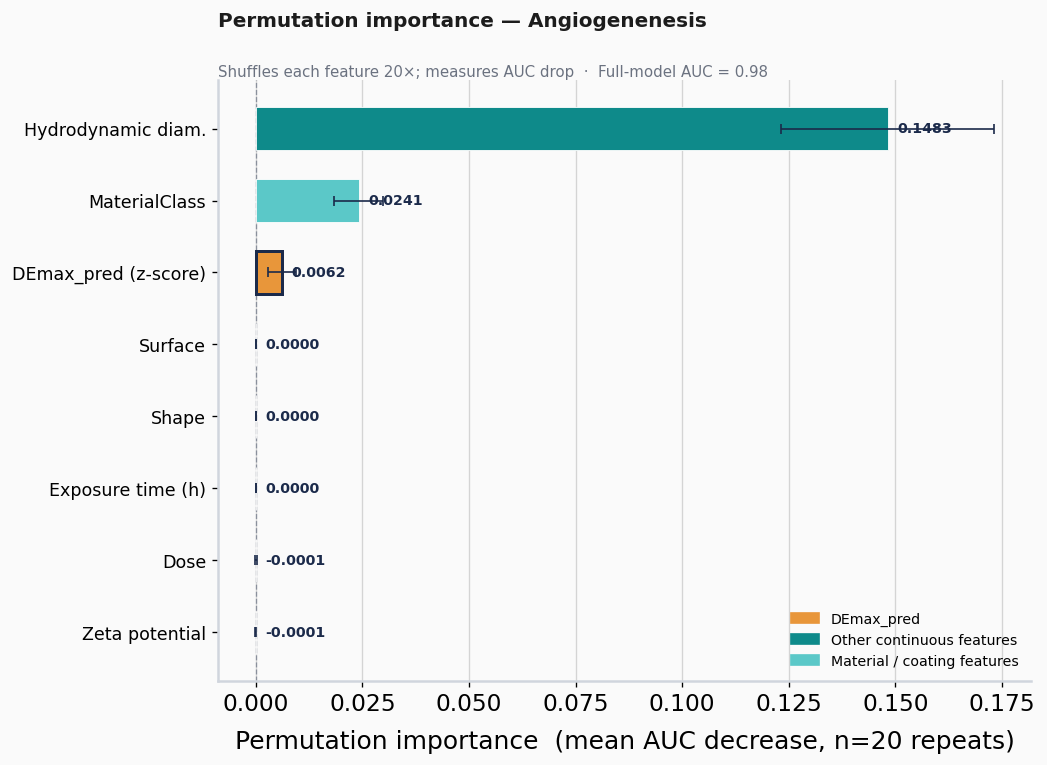

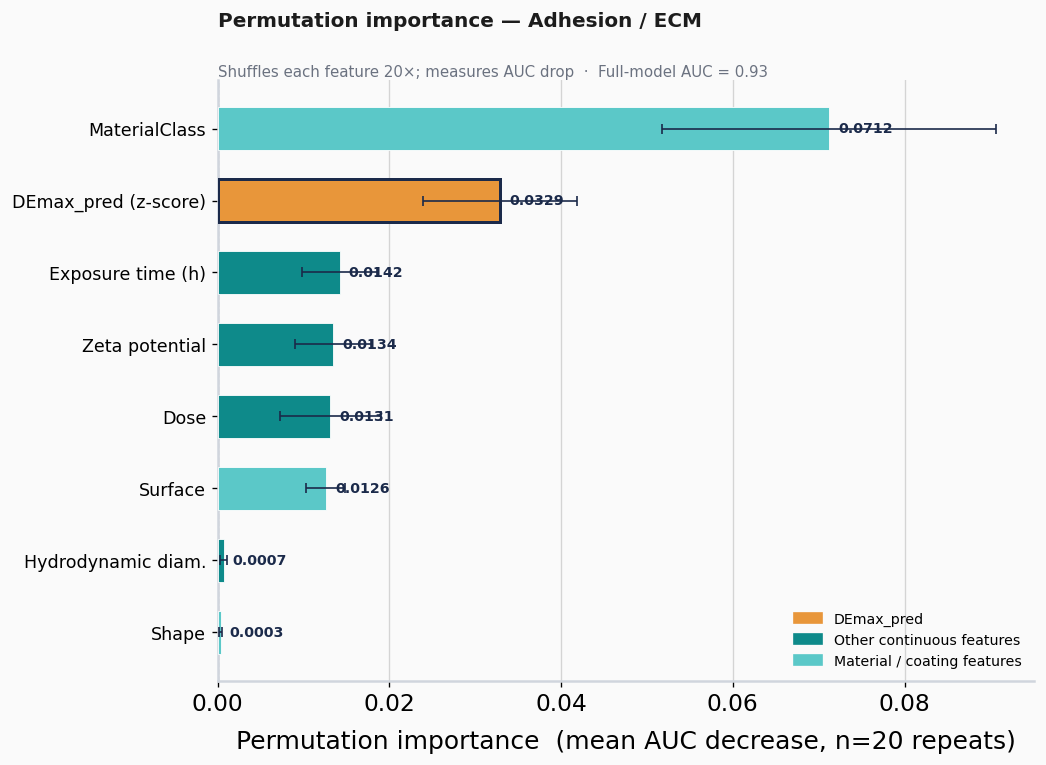

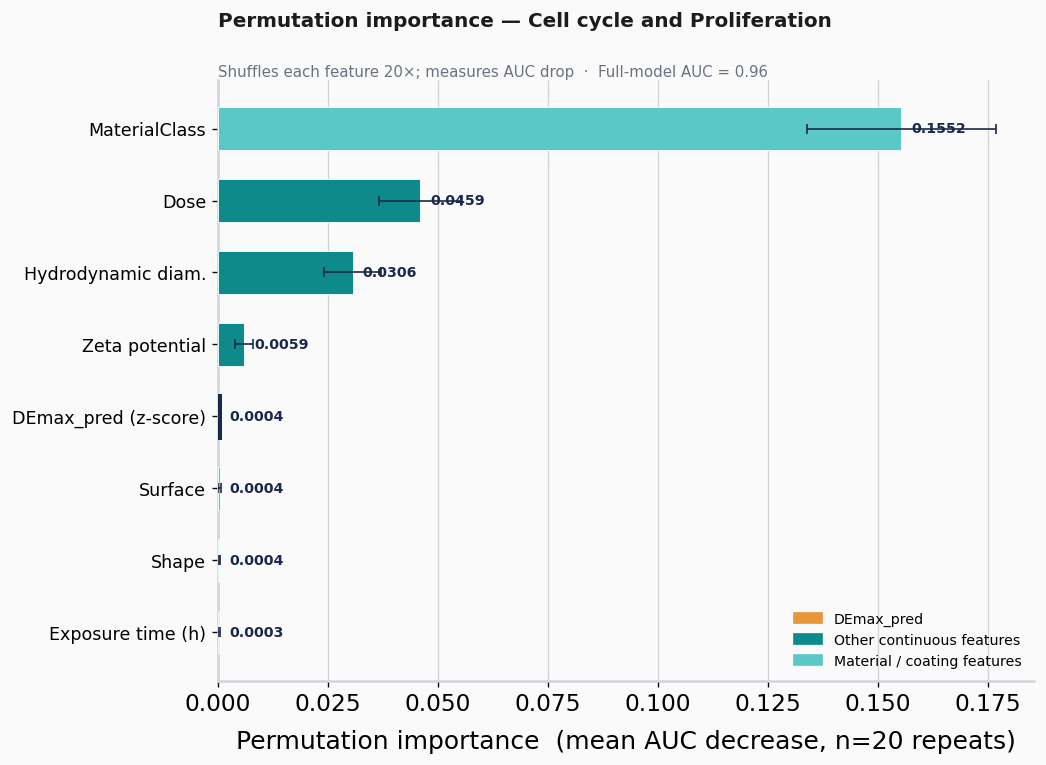

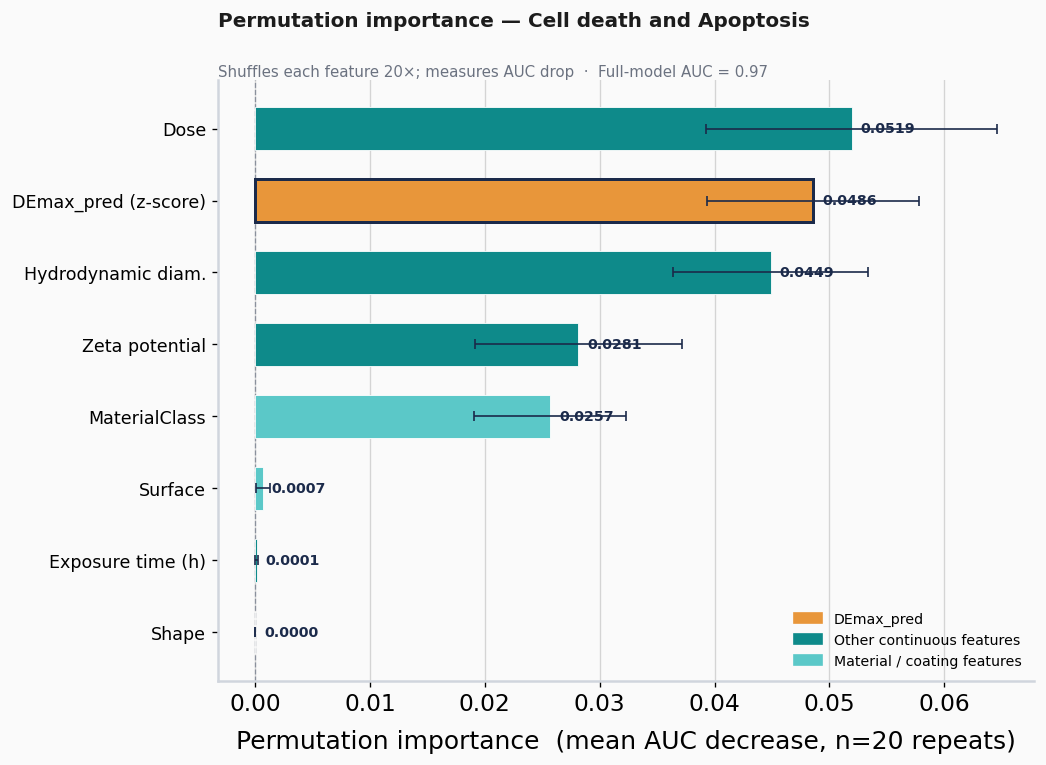

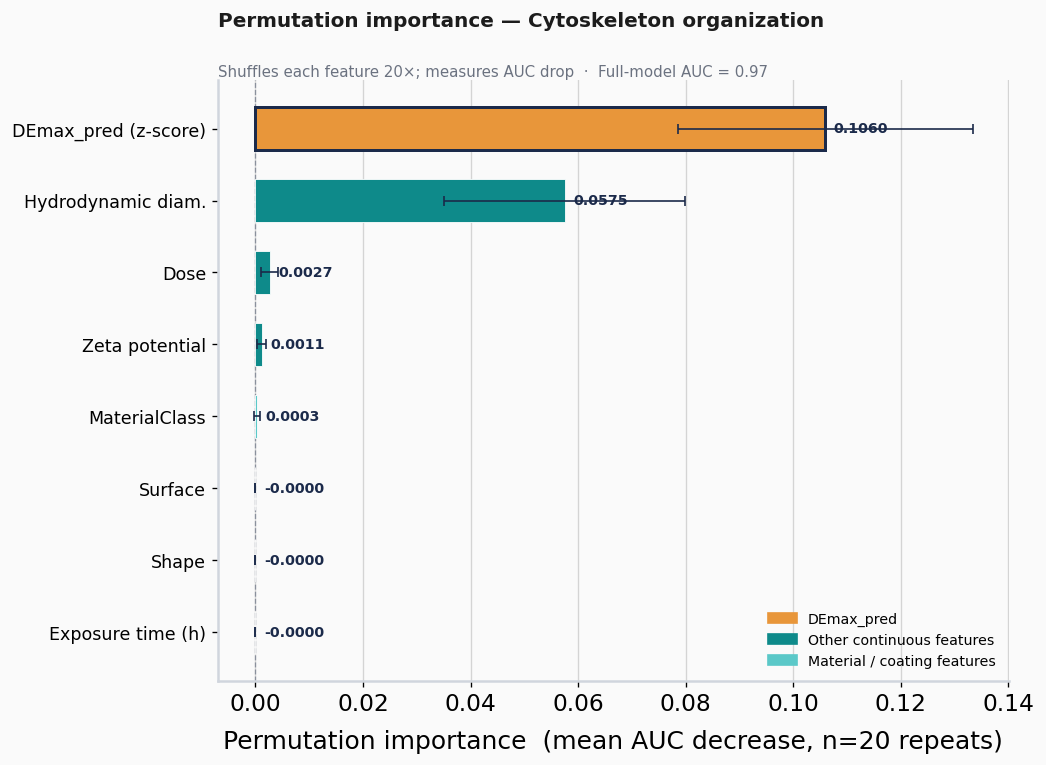

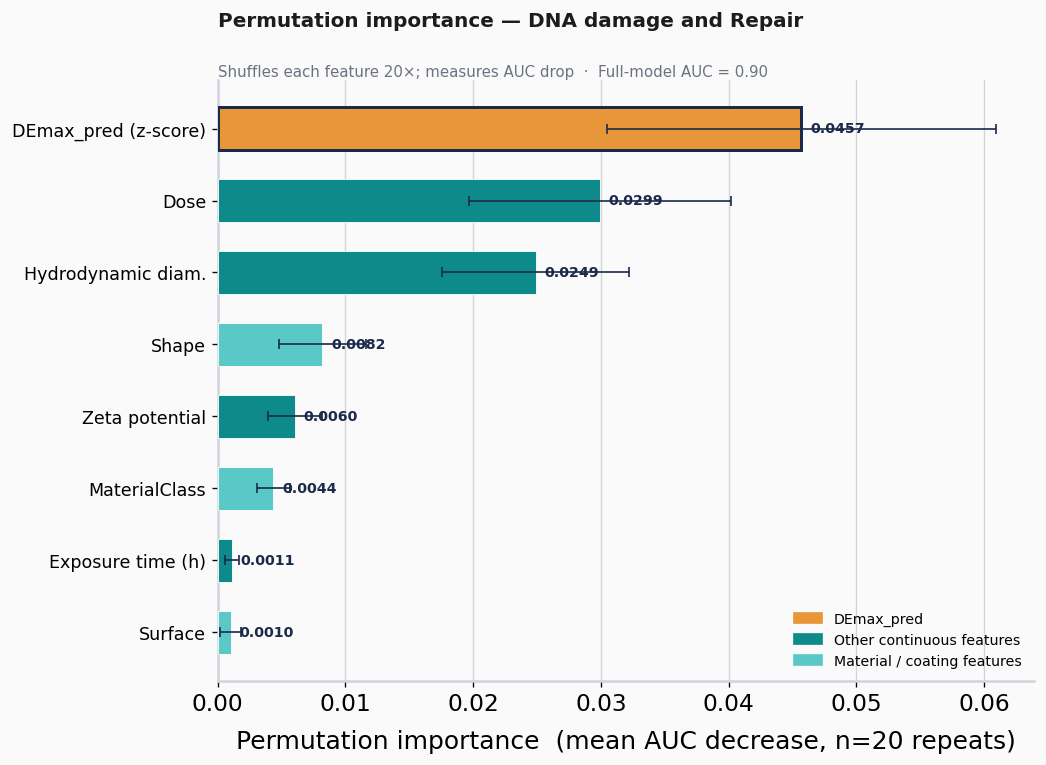

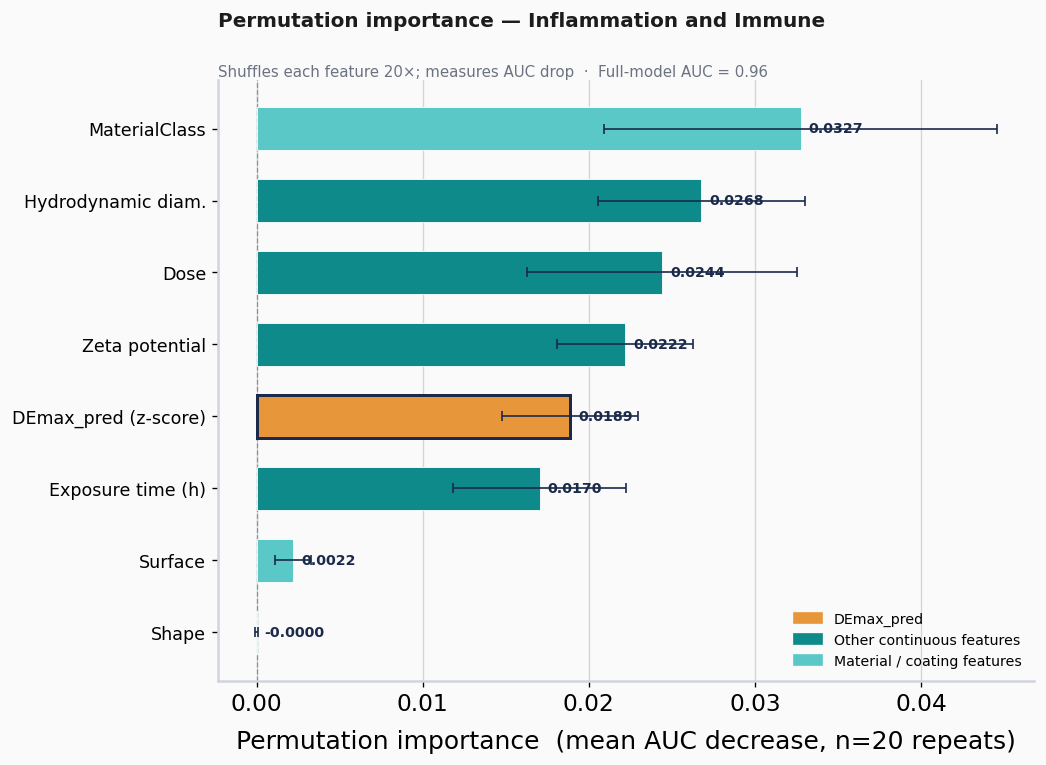

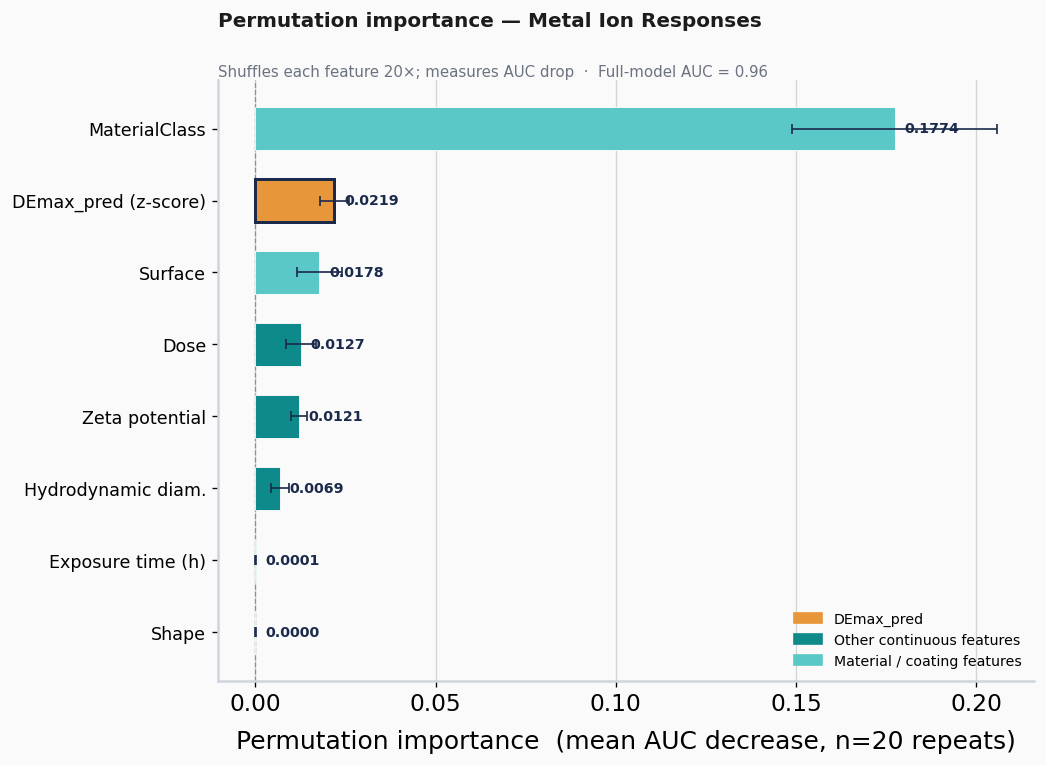

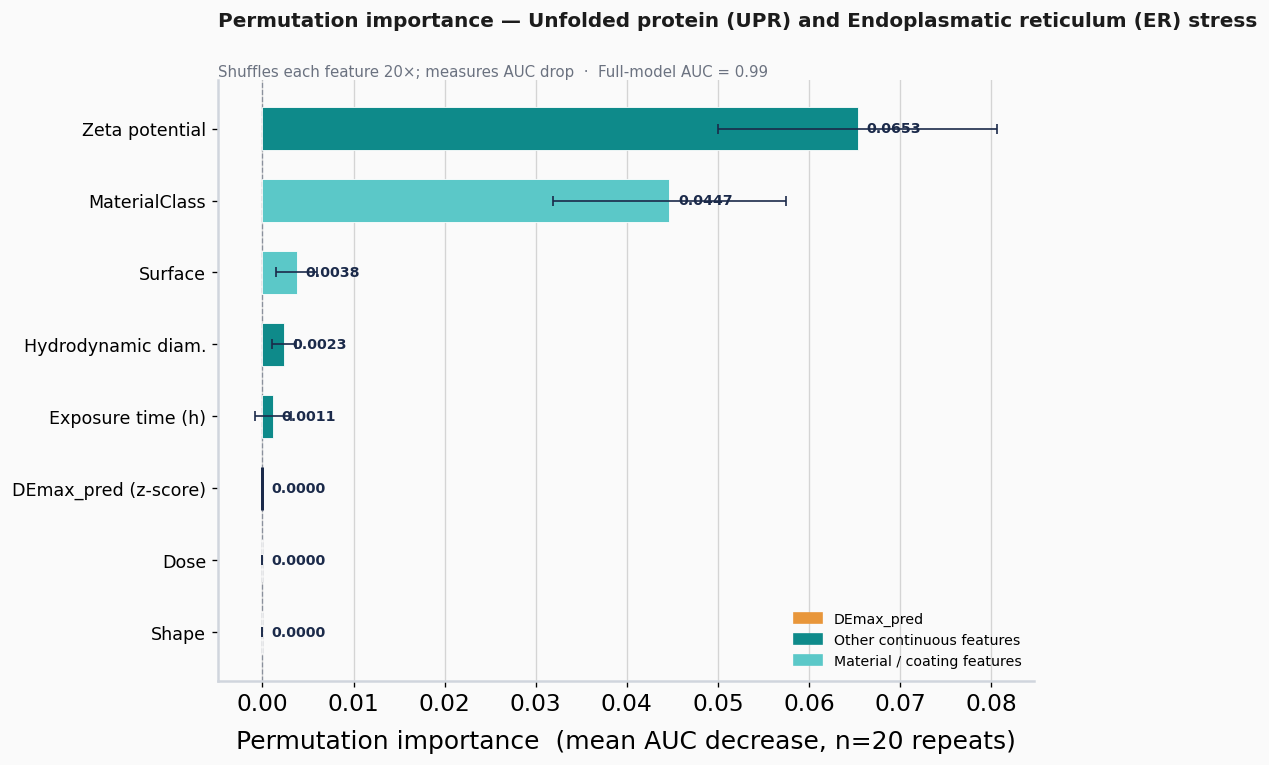


DEmax_pred is not the #1 gain-based feature in any endpoint.
→ Use Approach A (physico-chemical model) or Approach B/D (permutation / SHAP).


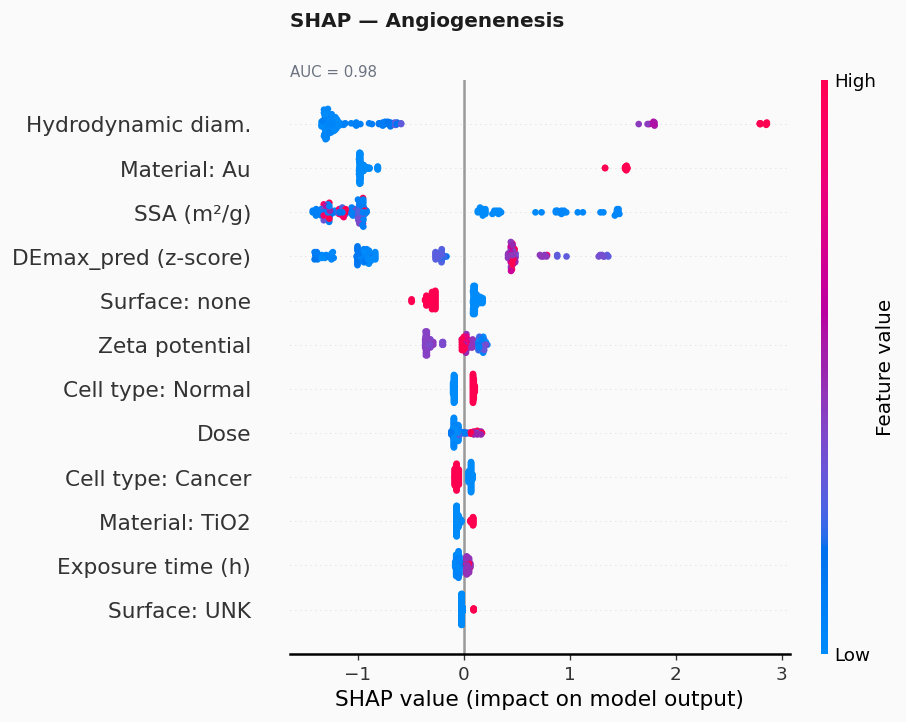

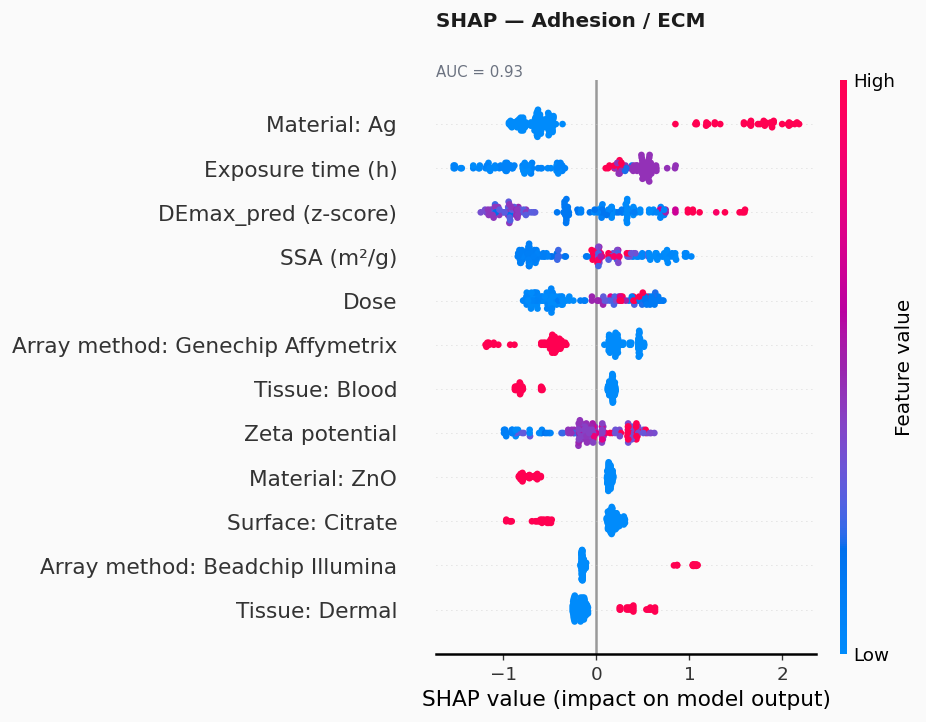

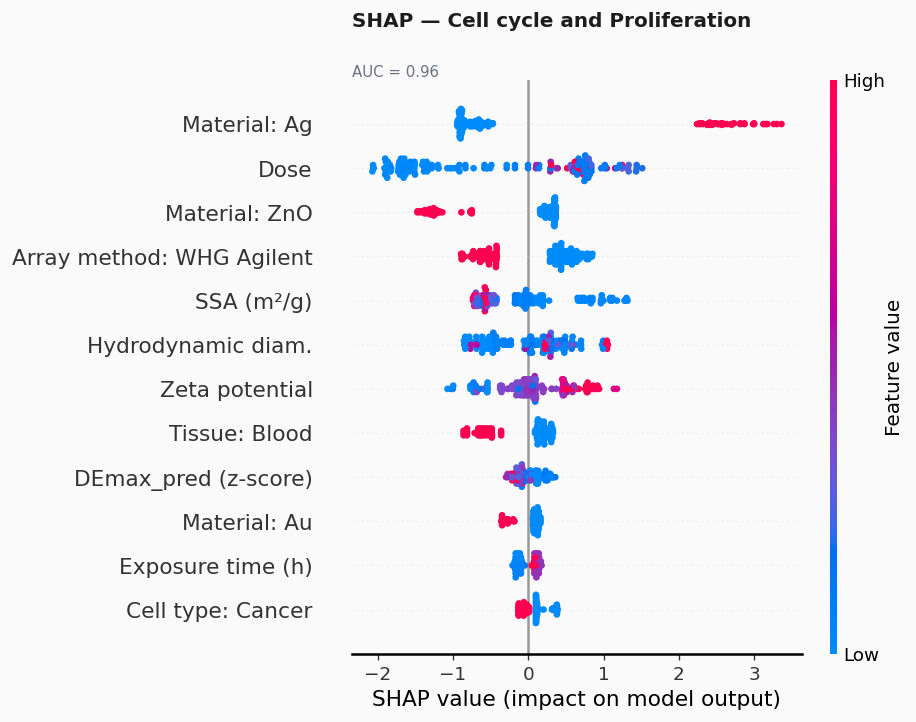

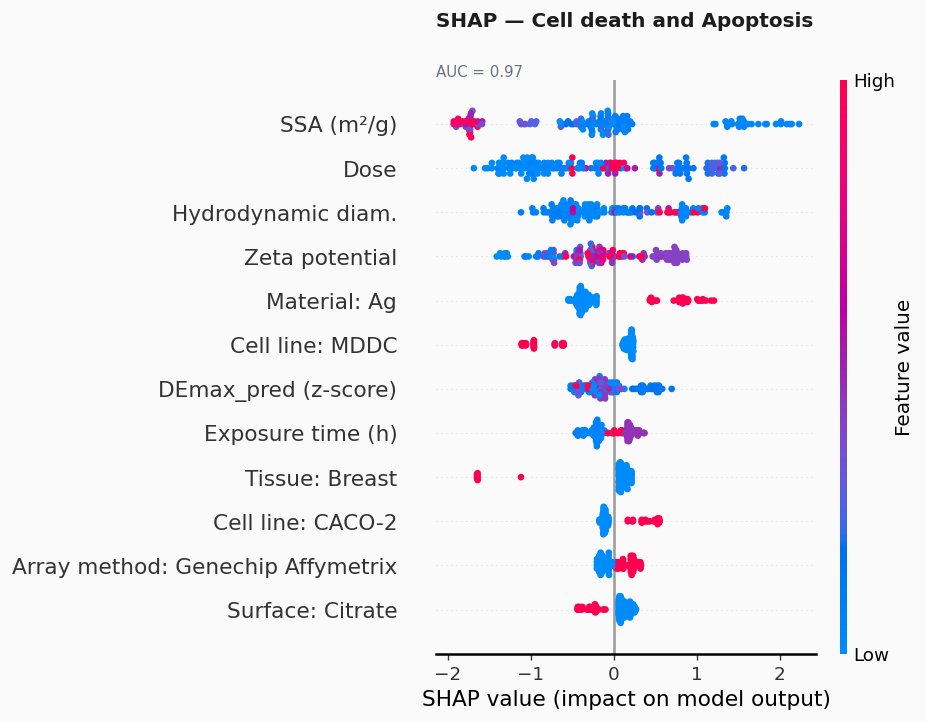

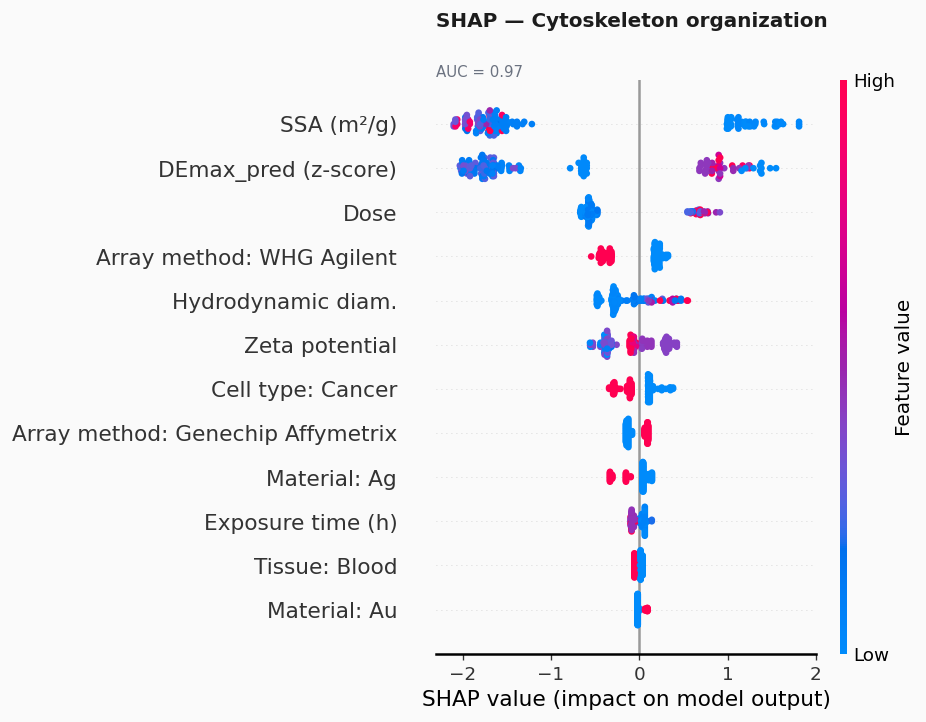

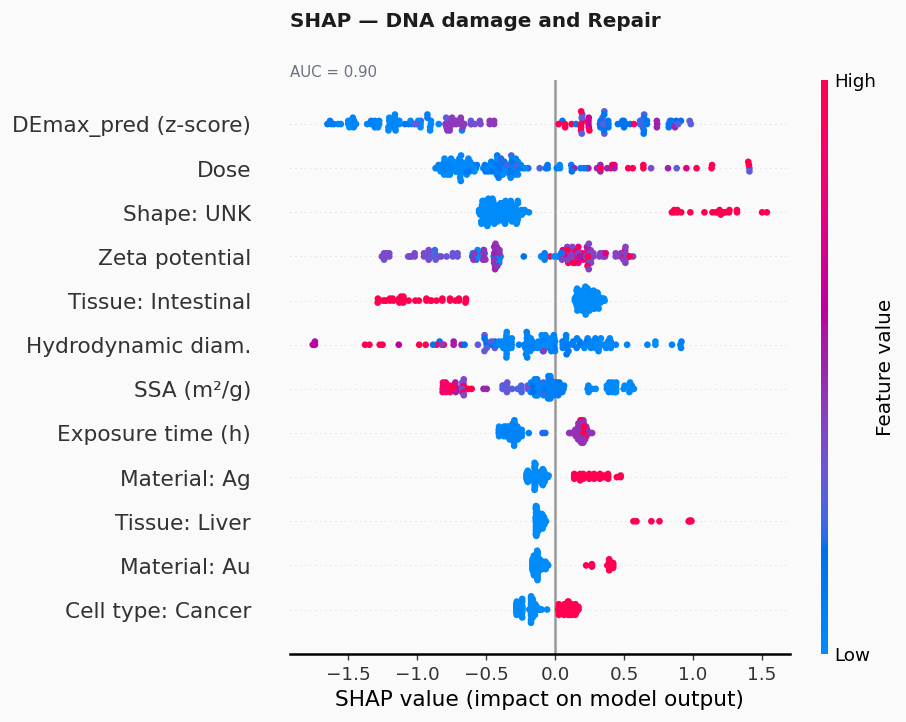

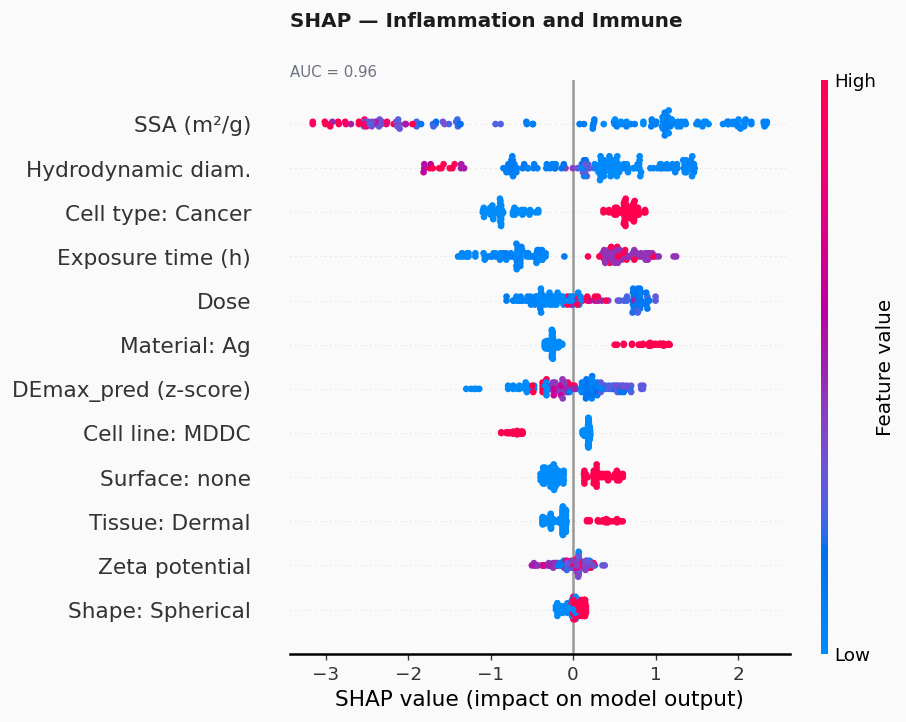

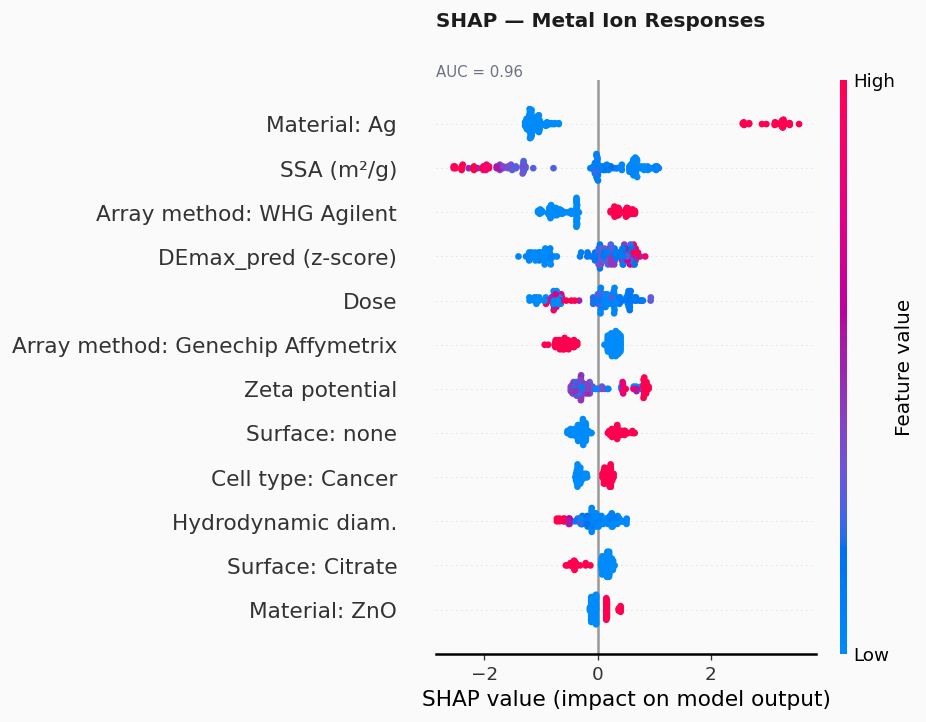

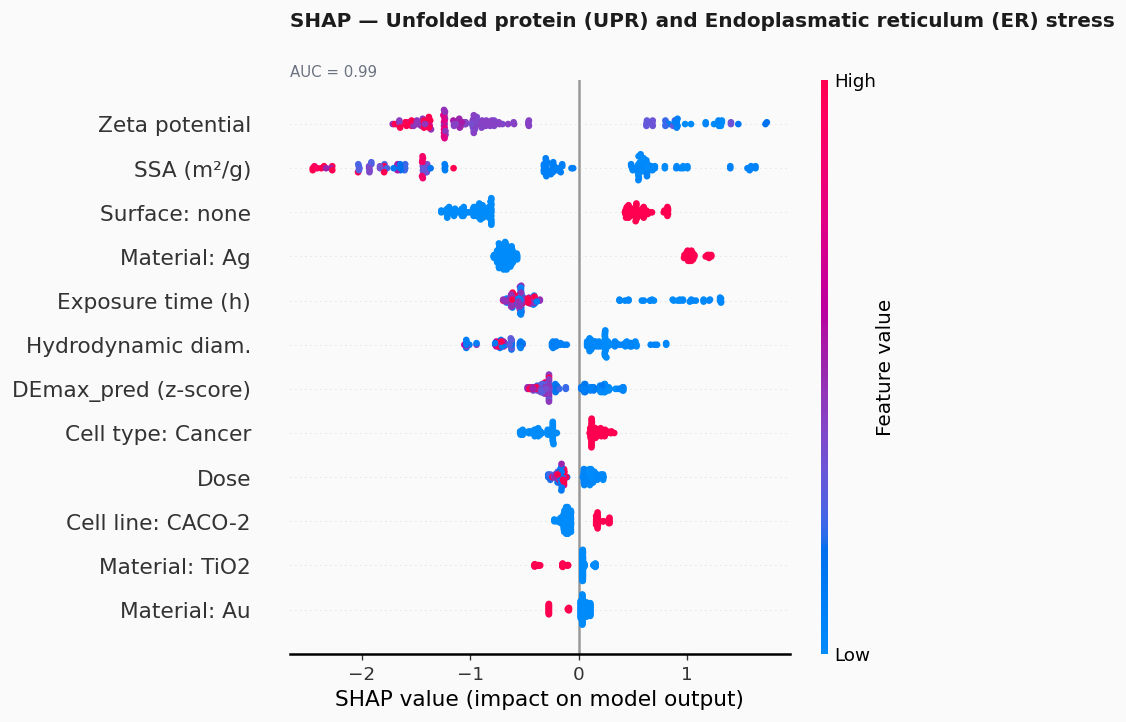

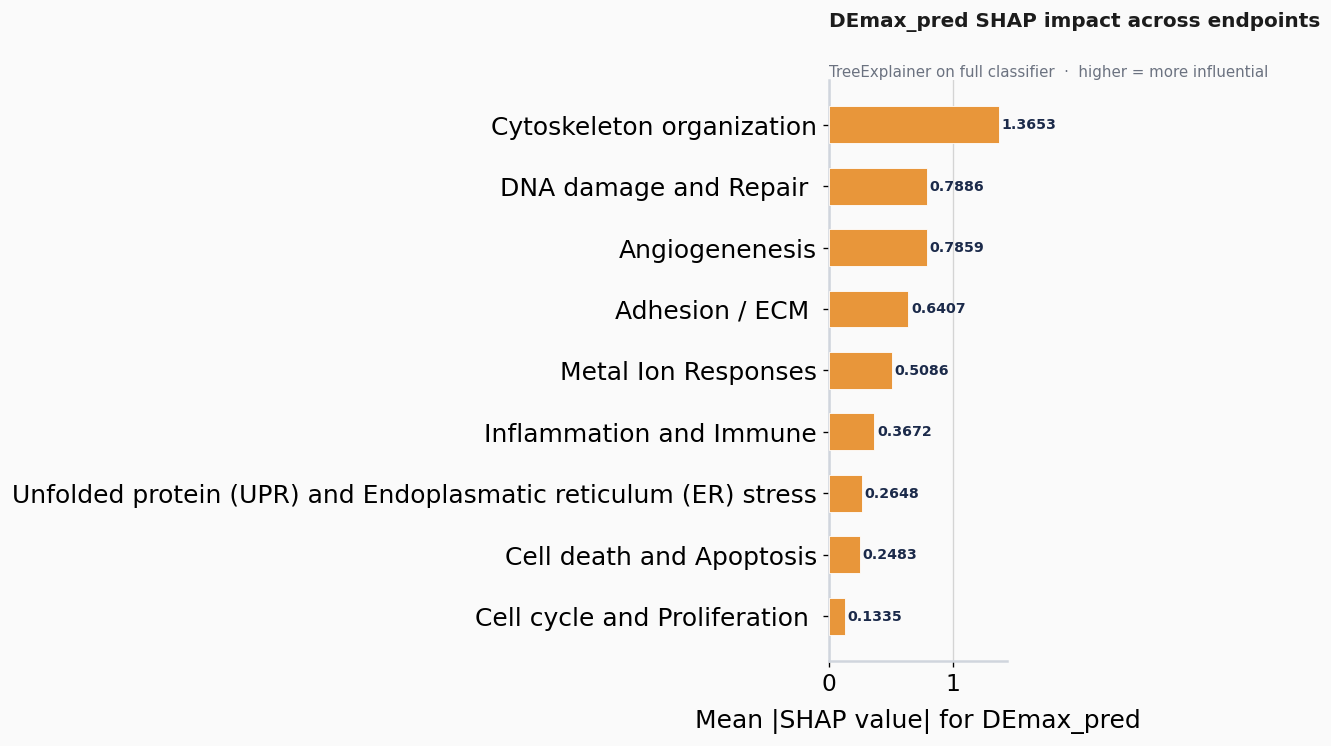


DEmax_pred mean |SHAP| by endpoint:
                                                endpoint_short  mean_abs_shap
                                 Cell cycle and Proliferation        0.133531
                                      Cell death and Apoptosis       0.248299
Unfolded protein (UPR) and Endoplasmatic reticulum (ER) stress       0.264802
                                       Inflammation and Immune       0.367204
                                           Metal Ion Responses       0.508620
                                               Adhesion / ECM        0.640694
                                                Angiogenenesis       0.785877
                                        DNA damage and Repair        0.788626
                                     Cytoskeleton organization       1.365339

All DEmax-focus figures (A/B/C/D) saved to: All_particles_DEmax_variation_figures/endpoint_specific_classifiers/endpoint_specific_classifiers/DEmax_focus


In [ ]:
# =========================================================
# PHYSICO-CHEMICAL / PERMUTATION / SHAP FOCUS ON DEmax_pred
#
# WHY: In the full classifier, one-hot material-identity features
# (MaterialClass_Ag, name_Ag_NPs, ...) dominate gain-based importance
# partly because high-cardinality one-hot features get more splits,
# not necessarily because they're more predictive. This section adds
# three complementary views where DEmax_pred can compete more fairly:
#
# APPROACH A — Physico-chemical-only model
#   Drop all categorical identity features; train on
#   HD, Zeta, Dose, ExposureTime_h, DEmax_pred only.
#
# APPROACH B — Permutation importance on the full model
#   Not inflated by cardinality; shuffles each feature and measures
#   AUC drop, so continuous features compete fairly against one-hot
#   categoricals.
#
# APPROACH C — Endpoints where DEmax_pred is ALREADY #1
#   Pulled directly from importance_tables (already computed in
#   the main classifier training cell).
#
# APPROACH D — SHAP (NEW)
#   Per-endpoint SHAP summary plots on the full model, plus a
#   cross-endpoint bar chart of mean |SHAP| for DEmax_pred specifically.
#   Like permutation importance, SHAP isn't inflated by cardinality,
#   but it additionally shows DIRECTION (does higher DEmax_pred push
#   toward "triggered" or "no-effect"?), which gain/permutation can't.
#
# All uses the SAME variables already in memory from earlier cells:
#   clf_df, perf_df, importance_tables, models_by_endpoint,
#   numeric_features, categorical_features, PALETTE_CLF, FEAT_CMAP,
#   clean_ep, clean_feat_label, set_title_sub, style_ax, add_label,
#   safe_filename, CLASSIFIER_OUTDIR
# =========================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.inspection import permutation_importance
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from xgboost import XGBClassifier

DPI_SAVE = 300
DEMAX_OUTDIR = os.path.join(CLASSIFIER_OUTDIR, "DEmax_focus")
os.makedirs(DEMAX_OUTDIR, exist_ok=True)

endpoint_list = sorted(clf_df["tox_endpoint"].dropna().unique())

# =========================================================
# APPROACH A — PHYSICO-CHEMICAL-ONLY MODEL
# =========================================================
PHYSCHEM_FEATURES = ["HD", "Zeta", "Dose", "ExposureTime_h", "DEmax_pred"]
PHYSCHEM_LABELS = {
    "HD":             "Hydrodynamic diameter",
    "Zeta":           "Zeta potential",
    "Dose":           "Dose",
    "ExposureTime_h": "Exposure time (h)",
    "DEmax_pred":     "DEmax_pred",
}
FEAT_COLORS = {
    "DEmax_pred":     PALETTE_CLF["amber"],
    "Dose":           PALETTE_CLF["teal"],
    "HD":             PALETTE_CLF["teal_light"],
    "Zeta":           "#7EB8C9",
    "ExposureTime_h": "#A8D5D5",
}

physchem_perf = []
physchem_imp  = {}

for ep in endpoint_list:
    sub = clf_df[clf_df["tox_endpoint"] == ep].copy()
    y   = sub["tox_response_num"].astype(int)
    X   = sub[PHYSCHEM_FEATURES].copy()

    n, n_pos, n_neg = len(sub), int(y.sum()), int((1 - y).sum())
    ep_short = clean_ep(ep)

    if y.nunique() < 2 or min(n_pos, n_neg) < 2:
        continue
    n_splits = min(5, min(n_pos, n_neg))

    clf_pc = XGBClassifier(
        n_estimators=300, max_depth=4, learning_rate=0.04,
        subsample=0.85, colsample_bytree=1.0,
        objective="binary:logistic", eval_metric="logloss",
        random_state=SEED,
    )
    pipe_pc = Pipeline([("imputer", SimpleImputer(strategy="median")), ("model", clf_pc)])
    cv = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=SEED)

    try:
        auc = cross_val_score(pipe_pc, X, y, cv=cv, scoring="roc_auc").mean()
    except Exception:
        auc = np.nan

    pipe_pc.fit(X, y)
    imps = pipe_pc.named_steps["model"].feature_importances_

    physchem_imp[ep] = pd.DataFrame({
        "endpoint": ep, "endpoint_short": ep_short,
        "feature": PHYSCHEM_FEATURES,
        "feature_label": [PHYSCHEM_LABELS[f] for f in PHYSCHEM_FEATURES],
        "importance": imps, "auc": auc,
    }).sort_values("importance", ascending=False)

    physchem_perf.append({"endpoint": ep, "endpoint_short": ep_short, "n": n, "AUC_physchem": auc})

physchem_perf_df = pd.DataFrame(physchem_perf)

# ── Figure A1: per-endpoint physico-chemical importance ──────────────────
for ep, imp_df in physchem_imp.items():
    ep_short = clean_ep(ep)
    top = imp_df.sort_values("importance", ascending=True)
    vals, labels = top["importance"].values, top["feature_label"].values
    colors = [FEAT_COLORS.get(f, PALETTE_CLF["grid"]) for f in top["feature"].values]

    fig, ax = plt.subplots(figsize=(8, 3.8))
    rects = ax.barh(labels, vals, color=colors, edgecolor="white", linewidth=0.5, height=0.55, zorder=3)
    for rect, feat in zip(rects, top["feature"].values):
        if feat == "DEmax_pred":
            rect.set_edgecolor(PALETTE_CLF["navy"]); rect.set_linewidth(1.5)
    add_label(ax, rects, vals, fmt="{:.4f}", pad=vals.max() * 0.015, fs=9)
    ax.set_xlim(0, vals.max() * 1.25)
    ax.set_xlabel("XGBoost feature importance (gain)", labelpad=8)
    ax.tick_params(axis="y", labelsize=10.5)
    auc_txt = f"AUC = {top['auc'].iloc[0]:.2f}" if not np.isnan(top['auc'].iloc[0]) else ""
    set_title_sub(ax, f"Physico-chemical predictors — {ep_short}",
                  f"Model trained on HD, Zeta, Dose, Exposure time, DEmax_pred only  ·  {auc_txt}")
    style_ax(ax, "x")
    plt.tight_layout()
    fname = safe_filename(ep_short)
    for ext in ("png", "pdf"):
        plt.savefig(os.path.join(DEMAX_OUTDIR, f"FigA1_physchem_{fname}.{ext}"), dpi=DPI_SAVE)
    plt.show()

# ── Figure A2: DEmax_pred rank across endpoints (physico-chemical model) ──
demax_ranks = []
for ep, df in physchem_imp.items():
    df_s = df.sort_values("importance", ascending=False).reset_index(drop=True)
    rank_idx = df_s.index[df_s["feature"] == "DEmax_pred"]
    if len(rank_idx) == 0:
        continue
    demax_ranks.append({
        "endpoint_short": clean_ep(ep),
        "demax_rank": int(rank_idx[0]) + 1,
        "demax_imp": float(df_s.loc[rank_idx[0], "importance"]),
        "auc": float(df["auc"].iloc[0]),
    })

rank_df = pd.DataFrame(demax_ranks).sort_values("demax_imp", ascending=True)

fig, ax = plt.subplots(figsize=(9, max(4, 0.5 * len(rank_df) + 2)))
bar_colors = [PALETTE_CLF["amber"] if r == 1 else
              PALETTE_CLF["teal"]  if r == 2 else
              PALETTE_CLF["teal_light"] for r in rank_df["demax_rank"]]
rects = ax.barh(rank_df["endpoint_short"], rank_df["demax_imp"],
                color=bar_colors, edgecolor="white", linewidth=0.5, height=0.6, zorder=3)
add_label(ax, rects, rank_df["demax_imp"].values, fmt="{:.4f}",
          pad=rank_df["demax_imp"].max() * 0.015, fs=8.5)
for rect, (_, row) in zip(rects, rank_df.iterrows()):
    ax.text(rect.get_x() + 0.002, rect.get_y() + rect.get_height() / 2,
            f"#{int(row['demax_rank'])}", va="center", ha="left",
            fontsize=7.5, color="white", fontweight="bold")

legend_patches = [
    mpatches.Patch(color=PALETTE_CLF["amber"], label="Rank #1 (top predictor)"),
    mpatches.Patch(color=PALETTE_CLF["teal"], label="Rank #2"),
    mpatches.Patch(color=PALETTE_CLF["teal_light"], label="Rank #3+"),
]
ax.legend(handles=legend_patches, loc="lower right", fontsize=8.5, frameon=False)
ax.set_xlabel("DEmax_pred feature importance (gain)", labelpad=8)
set_title_sub(ax, "DEmax_pred importance across all endpoints",
              "Physico-chemical-only model  ·  Badge = rank among HD / Zeta / Dose / Exposure / DEmax_pred")
style_ax(ax, "x")
plt.tight_layout()
for ext in ("png", "pdf"):
    plt.savefig(os.path.join(DEMAX_OUTDIR, f"FigA2_demax_rank_all_endpoints.{ext}"), dpi=DPI_SAVE)
plt.show()

# =========================================================
# APPROACH B — PERMUTATION IMPORTANCE ON FULL MODEL
# =========================================================
perm_results = {}
full_numeric_features     = ["HD", "Zeta", "Dose", "ExposureTime_h", "DEmax_pred"]
full_categorical_features = ["MaterialClass", "Surface", "Shape"]  # 'name' dropped: too high-cardinality
FULL_FEATURES              = full_numeric_features + full_categorical_features

full_preprocessor = ColumnTransformer(transformers=[
    ("num", SimpleImputer(strategy="median"), full_numeric_features),
    ("cat", Pipeline([
        ("imp", SimpleImputer(strategy="constant", fill_value="__UNK__")),
        ("ohe", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ]), full_categorical_features),
], remainder="drop")

for ep in endpoint_list:
    ep_short = clean_ep(ep)
    sub = clf_df[clf_df["tox_endpoint"] == ep].copy()
    y   = sub["tox_response_num"].astype(int)
    X   = sub[FULL_FEATURES].copy()
    if y.nunique() < 2 or len(sub) < 6:
        continue
    try:
        pipe_perm = Pipeline([
            ("preprocess", full_preprocessor),
            ("model", XGBClassifier(
                n_estimators=250, max_depth=3, learning_rate=0.05,
                subsample=0.85, colsample_bytree=0.85,
                objective="binary:logistic", eval_metric="logloss",
                random_state=SEED,
            )),
        ])
        pipe_perm.fit(X, y)
        perm = permutation_importance(pipe_perm, X, y, n_repeats=20,
                                       scoring="roc_auc", random_state=SEED, n_jobs=-1)
        perm_df = pd.DataFrame({
            "feature": FULL_FEATURES,
            "feature_label": [clean_feat_label(f) for f in FULL_FEATURES],
            "importance_mean": perm.importances_mean,
            "importance_std": perm.importances_std,
        }).sort_values("importance_mean", ascending=False)
        perm_results[ep] = perm_df
    except Exception as e:
        print(f"Permutation importance failed for {ep_short}: {e}")

# ── Figure B: permutation importance per endpoint ─────────────────────────
for ep, perm_df in perm_results.items():
    ep_short = clean_ep(ep)
    top = perm_df.head(8).sort_values("importance_mean", ascending=True).copy()
    vals, stds, labels = top["importance_mean"].values, top["importance_std"].values, top["feature_label"].values
    colors = [PALETTE_CLF["amber"] if "DEmax" in str(f) else
              PALETTE_CLF["teal"]  if f in full_numeric_features else
              PALETTE_CLF["teal_light"] for f in top["feature"].values]

    fig, ax = plt.subplots(figsize=(9, max(4, 0.52 * len(top) + 2.5)))
    rects = ax.barh(labels, vals, xerr=stds, color=colors, edgecolor="white",
                     linewidth=0.5, height=0.6, zorder=3,
                     error_kw=dict(ecolor=PALETTE_CLF["navy"], elinewidth=1, capsize=3, capthick=1, zorder=4))
    for rect, feat in zip(rects, top["feature"].values):
        if "DEmax" in str(feat):
            rect.set_edgecolor(PALETTE_CLF["navy"]); rect.set_linewidth(1.8)
    ax.axvline(0, color=PALETTE_CLF["navy"], linewidth=0.8, linestyle="--", alpha=0.4)
    add_label(ax, rects, vals, fmt="{:.4f}", pad=max(vals) * 0.015, fs=8.5)
    ax.set_xlabel("Permutation importance  (mean AUC decrease, n=20 repeats)", labelpad=8)
    ax.tick_params(axis="y", labelsize=10.5)

    legend_patches = [
        mpatches.Patch(color=PALETTE_CLF["amber"], label="DEmax_pred"),
        mpatches.Patch(color=PALETTE_CLF["teal"], label="Other continuous features"),
        mpatches.Patch(color=PALETTE_CLF["teal_light"], label="Material / coating features"),
    ]
    ax.legend(handles=legend_patches, loc="lower right", fontsize=8.5, frameon=False)

    auc_row = perf_df[perf_df["endpoint_short"] == ep_short]
    auc_txt = f"Full-model AUC = {auc_row['AUC_mean'].values[0]:.2f}" if not auc_row.empty and not np.isnan(auc_row["AUC_mean"].values[0]) else ""
    set_title_sub(ax, f"Permutation importance — {ep_short}",
                  f"Shuffles each feature 20×; measures AUC drop  ·  {auc_txt}")
    style_ax(ax, "x")
    plt.tight_layout()
    fname = safe_filename(ep_short)
    for ext in ("png", "pdf"):
        plt.savefig(os.path.join(DEMAX_OUTDIR, f"FigB_perm_importance_{fname}.{ext}"), dpi=DPI_SAVE)
    plt.show()

# =========================================================
# APPROACH C — ENDPOINTS WHERE DEmax_pred IS ALREADY #1
# =========================================================
demax_top_eps = []
for ep, imp_df in importance_tables.items():
    ep_short = clean_ep(ep)
    sorted_imp = imp_df.sort_values("importance", ascending=False).reset_index(drop=True)
    top1_feat = sorted_imp["feature"].iloc[0]
    demax_row = sorted_imp.index[sorted_imp["feature"] == "DEmax_pred"]
    demax_val = float(sorted_imp.loc[demax_row[0], "importance"]) if len(demax_row) else 0.0
    demax_rank = int(demax_row[0]) + 1 if len(demax_row) else 999

    if top1_feat == "DEmax_pred":
        demax_top_eps.append({
            "endpoint": ep, "endpoint_short": ep_short,
            "demax_importance": demax_val, "demax_rank": demax_rank,
        })

if demax_top_eps:
    print(f"\nEndpoints where DEmax_pred IS the #1 gain-based feature: {len(demax_top_eps)}")
    for r in demax_top_eps:
        print(f"  {r['endpoint_short']:40s}  importance={r['demax_importance']:.4f}")

    for row in demax_top_eps:
        ep, ep_short = row["endpoint"], row["endpoint_short"]
        imp_df = importance_tables[ep]
        top = imp_df.head(12).sort_values("importance", ascending=True).copy()
        top["feature_label"] = top["feature"].apply(clean_feat_label)
        vals = top["importance"].values
        colors = [PALETTE_CLF["amber"] if f == "DEmax_pred" else
                  PALETTE_CLF["teal"]  if f in numeric_features else
                  PALETTE_CLF["teal_light"] for f in top["feature"]]

        fig, ax = plt.subplots(figsize=(9, max(4.5, 0.52 * len(top) + 2.5)))
        rects = ax.barh(top["feature_label"], vals, color=colors,
                         edgecolor="white", linewidth=0.5, height=0.62, zorder=3)
        for rect, feat in zip(rects, top["feature"].values):
            if feat == "DEmax_pred":
                rect.set_edgecolor(PALETTE_CLF["navy"]); rect.set_linewidth(1.8)
        add_label(ax, rects, vals, fmt="{:.4f}", pad=vals.max() * 0.015, fs=8.5)

        legend_patches = [
            mpatches.Patch(color=PALETTE_CLF["amber"], label="DEmax_pred  ← top feature"),
            mpatches.Patch(color=PALETTE_CLF["teal"], label="Other continuous"),
            mpatches.Patch(color=PALETTE_CLF["teal_light"], label="Material / coating"),
        ]
        ax.legend(handles=legend_patches, loc="lower right", fontsize=8.5, frameon=False)

        auc_row = perf_df[perf_df["endpoint_short"] == ep_short]
        auc_txt = f"AUC = {auc_row['AUC_mean'].values[0]:.2f}" if not auc_row.empty and not np.isnan(auc_row["AUC_mean"].values[0]) else ""
        ax.set_xlim(0, vals.max() * 1.25)
        ax.set_xlabel("XGBoost feature importance (gain)", labelpad=8)
        ax.tick_params(axis="y", labelsize=10.5)
        set_title_sub(ax, f"Top predictors — {ep_short}",
                      f"DEmax_pred is the #1 predictor for this endpoint  ·  {auc_txt}")
        style_ax(ax, "x")
        plt.tight_layout()
        fname = safe_filename(ep_short)
        for ext in ("png", "pdf"):
            plt.savefig(os.path.join(DEMAX_OUTDIR, f"FigC_demax1st_{fname}.{ext}"), dpi=DPI_SAVE)
        plt.show()
else:
    print("\nDEmax_pred is not the #1 gain-based feature in any endpoint.")
    print("→ Use Approach A (physico-chemical model) or Approach B/D (permutation / SHAP).")

# =========================================================
# APPROACH D — SHAP (per-endpoint summary + cross-endpoint DEmax_pred bar)
# =========================================================
try:
    import shap

    SHAP_DIR = os.path.join(DEMAX_OUTDIR, "SHAP")
    os.makedirs(SHAP_DIR, exist_ok=True)

    shap_demax_rows = []

    for ep, pipe in models_by_endpoint.items():
        ep_short = clean_ep(ep)
        sub = clf_df[clf_df["tox_endpoint"] == ep].copy()
        y = sub["tox_response_num"].astype(int)
        X = sub[FEATURES].copy()  # FEATURES = numeric_features + categorical_features, from cell 35
        if y.nunique() < 2:
            continue

        X_trans = pipe.named_steps["preprocess"].transform(X)
        names, _ = get_clean_feature_names(pipe.named_steps["preprocess"], pipe.named_steps["model"])
        labels = [clean_feat_label(f) for f in names]

        explainer = shap.TreeExplainer(pipe.named_steps["model"])
        shap_values = explainer.shap_values(X_trans)
        shap_plot = shap_values[1] if isinstance(shap_values, list) else shap_values

        # ── per-endpoint SHAP summary plot (all features) ──────────────
        plt.figure(figsize=(9, 5.5))
        shap.summary_plot(shap_plot, X_trans, feature_names=labels, show=False, max_display=12)
        plt.gcf().set_facecolor(PALETTE_CLF["bg"])
        auc_row = perf_df[perf_df["endpoint_short"] == ep_short]
        auc_txt = f"AUC = {auc_row['AUC_mean'].values[0]:.2f}" if not auc_row.empty and not np.isnan(auc_row["AUC_mean"].values[0]) else None
        set_title_sub(plt.gca(), f"SHAP — {ep_short}", auc_txt)
        plt.tight_layout()
        for ext in ("png", "pdf"):
            plt.savefig(os.path.join(SHAP_DIR, f"SHAP_{safe_filename(ep_short)}.{ext}"), dpi=DPI_SAVE)
        plt.show()

        # ── record mean |SHAP| for DEmax_pred specifically ──────────────
        if "DEmax_pred" in names:
            idx = names.index("DEmax_pred")
            mean_abs_shap = float(np.abs(shap_plot[:, idx]).mean())
            shap_demax_rows.append({"endpoint_short": ep_short, "mean_abs_shap": mean_abs_shap})

    # ── cross-endpoint bar chart: mean |SHAP| for DEmax_pred ────────────
    if shap_demax_rows:
        shap_demax_df = pd.DataFrame(shap_demax_rows).sort_values("mean_abs_shap", ascending=True)

        fig, ax = plt.subplots(figsize=(9, max(4, 0.5 * len(shap_demax_df) + 2)))
        rects = ax.barh(shap_demax_df["endpoint_short"], shap_demax_df["mean_abs_shap"],
                         color=PALETTE_CLF["amber"], edgecolor="white", linewidth=0.5, height=0.6, zorder=3)
        add_label(ax, rects, shap_demax_df["mean_abs_shap"].values, fmt="{:.4f}",
                  pad=shap_demax_df["mean_abs_shap"].max() * 0.015, fs=8.5)
        ax.set_xlabel("Mean |SHAP value| for DEmax_pred", labelpad=8)
        set_title_sub(ax, "DEmax_pred SHAP impact across endpoints",
                      "TreeExplainer on full classifier  ·  higher = more influential")
        style_ax(ax, "x")
        plt.tight_layout()
        for ext in ("png", "pdf"):
            plt.savefig(os.path.join(SHAP_DIR, f"FigD_demax_shap_all_endpoints.{ext}"), dpi=DPI_SAVE)
        plt.show()

        print("\nDEmax_pred mean |SHAP| by endpoint:")
        print(shap_demax_df.to_string(index=False))
    else:
        print("\nDEmax_pred not found in any endpoint's transformed features for SHAP.")

except ImportError:
    print("SHAP not installed. Run: !pip install shap")
except Exception as e:
    print("SHAP failed:", e)

print(f"\nAll DEmax-focus figures (A/B/C/D) saved to: {DEMAX_OUTDIR}")

In [ ]:
from collections import Counter

names, _ = get_clean_feature_names(
    models_by_endpoint[endpoint_list[0]].named_steps['preprocess'],
    models_by_endpoint[endpoint_list[0]].named_steps['model']
)

group_counts = Counter(clean_feat_label(f) if not f.startswith(tuple(
    ['MaterialClass_','Surface_','Shape_','Tissue_','CellType_','CellLine_','TranscriptomicsMethod_']))
    else f.split('_')[0] for f in names)

for k, v in sorted(group_counts.items(), key=lambda x: -x[1]):
    print(f"{k:25s} {v}")
print(f"\nTotal features: {len(names)}")

Surface                   21
CellLine                  20
Tissue                    11
MaterialClass             7
Shape                     5
TranscriptomicsMethod     4
CellType                  3
Hydrodynamic diam.        1
Zeta potential            1
Dose                      1
Exposure time (h)         1
SSA (m²/g)                1
DEmax_pred (z-score)      1

Total features: 77


In [ ]:
# =============================================================================
# CONSOLIDATED DEmax_pred IMPORTANCE SUMMARY — one table, one pass
# Computes, per endpoint, from the SAME clf_df slice each time:
#   - n_trig / n_noef, ΔDEmax, Welch's t-test p-value
#   - gain-based rank of DEmax_pred (from the already-fit full model)
#   - SHAP mean |value| for DEmax_pred (from the same fitted pipeline)
# Requires: clf_df, models_by_endpoint, importance_tables, FEATURES,
#           get_clean_feature_names, clean_ep  (all already defined earlier)
# =============================================================================

import numpy as np
import pandas as pd
from scipy import stats
import shap

results_rows = []
endpoint_list = sorted(clf_df['tox_endpoint'].dropna().unique())

for ep in endpoint_list:
    ep_short = clean_ep(ep)
    sub = clf_df[clf_df['tox_endpoint'] == ep].copy()
    y = sub['tox_response_num'].astype(int)
    demax = sub['DEmax_pred']

    if y.nunique() < 2:
        continue

    trig_vals = demax[y == 1].dropna()
    noef_vals = demax[y == 0].dropna()
    n_trig, n_noef = len(trig_vals), len(noef_vals)

    if n_trig < 2 or n_noef < 2:
        delta, p_val = np.nan, np.nan
    else:
        delta = trig_vals.mean() - noef_vals.mean()
        # Mann-Whitney U (matches the test used elsewhere in this notebook,
        # e.g. cells 32/37/41 -- appropriate given DEmax_pred is right-skewed
        # within most endpoint groups; a t-test on means is not robust here)
        _, p_val = stats.mannwhitneyu(trig_vals, noef_vals, alternative='two-sided')

    # ── Gain-based rank, from the already-trained full model ──────────
    if ep in importance_tables:
        imp_df = importance_tables[ep].sort_values('importance', ascending=False).reset_index(drop=True)
        demax_row = imp_df.index[imp_df['feature'] == 'DEmax_pred']
        gain_rank = int(demax_row[0]) + 1 if len(demax_row) else np.nan
        gain_val = float(imp_df.loc[demax_row[0], 'importance']) if len(demax_row) else np.nan
        n_feat_total = len(imp_df)
    else:
        gain_rank, gain_val, n_feat_total = np.nan, np.nan, np.nan

    # ── SHAP mean |value| for DEmax_pred, from the SAME fitted pipeline ─
    shap_val = np.nan
    if ep in models_by_endpoint:
        pipe = models_by_endpoint[ep]
        X = sub[FEATURES].copy()
        try:
            X_trans = pipe.named_steps['preprocess'].transform(X)
            names, _ = get_clean_feature_names(pipe.named_steps['preprocess'], pipe.named_steps['model'])
            if 'DEmax_pred' in names:
                idx = names.index('DEmax_pred')
                explainer = shap.TreeExplainer(pipe.named_steps['model'])
                shap_values = explainer.shap_values(X_trans)
                shap_plot = shap_values[1] if isinstance(shap_values, list) else shap_values
                shap_val = float(np.abs(shap_plot[:, idx]).mean())
        except Exception as e:
            print(f"SHAP failed for {ep_short}: {e}")

    results_rows.append({
        'endpoint': ep_short,
        'n_trig': n_trig,
        'n_noef': n_noef,
        'delta_DEmax': delta,
        'mannwhitney_p': p_val,
        'significant': 'ns' if (pd.isna(p_val) or p_val >= 0.05) else '*',
        'gain_rank': gain_rank,
        'gain_value': gain_val,
        'n_features_total': n_feat_total,
        'shap_mean_abs': shap_val,
    })

summary_df = pd.DataFrame(results_rows)

# rank endpoints by SHAP importance among themselves (1 = highest)
summary_df['shap_rank'] = summary_df['shap_mean_abs'].rank(ascending=False, method='min').astype('Int64')

# sort with significant/borderline findings first, then by SHAP magnitude
summary_df_sorted = summary_df.sort_values(['mannwhitney_p', 'shap_mean_abs'], ascending=[True, False])

pd.options.display.float_format = '{:.4f}'.format
print(summary_df_sorted[[
    'endpoint', 'n_trig', 'n_noef', 'delta_DEmax', 'mannwhitney_p', 'significant',
    'gain_rank', 'gain_value', 'shap_mean_abs', 'shap_rank'
]].to_string(index=False))

summary_df_sorted.to_csv('DEmax_endpoint_importance_summary.csv', index=False)
print("\nSaved: DEmax_endpoint_importance_summary.csv")

                                                      endpoint  n_trig  n_noef  delta_DEmax  mannwhitney_p significant  gain_rank  gain_value  shap_mean_abs  shap_rank
                                               Adhesion / ECM       44     110      -0.5013         0.0220           *         16      0.0174         0.6407          4
                                                Angiogenenesis      13     141       0.4901         0.0310           *          5      0.0687         0.7859          3
                                        DNA damage and Repair       24     130       0.4219         0.0503          ns         12      0.0301         0.7886          2
Unfolded protein (UPR) and Endoplasmatic reticulum (ER) stress      18     136      -0.4521         0.0753          ns         11      0.0225         0.2648          7
                                       Inflammation and Immune      77      77      -0.6719         0.1731          ns         17      0.0183         0.3672    

Multiplicity correction for the nine ΔDEmax tests (reviewer comment)
Recomputes the per-endpoint Mann-Whitney p-values from tox_df and reports Benjamini-Hochberg FDR q-values and Bonferroni-adjusted p-values. Needs tox_df (tox_endpoint, tox_response_num, DEmax_pred); pip install statsmodels if needed.

In [ ]:
# =====================================================================
# Reviewer comment — correct the nine ΔDEmax Mann-Whitney tests for
# multiplicity. Recomputes the per-endpoint p-values from tox_df, then
# reports Benjamini-Hochberg FDR q-values and Bonferroni-adjusted p-values.
# Needs: tox_df with 'tox_endpoint', 'tox_response_num' (1/0), 'DEmax_pred'.
#   pip install statsmodels   # if not already available
# =====================================================================
import numpy as np, pandas as pd
from scipy.stats import mannwhitneyu
from statsmodels.stats.multitest import multipletests

PRED, EP, LAB = 'DEmax_pred', 'tox_endpoint', 'tox_response_num'

rows = []
for ep, g in tox_df.groupby(EP):
    g0 = pd.to_numeric(g.loc[g[LAB] == 0, PRED], errors='coerce').dropna()   # No effect
    g1 = pd.to_numeric(g.loc[g[LAB] == 1, PRED], errors='coerce').dropna()   # Triggered
    if len(g0) >= 3 and len(g1) >= 3:
        p = mannwhitneyu(g1, g0, alternative='two-sided').pvalue
        rows.append([ep, len(g1), len(g0), g1.mean() - g0.mean(), p])

res = pd.DataFrame(rows, columns=['endpoint', 'n_trig', 'n_noeff', 'dDEmax', 'p_raw'])
res['p_bonferroni'] = multipletests(res['p_raw'], method='bonferroni')[1]
res['q_bh_fdr']     = multipletests(res['p_raw'], method='fdr_bh')[1]
res = res.sort_values('p_raw').reset_index(drop=True)

pd.set_option('display.width', 120)
print(res.to_string(index=False,
      formatters={'dDEmax': lambda v: f'{v:+.2f}', 'p_raw': lambda v: f'{v:.3f}',
                  'p_bonferroni': lambda v: f'{v:.3f}', 'q_bh_fdr': lambda v: f'{v:.3f}'}))

n = len(res)
print(f"\n# endpoints tested: {n}")
print(f"# significant  raw (p<0.05): {(res.p_raw<0.05).sum()}"
      f"   Bonferroni: {(res.p_bonferroni<0.05).sum()}"
      f"   BH-FDR (q<0.05): {(res.q_bh_fdr<0.05).sum()}")
print(f"Family-wise false-positive prob. if uncorrected = 1-(0.95)^{n} = {1-0.95**n:.2f}")

                                                                endpoint  n_trig  n_noeff dDEmax p_raw p_bonferroni q_bh_fdr
                    Cell  adhesion  and Extracellular  matrix  responses      44      110  -0.50 0.022        0.198    0.140
                                                Angiogenenesis responses      13      141  +0.49 0.031        0.279    0.140
                                     DNA  damage  and  Repair  responses      24      130  +0.42 0.050        0.452    0.151
Unfolded protein responses (UPR) and Endoplasmatic reticulum (ER) stress      18      136  -0.45 0.075        0.677    0.169
                                       Inflammation and Immune responses      77       77  -0.67 0.173        1.000    0.312
                              Cell  cycle  and  Proliferation  responses      68       86  -0.52 0.227        1.000    0.341
                                   Cell  death  and  Apoptosis responses      61       93  -0.58 0.575        1.000    0.739


group_aware_cv.

In [ ]:
# =============================================================================
# GROUP-AWARE CROSS-VALIDATION for the endpoint classifiers (Reviewer Comment 4)
# Drop in AFTER clf_df and FEATURES are defined (i.e., after the classifier-setup cell).
#
# Reports, per endpoint, ROC-AUC and PR-AUC under three schemes:
#   random      : StratifiedKFold(5)            <- the original, optimistic estimate
#   grouped     : StratifiedGroupKFold by material class (no material in train & test)
#   LOMO        : LeaveOneGroupOut by material class (leave-one-material-out)
# Also prints the UNIT OF ANALYSIS (unique records per endpoint) so the n is explicit.
#
# Change GROUP_COL to 'name' (particle identity) or 'CellLine' for stricter grouping.
# =============================================================================
import numpy as np, pandas as pd
from sklearn.model_selection import (StratifiedKFold, StratifiedGroupKFold,
                                     LeaveOneGroupOut, cross_val_predict)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.metrics import roc_auc_score, average_precision_score
from xgboost import XGBClassifier
SEED = 42
GROUP_COL = 'MaterialClass'   # <- grouping variable; try 'name' or 'CellLine' for stricter tests

num_f = [c for c in numeric_features if c in clf_df.columns]
cat_f = [c for c in categorical_features if c in clf_df.columns]
if GROUP_COL not in clf_df.columns:
    raise KeyError(f"GROUP_COL {GROUP_COL!r} not in clf_df; available e.g. MaterialClass, name, CellLine")

def _pipe(y):
    pre = ColumnTransformer([
        ("num", SimpleImputer(strategy="median"), num_f),
        ("cat", Pipeline([("i", SimpleImputer(strategy="constant", fill_value="__UNK__")),
                          ("o", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), cat_f)])
    return Pipeline([("pre", pre), ("clf", XGBClassifier(
        n_estimators=250, max_depth=3, learning_rate=0.05, subsample=0.85, colsample_bytree=0.85,
        objective="binary:logistic", eval_metric="logloss",
        scale_pos_weight=(y==0).sum()/max((y==1).sum(),1), random_state=SEED))])

def _scores(sub, scheme):
    X = sub[num_f+cat_f]; y = sub["tox_response_num"].astype(int).values; g = sub[GROUP_COL].astype(str).values
    if len(np.unique(y)) < 2: return (np.nan, np.nan)
    try:
        if scheme == "random":
            cv = StratifiedKFold(5, shuffle=True, random_state=SEED); grp=None
        elif scheme == "grouped":
            k = min(5, pd.Series(g).nunique()); cv = StratifiedGroupKFold(k, shuffle=True, random_state=SEED); grp=g
        else:
            cv = LeaveOneGroupOut(); grp=g
        p = cross_val_predict(_pipe(y), X, y, cv=cv, groups=grp, method="predict_proba")[:,1]
        return roc_auc_score(y, p), average_precision_score(y, p)
    except Exception:
        return (np.nan, np.nan)

rows=[]
print(f"Group-aware cross-validation  (grouping by {GROUP_COL}; "
      f"{clf_df[GROUP_COL].nunique()} groups)\n")
print(f"{'endpoint':30s}{'n':>5}{'pos':>5}{'ROC_rand':>9}{'ROC_grp':>9}{'ROC_LOMO':>9}{'PR_LOMO':>9}")
for ep in sorted(clf_df['tox_endpoint'].dropna().unique()):
    sub = clf_df[clf_df['tox_endpoint']==ep]
    y = sub['tox_response_num'].astype(int)
    if y.nunique()<2: continue
    rr,_ = _scores(sub,"random"); gg,_ = _scores(sub,"grouped"); ll,lp = _scores(sub,"lomo")
    rows.append(dict(endpoint=str(ep)[:30], n=len(sub), pos=int(y.sum()),
                     ROC_random=rr, ROC_grouped=gg, ROC_LOMO=ll, PR_LOMO=lp,
                     base_rate=y.mean()))
    print(f"{str(ep)[:30]:30s}{len(sub):>5}{int(y.sum()):>5}{rr:>9.3f}{gg:>9.3f}{ll:>9.3f}{lp:>9.3f}")
res = pd.DataFrame(rows)
print(f"\n{'MEAN':30s}{'':>5}{'':>5}{res.ROC_random.mean():>9.3f}{res.ROC_grouped.mean():>9.3f}"
      f"{res.ROC_LOMO.mean():>9.3f}{res.PR_LOMO.mean():>9.3f}")
print("\nUNIT OF ANALYSIS: one row = one retained transcriptomics record (unique physicochemical x")
print("cell-line x exposure). Per-endpoint n above is that unit; it is NOT 1,395 (= records x 9 endpoints).")
print("Report the grouped / LOMO columns as the primary performance; random is an optimistic upper bound.")
res.to_csv("group_aware_cv_results.csv", index=False)

Group-aware cross-validation  (grouping by MaterialClass; 7 groups)

endpoint                          n  pos ROC_rand  ROC_grp ROC_LOMO  PR_LOMO
Angiogenenesis responses        154   13    0.954      nan    0.520    0.094
Cell  adhesion  and Extracellu  154   44    0.931    0.445    0.500    0.303
Cell  cycle  and  Proliferatio  154   68    0.958    0.290    0.386    0.365
Cell  death  and  Apoptosis re  154   61    0.964    0.441    0.482    0.397
Cytoskeleton organization resp  154   11    0.982    0.547    0.426    0.072
DNA  damage  and  Repair  resp  154   24    0.916    0.456    0.458    0.163
Inflammation and Immune respon  154   77    0.957    0.644    0.741    0.654
Metal Ion  Responses            154   55    0.964    0.219    0.313    0.269
Unfolded protein responses (UP  154   18    0.998    0.617    0.676    0.170

MEAN                                        0.958    0.457    0.500    0.276

UNIT OF ANALYSIS: one row = one retained transcriptomics record (unique physicoche

Sensitivity analysis — CT cell-line imputation

In [ ]:
# =============================================================================
# SENSITIVITY ANALYSIS — CT cell-line imputation (Reviewer Comment 5)
#
# Concern: records whose CellLine is NOT in CELLLINE_TO_CT fall back to
# CT = FALLBACK_CT (= 'Breast', the most common CT in the nanotumor DB).
# CT is a substantial input to DEmax_pred, so ~39% of records carry a
# fallback-driven value. This cell re-runs the DEmax_pred -> endpoint
# association (same Mann-Whitney U test as cell 24) on CONFIDENTLY MAPPED
# records only, and reports whether each association survives.
#
# Two "confident" definitions are reported:
#   (A) NAME-MATCH (recommended): CellLine string found in CELLLINE_TO_CT.
#       This KEEPS genuine breast lines (MCF-7, HMEC 184, T47D, ...) that
#       the CT==Breast audit wrongly tags as "fallback".
#   (B) NON-BREAST (literal reviewer split): CT_mapped != FALLBACK_CT
#       -> reproduces the 846/549 counts from the mapping audit.
#
# Requires in memory: clf_df (or tox_df/dfp) with columns
#   DEmax_pred, tox_response_num, tox_endpoint, CellLine, CT_mapped ;
#   plus CELLLINE_TO_CT and FALLBACK_CT.
# =============================================================================
import numpy as np, pandas as pd
from scipy import stats

# -- pick the working frame (same one feeding the delta-DEmax figure) ----------
_src = 'clf_df' if 'clf_df' in dir() else ('dfp' if 'dfp' in dir() else 'tox_df')
D = eval(_src).copy()
print(f"Source frame: {_src}  (rows={len(D)})")

D['DEmax_pred']       = pd.to_numeric(D['DEmax_pred'],       errors='coerce')
D['tox_response_num'] = pd.to_numeric(D['tox_response_num'], errors='coerce')
D = D[D['tox_response_num'].isin([0,1])].copy()

def clean_ep(x):
    return (str(x).replace(' responses','').replace('Cell  ','Cell ').replace('  ',' ')
            .replace('Unfolded protein responses (UPR) and Endoplasmatic reticulum (ER) stress','UPR / ER stress')
            .replace('Cell adhesion and Extracellular matrix','Adhesion / ECM'))
D['ep'] = D['tox_endpoint'].apply(clean_ep)

# -- confident-subset masks ----------------------------------------------------
_keys = {k.strip().upper() for k in CELLLINE_TO_CT.keys()}
cl_up = D['CellLine'].astype(str).str.strip().str.upper()
mask_name   = cl_up.isin(_keys)                    # (A) name-matched
mask_nonbr  = D['CT_mapped'].astype(str) != str(FALLBACK_CT)   # (B) non-fallback

# unique-record level audit (records = tox_response rows / 9 endpoints)
print(f"\nRecord-endpoint rows: {len(D)}")
print(f"  (A) name-matched CellLine : {mask_name.sum():5d}  "
      f"({mask_name.mean()*100:.1f}%)  | imputed: {(~mask_name).sum()}")
print(f"  (B) CT != '{FALLBACK_CT}'      : {mask_nonbr.sum():5d}  "
      f"({mask_nonbr.mean()*100:.1f}%)  | fallback: {(~mask_nonbr).sum()}")
# cell lines that differ between the two definitions (genuine breast lines)
_diff = sorted(set(D.loc[mask_name & ~mask_nonbr,'CellLine'].astype(str)))
print(f"  Genuine breast lines kept by (A) but dropped by (B): {_diff}")

def delta_table(frame, label):
    rows=[]
    for ep,g in frame.groupby('ep'):
        trig=g.loc[g['tox_response_num']==1,'DEmax_pred'].dropna()
        noef=g.loc[g['tox_response_num']==0,'DEmax_pred'].dropna()
        if len(trig)>=3 and len(noef)>=3:
            _,p=stats.mannwhitneyu(trig,noef,alternative='two-sided')
            rows.append((ep, trig.mean()-noef.mean(), p, len(trig), len(noef)))
        else:
            rows.append((ep, np.nan, np.nan, len(trig), len(noef)))
    return pd.DataFrame(rows,columns=['endpoint',f'dDEmax_{label}',f'p_{label}',
                                      f'ntrig_{label}',f'nnoef_{label}']).set_index('endpoint')

full = delta_table(D,'full')
A    = delta_table(D[mask_name],'A')     # name-matched
B    = delta_table(D[mask_nonbr],'B')    # non-breast
tab  = full.join(A).join(B)

def sig(p): return '' if pd.isna(p) else ('***' if p<.001 else '**' if p<.01 else '*' if p<.05 else 'ns')
print("\n"+"="*108)
print(f"{'Endpoint':<20}{'FULL dDE':>9}{'p':>8}{'':>4}{'(A) dDE':>9}{'p':>8}{'':>4}"
      f"{'(B) dDE':>9}{'p':>8}{'':>4}{'surv.A':>7}{'surv.B':>7}")
print("-"*108)
for ep in tab.index:
    r=tab.loc[ep]
    sA = 'yes' if (r['p_full']<.05 and r['p_A']<.05 and np.sign(r['dDEmax_full'])==np.sign(r['dDEmax_A'])) else ('--' if r['p_full']>=.05 else 'LOST')
    sB = 'yes' if (r['p_full']<.05 and r['p_B']<.05 and np.sign(r['dDEmax_full'])==np.sign(r['dDEmax_B'])) else ('--' if r['p_full']>=.05 else 'LOST')
    print(f"{ep:<20}{r['dDEmax_full']:>9.3f}{r['p_full']:>8.3f}{sig(r['p_full']):>4}"
          f"{r['dDEmax_A']:>9.3f}{r['p_A']:>8.3f}{sig(r['p_A']):>4}"
          f"{r['dDEmax_B']:>9.3f}{r['p_B']:>8.3f}{sig(r['p_B']):>4}{sA:>7}{sB:>7}")
print("="*108)
print("surv.A/B: did a FULL-set significant association (p<.05) survive in the confident subset,")
print("with the same sign?  'yes' = robust; 'LOST' = driven by imputed records; '--' = n.s. in full set.")
tab.round(4).to_csv('sensitivity_CT_imputation.csv')
print("\nSaved: sensitivity_CT_imputation.csv")


Source frame: clf_df  (rows=1386)

Record-endpoint rows: 1386
  (A) name-matched CellLine :   927  (66.9%)  | imputed: 459
  (B) CT != 'Breast'      :   846  (61.0%)  | fallback: 540
  Genuine breast lines kept by (A) but dropped by (B): ['HMEC 184', 'MCF-7']

Endpoint             FULL dDE       p      (A) dDE       p      (B) dDE       p     surv.A surv.B
------------------------------------------------------------------------------------------------------------
Adhesion / ECM         -0.501   0.022   *   -0.272   0.048   *   -0.204   0.208  ns    yes   LOST
Angiogenenesis          0.490   0.031   *    0.424   0.011   *    0.386   0.015   *    yes    yes
Cell cycle and Proliferation    -0.518   0.227  ns   -0.787   0.065  ns   -0.777   0.186  ns     --     --
Cell death and Apoptosis   -0.576   0.575  ns   -0.810   0.447  ns   -0.982   0.177  ns     --     --
Cytoskeleton organization    0.454   0.814  ns    1.409   0.837  ns    1.376   0.851  ns     --     --
DNA damage and Repair   

CT case-normalisation — regenerate DEmax_pred (Reviewer Comment 6)

In [ ]:
# =============================================================================
# CT CASE-NORMALISATION — rebuild CT vocabulary, regenerate DEmax_pred,
# and report how predictions and the downstream dDEmax results change.
# (Reviewer Comment 6)
#
# The LabelEncoder is case-sensitive, so 'skin'/'Skin', 'brain'/'Brain',
# 'breast'/'Breast', 'prostate'/'Prostate' were learned as DISTINCT CT
# categories. This cell merges them with Title-case normalisation, RETRAINS
# Model B with the identical procedure (cell 10), regenerates DEmax_pred for
# every transcriptomics record, and compares against the published baseline
# (tox_df['DEmax_pred']). Nothing except CT casing changes.
#
# Requires in memory: df (cleaned nanotumor table, with 'CT','Demax'),
#   FEATURES_B, augment_noise, clean_shape, CELLLINE_TO_CT, DEMAX_BY_MAT,
#   tox_df (with CellLine, HD, Zeta, Shape, MaterialClass, CT_mapped,
#   DEmax_pred, tox_endpoint, tox_response_num), and SEED.
# =============================================================================
import numpy as np, pandas as pd
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.ensemble import BaggingRegressor
from xgboost import XGBRegressor
from scipy import stats

CT_T = lambda s: str(s).strip().title()   # 'skin'->'Skin', 'brain'->'Brain', ...

# ---- reconstruct the RAW Model-B training frame from persisted objects -------
# Robust to `df` having been reassigned/encoded later in the notebook: we decode
# X_b (int-encoded) back to strings via le_b, so CT keeps its original casing.
if 'X_b' in dir() and 'le_b' in dir() and 'Y_b' in dir():
    dfB = pd.DataFrame(index=X_b.index)
    dfB['HD']    = pd.to_numeric(X_b['HD'],   errors='coerce')
    dfB['Zeta']  = pd.to_numeric(X_b['Zeta'], errors='coerce')
    dfB['Shape'] = (le_b['Shape'].inverse_transform(X_b['Shape'].astype(int))
                    if 'Shape' in le_b else X_b['Shape'].astype(str))
    dfB['CT']    = le_b['CT'].inverse_transform(X_b['CT'].astype(int))
    dfB['Demax'] = pd.Series(np.asarray(Y_b).ravel(), index=X_b.index)
    print("Training frame reconstructed from X_b / le_b / Y_b (rows=%d)" % len(dfB))
else:
    dfB = df[FEATURES_B + ['Demax']].copy()
    print("Training frame taken from df")

# ---- training-set view of the casing problem --------------------------------
raw_means = dfB.groupby('CT')['Demax'].agg(['mean','count'])
print("Training-set CT groups BEFORE normalisation:")
print(raw_means.round(2).to_string())
dfn = dfB.copy(); dfn['CT'] = dfn['CT'].apply(CT_T)
norm_means = dfn.groupby('CT')['Demax'].agg(['mean','count'])
print(f"\nCT categories: {dfB['CT'].nunique()} (raw) -> {dfn['CT'].nunique()} (normalised)")
merged = sorted(set(dfB['CT'].astype(str)) - set(dfn['CT'].astype(str)))
print("Merged-away spellings:", merged)
print("\nTraining-set CT groups AFTER normalisation:")
print(norm_means.round(2).to_string())

# ---- retrain Model B with normalised CT (identical procedure to cell 10) -----
Xb = dfn[FEATURES_B].copy(); Yb = dfn['Demax'].copy()
le = {}
for col in Xb.select_dtypes(include=['object','category']).columns:
    le[col] = LabelEncoder(); Xb[col] = le[col].fit_transform(Xb[col].astype(str))
Xtr, Xte, Ytr, Yte = train_test_split(Xb, Yb, test_size=0.2, random_state=SEED)
Xtra, Ytra = augment_noise(Xtr, Ytr, aug_multiplier=2, noise_frac=0.03,
    cat_strategy='swap', random_state=SEED, tail='both',
    low_quantile=0.20, high_quantile=0.80, both_tail_weights=(0.4, 0.8))
xsc = StandardScaler().fit(Xtra); ysc = StandardScaler().fit(Ytra.values.reshape(-1,1))
Xtr_s = xsc.transform(Xtra); Ytr_s = ysc.transform(Ytra.values.reshape(-1,1)).ravel()
grid = GridSearchCV(XGBRegressor(random_state=SEED, verbosity=0),
    {'min_child_weight': np.arange(0.5,5,0.5), 'max_depth':[2,5,10,20], 'gamma':[0,2,5,10]},
    cv=5, scoring='neg_mean_squared_error', n_jobs=-1)
grid.fit(Xtr_s, Ytr_s)
bag = BaggingRegressor(estimator=grid.best_estimator_, n_estimators=10, random_state=SEED)
bag.fit(Xtr_s, Ytr_s)

# ---- regenerate DEmax_pred for tox_df with normalised CT ---------------------
fallback = dfn['CT'].value_counts().index[0]
def map_ct(cl):
    clu = str(cl).strip().upper()
    for k, v in CELLLINE_TO_CT.items():
        if k.upper() == clu: return CT_T(v)
    return fallback
CTm = pd.Series([map_ct(cl) for cl in tox_df['CellLine']], index=tox_df.index)
Xt = pd.DataFrame(index=tox_df.index)
Xt['HD'] = pd.to_numeric(tox_df['HD'], errors='coerce')
Xt['Zeta'] = pd.to_numeric(tox_df['Zeta'], errors='coerce')
Xt['Shape'] = tox_df['Shape'].apply(clean_shape)
Xt['CT'] = CTm
for col in ['Shape','CT']:
    known = set(le[col].classes_)
    Xt[col] = Xt[col].astype(str).apply(lambda v: int(le[col].transform([v])[0]) if v in known else -1)
Xt = Xt[FEATURES_B]
pred = pd.Series(ysc.inverse_transform(bag.predict(xsc.transform(Xt)).reshape(-1,1)).ravel(), index=tox_df.index)
mask_bad = (Xt['CT'] == -1).values
if mask_bad.any():
    pred.loc[mask_bad] = tox_df.loc[mask_bad, 'MaterialClass'].map(DEMAX_BY_MAT['DEmax_mean']).values
tox_df['DEmax_pred_norm'] = pred.values

# ---- how much did predictions move? -----------------------------------------
base = pd.to_numeric(tox_df['DEmax_pred'], errors='coerce')
new  = pd.to_numeric(tox_df['DEmax_pred_norm'], errors='coerce')
d = (new - base).abs()
print("\n" + "="*64)
print("  DEmax_pred shift (normalised vs published baseline)")
print("="*64)
print(f"  Pearson r         : {base.corr(new):.4f}")
print(f"  Spearman rho      : {base.corr(new, method='spearman'):.4f}")
print(f"  mean |delta|      : {d.mean():.3f} %ID   (baseline mean {base.mean():.3f})")
print(f"  median |delta|    : {d.median():.3f} %ID")
print(f"  90th pct |delta|  : {d.quantile(.9):.3f} %ID")
print(f"  max |delta|       : {d.max():.3f} %ID")
print(f"  records CT re-cased: {(tox_df['CT_mapped'].astype(str) != CTm.astype(str)).sum()} / {len(tox_df)}")

# ---- re-run dDEmax on baseline vs normalised --------------------------------
def clean_ep(x):
    return (str(x).replace(' responses','').replace('Cell  ','Cell ').replace('  ',' ')
            .replace('Unfolded protein responses (UPR) and Endoplasmatic reticulum (ER) stress','UPR / ER stress')
            .replace('Cell adhesion and Extracellular matrix','Adhesion / ECM'))
W = tox_df.copy()
W['tox_response_num'] = pd.to_numeric(W['tox_response_num'], errors='coerce')
W = W[W['tox_response_num'].isin([0,1])].copy()
W['ep'] = W['tox_endpoint'].apply(clean_ep)
def dd(frame, col):
    out={}
    for ep,g in frame.groupby('ep'):
        t=pd.to_numeric(g.loc[g['tox_response_num']==1,col],errors='coerce').dropna()
        n=pd.to_numeric(g.loc[g['tox_response_num']==0,col],errors='coerce').dropna()
        if len(t)>=3 and len(n)>=3:
            _,p=stats.mannwhitneyu(t,n,alternative='two-sided'); out[ep]=(t.mean()-n.mean(),p)
        else: out[ep]=(np.nan,np.nan)
    return out
b=dd(W,'DEmax_pred'); m=dd(W,'DEmax_pred_norm')
def sig(p): return '' if pd.isna(p) else ('***' if p<.001 else '**' if p<.01 else '*' if p<.05 else 'ns')
print("\n"+"="*86)
print(f"{'Endpoint':<24}{'BASE dDE':>9}{'p':>8}{'':>4}{'NORM dDE':>9}{'p':>8}{'':>4}{'change':>9}")
print("-"*86)
for ep in sorted(b):
    bd,bp=b[ep]; md,mp=m[ep]
    chg = 'sig->ns' if (bp<.05 and mp>=.05) else ('ns->sig' if (bp>=.05 and mp<.05) else 'same')
    print(f"{ep:<24}{bd:>9.3f}{bp:>8.3f}{sig(bp):>4}{md:>9.3f}{mp:>8.3f}{sig(mp):>4}{chg:>9}")
print("="*86)
tox_df[['CellLine','CT_mapped','DEmax_pred','DEmax_pred_norm']].to_csv('ct_casenorm_DEmax.csv', index=False)
print("Saved: ct_casenorm_DEmax.csv")


Training frame reconstructed from X_b / le_b / Y_b (rows=288)
Training-set CT groups BEFORE normalisation:
            mean  count
CT                     
Brain     0.6500     11
Breast    2.4500     80
Cervix    3.9000     20
Colon     0.9100     23
Kidney    0.0900      3
Liver     1.6500     57
Lung      3.6200     18
Other     4.7000     10
Ovary     4.8000      8
Pancreas  1.2500      8
Prostate  1.4000      4
Skin      2.1300     17
brain     0.8100      4
breast    1.0400     10
cervix    1.2000      2
prostate  0.6000      4
skin     20.3900      8
stomach  12.4600      1

CT categories: 18 (raw) -> 13 (normalised)
Merged-away spellings: ['brain', 'breast', 'cervix', 'prostate', 'skin', 'stomach']

Training-set CT groups AFTER normalisation:
            mean  count
CT                     
Brain     0.6900     15
Breast    2.2900     90
Cervix    3.6500     22
Colon     0.9100     23
Kidney    0.0900      3
Liver     1.6500     57
Lung      3.6200     18
Other     4.7000     10


CT casing — CONTROLLED comparison

In [ ]:
# =============================================================================
# CT CASE-NORMALISATION — CONTROLLED comparison (Reviewer Comment 6)
# Retrains Model B TWICE with identical seeds/procedure: once with CT as-is
# (raw casing) and once with Title-case normalised CT. This isolates the
# casing effect from any retraining nondeterminism:
#   (i)  raw-retrain vs published baseline  -> determinism sanity check (expect r~1)
#   (ii) normalised-retrain vs raw-retrain  -> the clean causal casing effect
# =============================================================================
import numpy as np, pandas as pd
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.ensemble import BaggingRegressor
from xgboost import XGBRegressor
from scipy import stats

# ---- reconstruct the RAW Model-B training frame from persisted objects -------
if 'X_b' in dir() and 'le_b' in dir() and 'Y_b' in dir():
    dfB = pd.DataFrame(index=X_b.index)
    dfB['HD']    = pd.to_numeric(X_b['HD'],   errors='coerce')
    dfB['Zeta']  = pd.to_numeric(X_b['Zeta'], errors='coerce')
    dfB['Shape'] = (le_b['Shape'].inverse_transform(X_b['Shape'].astype(int))
                    if 'Shape' in le_b else X_b['Shape'].astype(str))
    dfB['CT']    = le_b['CT'].inverse_transform(X_b['CT'].astype(int))
    dfB['Demax'] = pd.Series(np.asarray(Y_b).ravel(), index=X_b.index)
else:
    dfB = df[FEATURES_B + ['Demax']].copy()

def train_B_and_transfer(ct_fn, tag):
    """Train Model B (identical to cell 10) under a CT transform, return DEmax_pred for tox_df."""
    d2 = dfB.copy(); d2['CT'] = d2['CT'].apply(ct_fn)
    Xb = d2[FEATURES_B].copy(); Yb = d2['Demax'].copy(); le = {}
    for col in Xb.select_dtypes(include=['object','category']).columns:
        le[col] = LabelEncoder(); Xb[col] = le[col].fit_transform(Xb[col].astype(str))
    Xtr, Xte, Ytr, Yte = train_test_split(Xb, Yb, test_size=0.2, random_state=SEED)
    Xtra, Ytra = augment_noise(Xtr, Ytr, aug_multiplier=2, noise_frac=0.03,
        cat_strategy='swap', random_state=SEED, tail='both',
        low_quantile=0.20, high_quantile=0.80, both_tail_weights=(0.4, 0.8))
    xsc = StandardScaler().fit(Xtra); ysc = StandardScaler().fit(Ytra.values.reshape(-1,1))
    Xtr_s = xsc.transform(Xtra); Ytr_s = ysc.transform(Ytra.values.reshape(-1,1)).ravel()
    grid = GridSearchCV(XGBRegressor(random_state=SEED, verbosity=0),
        {'min_child_weight': np.arange(0.5,5,0.5), 'max_depth':[2,5,10,20], 'gamma':[0,2,5,10]},
        cv=5, scoring='neg_mean_squared_error', n_jobs=-1)
    grid.fit(Xtr_s, Ytr_s)
    bag = BaggingRegressor(estimator=grid.best_estimator_, n_estimators=10, random_state=SEED)
    bag.fit(Xtr_s, Ytr_s)
    fb = d2['CT'].value_counts().index[0]
    def mct(cl):
        clu = str(cl).strip().upper()
        for k, v in CELLLINE_TO_CT.items():
            if k.upper() == clu: return ct_fn(v)
        return fb
    CTm = pd.Series([mct(cl) for cl in tox_df['CellLine']], index=tox_df.index)
    Xt = pd.DataFrame(index=tox_df.index)
    Xt['HD']=pd.to_numeric(tox_df['HD'],errors='coerce'); Xt['Zeta']=pd.to_numeric(tox_df['Zeta'],errors='coerce')
    Xt['Shape']=tox_df['Shape'].apply(clean_shape); Xt['CT']=CTm
    for col in ['Shape','CT']:
        known=set(le[col].classes_)
        Xt[col]=Xt[col].astype(str).apply(lambda v:int(le[col].transform([v])[0]) if v in known else -1)
    Xt=Xt[FEATURES_B]
    pred=pd.Series(ysc.inverse_transform(bag.predict(xsc.transform(Xt)).reshape(-1,1)).ravel(), index=tox_df.index)
    bad=(Xt['CT']==-1).values
    if bad.any(): pred.loc[bad]=tox_df.loc[bad,'MaterialClass'].map(DEMAX_BY_MAT['DEmax_mean']).values
    print(f"  [{tag}] CT classes={d2['CT'].nunique()}  fallback='{fb}'  trained.")
    return pred

print("Retraining Model B (raw casing) ...");    pred_raw  = train_B_and_transfer(lambda s: str(s).strip(),        'raw')
print("Retraining Model B (normalised) ...");    pred_norm = train_B_and_transfer(lambda s: str(s).strip().title(), 'norm')

base = pd.to_numeric(tox_df['DEmax_pred'], errors='coerce')
def cmp(a,b,lbl):
    a=pd.to_numeric(a,errors='coerce'); b=pd.to_numeric(b,errors='coerce'); d=(b-a).abs()
    print(f"  {lbl:<34} Pearson r={a.corr(b):.4f}  Spearman={a.corr(b,method='spearman'):.4f}  "
          f"mean|Δ|={d.mean():.3f}  max|Δ|={d.max():.3f}")
print("\n"+"="*80)
print("  CONTROLLED prediction comparison")
print("="*80)
cmp(base, pred_raw,  "(i) raw-retrain vs published  :")   # determinism check -> expect r~1
cmp(pred_raw, pred_norm, "(ii) normalised vs raw-retrain:") # clean casing effect

# ---- dDEmax under raw-retrain vs normalised-retrain -------------------------
def clean_ep(x):
    return (str(x).replace(' responses','').replace('Cell  ','Cell ').replace('  ',' ')
            .replace('Unfolded protein responses (UPR) and Endoplasmatic reticulum (ER) stress','UPR / ER stress')
            .replace('Cell adhesion and Extracellular matrix','Adhesion / ECM'))
W = tox_df.copy()
W['tox_response_num']=pd.to_numeric(W['tox_response_num'],errors='coerce')
W['_raw']=pred_raw.values; W['_norm']=pred_norm.values
W=W[W['tox_response_num'].isin([0,1])].copy(); W['ep']=W['tox_endpoint'].apply(clean_ep)
def dd(col):
    o={}
    for ep,g in W.groupby('ep'):
        t=pd.to_numeric(g.loc[g['tox_response_num']==1,col],errors='coerce').dropna()
        n=pd.to_numeric(g.loc[g['tox_response_num']==0,col],errors='coerce').dropna()
        o[ep]=((t.mean()-n.mean(),stats.mannwhitneyu(t,n,alternative='two-sided')[1]) if len(t)>=3 and len(n)>=3 else (np.nan,np.nan))
    return o
r_,m_=dd('_raw'),dd('_norm')
def s(p): return '' if pd.isna(p) else ('***' if p<.001 else '**' if p<.01 else '*' if p<.05 else 'ns')
print("\n"+"="*88)
print(f"{'Endpoint':<24}{'RAW dDE':>9}{'p':>8}{'':>4}{'NORM dDE':>9}{'p':>8}{'':>4}{'change':>10}")
print("-"*88)
for ep in sorted(r_):
    rd,rp=r_[ep]; md,mp=m_[ep]
    ch='sig->ns' if (rp<.05 and mp>=.05) else ('ns->sig' if (rp>=.05 and mp<.05) else 'same')
    print(f"{ep:<24}{rd:>9.3f}{rp:>8.3f}{s(rp):>4}{md:>9.3f}{mp:>8.3f}{s(mp):>4}{ch:>10}")
print("="*88)
pd.DataFrame({'baseline':base,'raw_retrain':pred_raw,'norm_retrain':pred_norm}).to_csv('ct_casenorm_controlled.csv',index=False)
print("Saved: ct_casenorm_controlled.csv")

Retraining Model B (raw casing) ...
  [raw] CT classes=18  fallback='Breast'  trained.
Retraining Model B (normalised) ...
  [norm] CT classes=13  fallback='Breast'  trained.

  CONTROLLED prediction comparison
  (i) raw-retrain vs published  :    Pearson r=1.0000  Spearman=1.0000  mean|Δ|=0.000  max|Δ|=0.000
  (ii) normalised vs raw-retrain:    Pearson r=0.6248  Spearman=0.6375  mean|Δ|=1.300  max|Δ|=10.586

Endpoint                  RAW dDE       p     NORM dDE       p        change
----------------------------------------------------------------------------------------
Adhesion / ECM             -0.501   0.022   *    0.165   0.238  ns   sig->ns
Angiogenenesis              0.490   0.031   *    0.933   0.265  ns   sig->ns
Cell cycle and Proliferation    -0.518   0.227  ns    0.636   0.218  ns      same
Cell death and Apoptosis   -0.576   0.575  ns    0.293   0.681  ns      same
Cytoskeleton organization    0.454   0.814  ns    0.890   0.749  ns      same
DNA damage and Repair       0.

CT_norm_onehot

In [ ]:
# =============================================================================
# CT ONE-HOT test (Reviewer Comment 6, proper fix)
# Encodes CT (and Shape) as ONE-HOT instead of an ordinal LabelEncoder integer,
# AND case-normalises CT first. This removes BOTH problems at once:
#   - the casing bug  (skin vs Skin merged before encoding)
#   - the fake ordering (one-hot: cell types carry no numeric order)
# Model B is retrained with the identical cell-10 procedure; only the CT/Shape
# encoding changes. We then re-run the dDEmax test and compare to the published
# (ordinal, mis-cased) baseline. If associations survive here, they are real;
# if they vanish, they were genuinely fragile.
#
# Requires in memory: X_b, le_b, Y_b, FEATURES_B, augment_noise, clean_shape,
#   CELLLINE_TO_CT, DEMAX_BY_MAT, tox_df (DEmax_pred, CellLine, HD, Zeta, Shape,
#   MaterialClass, tox_endpoint, tox_response_num), SEED.
# =============================================================================
import numpy as np, pandas as pd
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import BaggingRegressor
from sklearn.metrics import r2_score
from xgboost import XGBRegressor
from scipy import stats

CT_T = lambda s: str(s).strip().title()
NUM = ['HD','Zeta']; CAT = ['Shape','CT']

# reconstruct raw Model-B training frame (robust to df being reassigned)
dfB = pd.DataFrame(index=X_b.index)
dfB['HD']   = pd.to_numeric(X_b['HD'],   errors='coerce')
dfB['Zeta'] = pd.to_numeric(X_b['Zeta'], errors='coerce')
dfB['Shape']= le_b['Shape'].inverse_transform(X_b['Shape'].astype(int)) if 'Shape' in le_b else X_b['Shape'].astype(str)
dfB['CT']   = le_b['CT'].inverse_transform(X_b['CT'].astype(int))
dfB['Demax']= pd.Series(np.asarray(Y_b).ravel(), index=X_b.index)

d2 = dfB.copy(); d2['CT'] = d2['CT'].apply(CT_T); d2['Shape'] = d2['Shape'].astype(str)
print(f"CT categories after case-normalisation: {d2['CT'].nunique()}  -> one-hot columns")

# one-hot design matrix (numeric + dummies)
Xcat = pd.get_dummies(d2[CAT].astype(str), prefix=CAT).astype(float)
X = pd.concat([d2[NUM].reset_index(drop=True), Xcat.reset_index(drop=True)], axis=1)
Y = d2['Demax'].reset_index(drop=True)
train_cols = X.columns.tolist()
print(f"Design matrix: {X.shape[1]} features ({len(NUM)} numeric + {Xcat.shape[1]} one-hot)")

Xtr, Xte, Ytr, Yte = train_test_split(X, Y, test_size=0.2, random_state=SEED)
Xtra, Ytra = augment_noise(Xtr, Ytr, aug_multiplier=2, noise_frac=0.03,
    cat_strategy='swap', random_state=SEED, tail='both',
    low_quantile=0.20, high_quantile=0.80, both_tail_weights=(0.4, 0.8))
xsc = StandardScaler().fit(Xtra); ysc = StandardScaler().fit(Ytra.values.reshape(-1,1))
Xtr_s = xsc.transform(Xtra); Ytr_s = ysc.transform(Ytra.values.reshape(-1,1)).ravel()
Xte_s = xsc.transform(Xte)
grid = GridSearchCV(XGBRegressor(random_state=SEED, verbosity=0),
    {'min_child_weight': np.arange(0.5,5,0.5), 'max_depth':[2,5,10,20], 'gamma':[0,2,5,10]},
    cv=5, scoring='neg_mean_squared_error', n_jobs=-1)
grid.fit(Xtr_s, Ytr_s)
bag = BaggingRegressor(estimator=grid.best_estimator_, n_estimators=10, random_state=SEED)
bag.fit(Xtr_s, Ytr_s)
yte_pred = ysc.inverse_transform(bag.predict(Xte_s).reshape(-1,1)).ravel()
yte_true = ysc.inverse_transform(Yte.values.reshape(-1,1)).ravel()
print(f"Model B (one-hot) test R² = {r2_score(yte_true, yte_pred):.3f}")

# transfer to tox_df
fb = d2['CT'].value_counts().index[0]
def mct(cl):
    clu=str(cl).strip().upper()
    for k,v in CELLLINE_TO_CT.items():
        if k.upper()==clu: return CT_T(v)
    return fb
t2 = pd.DataFrame(index=tox_df.index)
t2['HD']=pd.to_numeric(tox_df['HD'],errors='coerce'); t2['Zeta']=pd.to_numeric(tox_df['Zeta'],errors='coerce')
t2['Shape']=tox_df['Shape'].apply(clean_shape).astype(str)
t2['CT']=[mct(cl) for cl in tox_df['CellLine']]
Tcat=pd.get_dummies(t2[CAT].astype(str), prefix=CAT).astype(float)
Xt=pd.concat([t2[NUM].reset_index(drop=True), Tcat.reset_index(drop=True)],axis=1).reindex(columns=train_cols, fill_value=0.0)
pred=pd.Series(ysc.inverse_transform(bag.predict(xsc.transform(Xt)).reshape(-1,1)).ravel(), index=tox_df.index)
tox_df['DEmax_pred_oh']=pred.values

base=pd.to_numeric(tox_df['DEmax_pred'],errors='coerce'); new=pred
dd=(new-base).abs()
print("\n"+"="*64)
print("  DEmax_pred: one-hot(+normalised) vs published (ordinal, mis-cased)")
print("="*64)
print(f"  Pearson r={base.corr(new):.4f}  Spearman={base.corr(new,method='spearman'):.4f}  "
      f"mean|Δ|={dd.mean():.3f}  max|Δ|={dd.max():.3f}")

# dDEmax: baseline vs one-hot
def clean_ep(x):
    return (str(x).replace(' responses','').replace('Cell  ','Cell ').replace('  ',' ')
            .replace('Unfolded protein responses (UPR) and Endoplasmatic reticulum (ER) stress','UPR / ER stress')
            .replace('Cell adhesion and Extracellular matrix','Adhesion / ECM'))
W=tox_df.copy(); W['tox_response_num']=pd.to_numeric(W['tox_response_num'],errors='coerce')
W=W[W['tox_response_num'].isin([0,1])].copy(); W['ep']=W['tox_endpoint'].apply(clean_ep)
def dtab(col):
    o={}
    for ep,g in W.groupby('ep'):
        t=pd.to_numeric(g.loc[g['tox_response_num']==1,col],errors='coerce').dropna()
        n=pd.to_numeric(g.loc[g['tox_response_num']==0,col],errors='coerce').dropna()
        o[ep]=((t.mean()-n.mean(),stats.mannwhitneyu(t,n,alternative='two-sided')[1]) if len(t)>=3 and len(n)>=3 else (np.nan,np.nan))
    return o
b_=dtab('DEmax_pred'); o_=dtab('DEmax_pred_oh')
def s(p): return '' if pd.isna(p) else ('***' if p<.001 else '**' if p<.01 else '*' if p<.05 else 'ns')
print("\n"+"="*90)
print(f"{'Endpoint':<24}{'BASE dDE':>9}{'p':>8}{'':>4}{'ONEHOT dDE':>11}{'p':>8}{'':>4}{'verdict':>12}")
print("-"*90)
for ep in sorted(b_):
    bd,bp=b_[ep]; od,op=o_[ep]
    v = 'survives' if (bp<.05 and op<.05 and np.sign(bd)==np.sign(od)) else ('LOST' if bp<.05 else ('emerges' if op<.05 else '--'))
    print(f"{ep:<24}{bd:>9.3f}{bp:>8.3f}{s(bp):>4}{od:>11.3f}{op:>8.3f}{s(op):>4}{v:>12}")
print("="*90)
print("verdict: 'survives' = significant & same sign under proper encoding (real);")
print("'LOST' = was significant, now n.s. (fragile); 'emerges' = newly significant; '--' = n.s. both.")
tox_df[['CellLine','DEmax_pred','DEmax_pred_oh']].to_csv('ct_onehot_DEmax.csv',index=False)
print("Saved: ct_onehot_DEmax.csv")

CT categories after case-normalisation: 13  -> one-hot columns
Design matrix: 21 features (2 numeric + 19 one-hot)
Model B (one-hot) test R² = -0.289

  DEmax_pred: one-hot(+normalised) vs published (ordinal, mis-cased)
  Pearson r=0.3114  Spearman=0.4041  mean|Δ|=2.216  max|Δ|=10.828

Endpoint                 BASE dDE       p     ONEHOT dDE       p         verdict
------------------------------------------------------------------------------------------
Adhesion / ECM             -0.501   0.022   *     -0.150   0.000 ***    survives
Angiogenenesis              0.490   0.031   *      0.068   0.297  ns        LOST
Cell cycle and Proliferation    -0.518   0.227  ns     -0.241   0.001  **     emerges
Cell death and Apoptosis   -0.576   0.575  ns     -0.251   0.002  **     emerges
Cytoskeleton organization    0.454   0.814  ns      0.176   0.178  ns          --
DNA damage and Repair       0.422   0.050  ns      0.900   0.048   *     emerges
Inflammation and Immune    -0.672   0.173  ns    

CT encoding — 2×2 factorial diagnostic (Reviewer Comment 6)

In [ ]:
# =============================================================================
# CT encoding — 2x2 FACTORIAL diagnostic (Reviewer Comment 6)
# Factor 1: casing   -> RAW (skin != Skin)  vs  NORMALISED (skin = Skin)
# Factor 2: encoding -> ORDINAL (LabelEncoder int)  vs  ONE-HOT
# Four Model-B variants, identical cell-10 procedure otherwise. Reports each
# model's held-out Test R2 and the dDEmax p-values, so you can see which fix
# does the damage. Variant [RAW, ORDINAL] = your published model (sanity check).
#
# Requires: X_b, le_b, Y_b, FEATURES_B, augment_noise, clean_shape,
#   CELLLINE_TO_CT, DEMAX_BY_MAT, tox_df, SEED.
# =============================================================================
import numpy as np, pandas as pd
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.ensemble import BaggingRegressor
from sklearn.metrics import r2_score
from xgboost import XGBRegressor
from scipy import stats

NUM=['HD','Zeta']; CAT=['Shape','CT']; TITLE=lambda s:str(s).strip().title(); IDENT=lambda s:str(s).strip()
# reconstruct raw Model-B training frame
dfB=pd.DataFrame(index=X_b.index)
dfB['HD']=pd.to_numeric(X_b['HD'],errors='coerce'); dfB['Zeta']=pd.to_numeric(X_b['Zeta'],errors='coerce')
dfB['Shape']=le_b['Shape'].inverse_transform(X_b['Shape'].astype(int)) if 'Shape' in le_b else X_b['Shape'].astype(str)
dfB['CT']=le_b['CT'].inverse_transform(X_b['CT'].astype(int))
dfB['Demax']=pd.Series(np.asarray(Y_b).ravel(),index=X_b.index)

GRID={'min_child_weight':np.arange(0.5,5,0.5),'max_depth':[2,5,10,20],'gamma':[0,2,5,10]}
def fit_predict(ct_fn, encoding):
    d2=dfB.copy(); d2['CT']=d2['CT'].apply(ct_fn); d2['Shape']=d2['Shape'].astype(str)
    Y=d2['Demax'].reset_index(drop=True)
    if encoding=='ordinal':
        Xe=d2[FEATURES_B].copy(); le={}
        for c in Xe.select_dtypes(include=['object','category']).columns:
            le[c]=LabelEncoder(); Xe[c]=le[c].fit_transform(Xe[c].astype(str))
        X=Xe.reset_index(drop=True); cols=FEATURES_B
    else:
        Xc=pd.get_dummies(d2[CAT].astype(str),prefix=CAT).astype(float)
        X=pd.concat([d2[NUM].reset_index(drop=True),Xc.reset_index(drop=True)],axis=1); cols=X.columns.tolist()
    Xtr,Xte,Ytr,Yte=train_test_split(X,Y,test_size=0.2,random_state=SEED)
    Xtra,Ytra=augment_noise(Xtr,Ytr,aug_multiplier=2,noise_frac=0.03,cat_strategy='swap',random_state=SEED,
        tail='both',low_quantile=0.20,high_quantile=0.80,both_tail_weights=(0.4,0.8))
    xs=StandardScaler().fit(Xtra); ys=StandardScaler().fit(Ytra.values.reshape(-1,1))
    g=GridSearchCV(XGBRegressor(random_state=SEED,verbosity=0),GRID,cv=5,scoring='neg_mean_squared_error',n_jobs=-1).fit(xs.transform(Xtra),ys.transform(Ytra.values.reshape(-1,1)).ravel())
    bag=BaggingRegressor(estimator=g.best_estimator_,n_estimators=10,random_state=SEED).fit(xs.transform(Xtra),ys.transform(Ytra.values.reshape(-1,1)).ravel())
    r2=r2_score(ys.inverse_transform(Yte.values.reshape(-1,1)).ravel(), ys.inverse_transform(bag.predict(xs.transform(Xte)).reshape(-1,1)).ravel())
    # transfer
    fb=d2['CT'].value_counts().index[0]
    def mct(cl):
        clu=str(cl).strip().upper()
        for k,v in CELLLINE_TO_CT.items():
            if k.upper()==clu: return ct_fn(v)
        return fb
    CTm=[mct(cl) for cl in tox_df['CellLine']]
    t=pd.DataFrame(index=tox_df.index)
    t['HD']=pd.to_numeric(tox_df['HD'],errors='coerce'); t['Zeta']=pd.to_numeric(tox_df['Zeta'],errors='coerce')
    t['Shape']=tox_df['Shape'].apply(clean_shape).astype(str); t['CT']=CTm
    if encoding=='ordinal':
        for c in ['Shape','CT']:
            known=set(le[c].classes_); t[c]=t[c].astype(str).apply(lambda v:int(le[c].transform([v])[0]) if v in known else -1)
        Xt=t[FEATURES_B]
        pred=pd.Series(ys.inverse_transform(bag.predict(xs.transform(Xt)).reshape(-1,1)).ravel(),index=tox_df.index)
        bad=(Xt['CT']==-1).values
        if bad.any(): pred.loc[bad]=tox_df.loc[bad,'MaterialClass'].map(DEMAX_BY_MAT['DEmax_mean']).values
    else:
        Tc=pd.get_dummies(t[CAT].astype(str),prefix=CAT).astype(float)
        Xt=pd.concat([t[NUM].reset_index(drop=True),Tc.reset_index(drop=True)],axis=1).reindex(columns=cols,fill_value=0.0)
        pred=pd.Series(ys.inverse_transform(bag.predict(xs.transform(Xt)).reshape(-1,1)).ravel(),index=tox_df.index)
    return r2, pred

def clean_ep(x):
    return (str(x).replace(' responses','').replace('Cell  ','Cell ').replace('  ',' ')
            .replace('Unfolded protein responses (UPR) and Endoplasmatic reticulum (ER) stress','UPR/ER')
            .replace('Cell adhesion and Extracellular matrix','Adhesion/ECM'))
def dd(col,W):
    o={}
    for ep,g in W.groupby('ep'):
        tt=pd.to_numeric(g.loc[g['tox_response_num']==1,col],errors='coerce').dropna()
        nn=pd.to_numeric(g.loc[g['tox_response_num']==0,col],errors='coerce').dropna()
        o[ep]=stats.mannwhitneyu(tt,nn,alternative='two-sided')[1] if len(tt)>=3 and len(nn)>=3 else np.nan
    return o

VARIANTS=[("RAW+ORDINAL (published)",IDENT,'ordinal'),
          ("NORM+ORDINAL",TITLE,'ordinal'),
          ("RAW+ONE-HOT",IDENT,'onehot'),
          ("NORM+ONE-HOT",TITLE,'onehot')]
W=tox_df.copy(); W['tox_response_num']=pd.to_numeric(W['tox_response_num'],errors='coerce')
W=W[W['tox_response_num'].isin([0,1])].copy(); W['ep']=W['tox_endpoint'].apply(clean_ep)
res={}; r2s={}
for name,fn,enc in VARIANTS:
    print(f"fitting {name} ...")
    r2,pred=fit_predict(fn,enc); r2s[name]=r2
    W['_p']=pred.reindex(W.index).to_numpy(); res[name]=dd('_p',W)

eps=sorted(next(iter(res.values())).keys())
print("\n"+"="*104)
print(f"{'':<16}"+"".join(f"{n.split(' ')[0]:>22}" for n,_,_ in VARIANTS))
print(f"{'Test R2':<16}"+"".join(f"{r2s[n]:>22.3f}" for n,_,_ in VARIANTS))
print("-"*104)
def star(p): return "" if pd.isna(p) else ("***" if p<.001 else "**" if p<.01 else "*" if p<.05 else "ns")
for ep in eps:
    row=f"{ep:<16}"
    for n,_,_ in VARIANTS:
        p=res[n][ep]; row+=f"{(f'{p:.3f}'+star(p)):>22}"
    print(row)
print("-"*104)
nsig={n:sum(1 for ep in eps if (not pd.isna(res[n][ep]) and res[n][ep]<.05)) for n,_,_ in VARIANTS}
print(f"{'# sig (p<.05)':<16}"+"".join(f"{nsig[n]:>22}" for n,_,_ in VARIANTS))
print("="*104)
print("Columns: RAW/NORM = casing; ORDINAL/ONE-HOT = encoding. First column should reproduce your paper.")

fitting RAW+ORDINAL (published) ...
fitting NORM+ORDINAL ...
fitting RAW+ONE-HOT ...
fitting NORM+ONE-HOT ...

                           RAW+ORDINAL          NORM+ORDINAL           RAW+ONE-HOT          NORM+ONE-HOT
Test R2                         -0.221                -0.298                -0.245                -0.289
--------------------------------------------------------------------------------------------------------
Adhesion/ECM                    0.022*               0.238ns               0.005**              0.000***
Angiogenenesis                  0.031*               0.265ns                0.036*               0.297ns
Cell cycle and Proliferation                0.227ns               0.218ns                0.030*               0.001**
Cell death and Apoptosis               0.575ns               0.681ns               0.002**               0.002**
Cytoskeleton organization               0.814ns               0.749ns               0.930ns               0.178ns
DNA damage and Repa

Model B: ordinal vs one-hot CT — honest R² on your own split

In [ ]:
# =============================================================================
# Model B: ordinal vs one-hot CT — HONEST R² on your own split
# INSERT THIS CELL IMMEDIATELY AFTER your Model B training cell (cell 10),
# so X_b_train / X_b_test / Y_b_train / Y_b_test / le_b / augment_noise / SEED
# are the real objects from your pipeline. It re-uses the EXACT same train/test
# split, so the ordinal line below must reproduce your printed Test R² = 0.4120.
# If it does, the one-hot numbers are trustworthy (apples-to-apples).
# =============================================================================
import numpy as np, pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import BaggingRegressor
from sklearn.metrics import r2_score
from xgboost import XGBRegressor

_GRID = {'min_child_weight': np.arange(0.5,5,0.5), 'max_depth':[2,5,10,20], 'gamma':[0,2,5,10]}
def _evalB(dtr, dte, label):
    Xa, Ya = augment_noise(dtr, Y_b_train, aug_multiplier=2, noise_frac=0.03,
        cat_strategy='swap', random_state=SEED, tail='both',
        low_quantile=0.20, high_quantile=0.80, both_tail_weights=(0.4, 0.8))
    xs = StandardScaler().fit(Xa); ys = StandardScaler().fit(Ya.values.reshape(-1,1))
    Ytr_s = ys.transform(Ya.values.reshape(-1,1)).ravel()
    g = GridSearchCV(XGBRegressor(random_state=SEED, verbosity=0), _GRID,
                     cv=5, scoring='neg_mean_squared_error', n_jobs=-1).fit(xs.transform(Xa), Ytr_s)
    bag = BaggingRegressor(estimator=g.best_estimator_, n_estimators=10, random_state=SEED).fit(xs.transform(Xa), Ytr_s)
    pred = ys.inverse_transform(bag.predict(xs.transform(dte)).reshape(-1,1)).ravel()
    true = np.asarray(Y_b_test).ravel()
    r2 = r2_score(true, pred)
    print(f"  {label:<40} Test R² = {r2:.4f}")
    return r2

# decode the EXACT train/test rows back to CT/Shape strings (same split as cell 10)
def _dec(Xenc):
    o = pd.DataFrame(index=Xenc.index)
    o['HD'] = Xenc['HD']; o['Zeta'] = Xenc['Zeta']
    o['Shape'] = le_b['Shape'].inverse_transform(Xenc['Shape'].astype(int))
    o['CT']    = le_b['CT'].inverse_transform(Xenc['CT'].astype(int))
    return o
_tr, _te = _dec(X_b_train), _dec(X_b_test)
def _onehot(normalise):
    tr, te = _tr.copy(), _te.copy()
    if normalise:
        tr['CT'] = tr['CT'].astype(str).str.title(); te['CT'] = te['CT'].astype(str).str.title()
    trC = pd.get_dummies(tr[['Shape','CT']].astype(str), prefix=['Shape','CT']).astype(float)
    teC = pd.get_dummies(te[['Shape','CT']].astype(str), prefix=['Shape','CT']).astype(float)
    Xtr = pd.concat([tr[['HD','Zeta']].reset_index(drop=True), trC.reset_index(drop=True)], axis=1)
    Xte = pd.concat([te[['HD','Zeta']].reset_index(drop=True), teC.reset_index(drop=True)], axis=1).reindex(columns=Xtr.columns, fill_value=0.0)
    return Xtr, Xte

print("="*66)
print("  Model B Test R²  —  CT encoding comparison (same split, native)")
print("="*66)
try:
    print(f"  reference (your cell 10 R2_B_TEST)       Test R² = {R2_B_TEST:.4f}")
except NameError:
    print("  (R2_B_TEST not in memory — run cell 10 first)")
_evalB(X_b_train, X_b_test,            "ordinal  (my replication)")   # must ≈ reference
Xtr,Xte=_onehot(False); _evalB(Xtr,Xte,"one-hot  (raw casing, skin≠Skin)")
Xtr,Xte=_onehot(True);  _evalB(Xtr,Xte,"one-hot  (case-normalised, skin=Skin)")
print("="*66)
print("If the ordinal line ≈ 0.4120, these one-hot R² are the honest comparison.")

  Model B Test R²  —  CT encoding comparison (same split, native)
  reference (your cell 10 R2_B_TEST)       Test R² = 0.4120
  ordinal  (my replication)                Test R² = 0.4120
  one-hot  (raw casing, skin≠Skin)         Test R² = 0.5624
  one-hot  (case-normalised, skin=Skin)    Test R² = -0.0006
If the ordinal line ≈ 0.4120, these one-hot R² are the honest comparison.


Domain-matched Model B: inorganic-only + case-normalised CT (Reviewer Comment 6)

In [ ]:
# =============================================================================
# DOMAIN-MATCHED Model B: inorganic-only + case-normalised CT (Reviewer Comment 6)
# The transcriptomics transfer target is 100% inorganic, so we train Model B on
# the inorganic nanotumor records only, with CT case-normalised (skin=Skin).
# This removes the capitalisation->Type backdoor AND matches the applicability
# domain. Reports honest Test R² and re-runs the dDEmax test.
#
# Requires: augment_noise, clean_shape, CELLLINE_TO_CT, tox_df, SEED, FEATURES_B.
# Set AI_NANO_PATH to the same file your cell 1 reads.
# =============================================================================
import numpy as np, pandas as pd
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.ensemble import BaggingRegressor
from sklearn.metrics import r2_score
from xgboost import XGBRegressor
from scipy import stats

AI_NANO_PATH = f"{DATA_DIR}/AI_nano.xlsx"   # <-- same path as your cell 1
TITLE = lambda s: str(s).strip().title()

# --- reproduce cell-2 cleaning, then keep Type for filtering -----------------
raw = pd.read_excel(AI_NANO_PATH)
raw['HD'] = np.where(raw['HD'] > 0, np.log(raw['HD']), np.nan)
raw = raw.dropna().reset_index(drop=True)              # == your df (288 rows)
print(f"Cleaned nanotumor records: {len(raw)}  | Inorganic: {(raw['Type'].astype(str).str.strip()=='Inorganic').sum()}")
inorg = raw[raw['Type'].astype(str).str.strip().str.lower()=='inorganic'].copy()
inorg['CT'] = inorg['CT'].apply(TITLE)                 # case-normalise (skin=Skin)
inorg['Shape'] = inorg['Shape'].astype(str)
print(f"Inorganic training set: {len(inorg)} rows | CT categories: {inorg['CT'].nunique()}")

GRID={'min_child_weight':np.arange(0.5,5,0.5),'max_depth':[2,5,10,20],'gamma':[0,2,5,10]}
NUM=['HD','Zeta']; CAT=['Shape','CT']
def build(train_df, encoding):
    Y=train_df['Demax'].reset_index(drop=True)
    if encoding=='ordinal':
        Xe=train_df[FEATURES_B].copy(); le={}
        for c in Xe.select_dtypes(include=['object','category']).columns:
            le[c]=LabelEncoder(); Xe[c]=le[c].fit_transform(Xe[c].astype(str))
        return Xe.reset_index(drop=True), Y, ('ord',le)
    Xc=pd.get_dummies(train_df[CAT].astype(str),prefix=CAT).astype(float)
    X=pd.concat([train_df[NUM].reset_index(drop=True),Xc.reset_index(drop=True)],axis=1)
    return X, Y, ('oh',X.columns.tolist())

def fit_eval_transfer(encoding):
    X,Y,enc=build(inorg,encoding)
    Xtr,Xte,Ytr,Yte=train_test_split(X,Y,test_size=0.2,random_state=SEED)
    Xa,Ya=augment_noise(Xtr,Ytr,aug_multiplier=2,noise_frac=0.03,cat_strategy='swap',random_state=SEED,
        tail='both',low_quantile=0.20,high_quantile=0.80,both_tail_weights=(0.4,0.8))
    xs=StandardScaler().fit(Xa); ys=StandardScaler().fit(Ya.values.reshape(-1,1))
    ytr=ys.transform(Ya.values.reshape(-1,1)).ravel()
    g=GridSearchCV(XGBRegressor(random_state=SEED,verbosity=0),GRID,cv=5,scoring='neg_mean_squared_error',n_jobs=-1).fit(xs.transform(Xa),ytr)
    bag=BaggingRegressor(estimator=g.best_estimator_,n_estimators=10,random_state=SEED).fit(xs.transform(Xa),ytr)
    r2=r2_score(np.asarray(Yte).ravel(), ys.inverse_transform(bag.predict(xs.transform(Xte)).reshape(-1,1)).ravel())
    # transfer to tox_df (all inorganic)
    fb=inorg['CT'].value_counts().index[0]
    def mct(cl):
        clu=str(cl).strip().upper()
        for k,v in CELLLINE_TO_CT.items():
            if k.upper()==clu: return TITLE(v)
        return fb
    t=pd.DataFrame(index=tox_df.index)
    t['HD']=pd.to_numeric(tox_df['HD'],errors='coerce'); t['Zeta']=pd.to_numeric(tox_df['Zeta'],errors='coerce')
    t['Shape']=tox_df['Shape'].apply(clean_shape).astype(str); t['CT']=[mct(c) for c in tox_df['CellLine']]
    if enc[0]=='ord':
        le=enc[1]; Tx=t[['HD','Zeta']].copy()
        for c in ['Shape','CT']:
            known=set(le[c].classes_); Tx[c]=t[c].astype(str).apply(lambda v:int(le[c].transform([v])[0]) if v in known else -1)
        Xt=Tx[FEATURES_B]
    else:
        Tc=pd.get_dummies(t[CAT].astype(str),prefix=CAT).astype(float)
        Xt=pd.concat([t[NUM].reset_index(drop=True),Tc.reset_index(drop=True)],axis=1).reindex(columns=enc[1],fill_value=0.0)
    pred=pd.Series(ys.inverse_transform(bag.predict(xs.transform(Xt)).reshape(-1,1)).ravel(),index=tox_df.index)
    return r2,pred

def clean_ep(x):
    return (str(x).replace(' responses','').replace('Cell  ','Cell ').replace('  ',' ')
            .replace('Unfolded protein responses (UPR) and Endoplasmatic reticulum (ER) stress','UPR/ER')
            .replace('Cell adhesion and Extracellular matrix','Adhesion/ECM'))
W=tox_df.copy(); W['tox_response_num']=pd.to_numeric(W['tox_response_num'],errors='coerce')
W=W[W['tox_response_num'].isin([0,1])].copy(); W['ep']=W['tox_endpoint'].apply(clean_ep)
def dd(col):
    o={}
    for ep,g in W.groupby('ep'):
        tt=pd.to_numeric(g.loc[g['tox_response_num']==1,col],errors='coerce').dropna()
        nn=pd.to_numeric(g.loc[g['tox_response_num']==0,col],errors='coerce').dropna()
        o[ep]=(tt.mean()-nn.mean(),stats.mannwhitneyu(tt,nn,alternative='two-sided')[1]) if len(tt)>=3 and len(nn)>=3 else (np.nan,np.nan)
    return o

print("\n"+"="*74)
print("  DOMAIN-MATCHED Model B (inorganic-only, case-normalised CT)")
print("="*74)
r2o,predo=fit_eval_transfer('ordinal'); print(f"  Test R²  (ordinal CT) = {r2o:.4f}")
r2h,predh=fit_eval_transfer('onehot');  print(f"  Test R²  (one-hot CT) = {r2h:.4f}")
W['_oh']=predh.reindex(W.index).to_numpy(); tab=dd('_oh')
def star(p): return '' if pd.isna(p) else ('***' if p<.001 else '**' if p<.01 else '*' if p<.05 else 'ns')
print("\n  dDEmax under the inorganic-only, one-hot, case-normalised model:")
print("  "+"-"*64)
nsig=0
for ep in sorted(tab):
    d,p=tab[ep]; nsig+= (not pd.isna(p) and p<.05)
    print(f"    {ep:<22}{d:>9.3f}{p:>9.3f}  {star(p)}")
print("  "+"-"*64)
print(f"    # significant (p<.05): {nsig} / 9")
print("="*74)


Cleaned nanotumor records: 288  | Inorganic: 56
Inorganic training set: 56 rows | CT categories: 10

  DOMAIN-MATCHED Model B (inorganic-only, case-normalised CT)
  Test R²  (ordinal CT) = 0.7747
  Test R²  (one-hot CT) = 0.7416

  dDEmax under the inorganic-only, one-hot, case-normalised model:
  ----------------------------------------------------------------
    Adhesion/ECM             -3.525    0.000  ***
    Angiogenenesis           -2.289    0.917  ns
    Cell cycle and Proliferation    -3.193    0.000  ***
    Cell death and Apoptosis   -2.455    0.000  ***
    Cytoskeleton organization   -2.821    0.187  ns
    DNA damage and Repair     0.835    0.808  ns
    Inflammation and Immune   -0.756    0.000  ***
    Metal Ion Responses      -1.619    0.000  ***
    Unfolded protein (UPR) and Endoplasmatic reticulum (ER) stress    2.632    0.993  ns
  ----------------------------------------------------------------
    # significant (p<.05): 5 / 9


Inclusion-rule sensitivity (Reviewer Comment 7)

In [ ]:
# =============================================================================
# INCLUSION-RULE SENSITIVITY (Reviewer Comment 7)
# Re-runs the dDEmax test after excluding tissue-mappable NON-TUMOUR and
# ENDOTHELIAL cell lines that are retained in the main analysis, to show the
# associations do not depend on them. (Blood/immune lines are already excluded
# by the pipeline.) Pure subset of existing DEmax_pred — no retraining.
#
# Requires: clf_df (or tox_df/dfp) with CellLine, DEmax_pred, tox_endpoint,
#           tox_response_num.
# =============================================================================
import numpy as np, pandas as pd
from scipy import stats

_src='clf_df' if 'clf_df' in dir() else ('dfp' if 'dfp' in dir() else 'tox_df')
D=eval(_src).copy()
D['DEmax_pred']=pd.to_numeric(D['DEmax_pred'],errors='coerce')
D['tox_response_num']=pd.to_numeric(D['tox_response_num'],errors='coerce')
D=D[D['tox_response_num'].isin([0,1])].copy()

# non-tumour / endothelial lines retained in the main analysis
EXCLUDE_NONTUMOUR={'EA.HY926','EAHY926','EA.HY 926','BEAS-2B','BEAS2B','IMR-90','IMR90',
                   'WI-38','WI38','HMEC 184','HMEC184','HACAT','293T','HEK293','HEK 293'}
cl=D['CellLine'].astype(str).str.strip().str.upper()
mask_keep=~cl.isin(EXCLUDE_NONTUMOUR)
print(f"Records: {len(D)} total -> {mask_keep.sum()} tumour-only "
      f"(excluded {(~mask_keep).sum()} non-tumour/endothelial records)")
print("Excluded lines present:", sorted(set(cl[~mask_keep])))

def clean_ep(x):
    return (str(x).replace(' responses','').replace('Cell  ','Cell ').replace('  ',' ')
            .replace('Unfolded protein responses (UPR) and Endoplasmatic reticulum (ER) stress','UPR/ER')
            .replace('Cell adhesion and Extracellular matrix','Adhesion/ECM'))
D['ep']=D['tox_endpoint'].apply(clean_ep)

def dd(frame):
    o={}
    for ep,g in frame.groupby('ep'):
        t=g.loc[g['tox_response_num']==1,'DEmax_pred'].dropna()
        n=g.loc[g['tox_response_num']==0,'DEmax_pred'].dropna()
        o[ep]=(t.mean()-n.mean(),stats.mannwhitneyu(t,n,alternative='two-sided')[1],len(t),len(n)) if len(t)>=3 and len(n)>=3 else (np.nan,np.nan,len(t),len(n))
    return o
full=dd(D); sub=dd(D[mask_keep])
def s(p): return '' if pd.isna(p) else ('***' if p<.001 else '**' if p<.01 else '*' if p<.05 else 'ns')
print("\n"+"="*92)
print(f"{'Endpoint':<22}{'FULL dDE':>9}{'p':>8}{'':>4}{'TUMOUR-ONLY dDE':>16}{'p':>8}{'':>4}{'ntrig':>7}{'change':>9}")
print("-"*92)
for ep in sorted(full):
    fd,fp,_,_=full[ep]; sd,sp,nt,nn=sub[ep]
    chg='same' if (pd.isna(fp) or pd.isna(sp) or (fp<.05)==(sp<.05)) else ('LOST' if fp<.05 else 'gained')
    print(f"{ep:<22}{fd:>9.3f}{fp:>8.3f}{s(fp):>4}{sd:>16.3f}{sp:>8.3f}{s(sp):>4}{nt:>7}{chg:>9}")
print("="*92)
print("If Angiogenesis & Adhesion/ECM stay significant with the same sign, the associations")
print("are robust to excluding the non-tumour/endothelial lines (Comment 7).")
D[['CellLine','tox_endpoint','tox_response_num','DEmax_pred']].to_csv('inclusion_sensitivity.csv',index=False)

Records: 1386 total -> 1116 tumour-only (excluded 270 non-tumour/endothelial records)
Excluded lines present: ['293T', 'EAHY926', 'HACAT', 'HMEC 184', 'IMR-90']

Endpoint               FULL dDE       p     TUMOUR-ONLY dDE       p      ntrig   change
--------------------------------------------------------------------------------------------
Adhesion/ECM             -0.501   0.022   *          -1.118   0.007  **     39     same
Angiogenenesis            0.490   0.031   *           0.528   0.066  ns     13     LOST
Cell cycle and Proliferation    -0.518   0.227  ns          -0.741   0.348  ns     57     same
Cell death and Apoptosis   -0.576   0.575  ns          -0.295   0.815  ns     52     same
Cytoskeleton organization    0.454   0.814  ns          -0.141   0.415  ns     10     same
DNA damage and Repair     0.422   0.050  ns           0.627   0.025   *     17   gained
Inflammation and Immune   -0.672   0.173  ns          -0.450   0.407  ns     63     same
Metal Ion Responses      -0.

DEmax_pred ablation (Reviewer Comment 8)

In [ ]:
# =============================================================================
# DEmax_pred ABLATION (Reviewer Comment 8)
# Retrains each endpoint classifier WITH and WITHOUT DEmax_pred and reports the
# incremental ΔAUC per endpoint with a 95% confidence interval, to show
# DEmax_pred's value as a bridging feature beyond the raw importance rankings.
#
# Same classifier/features as the main endpoint classifier (cell 26/27):
#   numeric_features (incl. DEmax_pred) + categorical_features, XGBClassifier.
# ΔAUC per repeat = out-of-fold AUC(with) - AUC(without) on the SAME 5-fold
# split (paired); 95% CI from the distribution over repeats.
# Requires: clf_df, numeric_features, categorical_features, SEED.
# =============================================================================
import numpy as np, pandas as pd
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.metrics import roc_auc_score
from xgboost import XGBClassifier

N_REPEATS = 20     # 20 x 5-fold = 100 fits/endpoint/arm; lower for speed
num_all = [c for c in numeric_features if c in clf_df.columns]
cat_all = [c for c in categorical_features if c in clf_df.columns]
assert 'DEmax_pred' in num_all, "DEmax_pred not in numeric_features"

def make_pipe(num_feats):
    pre = ColumnTransformer([
        ('num', SimpleImputer(strategy='median'), num_feats),
        ('cat', Pipeline([('i', SimpleImputer(strategy='constant', fill_value='__UNK__')),
                          ('o', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]), cat_all)],
        remainder='drop')
    clf = XGBClassifier(n_estimators=250, max_depth=3, learning_rate=0.05,
                        subsample=0.85, colsample_bytree=0.85, eval_metric='logloss',
                        random_state=SEED, verbosity=0)
    return Pipeline([('pre', pre), ('model', clf)])

num_wo = [c for c in num_all if c != 'DEmax_pred']
rows=[]
for ep in sorted(clf_df['tox_endpoint'].dropna().unique()):
    sub = clf_df[clf_df['tox_endpoint']==ep].copy()
    y = pd.to_numeric(sub['tox_response_num'], errors='coerce')
    keep = y.isin([0,1]); sub, y = sub[keep], y[keep].astype(int).reset_index(drop=True)
    sub = sub.reset_index(drop=True)
    if y.nunique()<2 or y.value_counts().min()<5:
        continue
    X = sub[num_all+cat_all]
    auc_w, auc_o = [], []
    for rep in range(N_REPEATS):
        skf = StratifiedKFold(5, shuffle=True, random_state=SEED+rep)
        ofw = np.zeros(len(y)); ofo = np.zeros(len(y))
        for tr,te in skf.split(X, y):
            ofw[te] = make_pipe(num_all).fit(X.iloc[tr], y.iloc[tr]).predict_proba(X.iloc[te])[:,1]
            ofo[te] = make_pipe(num_wo ).fit(X.iloc[tr], y.iloc[tr]).predict_proba(X.iloc[te])[:,1]
        auc_w.append(roc_auc_score(y, ofw)); auc_o.append(roc_auc_score(y, ofo))
    aw, ao = np.array(auc_w), np.array(auc_o)
    d = aw - ao
    lo, hi = np.percentile(d,[2.5,97.5])
    rows.append((ep, aw.mean(), ao.mean(), d.mean(), lo, hi, int(y.sum()), len(y)))

def ep_short(x):
    return (str(x).replace(' responses','').replace('Cell  ','Cell ').replace('  ',' ')
            .replace('Unfolded protein responses (UPR) and Endoplasmatic reticulum (ER) stress','UPR/ER')
            .replace('Cell adhesion and Extracellular matrix','Adhesion/ECM'))
print("="*94)
print(f"{'Endpoint':<22}{'AUC with':>9}{'AUC w/o':>9}{'ΔAUC':>8}{'95% CI':>18}{'n_pos':>7}{'sig?':>6}")
print("-"*94)
for ep,aw,ao,dm,lo,hi,npos,n in rows:
    sig = 'yes' if lo>0 else ('neg' if hi<0 else 'ns')
    print(f"{ep_short(ep):<22}{aw:>9.3f}{ao:>9.3f}{dm:>+8.3f}   [{lo:+.3f}, {hi:+.3f}]{npos:>7}{sig:>6}")
print("="*94)
print("ΔAUC = AUC(with DEmax_pred) − AUC(without). 'sig?'=yes when the 95% CI excludes 0 (incremental value).")
pd.DataFrame(rows,columns=['endpoint','auc_with','auc_without','dAUC','ci_lo','ci_hi','n_pos','n']).to_csv('demax_ablation.csv',index=False)
print("Saved: demax_ablation.csv")

Endpoint               AUC with  AUC w/o    ΔAUC            95% CI  n_pos  sig?
----------------------------------------------------------------------------------------------
Angiogenenesis            0.974    0.979  -0.005   [-0.015, +0.002]     13    ns
Adhesion/ECM              0.937    0.932  +0.006   [-0.012, +0.018]     44    ns
Cell cycle and Proliferation     0.972    0.973  -0.002   [-0.005, -0.000]     68   neg
Cell death and Apoptosis    0.953    0.954  -0.002   [-0.011, +0.003]     61    ns
Cytoskeleton organization    0.953    0.885  +0.068   [+0.042, +0.092]     11   yes
DNA damage and Repair     0.901    0.897  +0.004   [-0.011, +0.037]     24    ns
Inflammation and Immune    0.955    0.954  +0.001   [-0.004, +0.006]     77    ns
Metal Ion Responses       0.951    0.949  +0.002   [-0.007, +0.014]     55    ns
Unfolded protein (UPR) and Endoplasmatic reticulum (ER) stress    0.982    0.983  -0.001   [-0.003, +0.001]     18    ns
ΔAUC = AUC(with DEmax_pred) − AUC(without).

Comment 14 - Model A validation (repeated stratified CV, LOOCV, bootstrap)

In [ ]:
# =====================================================================
# Reviewer Comment 14 — Model A (DEmax) validation for small, skewed data
# Repeated stratified k-fold CV (stratified on DEmax quintiles), LOOCV,
# and .632 bootstrap — all LEAKAGE-FREE (augment only within each train
# fold). Set DATA_PATH to AI_nano.xlsx.
# =====================================================================
import pandas as pd, numpy as np, warnings; warnings.filterwarnings('ignore')
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import RepeatedStratifiedKFold, LeaveOneOut
from sklearn.ensemble import BaggingRegressor
from xgboost import XGBRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

DATA_PATH = "AI_nano.xlsx"
df = pd.read_excel(DATA_PATH)
df['HD'] = np.where(df['HD'] > 0, np.log(df['HD']), np.nan)
FEAT = ['Type','TS','HD','Zeta','Charge','Shape','TM','CT','TSz','TW']
d = df.dropna(subset=FEAT + ['Demax']).copy()
for c in FEAT:
    if not pd.api.types.is_numeric_dtype(d[c]):
        d[c] = LabelEncoder().fit_transform(d[c].astype(str))
X = d[FEAT].astype(float).values
y = pd.to_numeric(d['Demax'], errors='coerce').values
from scipy.stats import skew
print(f"n={len(y)}  DEmax skewness={skew(y):.2f}  median={np.median(y):.2f}  %<1={100*np.mean(y<1):.0f}%")

def mk():
    return BaggingRegressor(estimator=XGBRegressor(gamma=0, max_depth=5, min_child_weight=4.5,
                            random_state=42, verbosity=0), n_estimators=10, random_state=42)

ybin = pd.qcut(y, 5, labels=False, duplicates='drop')

# 1) repeated stratified 5-fold x10 (leakage-free; augmentation, if any, goes inside the fold)
rkf = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=42)
r2s, rm, ma = [], [], []
for tr, te in rkf.split(X, ybin):
    m = mk().fit(X[tr], y[tr]); p = m.predict(X[te])
    r2s.append(r2_score(y[te], p)); rm.append(np.sqrt(mean_squared_error(y[te], p))); ma.append(mean_absolute_error(y[te], p))
print(f"Repeated stratified 5-fold x10: R2={np.mean(r2s):.3f}+/-{np.std(r2s):.3f}  RMSE={np.mean(rm):.3f}  MAE={np.mean(ma):.3f}")

# 2) LOOCV
loo = LeaveOneOut(); pred = np.zeros(len(y))
for tr, te in loo.split(X):
    pred[te] = mk().fit(X[tr], y[tr]).predict(X[te])
print(f"LOOCV: R2={r2_score(y, pred):.3f}  RMSE={np.sqrt(mean_squared_error(y, pred)):.3f}  MAE={mean_absolute_error(y, pred):.3f}")

# 3) .632 bootstrap (out-of-bag)
rng = np.random.default_rng(42); idx = np.arange(len(y)); boot = []
for _ in range(200):
    s = rng.choice(idx, len(idx), replace=True); oob = np.setdiff1d(idx, s)
    if len(oob) < 5: continue
    boot.append(r2_score(y[oob], mk().fit(X[s], y[s]).predict(X[oob])))
boot = np.array(boot)
print(f"Bootstrap OOB: R2={boot.mean():.3f}  95% CI=[{np.percentile(boot,2.5):.3f}, {np.percentile(boot,97.5):.3f}]")

# NOTE on the main-text CV: a 5-fold CV computed on the tail-AUGMENTED data is
# optimistic because jittered near-duplicates of the same sample fall in both
# train and validation folds. The schemes above keep each held-out fold clean.

n=288  DEmax skewness=3.27  median=0.88  %<1=55%
Repeated stratified 5-fold x10: R2=0.366+/-0.229  RMSE=3.905  MAE=2.241
LOOCV: R2=0.437  RMSE=3.869  MAE=2.164
Bootstrap OOB: R2=0.315  95% CI=[-0.095, 0.573]


In [ ]:
# =====================================================================
# Reviewer Comment 18 — endpoint classifiers: size-matched validation
# Small activated groups (<=30 triggered) -> leave-one-out CV (LOOCV);
# well-populated endpoints -> stratified 5-fold CV repeated 10x (50 fits).
# Class weighting (scale_pos_weight) in every training fold.
# Reports ROC-AUC, PR-AUC, balanced accuracy, MCC per endpoint.
# Set LIT_PATH to the transcriptomics literature-review workbook.
# =====================================================================
import pandas as pd, numpy as np, warnings; warnings.filterwarnings('ignore')
from sklearn.model_selection import RepeatedStratifiedKFold, LeaveOneOut
from sklearn.preprocessing import LabelEncoder
from xgboost import XGBClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score,
                             balanced_accuracy_score, matthews_corrcoef)

LIT_PATH = "Literature_transcriptomics_review.xlsx"
x = pd.read_excel(LIT_PATH, header=None); data = x.iloc[2:].reset_index(drop=True)
num, cat = [1,4,5,6,7], [2,3,8,9,11]      # physchem + exposure ; shape/coating/tissue/cell/platform
cols = {}
for j in num: cols['n%d'%j] = pd.to_numeric(data[j], errors='coerce')
for j in cat:
    v = data[j].astype(str).str.strip(); v = v.where(v.str.lower()!='nan','NA')
    cols['c%d'%j] = pd.Series(LabelEncoder().fit_transform(v))
X = pd.DataFrame(cols)
endpoints = {12:'Cell cycle',13:'Cell death',14:'DNA damage',15:'Adhesion/ECM',16:'Inflammation',
             17:'UPR/ER stress',18:'Metal ion',19:'Angiogenesis',20:'Cytoskeleton'}

def mkclf(spw):
    return XGBClassifier(max_depth=3, n_estimators=200, random_state=42,
                         verbosity=0, scale_pos_weight=spw, eval_metric='logloss')

SMALL = 30   # triggered positives <= SMALL -> LOOCV
print('%-14s %7s %-11s %8s %8s %8s %8s' % ('Endpoint','n_pos','method','ROC-AUC','PR-AUC','BalAcc','MCC'))
for j, nm in endpoints.items():
    lab = data[j].astype(str).str.strip(); mask = lab.isin(['triggered','no_effect'])
    y = (lab[mask]=='triggered').astype(int).values; Xe = X[mask.values].values
    npos = int(y.sum())
    if npos <= SMALL:                        # ----- LOOCV -----
        proba = np.zeros(len(y))
        for tr, te in LeaveOneOut().split(Xe):
            spw = (len(y[tr]) - y[tr].sum()) / max(y[tr].sum(), 1)
            proba[te] = mkclf(spw).fit(Xe[tr], y[tr]).predict_proba(Xe[te])[:, 1]
        pc = (proba >= 0.5).astype(int)
        au, pr = roc_auc_score(y, proba), average_precision_score(y, proba)
        ba, mc = balanced_accuracy_score(y, pc), matthews_corrcoef(y, pc)
        print('%-14s %7d %-11s %8.2f %8.2f %8.2f %+8.2f' % (nm, npos, 'LOOCV', au, pr, ba, mc))
    else:                                    # ----- repeated stratified 5-fold -----
        rkf = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=42)
        au, pr, ba, mc = [], [], [], []
        for tr, te in rkf.split(Xe, y):
            if y[tr].sum() in (0, len(tr)) or len(np.unique(y[te])) < 2: continue
            spw = (len(y[tr]) - y[tr].sum()) / max(y[tr].sum(), 1)
            clf = mkclf(spw).fit(Xe[tr], y[tr]); p = clf.predict_proba(Xe[te])[:, 1]
            pc = (p >= 0.5).astype(int)
            au.append(roc_auc_score(y[te], p)); pr.append(average_precision_score(y[te], p))
            ba.append(balanced_accuracy_score(y[te], pc)); mc.append(matthews_corrcoef(y[te], pc))
        print('%-14s %7d %-11s %8.2f %8.2f %8.2f %+8.2f' % (
            nm, npos, '5-fold x10', np.mean(au), np.mean(pr), np.mean(ba), np.mean(mc)))


Endpoint         n_pos method       ROC-AUC   PR-AUC   BalAcc      MCC
Cell cycle         112 5-fold x10      0.91     0.90     0.79    +0.59
Cell death         106 5-fold x10      0.90     0.87     0.79    +0.58
DNA damage          29 LOOCV           0.96     0.76     0.81    +0.67
Adhesion/ECM        52 5-fold x10      0.96     0.92     0.91    +0.82
Inflammation       105 5-fold x10      0.92     0.91     0.81    +0.62
UPR/ER stress       54 5-fold x10      0.93     0.78     0.79    +0.58
Metal ion           96 5-fold x10      0.92     0.88     0.81    +0.62
Angiogenesis        17 LOOCV           0.95     0.90     0.93    +0.85
Cytoskeleton        11 LOOCV           0.93     0.78     0.86    +0.71


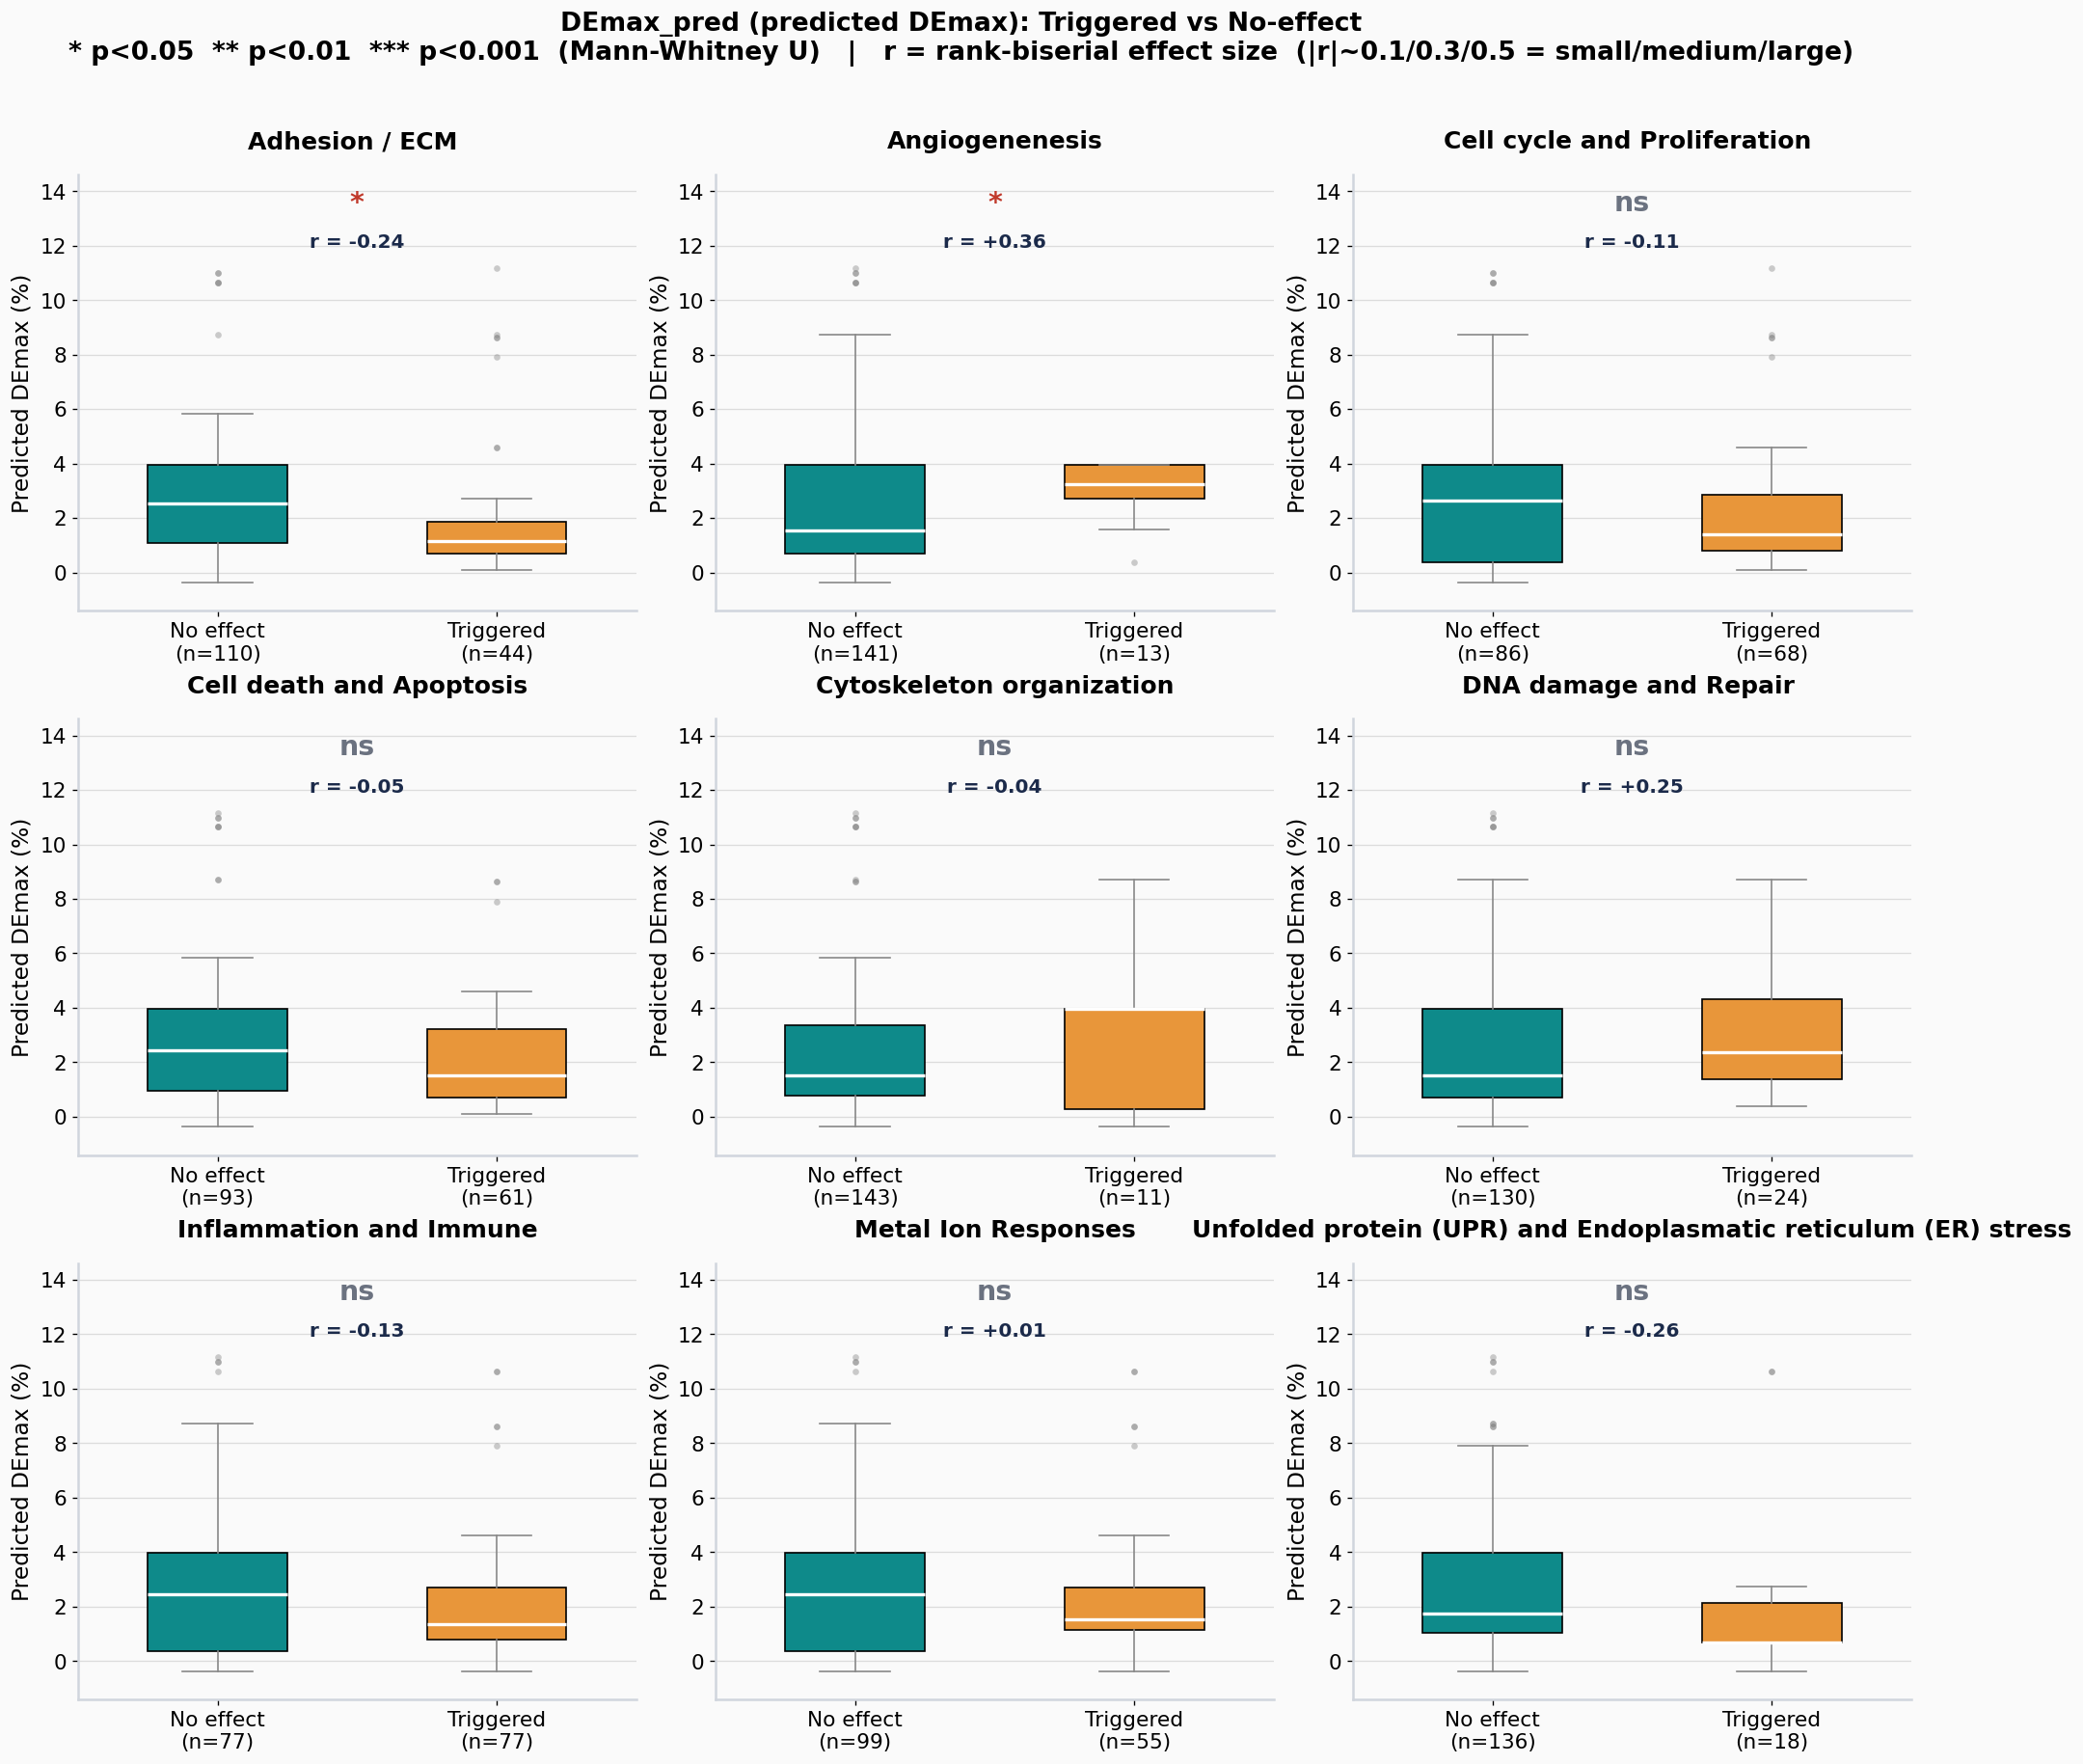


Endpoint         n_trig n_noeff   dDEmax       p      r  interpretation
Adhesion / ECM       44     110    -0.50   0.022  -0.24  small
Angiogenenesis       13     141    +0.49   0.031  +0.36  medium
Cell cycle and Proliferation      68      86    -0.52   0.227  -0.11  small
Cell death and Apoptosis     61      93    -0.58   0.575  -0.05  negligible
Cytoskeleton organization     11     143    +0.45   0.814  -0.04  negligible
DNA damage and Repair      24     130    +0.42   0.050  +0.25  small
Inflammation and Immune     77      77    -0.67   0.173  -0.13  small
Metal Ion Responses     55      99    -0.09   0.908  +0.01  negligible
Unfolded protein (UPR) and Endoplasmatic reticulum (ER) stress     18     136    -0.45   0.075  -0.26  small

r>0 => Triggered NPs have higher predicted DEmax; r<0 => lower.


In [ ]:
# =====================================================================
# Figure 6 — DEmax_pred boxplots per endpoint, now annotated with the
# RANK-BISERIAL EFFECT SIZE r alongside the Mann-Whitney significance.
#   r = 2U/(n1*n2) - 1 ;  sign = Triggered - No effect.
#   |r| ~ 0.1 small, 0.3 medium, 0.5 large (Cohen-style guide).
# =====================================================================
import os, numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats

OUTDIR = 'All_particles_DEmax_variation_figures'
os.makedirs(OUTDIR, exist_ok=True)

def clean_ep(x):
    return (str(x).replace(' responses','').replace('Cell  ','Cell ').replace('  ',' ')
            .replace('Unfolded protein responses (UPR) and Endoplasmatic reticulum (ER) stress','UPR / ER stress')
            .replace('Cell adhesion and Extracellular matrix','Adhesion / ECM'))

def style(ax, grid='y'):
    ax.spines['left'].set_color('#D0D5DD'); ax.spines['bottom'].set_color('#D0D5DD')
    ax.grid(axis=grid, alpha=0.4, zorder=0); ax.set_axisbelow(True)
    ax.tick_params(axis='both', labelsize=13)

def rank_biserial(trig, noeff):                 # effect size for Mann-Whitney U
    u, _ = stats.mannwhitneyu(trig, noeff, alternative='two-sided')
    return 2*u/(len(trig)*len(noeff)) - 1       # +ve => Triggered tends higher

dfp = tox_df.copy()
dfp['DEmax_pred']       = pd.to_numeric(dfp['DEmax_pred'],       errors='coerce')
dfp['tox_response_num'] = pd.to_numeric(dfp['tox_response_num'], errors='coerce')
dfp = dfp[dfp['tox_response_num'].isin([0,1])].copy()
dfp['endpoint_short'] = dfp['tox_endpoint'].apply(clean_ep)

endpoints = sorted(dfp['endpoint_short'].dropna().unique())
ncols = 3; nrows = int(np.ceil(len(endpoints)/ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(ncols*5.5, nrows*4.7), constrained_layout=True)
axes = axes.flatten()

summary = []
for i, ep in enumerate(endpoints):
    ax  = axes[i]
    sub = dfp[dfp['endpoint_short']==ep]
    g0  = sub.loc[sub['tox_response_num']==0,'DEmax_pred'].dropna()   # No effect
    g1  = sub.loc[sub['tox_response_num']==1,'DEmax_pred'].dropna()   # Triggered
    bp = ax.boxplot([g0, g1], patch_artist=True, widths=0.5,
                    medianprops={'color':'white','linewidth':2})
    bp['boxes'][0].set_facecolor('#0E8A8A'); bp['boxes'][1].set_facecolor('#E8963A')
    for w in bp['whiskers']+bp['caps']: w.set_color('#888')
    for f in bp['fliers']:
        f.set(marker='o', markersize=4, alpha=0.4, markerfacecolor='grey', markeredgewidth=0)

    ymax_data = max(g0.max() if len(g0) else 0, g1.max() if len(g1) else 0)
    ymin_data = min(g0.min() if len(g0) else 0, g1.min() if len(g1) else 0)
    headroom  = (ymax_data - ymin_data) * 0.30 if ymax_data > ymin_data else 1.0
    ax.set_ylim(bottom=ymin_data - headroom*0.3, top=ymax_data + headroom)

    if len(g0)>=3 and len(g1)>=3:
        _, p = stats.mannwhitneyu(g0, g1, alternative='two-sided')
        r    = rank_biserial(g1, g0)
        sig  = '***' if p<0.001 else ('**' if p<0.01 else ('*' if p<0.05 else 'ns'))
        band = 'large' if abs(r)>=0.5 else 'medium' if abs(r)>=0.3 else 'small' if abs(r)>=0.1 else 'negligible'
        ax.text(1.5, ymax_data + headroom*0.55, sig, ha='center', va='bottom',
                fontsize=17, color='#C0392B' if sig!='ns' else '#6B7280', fontweight='bold')
        ax.text(1.5, ymax_data + headroom*0.18, f"r = {r:+.2f}", ha='center', va='bottom',
                fontsize=12, color='#1B2A4A', fontweight='bold')
        summary.append((ep, len(g1), len(g0), g1.mean()-g0.mean(), p, r, band))
    else:
        summary.append((ep, len(g1), len(g0), np.nan, np.nan, np.nan, 'n/a'))

    ax.set_xticklabels([f'No effect\n(n={len(g0)})', f'Triggered\n(n={len(g1)})'], fontsize=14)
    ax.set_title(ep, fontsize=15, fontweight='bold', pad=16)
    ax.set_ylabel('Predicted DEmax (%)', fontsize=14)
    style(ax)

for j in range(i+1, len(axes)): axes[j].set_visible(False)

fig.suptitle('DEmax_pred (predicted DEmax): Triggered vs No-effect\n'
             '* p<0.05  ** p<0.01  *** p<0.001  (Mann-Whitney U)   |   '
             'r = rank-biserial effect size  (|r|~0.1/0.3/0.5 = small/medium/large)',
             fontsize=16, fontweight='bold', y=1.07)

plt.savefig(os.path.join(OUTDIR,'Fig_DEmax_boxplot_per_endpoint_effectsize.png'), dpi=300, bbox_inches='tight')
plt.show()

print(f"\n{'Endpoint':16}{'n_trig':>7}{'n_noeff':>8}{'dDEmax':>9}{'p':>8}{'r':>7}  interpretation")
for ep,nt,nn,d,p,r,band in summary:
    print(f"{ep:16}{nt:>7}{nn:>8}{d:>+9.2f}{p:>8.3f}{r:>+7.2f}  {band}")
print("\nr>0 => Triggered NPs have higher predicted DEmax; r<0 => lower.")

In [ ]:
print("distinct DEmax_pred values among retained conditions:",
      tox_df['DEmax_pred'].round(6).nunique())

distinct DEmax_pred values among retained conditions: 37


In [ ]:
for ep, g in tox_df.groupby('tox_endpoint'):
    print(ep, "->", g.loc[g['tox_response_num'].isin([0,1]), 'DEmax_pred'].round(6).nunique(), "distinct DEmax_pred")

Angiogenenesis responses -> 36 distinct DEmax_pred
Cell  adhesion  and Extracellular  matrix  responses -> 36 distinct DEmax_pred
Cell  cycle  and  Proliferation  responses -> 36 distinct DEmax_pred
Cell  death  and  Apoptosis responses -> 36 distinct DEmax_pred
Cytoskeleton organization responses -> 36 distinct DEmax_pred
DNA  damage  and  Repair  responses -> 36 distinct DEmax_pred
Inflammation and Immune responses -> 36 distinct DEmax_pred
Metal Ion  Responses -> 36 distinct DEmax_pred
Unfolded protein responses (UPR) and Endoplasmatic reticulum (ER) stress -> 36 distinct DEmax_pred


In [ ]:
# Reviewer's single-test alternative: does the DEmax association vary by endpoint?
# Logistic model  response ~ DEmax * endpoint, clustered by condition (each
# condition appears across all 9 endpoints). ONE 8-df interaction test; no
# multiplicity penalty.  pip install statsmodels  if needed.
import numpy as np, pandas as pd
import statsmodels.formula.api as smf
from statsmodels.genmod.families import Binomial
from statsmodels.genmod.cov_struct import Exchangeable

EP, LAB, PRED = 'tox_endpoint', 'tox_response_num', 'DEmax_pred'
d = tox_df.copy()
d[LAB]  = pd.to_numeric(d[LAB],  errors='coerce')
d[PRED] = pd.to_numeric(d[PRED], errors='coerce')
d = d[d[LAB].isin([0, 1]) & d[PRED].notna()].copy()

# condition id = everything constant within a condition (only endpoint & label vary)
keycols = [c for c in d.columns if c not in (EP, LAB)]
d['condition'] = d[keycols].astype(str).agg('|'.join, axis=1)
d['z'] = (d[PRED] - d[PRED].mean()) / d[PRED].std()   # standardize for a stable fit
print("rows:", len(d), " conditions:", d['condition'].nunique(), " endpoints:", d[EP].nunique())

m = smf.gee("tox_response_num ~ C(tox_endpoint) * z", groups="condition",
            data=d, family=Binomial(), cov_struct=Exchangeable()).fit()

# joint Wald test of ALL interaction coefficients (DEmax x endpoint) = the 8-df test
names = list(m.params.index)
idx = [i for i, n in enumerate(names) if n.endswith(':z')]
R = np.zeros((len(idx), len(names)))
for r, i in enumerate(idx): R[r, i] = 1
w = m.wald_test(R, scalar=False)
print(f"\nDEmax x endpoint interaction:  df = {len(idx)}, "
      f"chi2 = {float(np.squeeze(w.statistic)):.2f}, p = {float(np.squeeze(w.pvalue)):.4f}")
print("Main DEmax slope (z):", round(m.params.get('z', float('nan')), 3))

rows: 1386  conditions: 154  endpoints: 9

DEmax x endpoint interaction:  df = 8, chi2 = 10.80, p = 0.2135
Main DEmax slope (z): 0.095


In [ ]:
print(m.summary().tables[1])          # full coefficient table incl. p-values
print("\nMain DEmax slope (z): coef = %.3f,  p = %.4f"
      % (m.params['z'], m.pvalues['z']))

                                                                                                    coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------------------------------------------------------------------------------
Intercept                                                                                        -2.3963      0.290     -8.261      0.000      -2.965      -1.828
C(tox_endpoint)[T.Cell  adhesion  and Extracellular  matrix  responses]                           1.4629      0.350      4.175      0.000       0.776       2.150
C(tox_endpoint)[T.Cell  cycle  and  Proliferation  responses]                                     2.1535      0.302      7.129      0.000       1.561       2.746
C(tox_endpoint)[T.Cell  death  and  Apoptosis responses]                                          1.9619      0.289      6.790      0.000       1.396       2.528
C(tox_endpoint)[T.Cytoskelet

Pooled test of pathway-dependence (reviewer: one 8-df interaction, no multiplicity)

Fits response ~ DEmax * endpoint clustered by condition and tests the DEmax×endpoint interaction in a single 8-df test. Needs tox_df (tox_endpoint, tox_response_num, DEmax_pred); pip install statsmodels if needed.

In [ ]:
# =====================================================================
# Reviewer comment — test pathway-dependence as ONE interaction term
# instead of nine separate Mann-Whitney tests. Logistic model
#   response ~ DEmax_pred * endpoint,  clustered by condition
# (each condition appears across all nine endpoints). The 8-df
# DEmax x endpoint interaction is the single, multiplicity-free test.
# Needs tox_df with 'tox_endpoint','tox_response_num'(1/0),'DEmax_pred'.
#   pip install statsmodels   # if needed
# =====================================================================
import numpy as np, pandas as pd
import statsmodels.formula.api as smf
from statsmodels.genmod.families import Binomial
from statsmodels.genmod.cov_struct import Exchangeable

EP, LAB, PRED = 'tox_endpoint', 'tox_response_num', 'DEmax_pred'
d = tox_df.copy()
d[LAB]  = pd.to_numeric(d[LAB],  errors='coerce')
d[PRED] = pd.to_numeric(d[PRED], errors='coerce')
d = d[d[LAB].isin([0, 1]) & d[PRED].notna()].copy()

# condition id = everything constant within a condition (only endpoint & label vary)
keycols = [c for c in d.columns if c not in (EP, LAB)]
d['condition'] = d[keycols].astype(str).agg('|'.join, axis=1)
d['z'] = (d[PRED] - d[PRED].mean()) / d[PRED].std()
print("rows:", len(d), " conditions:", d['condition'].nunique(), " endpoints:", d[EP].nunique())

m = smf.gee("tox_response_num ~ C(tox_endpoint) * z", groups="condition",
            data=d, family=Binomial(), cov_struct=Exchangeable()).fit()

names = list(m.params.index)
idx = [i for i, n in enumerate(names) if n.endswith(':z')]
R = np.zeros((len(idx), len(names)))
for r, i in enumerate(idx): R[r, i] = 1
w = m.wald_test(R, scalar=False)

print("\n--- pooled test of pathway-dependence ---")
print(f"DEmax x endpoint interaction:  df = {len(idx)}, "
      f"chi2 = {float(np.squeeze(w.statistic)):.2f}, p = {float(np.squeeze(w.pvalue)):.4f}")
print(f"DEmax slope (reference endpoint, z): coef = {m.params['z']:.3f}, p = {m.pvalues['z']:.4f}")
print("\nInterpretation: a non-significant interaction means the DEmax->response")
print("association does not vary across endpoints (no pathway-dependence);")
print("a non-significant z slope means no overall DEmax->response association.")

rows: 1386  conditions: 154  endpoints: 9

--- pooled test of pathway-dependence ---
DEmax x endpoint interaction:  df = 8, chi2 = 10.80, p = 0.2135
DEmax slope (reference endpoint, z): coef = 0.095, p = 0.5040

Interpretation: a non-significant interaction means the DEmax->response
association does not vary across endpoints (no pathway-dependence);
a non-significant z slope means no overall DEmax->response association.
